In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#!unzip "/content/drive/MyDrive/Amazon/6ab10eb3b23ba_student_resource.zip" -d "/content/drive/MyDrive/unzipped"

Archive:  /content/drive/MyDrive/Amazon/6ab10eb3b23ba_student_resource.zip
replace /content/drive/MyDrive/unzipped/__MACOSX/._student_resource? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/drive/MyDrive/unzipped/student_resource/Documentation_template.md? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace /content/drive/MyDrive/unzipped/__MACOSX/student_resource/._Documentation_template.md? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [2]:
BASE = "/content/drive/MyDrive/unzipped/student_resource/dataset"


import pandas as pd
df = pd.read_csv(f"{BASE}/train/train_source1.tsv", sep="\t", dtype=str, keep_default_na=False)
df.head()


,entity_id,business_name,business_address,country
0,S1-925783039,Orelee's Barbershop,"1795 Westchester Drive, High Point, NC",US
1,S1-773889195,Prime Money,"17560 Ellis Road, Tahlequah, OK",US
2,S1-377745466,B+ Retail Inc,"1712 Montebello Avenue, Phoenix, AZ",US
3,S1-133037285,Christ Chapel,"2100 Cameron Drive, Unit APARTMENT G, Dundalk, MD",US
4,S1-755362802,Prabhav Business Center,"797, Lake Town Block A, Kolkata, Howrah, West ...",India


Shape: (2206821, 7)

Nulls:
 entity_id           0
business_name       0
business_address    0
country             0
name_len            0
addr_len            0
name_wordcount      0
dtype: int64

Duplicate entity_id: 0
Duplicate full rows: 0

Country distribution:
 country
US       1323633
India     883188
Name: count, dtype: int64


/tmp/ipykernel_2166/89092608.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_counts.index, y=country_counts.values, palette="viridis")


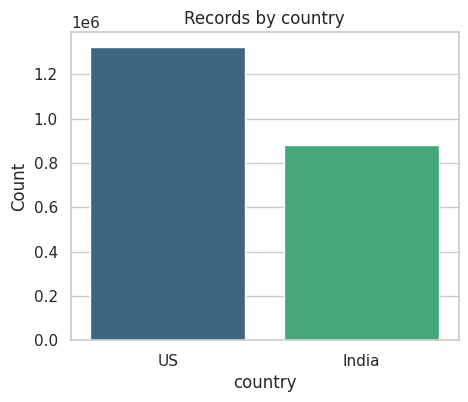

           name_len      addr_len
count  2.206821e+06  2.206821e+06
mean   2.403440e+01  5.206621e+01
std    7.740533e+00  2.532972e+01
min    3.000000e+00  1.100000e+01
25%    1.800000e+01  3.300000e+01
50%    2.400000e+01  4.100000e+01
75%    3.000000e+01  7.000000e+01
max    1.050000e+02  2.560000e+02


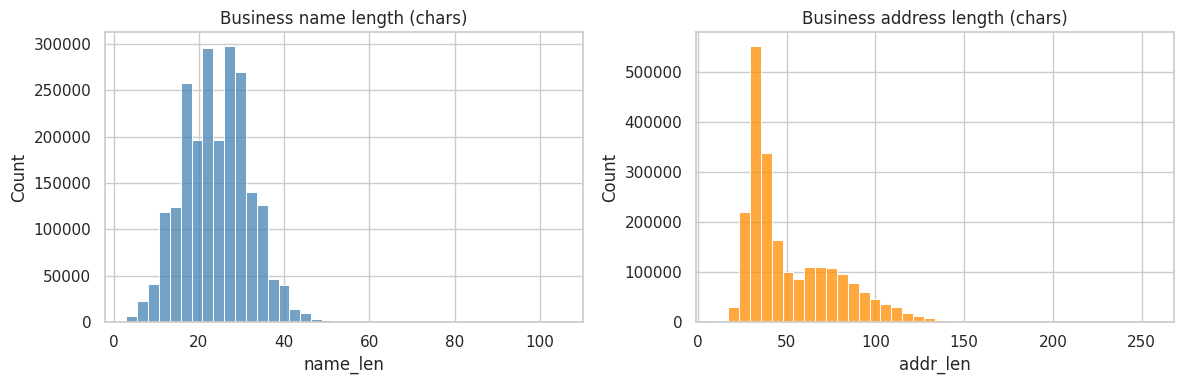

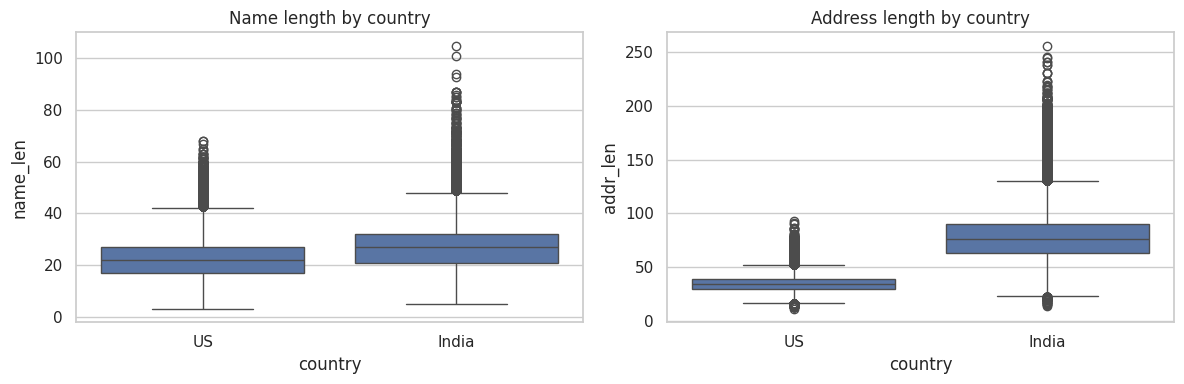

/tmp/ipykernel_2166/89092608.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['name_wordcount'].clip(upper=8), palette="crest")


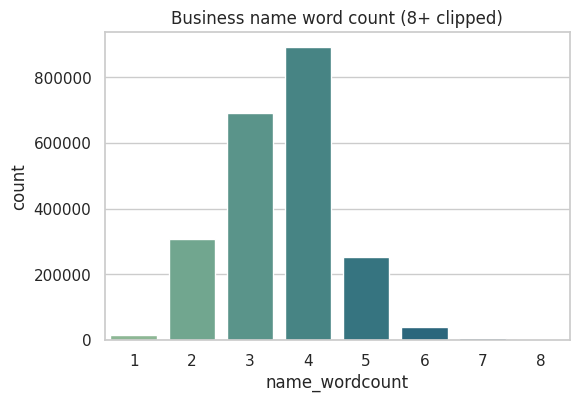

Unique names: 1539229 / 2206821
Unique addresses: 2130606 / 2206821
Addresses shared by 2+ entities: 40089
business_address
108 Norle Street, College Twp, PA                                                            14
104 Roadrunner Circle, Elephant Butte, NM                                                    13
1921 Willow Park Drive, Fort Worth, TX                                                       13
43 Franklin Street, Delaware, OH                                                             13
55, Lavkush Vihar, Singhpur, Kachhar Bithoor Road, Kalyanpur, Kanpur Nagar, Uttar Pradesh    13
218 Phillips Street, Storm Lake, IA                                                          13
1948 Weaver Forest Way, Morrisville, NC                                                      12
4024 High Creek Road, Bismarck, ND                                                           12
43233 Clearnight Terrace, Loudoun County, VA                                                 12
520 Kathy La

/tmp/ipykernel_2166/89092608.py:69: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['has_legal_suffix'] = df['business_name'].str.contains(suffix_pattern)



Noise pattern rates by country:
          has_legal_suffix  has_us_zip  has_india_pin  is_landmark_addr
country                                                               
India            0.791649    0.002699       0.000000          0.110557
US               0.483267    0.108200       0.001251          0.000076


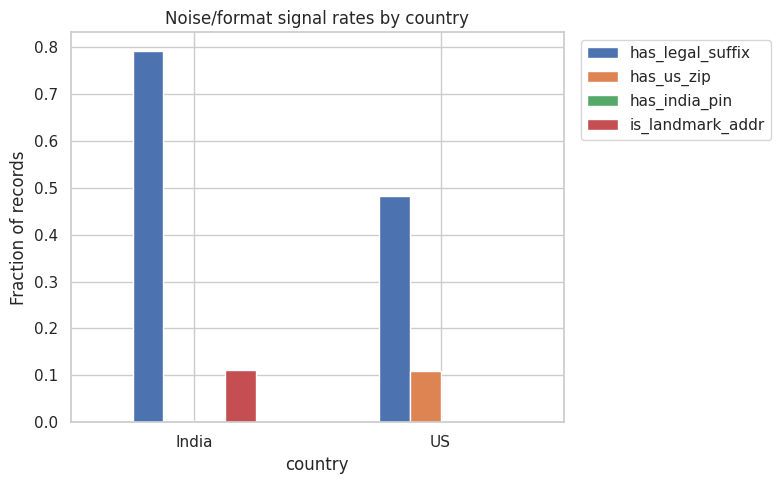

/tmp/ipykernel_2166/89092608.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_tokens.values, y=top_tokens.index, palette="mako")


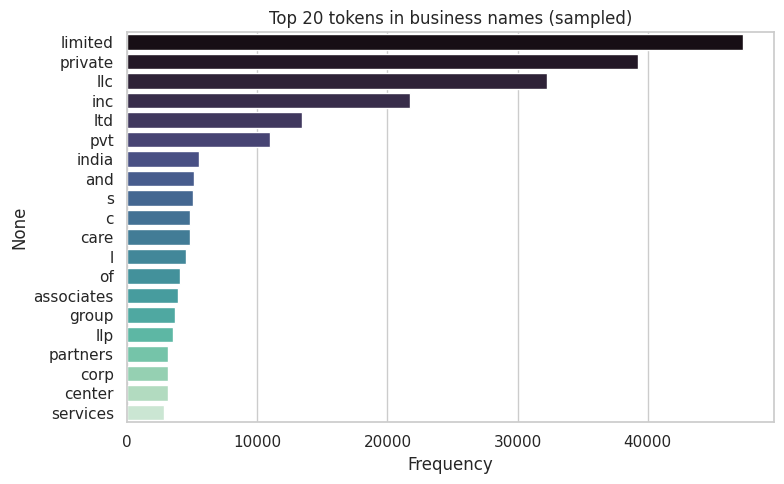

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


# ── 1. Integrity checks ──────────────────────────────────────────────
print("Shape:", df.shape)
print("\nNulls:\n", df.isna().sum())
print("\nDuplicate entity_id:", df['entity_id'].duplicated().sum())
print("Duplicate full rows:", df.duplicated().sum())

# ── 2. Country distribution ──────────────────────────────────────────
country_counts = df['country'].value_counts()
print("\nCountry distribution:\n", country_counts)

plt.figure(figsize=(5,4))
sns.barplot(x=country_counts.index, y=country_counts.values, palette="viridis")
plt.title("Records by country")
plt.ylabel("Count")
plt.show()

# ── 3. Name / address length ─────────────────────────────────────────
df['name_len'] = df['business_name'].str.len()
df['addr_len'] = df['business_address'].str.len()
print(df[['name_len','addr_len']].describe())

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(df['name_len'], bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Business name length (chars)")
sns.histplot(df['addr_len'], bins=40, ax=axes[1], color="darkorange")
axes[1].set_title("Business address length (chars)")
plt.tight_layout()
plt.show()

# by country
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=df, x='country', y='name_len', ax=axes[0])
axes[0].set_title("Name length by country")
sns.boxplot(data=df, x='country', y='addr_len', ax=axes[1])
axes[1].set_title("Address length by country")
plt.tight_layout()
plt.show()

# ── 4. Word count in names ───────────────────────────────────────────
df['name_wordcount'] = df['business_name'].str.split().str.len()
plt.figure(figsize=(6,4))
sns.countplot(x=df['name_wordcount'].clip(upper=8), palette="crest")
plt.title("Business name word count (8+ clipped)")
plt.show()

# ── 5. Uniqueness / collisions ───────────────────────────────────────
print("Unique names:", df['business_name'].nunique(), "/", len(df))
print("Unique addresses:", df['business_address'].nunique(), "/", len(df))

addr_counts = df['business_address'].value_counts()
shared_addr = addr_counts[addr_counts > 1]
print("Addresses shared by 2+ entities:", len(shared_addr))
print(shared_addr.head(10))

name_counts = df['business_name'].value_counts()
print("\nTop repeated business names:\n", name_counts.head(15))

# ── 6. Country-specific noise patterns ───────────────────────────────
suffix_pattern = re.compile(r'\b(inc|corp|corporation|ltd|limited|llc|pvt|private|co)\b', re.I)
df['has_legal_suffix'] = df['business_name'].str.contains(suffix_pattern)

df['has_us_zip']    = df['business_address'].str.contains(r'\b\d{5}(?:-\d{4})?\b', regex=True)
df['has_india_pin'] = df['business_address'].str.contains(r'\b\d{6}\b', regex=True)

landmark_pattern = re.compile(r'\bnear\b|\bopp(?:osite)?\b|\bbehind\b', re.I)
df['is_landmark_addr'] = df['business_address'].str.contains(landmark_pattern)

noise_summary = df.groupby('country')[
    ['has_legal_suffix', 'has_us_zip', 'has_india_pin', 'is_landmark_addr']
].mean()
print("\nNoise pattern rates by country:\n", noise_summary)

noise_summary.plot(kind='bar', figsize=(8,5))
plt.title("Noise/format signal rates by country")
plt.ylabel("Fraction of records")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ── 7. Token vocabulary (for blocking key design) ───────────────────
from collections import Counter
tokens = Counter(
    tok.lower()
    for name in df['business_name'].sample(200_000, random_state=1)
    for tok in re.findall(r"[A-Za-z]+", name)
)
top_tokens = pd.Series(dict(tokens.most_common(20)))
plt.figure(figsize=(8,5))
sns.barplot(x=top_tokens.values, y=top_tokens.index, palette="mako")
plt.title("Top 20 tokens in business names (sampled)")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import re
from collections import Counter

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 50)


BASE = "/content/drive/MyDrive/unzipped/student_resource/dataset"

FILES = {
    "train_s1": f"{BASE}/train/train_source1.tsv",
    "train_s2": f"{BASE}/train/train_source2.tsv",
    "train_s3": f"{BASE}/train/train_source3.tsv",
    "train_gt": f"{BASE}/train/train_ground_truth.tsv",
    "test_s1":  f"{BASE}/test/test_source1.tsv",
    "test_s2":  f"{BASE}/test/test_source2.tsv",
    "test_s3":  f"{BASE}/test/test_source3.tsv",
}


In [ ]:
def count_rows(path):
    with open(path, "rb") as f:
        return sum(1 for _ in f) - 1  # minus header

for name, path in FILES.items():
    print(f"{name:10s} {count_rows(path):>10,} rows   {path}")


train_s1    2,206,821 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_source1.tsv
train_s2    5,034,616 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_source2.tsv
train_s3    5,285,603 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_source3.tsv
train_gt    2,206,821 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_ground_truth.tsv
test_s1     1,732,544 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/test/test_source1.tsv
test_s2     4,887,273 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/test/test_source2.tsv
test_s3     5,082,316 rows   /content/drive/MyDrive/unzipped/student_resource/dataset/test/test_source3.tsv


In [ ]:
def load_source(path, nrows=None):
    # dtype=str is critical: keeps IDs intact, prevents pandas guessing types.
    # keep_default_na=False so empty addresses stay "" instead of becoming NaN.
    df = pd.read_csv(
        path, sep="\t", dtype=str, keep_default_na=False,
        na_values=[], nrows=nrows, encoding="utf-8"
    )
    return df

# Load full Source 1 files (smaller), sample the big S2/S3 for inspection.
s1_train = load_source(FILES["train_s1"])
s1_test  = load_source(FILES["test_s1"])

# For S2/S3, load a sample first for quick EDA, load full only when needed.
s2_train_sample = load_source(FILES["train_s2"], nrows=200_000)
s3_train_sample = load_source(FILES["train_s3"], nrows=200_000)

print(s1_train.shape, s1_test.shape)
s1_train.head()


(2206821, 4) (1732544, 4)


,entity_id,business_name,business_address,country
0,S1-925783039,Orelee's Barbershop,"1795 Westchester Drive, High Point, NC",US
1,S1-773889195,Prime Money,"17560 Ellis Road, Tahlequah, OK",US
2,S1-377745466,B+ Retail Inc,"1712 Montebello Avenue, Phoenix, AZ",US
3,S1-133037285,Christ Chapel,"2100 Cameron Drive, Unit APARTMENT G, Dundalk, MD",US
4,S1-755362802,Prabhav Business Center,"797, Lake Town Block A, Kolkata, Howrah, West Bengal",India


In [ ]:
def health_report(df, name):
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    for col in df.columns:
        n_empty = (df[col].str.strip() == "").sum()
        n_unique = df[col].nunique(dropna=False)
        print(f"  {col:18s} empty={n_empty:>8,} ({n_empty/len(df):.2%})  unique={n_unique:>9,}")
    # entity_id should be fully unique
    if "entity_id" in df.columns:
        dupes = df["entity_id"].duplicated().sum()
        print(f"  entity_id duplicates: {dupes}")

health_report(s1_train, "train_source1")
health_report(s2_train_sample, "train_source2 (sample)")
health_report(s3_train_sample, "train_source3 (sample)")
health_report(s1_test, "test_source1")



===== train_source1 =====
shape: (2206821, 4)
columns: ['entity_id', 'business_name', 'business_address', 'country']
  entity_id          empty=       0 (0.00%)  unique=2,206,821
  business_name      empty=       0 (0.00%)  unique=1,539,229
  business_address   empty=       0 (0.00%)  unique=2,130,606
  country            empty=       0 (0.00%)  unique=        2
  entity_id duplicates: 0

===== train_source2 (sample) =====
shape: (200000, 4)
columns: ['entity_id', 'business_name', 'business_address', 'country']
  entity_id          empty=       0 (0.00%)  unique=  200,000
  business_name      empty=       0 (0.00%)  unique=  195,656
  business_address   empty=   6,641 (3.32%)  unique=  192,307
  country            empty=       0 (0.00%)  unique=        2
  entity_id duplicates: 0

===== train_source3 (sample) =====
shape: (200000, 4)
columns: ['entity_id', 'business_name', 'business_address', 'country']
  entity_id          empty=       0 (0.00%)  unique=  200,000
  business_name     

In [ ]:
def country_counts(path, chunksize=1_000_000):
    c = Counter()
    for chunk in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                             usecols=["country"], chunksize=chunksize, encoding="utf-8"):
        c.update(chunk["country"].str.strip())
    return c

for name in ["train_s1","train_s2","train_s3","test_s1","test_s2","test_s3"]:
    print(f"{name:10s}", dict(country_counts(FILES[name])))


train_s1   {'US': 1323633, 'India': 883188}
train_s2   {'India': 2017799, 'US': 3016817}
train_s3   {'US': 3170056, 'India': 2115547}
test_s1    {'US': 663106, 'France': 259452, 'India': 809986}
test_s2    {'India': 2312565, 'France': 703378, 'US': 1871330}
test_s3    {'India': 2405000, 'France': 731615, 'US': 1945701}


In [ ]:
def prefix_counts(path):
    c = Counter()
    for chunk in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                             usecols=["entity_id"], chunksize=1_000_000, encoding="utf-8"):
        c.update(chunk["entity_id"].str[:3])
    return c

for name in ["train_s1","train_s2","train_s3","test_s1","test_s2","test_s3"]:
    print(f"{name:10s}", dict(prefix_counts(FILES[name])))


train_s1   {'S1-': 2206821}
train_s2   {'S2-': 5034616}
train_s3   {'S3-': 5285603}
test_s1    {'S1-': 1732544}
test_s2    {'S2-': 4887273}
test_s3    {'S3-': 5082316}


In [ ]:
gt = pd.read_csv(FILES["train_gt"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
print("gt shape:", gt.shape)

def split_ids(s):
    s = s.strip()
    return [x for x in s.split(",") if x] if s else []

gt["match_list"] = gt["matched_entity_ids"].apply(split_ids)
gt["n_matches"]  = gt["match_list"].str.len()

print("\nMatch-count distribution:")
print(gt["n_matches"].value_counts().sort_index().head(20))

singleton_rate = (gt["n_matches"] == 0).mean()
print(f"\nSingleton rate (0 matches): {singleton_rate:.2%}")
print(gt["n_matches"].describe())

# How many matches come from S2 vs S3?
all_ids = [i for lst in gt["match_list"] for i in lst]
src_mix = Counter(i[:3] for i in all_ids)
print("\nMatched-ID source mix:", dict(src_mix))



gt shape: (2206821, 2)

Match-count distribution:
n_matches
0     123247
1     119157
2     375212
3     530841
4     484115
5     321957
6     164868
7      63968
8      18680
9       4205
10       534
11        37
Name: count, dtype: int64

Singleton rate (0 matches): 5.58%
count    2.206821e+06
mean     3.461253e+00
std      1.705323e+00
min      0.000000e+00
25%      2.000000e+00
50%      3.000000e+00
75%      5.000000e+00
max      1.100000e+01
Name: n_matches, dtype: float64

Matched-ID source mix: {'S2-': 3693619, 'S3-': 3944746}


In [ ]:
def show_samples(df, n=15):
    return df[["business_name","business_address","country"]].sample(n, random_state=1)

print("Source 2 sample (India/US mix, transliterations):")
display(show_samples(s2_train_sample))
print("Source 3 sample:")
display(show_samples(s3_train_sample))

# Non-ASCII (transliteration / French/Hindi script) frequency
def non_ascii_rate(series):
    return series.apply(lambda x: bool(re.search(r"[^\x00-\x7f]", x))).mean()

for nm, df in [("s1_train", s1_train), ("s2_sample", s2_train_sample), ("s3_sample", s3_train_sample)]:
    print(f"{nm}: non-ASCII names {non_ascii_rate(df['business_name']):.2%}, "
          f"non-ASCII addresses {non_ascii_rate(df['business_address']):.2%}")


Source 2 sample (India/US mix, transliterations):


,business_name,business_address,country
49673,Vijay Solutions,"1/140(18), A R COMPLEX OPP MES HSS, PALAKKAD, Kerala",India
171551,સુપર એન્ટરપ્રાઇઝિસ મેડિકલ્સ પ્રાઇવેટ લિમિટેડ,"547 B-6, ANAND COMPLEX, SOLA OVER BRIDGE NAKA, S G HIGHWAY, THAL, TEJ, AHMEDABAD, Gujarat",India
5506,Orbori Acadia,"10702 ALICANTE WAY, RANCHO CORDOVA, CA",US
38370,Teamsters Local 907 Union,"3440 64 90 HWY, TAYLORSVILLE, NC",US
36930,CWU Porperisa Ltd,"NO 9 INDIA EXCHANGE PALCE, KOLKATA, West Bengal",India
167783,Golden Aldel Llc,"252- BLUE RIDGE DR, ORANNGE, VA",US
67487,Avinovi,"02599 MAGNOLIA RD, PMB 168, BELLMORE, NY",US
101486,Shakti Estate Limited,"NO 12-37/3 , OPPOSITE PARK VIDYANAGAR MAIN ROAD, DAVANAGERE, Karnataka",India
131774,Chiropractic Specialists Llc,"WI, NEW BBERLIN, 18309 THORNAPPLE LANE",US
48246,Lucky Seafood Corp,"524 EAST STREET, LA FERIAA CDP, TX",US


Source 3 sample:


,business_name,business_address,country
49673,Metropolitan Green Pattana Corp Corp,"Bountiful, 03415 Medford Dr, Utah",US
171551,Fernandez and Broadway (Inc),"2400 Bardstown Rd, Springfielld CDP, Kentucky",US
5506,Urgent Care Clinic Inc,"6 1/2 Blakeville Street, Boston, Massachusetts",US
38370,Sun Investments Ltd,"Bendre's Veic Farm, Dahivali Tarfe Varedi, Vanzarpada Road, Neral East, Raigad, Raigarh, महाराष्ट्र",India
36930,MODERN SOLUTIONS PVT LTD,"C/o Hasan Imam, Shahjuma, Rohtas, Sasaram, बिहार",India
167783,Beth Ísrael Partners,"309 Smithfield Street, Bradford, Ohio",US
67487,Zephique Archimedes LLC,"6977 Charles Cannon Road, Marion Station, Maryland",US
101486,Ivenic Mountain,"231 Main St, Appomattox CITY, Virginia",US
131774,Classic Software Systems P.L.L.C.,"Oklahoma, Main Street, Sallisaw",US
48246,Pinnacle LLC Center,"1629 Fairmount Ave, Fl 0, Wichita, Kansas",US


s1_train: non-ASCII names 0.00%, non-ASCII addresses 0.03%
s2_sample: non-ASCII names 15.07%, non-ASCII addresses 9.51%
s3_sample: non-ASCII names 11.61%, non-ASCII addresses 9.09%


In [ ]:
def top_tokens(series, n=30, sample=100_000):
    s = series.sample(min(sample, len(series)), random_state=0)
    c = Counter()
    for name in s:
        c.update(re.findall(r"[A-Za-z]+", name.lower()))
    return c.most_common(n)

print("Top name tokens (S2 sample):")
for tok, cnt in top_tokens(s2_train_sample["business_name"]):
    print(f"  {tok:15s} {cnt:,}")

# Legal-suffix / abbreviation spotting
suffixes = ["inc","corp","corporation","ltd","limited","llc","llp","pvt","private","co","sarl","sas","sa"]
text = " ".join(s2_train_sample["business_name"].sample(50_000, random_state=0)).lower()
print("\nLegal-suffix counts (S2 sample):")
for suf in suffixes:
    print(f"  {suf:12s} {len(re.findall(r'\\b'+suf+r'\\b', text)):,}")


Top name tokens (S2 sample):
  private         10,725
  limited         10,683
  llc             10,611
  inc             8,011
  ltd             7,953
  l               4,046
  com             4,011
  pvt             3,914
  center          3,852
  s               3,210
  c               3,199
  partners        3,024
  services        2,958
  group           2,826
  corp            2,817
  co              2,781
  and             2,317
  india           2,279
  holdings        1,989
  of              1,806
  care            1,787
  associates      1,436
  m               1,291
  p               1,288
  llp             1,286
  corporation     1,263
  d               1,239
  service         1,157
  enterprises     1,021
  health          1,003

Legal-suffix counts (S2 sample):
  inc          0
  corp         0
  corporation  0
  ltd          0
  limited      0
  llc          0
  llp          0
  pvt          0
  private      0
  co           0
  sarl         0
  sas          0
  sa      

In [ ]:
def address_stats(df, label):
    a = df["business_address"]
    empty = (a.str.strip()=="").mean()
    commas = a.apply(lambda x: x.count(",")).mean()
    has_digit = a.apply(lambda x: bool(re.search(r"\d", x))).mean()
    print(f"{label:20s} empty={empty:.2%}  avg_commas={commas:.2f}  has_digit={has_digit:.2%}")

for country in ["US","India","France"]:
    sub = s2_train_sample[s2_train_sample["country"]==country]
    if len(sub): address_stats(sub, f"S2 {country} (n={len(sub)})")


S2 US (n=119568)     empty=3.64%  avg_commas=2.00  has_digit=90.19%
S2 India (n=80432)   empty=2.84%  avg_commas=3.87  has_digit=91.24%


# **PHASE 0**

In [ ]:
import os, json, random, hashlib
import numpy as np
import pandas as pd
from collections import Counter

# ---- reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- paths (adjust BASE to your Drive path) ----
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA   = f"{BASE}/dataset"
WORK   = f"{BASE}/work"          # our own outputs: splits, configs, logs
os.makedirs(WORK, exist_ok=True)

FILES = {
    "train_s1": f"{DATA}/train/train_source1.tsv",
    "train_s2": f"{DATA}/train/train_source2.tsv",
    "train_s3": f"{DATA}/train/train_source3.tsv",
    "train_gt": f"{DATA}/train/train_ground_truth.tsv",
    "test_s1":  f"{DATA}/test/test_source1.tsv",
    "test_s2":  f"{DATA}/test/test_source2.tsv",
    "test_s3":  f"{DATA}/test/test_source3.tsv",
}

# ---- central config: every tunable lives here so runs are reproducible ----
CONFIG = {
    "seed": SEED,
    "val_fraction": 0.10,          # 10% of S1 held out for validation
    "beta": 0.5,                   # F_0.5
    # placeholders filled in later phases:
    "blocking": {},
    "matcher": {},
    "thresholds": {},
}

def save_config(cfg, name="config.json"):
    with open(f"{WORK}/{name}", "w") as f:
        json.dump(cfg, f, indent=2)
    print("saved config ->", f"{WORK}/{name}")

save_config(CONFIG)
print("BASE exists:", os.path.isdir(BASE))
print("DATA exists:", os.path.isdir(DATA))



saved config -> /content/drive/MyDrive/unzipped/student_resource/work/config.json
BASE exists: True
DATA exists: True


In [ ]:
def f_beta_per_entity(pred_ids, true_ids, beta=0.5):
    """F_beta for ONE S1 entity. pred_ids / true_ids are sets of S2/S3 IDs.
    Singleton rule: empty-vs-empty scores 1.0; predicting anything for a true
    singleton scores 0.0; missing all matches for a true cluster scores 0.0."""
    pred, true = set(pred_ids), set(true_ids)
    if not true and not pred:
        return 1.0                       # correct singleton
    if not true or not pred:
        return 0.0                       # one side empty, other not
    tp = len(pred & true)
    if tp == 0:
        return 0.0
    precision = tp / len(pred)
    recall    = tp / len(true)
    b2 = beta * beta
    return (1 + b2) * precision * recall / (b2 * precision + recall)

def macro_f_beta(pred_map, true_map, beta=0.5):
    """Macro-average over ALL S1 entities in true_map (the evaluation set).
    pred_map / true_map: {s1_id: set(matched ids)}. Missing pred -> empty set."""
    scores = [
        f_beta_per_entity(pred_map.get(s1, set()), true_ids, beta)
        for s1, true_ids in true_map.items()
    ]
    return float(np.mean(scores)), len(scores)

# ---- sanity checks against the spec's worked example ----
# GT = {S2-047, S2-193, S3-812}, pred same 3 -> P=1,R=1 -> 1.0
print("exact match      :", round(f_beta_per_entity(
    {"S2-047","S2-193","S3-812"}, {"S2-047","S2-193","S3-812"}), 3))
# INSTRUCTIONS example: pred 3, truth 3, 2 correct -> P=2/3,R=1 -> 0.714
print("P=2/3,R=1        :", round(f_beta_per_entity(
    {"S2-047","S2-193","S3-812"}, {"S2-047","S2-193"}), 3))
# correct singleton -> 1.0 ; false merge on singleton -> 0.0
print("singleton correct:", f_beta_per_entity(set(), set()))
print("singleton merged :", f_beta_per_entity({"S2-1"}, set()))


exact match      : 1.0
P=2/3,R=1        : 0.714
singleton correct: 1.0
singleton merged : 0.0


**Load S1 + GT, attach country and singleton flag**

In [ ]:
s1 = pd.read_csv(FILES["train_s1"], sep="\t", dtype=str,
                 keep_default_na=False, encoding="utf-8")
gt = pd.read_csv(FILES["train_gt"], sep="\t", dtype=str,
                 keep_default_na=False, encoding="utf-8")

def split_ids(s):
    s = s.strip()
    return [x for x in s.split(",") if x] if s else []

gt["match_list"] = gt["matched_entity_ids"].apply(split_ids)
gt["n_matches"]  = gt["match_list"].str.len()
gt["is_singleton"] = (gt["n_matches"] == 0)

# join country onto GT
g = gt.merge(s1[["entity_id","country"]],
             left_on="source1_entity_id", right_on="entity_id", how="left")

print("S1 rows:", len(s1), "| GT rows:", len(gt))
print("S1 ids == GT ids ?", set(s1["entity_id"]) == set(gt["source1_entity_id"]))
print("overall singleton rate:", round(g["is_singleton"].mean(), 4))
print("\ncountry x singleton counts:")
print(g.groupby(["country","is_singleton"]).size().unstack(fill_value=0))


S1 rows: 2206821 | GT rows: 2206821
S1 ids == GT ids ? True
overall singleton rate: 0.0558

country x singleton counts:
is_singleton    False  True 
country                     
India          833837  49351
US            1249737  73896


In [ ]:
from sklearn.model_selection import train_test_split

# stratify on a combined key so val mirrors train in both country and singleton mix
g["stratum"] = g["country"].fillna("NA") + "|" + g["is_singleton"].astype(str)

train_idx, val_idx = train_test_split(
    g.index,
    test_size=CONFIG["val_fraction"],
    random_state=SEED,
    stratify=g["stratum"],
)

train_s1_ids = set(g.loc[train_idx, "source1_entity_id"])
val_s1_ids   = set(g.loc[val_idx,   "source1_entity_id"])

# persist the split so every future phase uses the SAME val set
pd.Series(sorted(train_s1_ids)).to_csv(f"{WORK}/split_train_s1_ids.csv", index=False, header=["source1_entity_id"])
pd.Series(sorted(val_s1_ids)).to_csv(f"{WORK}/split_val_s1_ids.csv",   index=False, header=["source1_entity_id"])

def rate(mask_ids):
    sub = g[g["source1_entity_id"].isin(mask_ids)]
    return sub["is_singleton"].mean(), len(sub)

tr_rate, tr_n = rate(train_s1_ids)
va_rate, va_n = rate(val_s1_ids)
print(f"TRAIN: {tr_n:,} entities, singleton rate {tr_rate:.4f}")
print(f"VAL  : {va_n:,} entities, singleton rate {va_rate:.4f}")
print("\nVAL country distribution:")
print(g[g.source1_entity_id.isin(val_s1_ids)]["country"].value_counts())
print("\nsaved:", f"{WORK}/split_val_s1_ids.csv")


TRAIN: 1,986,138 entities, singleton rate 0.0558
VAL  : 220,683 entities, singleton rate 0.0558

VAL country distribution:
country
US       132364
India     88319
Name: count, dtype: int64

saved: /content/drive/MyDrive/unzipped/student_resource/work/split_val_s1_ids.csv


In [ ]:
# val_true_map: {s1_id -> set(matched S2/S3 ids)}  — reuse this to score every experiment
val_true_map = {
    row["source1_entity_id"]: set(row["match_list"])
    for _, row in g[g["source1_entity_id"].isin(val_s1_ids)].iterrows()
}
print("val_true_map size:", len(val_true_map))

# a trivial baseline to prove the harness works: predict empty for everyone
baseline_pred = {s1: set() for s1 in val_true_map}
score, n = macro_f_beta(baseline_pred, val_true_map, beta=CONFIG["beta"])
print(f"[baseline: predict-all-singleton]  macro F_0.5 = {score:.4f}  over {n:,} entities")

# ---- experiment log: append one row per run, justify choices later ----
LOG = f"{WORK}/experiments.csv"
def log_experiment(name, val_f05, notes="", extra=None):
    row = {"name": name, "val_f05": round(val_f05, 4),
           "n_val": len(val_true_map), "notes": notes}
    if extra: row.update(extra)
    df = pd.DataFrame([row])
    df.to_csv(LOG, mode="a", header=not os.path.exists(LOG), index=False)
    print("logged:", row)

log_experiment("baseline_all_singleton", score, notes="predict empty for every S1")


val_true_map size: 220683
[baseline: predict-all-singleton]  macro F_0.5 = 0.0558  over 220,683 entities
logged: {'name': 'baseline_all_singleton', 'val_f05': 0.0558, 'n_val': 220683, 'notes': 'predict empty for every S1'}


In [ ]:
import os, re
import numpy as np
import pandas as pd
from collections import Counter

pd.set_option("display.max_colwidth", 100)

BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"
WORK = f"{BASE}/work"
os.makedirs(WORK, exist_ok=True)

FILES = {
    "S1": f"{DATA}/train/train_source1.tsv",
    "S2": f"{DATA}/train/train_source2.tsv",
    "S3": f"{DATA}/train/train_source3.tsv",
    "GT": f"{DATA}/train/train_ground_truth.tsv",
}
for k, p in FILES.items():
    print(f"{k}: exists={os.path.isfile(p)}  {p}")


S1: exists=True  /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_source1.tsv
S2: exists=True  /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_source2.tsv
S3: exists=True  /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_source3.tsv
GT: exists=True  /content/drive/MyDrive/unzipped/student_resource/dataset/train/train_ground_truth.tsv


In [ ]:
def eda_source(path, label, chunksize=500_000):
    n_rows = 0
    empty = Counter()                 # empty-string count per column
    country = Counter()
    id_seen = set()
    id_dupes = set()
    row_hashes = set()
    dup_rows = 0
    # streaming length stats (store lengths compactly as int32 arrays per chunk)
    name_len_sum = name_len_sqsum = 0
    addr_len_sum = addr_len_sqsum = 0
    name_lens_sample, addr_lens_sample = [], []
    n_unique_names = set()            # note: exact-unique set can be big but OK here
    n_unique_addr  = set()

    cols = ["entity_id", "business_name", "business_address", "country"]
    reader = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                         encoding="utf-8", chunksize=chunksize)
    for chunk in reader:
        chunk = chunk[cols]
        n = len(chunk); n_rows += n

        for c in cols:
            empty[c] += (chunk[c].str.strip() == "").sum()

        country.update(chunk["country"].str.strip())

        # entity_id uniqueness / duplicates
        ids = chunk["entity_id"].values
        for i in ids:
            if i in id_seen: id_dupes.add(i)
            else: id_seen.add(i)

        # exact duplicate ROWS (all 4 fields identical)
        h = pd.util.hash_pandas_object(chunk, index=False)
        for hv in h.values:
            if hv in row_hashes: dup_rows += 1
            else: row_hashes.add(hv)

        # length stats
        nl = chunk["business_name"].str.len().values.astype(np.int64)
        al = chunk["business_address"].str.len().values.astype(np.int64)
        name_len_sum += nl.sum(); name_len_sqsum += (nl*nl).sum()
        addr_len_sum += al.sum(); addr_len_sqsum += (al*al).sum()
        if len(name_lens_sample) < 300_000:
            name_lens_sample.extend(nl[:5000]); addr_lens_sample.extend(al[:5000])

        n_unique_names.update(chunk["business_name"])
        n_unique_addr.update(chunk["business_address"])

    def mean_std(s, sq, n):
        m = s/n; v = max(sq/n - m*m, 0)
        return m, v**0.5

    nm_mean, nm_std = mean_std(name_len_sum, name_len_sqsum, n_rows)
    ad_mean, ad_std = mean_std(addr_len_sum, addr_len_sqsum, n_rows)
    nls = np.array(name_lens_sample); als = np.array(addr_lens_sample)

    print(f"\n================ {label} ================")
    print(f"rows                 : {n_rows:,}")
    print(f"entity_id unique     : {len(id_seen):,}  (dupe ids: {len(id_dupes)})")
    print(f"exact duplicate rows : {dup_rows:,}")
    print(f"unique business_name : {len(n_unique_names):,}  "
          f"({len(n_unique_names)/n_rows:.1%} of rows)")
    print(f"unique addresses     : {len(n_unique_addr):,}  "
          f"({len(n_unique_addr)/n_rows:.1%} of rows)")
    print("empty-string rate per column:")
    for c in cols:
        print(f"   {c:18s} {empty[c]:>9,}  ({empty[c]/n_rows:.2%})")
    print("country distribution:")
    for c, v in country.most_common():
        print(f"   {c:10s} {v:>9,}  ({v/n_rows:.1%})")
    print(f"name length  : mean={nm_mean:.1f} std={nm_std:.1f} "
          f"p50={np.median(nls):.0f} p90={np.percentile(nls,90):.0f} max={nls.max()}")
    print(f"addr length  : mean={ad_mean:.1f} std={ad_std:.1f} "
          f"p50={np.median(als):.0f} p90={np.percentile(als,90):.0f} max={als.max()}")
    return {"rows": n_rows, "empty": dict(empty), "country": dict(country),
            "dupe_ids": len(id_dupes), "dup_rows": dup_rows}

stats_s1 = eda_source(FILES["S1"], "SOURCE 1 (reference)")



================ SOURCE 1 (reference) ================
rows                 : 2,206,821
entity_id unique     : 2,206,821  (dupe ids: 0)
exact duplicate rows : 0
unique business_name : 1,539,229  (69.7% of rows)
unique addresses     : 2,130,606  (96.5% of rows)
empty-string rate per column:
   entity_id                  0  (0.00%)
   business_name              0  (0.00%)
   business_address           0  (0.00%)
   country                    0  (0.00%)
country distribution:
   US         1,323,633  (60.0%)
   India        883,188  (40.0%)
name length  : mean=24.0 std=7.7 p50=24 p90=34 max=70
addr length  : mean=52.1 std=25.3 p50=41 p90=90 max=185


In [ ]:
stats_s2 = eda_source(FILES["S2"], "SOURCE 2")
stats_s3 = eda_source(FILES["S3"], "SOURCE 3")


================ SOURCE 2 ================
rows                 : 5,034,616
entity_id unique     : 5,034,616  (dupe ids: 0)
exact duplicate rows : 0
unique business_name : 4,402,009  (87.4% of rows)
unique addresses     : 4,337,262  (86.1% of rows)
empty-string rate per column:
   entity_id                  0  (0.00%)
   business_name              0  (0.00%)
   business_address     168,967  (3.36%)
   country                    0  (0.00%)
country distribution:
   US         3,016,817  (59.9%)
   India      2,017,799  (40.1%)
name length  : mean=25.1 std=8.9 p50=25 p90=37 max=72
addr length  : mean=46.2 std=24.8 p50=37 p90=83 max=196

================ SOURCE 3 ================
rows                 : 5,285,603
entity_id unique     : 5,285,603  (dupe ids: 0)
exact duplicate rows : 0
unique business_name : 4,651,609  (88.0% of rows)
unique addresses     : 4,632,765  (87.6% of rows)
empty-string rate per column:
   entity_id                  0  (0.00%)
   business_name              0  (0.0

In [ ]:
gt = pd.read_csv(FILES["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")

def split_ids(s):
    s = s.strip()
    return [x for x in s.split(",") if x] if s else []

gt["match_list"] = gt["matched_entity_ids"].apply(split_ids)
gt["n_matches"]  = gt["match_list"].str.len()

# duplicate S1 rows in GT
dup_s1 = gt["source1_entity_id"].duplicated().sum()
# any duplicate IDs *within* a single match list (would be a data issue)
intra_dup = gt["match_list"].apply(lambda l: len(l) != len(set(l))).sum()

print("================ GROUND TRUTH ================")
print(f"rows                       : {len(gt):,}")
print(f"unique source1_entity_id   : {gt['source1_entity_id'].nunique():,}")
print(f"duplicate S1 rows          : {dup_s1}")
print(f"rows with intra-list dupes : {intra_dup}")
print(f"empty matched_entity_ids   : {(gt['n_matches']==0).sum():,} "
      f"({(gt['n_matches']==0).mean():.2%})   <- singletons")
print(f"total match links          : {gt['n_matches'].sum():,}")
print(f"matches/entity (all)       : mean={gt['n_matches'].mean():.3f} max={gt['n_matches'].max()}")
nonz = gt.loc[gt.n_matches>0, "n_matches"]
print(f"matches/entity (non-single): mean={nonz.mean():.3f} p50={nonz.median():.0f}")

# source composition of matched IDs
mix = Counter(i[:3] for lst in gt["match_list"] for i in lst)
print("matched-ID source mix      :", dict(mix))
print("\nmatch-count distribution (0..12):")
print(gt["n_matches"].value_counts().sort_index().head(13))


================ GROUND TRUTH ================
rows                       : 2,206,821
unique source1_entity_id   : 2,206,821
duplicate S1 rows          : 0
rows with intra-list dupes : 0
empty matched_entity_ids   : 123,247 (5.58%)   <- singletons
total match links          : 7,638,365
matches/entity (all)       : mean=3.461 max=11
matches/entity (non-single): mean=3.666 p50=4
matched-ID source mix      : {'S2-': 3693619, 'S3-': 3944746}

match-count distribution (0..12):
n_matches
0     123247
1     119157
2     375212
3     530841
4     484115
5     321957
6     164868
7      63968
8      18680
9       4205
10       534
11        37
Name: count, dtype: int64


In [ ]:
import os, re, random, difflib
import numpy as np
import pandas as pd
from collections import Counter

SEED = 42; random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 100)

BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"
F = {"S1": f"{DATA}/train/train_source1.tsv",
     "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv",
     "GT": f"{DATA}/train/train_ground_truth.tsv"}

def build_lookup(path):
    name, addr, ctry = {}, {}, {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                          encoding="utf-8", chunksize=1_000_000):
        name.update(zip(ch.entity_id, ch.business_name))
        addr.update(zip(ch.entity_id, ch.business_address))
        ctry.update(zip(ch.entity_id, ch.country))
    return name, addr, ctry

s1_name, s1_addr, s1_ctry = build_lookup(F["S1"])
s2_name, s2_addr, s2_ctry = build_lookup(F["S2"])
s3_name, s3_addr, s3_ctry = build_lookup(F["S3"])

def get_name(i): return s2_name.get(i) or s3_name.get(i)
def get_addr(i): return s2_addr.get(i) if i in s2_name else s3_addr.get(i)

print("lookups built:", len(s1_name), len(s2_name), len(s3_name))


lookups built: 2206821 5034616 5285603


In [ ]:
# =====================================================================================
# PHASE 1.2 — TEXT NOISE TAXONOMY: discover (numeric) -> quantify (scale) -> VERIFY (examples)
# Single self-contained cell. Requires only pandas/numpy/sklearn (no GPU needed here).
# =====================================================================================
import os, re, random, difflib
import numpy as np, pandas as pd
from collections import Counter, defaultdict

SEED = 42; random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"
F = {"S1": f"{DATA}/train/train_source1.tsv",
     "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv",
     "GT": f"{DATA}/train/train_ground_truth.tsv"}

# ---- config (tune down if RAM/time tight) ----
DIFF_PAIRS   = 60_000     # true pairs for numeric diff signatures
VERIFY_PAIRS = 40_000     # true pairs scanned for example collection
SAMPLE_N     = 300_000    # per-source rows for full-scale frequency scan
MAX_EX       = 10         # examples printed per category

# ---- regexes (all NON-capturing to avoid pandas UserWarning) ----
RE_TOK      = re.compile(r"[a-z0-9\u0900-\u097F]+")
RE_DEV      = re.compile(r"[\u0900-\u097F]")
RE_NONASCII = re.compile(r"[^\x00-\x7F]")
RE_LEGAL    = re.compile(r"\b(?:inc|incorporated|corp|corporation|ltd|limited|llc|llp|pvt|"
                         r"private|co|company|sarl|sas|sa|gmbh|plc|pte)\b", re.I)
RE_DOMAIN   = re.compile(r"[\w\-]+\.(?:com|net|org|in|co|io|biz|info|us|fr)\b", re.I)
RE_LANDMARK = re.compile(r"\b(?:near|beside|behind|opp\.?|opposite|adjacent|in front of)\b", re.I)
RE_LEADJUNK = re.compile(r"^\s*[^\w\u0900-\u097F]")
RE_POSTAL   = re.compile(r"\b(?:\d{5}(?:-\d{4})?|\d{6})\b")

# =====================================================================================
# 0) BUILD LOOKUPS
# =====================================================================================
def build_lookup(path):
    name, addr = {}, {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                          encoding="utf-8", usecols=["entity_id","business_name","business_address"],
                          chunksize=1_000_000):
        name.update(zip(ch.entity_id, ch.business_name))
        addr.update(zip(ch.entity_id, ch.business_address))
    return name, addr

print("building lookups ...")
s1_name, s1_addr = build_lookup(F["S1"])
s2_name, s2_addr = build_lookup(F["S2"])
s3_name, s3_addr = build_lookup(F["S3"])
def get_name(i): return s2_name.get(i) or s3_name.get(i)
def get_addr(i): return s2_addr.get(i) if i in s2_name else s3_addr.get(i)
print(f"  S1={len(s1_name):,}  S2={len(s2_name):,}  S3={len(s3_name):,}")

gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s: [x for x in s.split(",") if x])
gt_nz = gt[gt["ml"].str.len() > 0]

# =====================================================================================
# 1) SIGNATURE FUNCTION (transformation tags between two strings)
# =====================================================================================
def signature(a, b):
    tags = set()
    if a is None or b is None: return {"MISSING_RECORD"}
    al, bl = a.lower().strip(), b.lower().strip()
    if al == bl: return {"IDENTICAL"}
    if bool(RE_DEV.search(a)) != bool(RE_DEV.search(b)): tags.add("SCRIPT_CHANGE")
    if bool(RE_NONASCII.search(a)) != bool(RE_NONASCII.search(b)): tags.add("NONASCII_CHANGE")
    ta, tb = RE_TOK.findall(al), RE_TOK.findall(bl)
    sa, sb = set(ta), set(tb)
    if sa == sb and ta != tb: tags.add("WORD_REORDER")
    added, removed = sb - sa, sa - sb
    if removed and not added: tags.add("TOKENS_REMOVED")
    if added and not removed: tags.add("TOKENS_ADDED")
    if added and removed:     tags.add("TOKENS_SWAPPED")
    ratio = difflib.SequenceMatcher(None, al, bl).ratio()
    if 0.80 <= ratio < 1.0: tags.add("CHAR_NEARMISS")
    elif ratio < 0.80:      tags.add("CHAR_MAJOR_DIFF")
    strip = lambda s: re.sub(r"[^\w\u0900-\u097F]", "", s)
    if strip(al) == strip(bl) and al != bl: tags.add("PUNCT_ONLY")
    return tags

# =====================================================================================
# 2) NUMERIC — diff signatures over true pairs (names + addresses)
# =====================================================================================
print("\ncomputing diff signatures ...")
diff_sample = gt_nz.sample(min(DIFF_PAIRS, len(gt_nz)), random_state=SEED)
name_sig, addr_sig = Counter(), Counter()
removed_tok, added_tok = Counter(), Counter()
n_name = n_addr = 0
for _, r in diff_sample.iterrows():
    a_name, a_addr = s1_name[r.source1_entity_id], s1_addr[r.source1_entity_id]
    aset = set(RE_TOK.findall(a_name.lower()))
    for mid in r["ml"][:2]:
        b_name, b_addr = get_name(mid), get_addr(mid)
        for t in signature(a_name, b_name): name_sig[t] += 1
        n_name += 1
        if b_name:
            bset = set(RE_TOK.findall(b_name.lower()))
            removed_tok.update(aset - bset); added_tok.update(bset - aset)
        if a_addr.strip() and (b_addr or "").strip():
            for t in signature(a_addr, b_addr): addr_sig[t] += 1
            n_addr += 1

def show_counter(c, n, title):
    print(f"\n=== {title} (over {n:,}) ===")
    for t, v in c.most_common(): print(f"   {t:16s} {v:>9,}  ({100*v/n:.1f}%)")

show_counter(name_sig, n_name, "NAME transformation signatures")
show_counter(addr_sig, n_addr, "ADDRESS transformation signatures")
print("\n=== Top tokens DROPPED (S1 present, match absent) — candidate stopwords/suffixes ===")
for t,v in removed_tok.most_common(30): print(f"   {t:16s} {v:,}")
print("\n=== Top tokens ADDED (match present, S1 absent) ===")
for t,v in added_tok.most_common(30): print(f"   {t:16s} {v:,}")

# =====================================================================================
# 3) FULL-SCALE FREQUENCY (per source x per country)
# =====================================================================================
def load_sample(path, n=SAMPLE_N):
    total = sum(1 for _ in open(path, "rb")) - 1
    if n >= total: return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
    keep = set(random.sample(range(1, total+1), n))
    skip = [i for i in range(1, total+1) if i not in keep]
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8", skiprows=skip)

print("\nloading per-source samples for scale frequency ...")
samples = {k: load_sample(F[k]) for k in ["S1","S2","S3"]}

def scan(df, label):
    N = len(df); nm = df.business_name; ad = df.business_address
    pct = lambda m: round(100*m.mean(), 2)
    print(f"\n=== SOURCE {label} (n={N:,}) — % of rows ===")
    checks = [("name legal suffix", nm, RE_LEGAL), ("name domain-style", nm, RE_DOMAIN),
              ("name leading junk", nm, RE_LEADJUNK), ("name Devanagari", nm, RE_DEV),
              ("name non-ASCII", nm, RE_NONASCII), ("addr landmark", ad, RE_LANDMARK),
              ("addr postal code", ad, RE_POSTAL), ("addr Devanagari", ad, RE_DEV)]
    for nmlbl, series, rx in checks:
        overall = pct(series.str.contains(rx, regex=True))
        by = {c: pct(series[df.country==c].str.contains(rx, regex=True)) for c in sorted(df.country.unique())}
        print(f"   {nmlbl:20s} ALL={overall:6.2f}%   " + "  ".join(f"{c}={v:.2f}%" for c,v in by.items()))
    print(f"   {'addr empty':20s} ALL={pct(ad.str.strip()==''):6.2f}%")

for k in ["S1","S2","S3"]: scan(samples[k], k[-1])

# =====================================================================================
# 4) VERIFY — real example pairs behind every transformation tag
# =====================================================================================
print("\n\n########## VERIFICATION: real (S1 -> match) example pairs ##########")
verify_sample = gt_nz.sample(min(VERIFY_PAIRS, len(gt_nz)), random_state=SEED)
name_ex, addr_ex = defaultdict(list), defaultdict(list)
for _, r in verify_sample.iterrows():
    a_name, a_addr = s1_name[r.source1_entity_id], s1_addr[r.source1_entity_id]
    for mid in r["ml"][:2]:
        b_name, b_addr = get_name(mid), get_addr(mid)
        for t in signature(a_name, b_name):
            if len(name_ex[t]) < MAX_EX: name_ex[t].append((a_name, b_name))
        if a_addr.strip() and (b_addr or "").strip():
            for t in signature(a_addr, b_addr):
                if len(addr_ex[t]) < MAX_EX: addr_ex[t].append((a_addr, b_addr))

def dump(ex, title):
    print(f"\n============== {title} ==============")
    for tag in sorted(ex, key=lambda k: -len(ex[k])):
        print(f"\n----- {tag} ({len(ex[tag])} shown) -----")
        for a, b in ex[tag]:
            print(f"   S1  : {a}")
            print(f"   -> : {b}")
dump(name_ex, "NAME transformation examples")
dump(addr_ex, "ADDRESS transformation examples")

# ---- targeted verifications ----
print("\n\n########## TARGETED VERIFICATIONS ##########")

print("\n----- DOMAIN-STYLE names by source (confirm S2/S3-only) -----")
for k in ["S1","S2","S3"]:
    hits = samples[k][samples[k].business_name.str.contains(RE_DOMAIN, regex=True)]
    print(f"\nS{k[-1]}: {len(hits):,} hits ({100*len(hits)/len(samples[k]):.2f}%)")
    for v in hits.business_name.head(8).tolist(): print(f"   {v}")

print("\n----- TRANSLITERATION: S1 Latin -> match Devanagari -----")
shown = 0
for _, r in gt_nz.sample(30_000, random_state=SEED).iterrows():
    a = s1_name[r.source1_entity_id]
    if RE_DEV.search(a): continue
    for mid in r["ml"]:
        b = get_name(mid)
        if b and RE_DEV.search(b):
            print(f"   S1 (Latin): {a}\n   match(Dev): {b}\n"); shown += 1; break
    if shown >= 15: break

print("----- LANDMARK addresses (S1 vs match) -----")
shown = 0
for _, r in gt_nz.sample(40_000, random_state=SEED).iterrows():
    a = s1_addr[r.source1_entity_id]
    for mid in r["ml"]:
        b = get_addr(mid)
        if b and (RE_LANDMARK.search(a) or RE_LANDMARK.search(b)):
            print(f"   S1   : {a}\n   match: {b}\n"); shown += 1; break
    if shown >= 12: break

print("----- ADDRESS present in S1 but EMPTY in a true match -----")
shown = 0
for _, r in gt_nz.sample(40_000, random_state=SEED).iterrows():
    a = s1_addr[r.source1_entity_id]
    for mid in r["ml"]:
        b = get_addr(mid)
        if b is not None and b.strip() == "" and a.strip():
            print(f"   S1   : {a}\n   match: <EMPTY>\n"); shown += 1; break
    if shown >= 8: break

print("\n\nPHASE 1.2 COMPLETE — numeric signatures, scale frequency, and verification done.")


building lookups ...
  S1=2,206,821  S2=5,034,616  S3=5,285,603

computing diff signatures ...

=== NAME transformation signatures (over 116,527) ===
   CHAR_NEARMISS       61,884  (53.1%)
   TOKENS_SWAPPED      51,320  (44.0%)
   CHAR_MAJOR_DIFF     41,841  (35.9%)
   TOKENS_REMOVED      21,588  (18.5%)
   NONASCII_CHANGE     18,075  (15.5%)
   PUNCT_ONLY          13,979  (12.0%)
   IDENTICAL           12,802  (11.0%)
   TOKENS_ADDED        11,197  (9.6%)
   WORD_REORDER         7,018  (6.0%)
   SCRIPT_CHANGE        5,952  (5.1%)

=== ADDRESS transformation signatures (over 111,216) ===
   TOKENS_SWAPPED      73,209  (65.8%)
   CHAR_NEARMISS       59,811  (53.8%)
   CHAR_MAJOR_DIFF     41,986  (37.8%)
   TOKENS_REMOVED      13,617  (12.2%)
   NONASCII_CHANGE     10,869  (9.8%)
   IDENTICAL            9,419  (8.5%)
   TOKENS_ADDED         7,063  (6.4%)
   SCRIPT_CHANGE        6,334  (5.7%)
   WORD_REORDER         6,019  (5.4%)
   PUNCT_ONLY           1,993  (1.8%)

=== Top tokens DROPP

In [ ]:
# =====================================================================================
# PHASE 1.2 — CLOSING PASS: fixes gaps #1-#6, emits the consolidated taxonomy artifact
# Requires prior cell's objects in memory: s1_name/s1_addr, get_name/get_addr,
# gt_nz, samples, signature(), and the RE_* regexes.
# =====================================================================================
import os, re, difflib, numpy as np, pandas as pd
from collections import Counter
import torch
from sentence_transformers import SentenceTransformer

SEED = 42
WORK = "/content/drive/MyDrive/unzipped/student_resource/work"
os.makedirs(WORK, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEV)

RE_TOK = re.compile(r"[a-z0-9\u0900-\u097F\u0980-\u09FF\u0A80-\u0AFF\u0C00-\u0C7F]+")  # + Bengali/Gujarati/Telugu

# -------------------------------------------------------------------------------------
# GAP #4 — one-line confirmation: is S1 address ever empty in a true pair? (reverse check)
# -------------------------------------------------------------------------------------
s1_empty_in_pairs = 0
checked = 0
for _, r in gt_nz.sample(40_000, random_state=SEED).iterrows():
    if s1_addr[r.source1_entity_id].strip() == "":
        s1_empty_in_pairs += 1
    checked += 1
print(f"\n[GAP4] S1 empty-address in true pairs: {s1_empty_in_pairs}/{checked} "
      f"({100*s1_empty_in_pairs/checked:.3f}%)  -> confirms S1 side is complete")

# -------------------------------------------------------------------------------------
# GAP #2 — street-abbreviation variance between true address pairs (diff-signature style)
# -------------------------------------------------------------------------------------
ABBR_PAIRS = {
    "road":"rd","street":"st","avenue":"ave","boulevard":"blvd","lane":"ln","drive":"dr",
    "court":"ct","circle":"cir","highway":"hwy","square":"sq","floor":"fl","apartment":"apt",
    "suite":"ste","building":"bldg","number":"no","opposite":"opp","near":"nr","block":"blk",
}
RE_ABBR = re.compile(r"\b(" + "|".join(list(ABBR_PAIRS)+list(ABBR_PAIRS.values())) + r")\b", re.I)

def abbr_tokens(s): return set(m.lower() for m in RE_ABBR.findall(s or ""))

abbr_variance = Counter(); abbr_pairs_seen = 0
for _, r in gt_nz.sample(40_000, random_state=SEED).iterrows():
    a = s1_addr[r.source1_entity_id]
    for mid in r["ml"][:2]:
        b = get_addr(mid)
        if not (a.strip() and (b or "").strip()): continue
        ta, tb = abbr_tokens(a), abbr_tokens(b)
        # canonicalize both sides to full form, see if the *set* changes -> a variant occurred
        canon = lambda toks: {ABBR_PAIRS.get(t, t) for t in toks}
        if ta != tb:                                  # raw abbrev tokens differ
            abbr_variance["raw_differs"] += 1
            if canon(ta) == canon(tb) and ta != tb:   # same meaning, different abbrev form
                abbr_variance["pure_abbrev_swap"] += 1
        abbr_pairs_seen += 1
print(f"\n[GAP2] street-abbreviation variance over {abbr_pairs_seen:,} addr pairs:")
for k,v in abbr_variance.most_common():
    print(f"   {k:20s} {v:>7,}  ({100*v/abbr_pairs_seen:.1f}%)")

# -------------------------------------------------------------------------------------
# GAP #3 — isolate GENUINE typos: same token count & set size, high char ratio,
#          NOT token add/remove/reorder. This separates char-typos from token edits.
# -------------------------------------------------------------------------------------
def is_pure_typo(a, b):
    al, bl = a.lower().strip(), b.lower().strip()
    if al == bl: return False
    ta, tb = RE_TOK.findall(al), RE_TOK.findall(bl)
    if len(ta) != len(tb): return False               # token count changed -> not pure typo
    if set(ta) == set(tb): return False               # same tokens -> reorder/punct, not typo
    ratio = difflib.SequenceMatcher(None, al, bl).ratio()
    return ratio >= 0.85                               # high overlap = character-level slip

typo_name = typo_addr = n_n = n_a = 0
typo_examples = []
for _, r in gt_nz.sample(40_000, random_state=SEED).iterrows():
    a_n, a_a = s1_name[r.source1_entity_id], s1_addr[r.source1_entity_id]
    for mid in r["ml"][:2]:
        b_n, b_a = get_name(mid), get_addr(mid)
        if b_n:
            n_n += 1
            if is_pure_typo(a_n, b_n):
                typo_name += 1
                if len(typo_examples) < 12: typo_examples.append((a_n, b_n))
        if a_a.strip() and (b_a or "").strip():
            n_a += 1
            if is_pure_typo(a_a, b_a): typo_addr += 1
print(f"\n[GAP3] PURE typos (char-level, isolated from token edits):")
print(f"   names   : {typo_name:,}/{n_n:,} ({100*typo_name/n_n:.1f}%)")
print(f"   address : {typo_addr:,}/{n_a:,} ({100*typo_addr/n_a:.1f}%)")
for a,b in typo_examples: print(f"      {a}  ->  {b}")

# -------------------------------------------------------------------------------------
# GAP #6 — assumption check: does noise differ by match POSITION (1st vs 3rd+ match)?
# -------------------------------------------------------------------------------------
pos_sig = {0: Counter(), 2: Counter()}   # position 0 (first) vs position >=2 (3rd+)
pos_n = {0:0, 2:0}
for _, r in gt_nz[gt_nz["ml"].str.len() >= 3].sample(20_000, random_state=SEED).iterrows():
    a = s1_name[r.source1_entity_id]
    for pos, mid in enumerate(r["ml"]):
        bucket = 0 if pos == 0 else (2 if pos >= 2 else None)
        if bucket is None: continue
        b = get_name(mid)
        for t in signature(a, b): pos_sig[bucket][t] += 1
        pos_n[bucket] += 1
print(f"\n[GAP6] noise by match position (1st match vs 3rd+), names, on 3+ match groups:")
tags = sorted(set(pos_sig[0]) | set(pos_sig[2]))
print(f"   {'tag':16s} {'1st %':>8s} {'3rd+ %':>8s}")
for t in tags:
    p1 = 100*pos_sig[0][t]/max(pos_n[0],1); p3 = 100*pos_sig[2][t]/max(pos_n[2],1)
    print(f"   {t:16s} {p1:8.1f} {p3:8.1f}")

# -------------------------------------------------------------------------------------
# GAP #1 — EMBEDDING-OUTLIER layer on the RESIDUAL bucket:
#   true matches that are CHAR_MAJOR_DIFF + low token overlap + NOT script change.
#   These are the "unexplained" pairs where an UNKNOWN noise type would hide.
# -------------------------------------------------------------------------------------
RE_ANY_NONLATIN = re.compile(r"[^\x00-\x7F]")
residual = []
for _, r in gt_nz.sample(60_000, random_state=SEED).iterrows():
    a = s1_name[r.source1_entity_id]
    for mid in r["ml"][:2]:
        b = get_name(mid)
        if not b: continue
        al, bl = a.lower(), b.lower()
        ta, tb = set(RE_TOK.findall(al)), set(RE_TOK.findall(bl))
        jacc = len(ta & tb)/max(len(ta | tb),1)
        ratio = difflib.SequenceMatcher(None, al, bl).ratio()
        script_change = bool(RE_ANY_NONLATIN.search(a)) != bool(RE_ANY_NONLATIN.search(b))
        if ratio < 0.80 and jacc < 0.34 and not script_change:   # unexplained residual
            residual.append((a, b, round(jacc,2), round(ratio,2)))
print(f"\n[GAP1] residual 'unexplained' true pairs (major-diff, low overlap, not script): "
      f"{len(residual):,}")

# embed the residual match-side names, find tightest semantic clusters = recurring hidden pattern
if residual:
    model = SentenceTransformer("intfloat/multilingual-e5-base", device=DEV)
    match_side = [f"query: {b}" for (_, b, _, _) in residual]
    emb = model.encode(match_side, batch_size=256, convert_to_numpy=True,
                       normalize_embeddings=True, show_progress_bar=True)
    from sklearn.neighbors import NearestNeighbors
    k = min(4, len(residual))
    nn = NearestNeighbors(n_neighbors=k, metric="cosine").fit(emb)
    dist, idx = nn.kneighbors(emb)
    tightness = dist[:,1:].mean(axis=1)      # low = sits in a dense cluster = recurring pattern
    order = np.argsort(tightness)
    print("\n[GAP1] tightest residual clusters (recurring UNKNOWN-pattern candidates):")
    for i in order[:25]:
        a,b,j,rt = residual[i]
        print(f"   sim-dense={1-tightness[i]:.2f} | S1: {a}  ->  MATCH: {b}  (jacc={j}, ratio={rt})")
    print("\n[GAP1] most ISOLATED residuals (one-off oddities, likely not worth a rule):")
    for i in order[-10:]:
        a,b,j,rt = residual[i]
        print(f"   isolated | S1: {a}  ->  MATCH: {b}")

# -------------------------------------------------------------------------------------
# GAP #5 — CONSOLIDATED TAXONOMY ARTIFACT: one DataFrame, saved as CSV + markdown
# -------------------------------------------------------------------------------------
def pct(series, rx):
    return round(100*series.str.contains(rx, regex=True).mean(), 2)

rows = []
patterns = [
    ("name_legal_suffix","name",RE_LEGAL), ("name_domain","name",RE_DOMAIN),
    ("name_leading_junk","name",RE_LEADJUNK), ("name_devanagari","name",RE_DEV),
    ("name_nonascii","name",RE_NONASCII), ("addr_landmark","addr",RE_LANDMARK),
    ("addr_postal","addr",RE_POSTAL), ("addr_devanagari","addr",RE_DEV),
]
for src in ["S1","S2","S3"]:
    df = samples[src]
    for name, field, rx in patterns:
        col = df.business_name if field=="name" else df.business_address
        row = {"noise_type":name, "field":field, "source":src, "ALL_pct":pct(col,rx)}
        for c in sorted(df.country.unique()):
            row[f"{c}_pct"] = pct(col[df.country==c], rx)
        rows.append(row)
    # empty address as its own row
    rows.append({"noise_type":"addr_empty","field":"addr","source":src,
                 "ALL_pct":round(100*(df.business_address.str.strip()=="").mean(),2)})

taxonomy_df = pd.DataFrame(rows)
csv_path = f"{WORK}/taxonomy_frequency.csv"
md_path  = f"{WORK}/taxonomy_frequency.md"
taxonomy_df.to_csv(csv_path, index=False)
with open(md_path, "w") as f:
    f.write("# Text Noise Taxonomy — frequency by source x country\n\n")
    f.write(taxonomy_df.to_markdown(index=False))
print(f"\n[GAP5] saved consolidated taxonomy artifact:\n   {csv_path}\n   {md_path}")
print(taxonomy_df.to_string(index=False))

print("\n\nPHASE 1.2 CLOSING PASS COMPLETE.")


device: cuda

[GAP4] S1 empty-address in true pairs: 0/40000 (0.000%)  -> confirms S1 side is complete

[GAP2] street-abbreviation variance over 74,163 addr pairs:
   raw_differs           28,311  (38.2%)
   pure_abbrev_swap      19,086  (25.7%)

[GAP3] PURE typos (char-level, isolated from token edits):
   names   : 9,750/77,667 (12.6%)
   address : 14,676/74,163 (19.8%)
      Davis Family Office  ->  Davis Family Offie
      MS Consultancy Corp  ->  M5  Consultancy Corp
      Team Air Pvt. Ltd.  ->  Thg Air Pvt. Ltd.
      Jalna Chem LLP  ->  Jalna  Ce LLP
      Clairvoyant Record Private Limited  ->  Clairvoyant Ride Private (Limited)
      FH Business Pvt Ltd  ->  FH BUSINESS PVT LIMITED
      Unique & Sons Private Limited  ->  Unique & 5ons Pirave Limited
      Trip Welfare Society  ->  Trip Welfare Socaieety
      Trip Welfare Society  ->  Trip Weblfare Society
      Lambodar Softwares  ->  Lambodar Sfocwares
      Aarvva Chit Private Limited  ->  Aarvva Cthit Private Limited
   

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/33 [00:00<?, ?it/s]


[GAP1] tightest residual clusters (recurring UNKNOWN-pattern candidates):
   sim-dense=1.00 | S1: Federal Gores  ->  MATCH: Federal Services  (jacc=0.33, ratio=0.76)
   sim-dense=1.00 | S1: Baba Foundation Private Limited  ->  MATCH: Avicalo  (jacc=0.0, ratio=0.16)
   sim-dense=1.00 | S1: Federal Gores  ->  MATCH: Federal Services  (jacc=0.33, ratio=0.76)
   sim-dense=1.00 | S1: Ear Nose & Throat Group Corp  ->  MATCH: earnosethroat.com  (jacc=0.0, ratio=0.67)
   sim-dense=1.00 | S1: Modern Investment Limited  ->  MATCH: Avicalo  (jacc=0.0, ratio=0.06)
   sim-dense=1.00 | S1: Ear Nose & Throat Better Medicine Company  ->  MATCH: earnosethroat.com  (jacc=0.0, ratio=0.55)
   sim-dense=1.00 | S1: Foot & Ankle Medicine LLC  ->  MATCH: footankle.com  (jacc=0.0, ratio=0.53)
   sim-dense=1.00 | S1: Ear Nose & Throat Care, Corp  ->  MATCH: earnosethroat.com  (jacc=0.0, ratio=0.67)
   sim-dense=1.00 | S1: Federal Bakery  ->  MATCH: Federal Services  (jacc=0.33, ratio=0.67)
   sim-dense=1.00 | 

In [ ]:
# =====================================================================================
# PHASE 1.2b — GROUND-TRUTH LABEL-NOISE / ERROR TAXONOMY
# Quantifies the "hub" artifact + prints real examples of each GT error type.
# Self-contained: rebuilds lookups. Uses no GPU.
# =====================================================================================
import os, re, difflib
import numpy as np, pandas as pd
from collections import Counter, defaultdict

SEED = 42
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv",
     "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv",
     "GT": f"{DATA}/train/train_ground_truth.tsv"}

RE_TOK = re.compile(r"[a-z0-9\u0900-\u097F\u0980-\u09FF\u0A80-\u0AFF\u0C00-\u0C7F]+")
RE_NONLATIN = re.compile(r"[^\x00-\x7F]")

def build_lookup(path):
    name = {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                          encoding="utf-8", usecols=["entity_id","business_name"],
                          chunksize=1_000_000):
        name.update(zip(ch.entity_id, ch.business_name))
    return name

print("building name lookups ...")
s1_name = build_lookup(F["S1"])
s2_name = build_lookup(F["S2"])
s3_name = build_lookup(F["S3"])
def get_name(i): return s2_name.get(i) or s3_name.get(i)

gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s: [x for x in s.split(",") if x])

# =====================================================================================
# STEP 1 — HUB DETECTION: how many DISTINCT S1 entities point to each S2/S3 target?
#   Source 1 is deduplicated, so a legit target should be claimed by very few S1 entities.
#   A target claimed by many S1 entities = hub artifact / label noise.
# =====================================================================================
print("\ncounting reverse in-degree (S1 entities per target id) ...")
target_indeg = Counter()
for lst in gt["ml"]:
    for mid in lst:
        target_indeg[mid] += 1

indeg_series = pd.Series(target_indeg)
print(f"distinct target IDs used in GT : {len(indeg_series):,}")
print(f"total match links              : {int(indeg_series.sum()):,}")
print("\nin-degree distribution (how many S1 entities claim the same target):")
print(indeg_series.value_counts().sort_index().head(15))
print("\nin-degree tail (percentiles):")
print(indeg_series.describe(percentiles=[.5,.9,.99,.999,.9999]))

# how many targets are 'hubs' at various thresholds
for thr in [2, 3, 5, 10, 25, 50, 100]:
    n_hub = (indeg_series >= thr).sum()
    links_in_hubs = indeg_series[indeg_series >= thr].sum()
    print(f"  targets claimed by >= {thr:>3} distinct S1 entities: {n_hub:>7,}  "
          f"(covering {int(links_in_hubs):,} links, {100*links_in_hubs/indeg_series.sum():.2f}% of all links)")

# =====================================================================================
# STEP 2 — the WORST hubs, printed with the unrelated S1 names they absorb
# =====================================================================================
print("\n" + "="*70)
print("TOP 20 HUB TARGETS (one target claimed by many DISTINCT S1 businesses)")
print("="*70)
# reverse map: target -> list of S1 ids claiming it
tgt_to_s1 = defaultdict(list)
for _, r in gt.iterrows():
    for mid in r["ml"]:
        tgt_to_s1[mid].append(r["source1_entity_id"])

worst = indeg_series.sort_values(ascending=False).head(20)
for tid, deg in worst.items():
    tname = get_name(tid) or "<NOT FOUND>"
    s1_names_sample = [s1_name.get(x, "?") for x in tgt_to_s1[tid][:8]]
    print(f"\nTARGET {tid}  ('{tname}')  <- claimed by {deg} distinct S1 entities")
    for nm in s1_names_sample:
        print(f"      S1: {nm}")

# =====================================================================================
# STEP 3 — ERROR TAXONOMY: classify each 'suspicious' true pair into an error type
#   (only over pairs with zero token overlap AND low char ratio AND not script-change)
# =====================================================================================
print("\n" + "="*70)
print("ERROR TAXONOMY — classifying suspicious true pairs")
print("="*70)

RE_DOMAIN = re.compile(r"[\w\-]+\.(?:com|net|org|in|co|io|biz|info|us|fr)\b", re.I)

def classify_error(a, b, tgt_deg):
    """Return an error-type label for a suspicious (a=S1, b=match) pair."""
    if b is None: return "MATCH_ID_NOT_FOUND"
    al, bl = a.lower(), b.lower()
    ta, tb = set(RE_TOK.findall(al)), set(RE_TOK.findall(bl))
    jacc = len(ta & tb)/max(len(ta | tb),1)
    ratio = difflib.SequenceMatcher(None, al, bl).ratio()
    if tgt_deg >= 10:
        return "HUB_ARTIFACT (target claimed by >=10 S1)"     # label noise
    if RE_DOMAIN.search(b) and jacc == 0:
        return "SEMANTIC_DOMAIN (specialty encoded, string-disjoint)"  # real but hard
    if len(tb) == 1 and list(tb)[0] in al:
        return "SEVERE_TRUNCATION (match = 1 token of S1)"     # real but degenerate
    if jacc == 0 and ratio < 0.30:
        return "NO_RELATION (zero overlap, likely bad label)"  # label noise
    if bool(RE_NONLATIN.search(a)) != bool(RE_NONLATIN.search(b)):
        return "SCRIPT (transliteration)"                      # real
    return "LOW_OVERLAP_OTHER"

err_counter = Counter()
err_examples = defaultdict(list)
scan = gt[gt["ml"].str.len() > 0].sample(80_000, random_state=SEED)
for _, r in scan.iterrows():
    a = s1_name[r["source1_entity_id"]]
    ta = set(RE_TOK.findall(a.lower()))
    for mid in r["ml"][:3]:
        b = get_name(mid)
        if b is None:
            err_counter["MATCH_ID_NOT_FOUND"] += 1; continue
        tb = set(RE_TOK.findall(b.lower()))
        jacc = len(ta & tb)/max(len(ta | tb),1)
        ratio = difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()
        if jacc < 0.34 and ratio < 0.80 and bool(RE_NONLATIN.search(a))==bool(RE_NONLATIN.search(b)):
            etype = classify_error(a, b, target_indeg[mid])
            err_counter[etype] += 1
            if len(err_examples[etype]) < 10:
                err_examples[etype].append((a, b, round(jacc,2), round(ratio,2), target_indeg[mid]))

total_suspicious = sum(err_counter.values())
print(f"\nsuspicious pairs examined: {total_suspicious:,} (from 80k-entity sample)")
print("\nerror-type breakdown:")
for et, c in err_counter.most_common():
    print(f"   {et:52s} {c:>6,}  ({100*c/total_suspicious:.1f}%)")

print("\n" + "-"*70)
print("EXAMPLES PER ERROR TYPE")
print("-"*70)
for et in sorted(err_examples, key=lambda k: -err_counter[k]):
    print(f"\n##### {et}  ({err_counter[et]:,}) #####")
    for a, b, j, rt, deg in err_examples[et]:
        print(f"   S1: {a}")
        print(f"   ->: {b}    [jacc={j}, ratio={rt}, target_indegree={deg}]")

# =====================================================================================
# STEP 4 — persist the error taxonomy + estimate the label-noise floor
# =====================================================================================
# estimate: fraction of ALL links that are hub artifacts (>=10) -> approx label-noise lower bound
hub_links = indeg_series[indeg_series >= 10].sum()
noise_lb = 100 * hub_links / indeg_series.sum()
print("\n" + "="*70)
print(f"ESTIMATED LABEL-NOISE LOWER BOUND (hub links >=10): {noise_lb:.3f}% of all links")
print("="*70)

err_df = pd.DataFrame([{"error_type": et, "count_in_sample": c,
                        "pct_of_suspicious": round(100*c/total_suspicious,2)}
                       for et, c in err_counter.most_common()])
err_df.to_csv(f"{WORK}/error_taxonomy.csv", index=False)
indeg_series.sort_values(ascending=False).head(500).to_csv(f"{WORK}/gt_hub_targets_top500.csv",
                                                           header=["indegree"])
print(f"\nsaved: {WORK}/error_taxonomy.csv")
print(f"saved: {WORK}/gt_hub_targets_top500.csv")
print("\nPHASE 1.2b COMPLETE — label-noise quantified, error taxonomy printed & saved.")


building name lookups ...

counting reverse in-degree (S1 entities per target id) ...
distinct target IDs used in GT : 7,638,365
total match links              : 7,638,365

in-degree distribution (how many S1 entities claim the same target):
1    7638365
Name: count, dtype: int64

in-degree tail (percentiles):
count     7638365.0
mean            1.0
std             0.0
min             1.0
50%             1.0
90%             1.0
99%             1.0
99.9%           1.0
99.99%          1.0
max             1.0
dtype: float64
  targets claimed by >=   2 distinct S1 entities:       0  (covering 0 links, 0.00% of all links)
  targets claimed by >=   3 distinct S1 entities:       0  (covering 0 links, 0.00% of all links)
  targets claimed by >=   5 distinct S1 entities:       0  (covering 0 links, 0.00% of all links)
  targets claimed by >=  10 distinct S1 entities:       0  (covering 0 links, 0.00% of all links)
  targets claimed by >=  25 distinct S1 entities:       0  (covering 0 links, 0.0

In [ ]:
avicalo_ids = [i for i in list(s2_name) + list(s3_name)
               if (s2_name.get(i) or s3_name.get(i)) == "Avicalo"]
print(f'records literally named "Avicalo": {len(avicalo_ids)}')
for i in avicalo_ids[:10]:
    print("   ", i, "in-degree:", target_indeg.get(i, 0))


records literally named "Avicalo": 36
    S2-742559060 in-degree: 1
    S2-149225652 in-degree: 1
    S2-265586343 in-degree: 1
    S2-958377620 in-degree: 1
    S2-989200487 in-degree: 1
    S2-846087746 in-degree: 1
    S2-478204762 in-degree: 1
    S2-455385250 in-degree: 1
    S2-770657829 in-degree: 1
    S2-344542397 in-degree: 1


In [ ]:
# =====================================================================================
# PHASE 1.2e — QUANTIFY THE PLACEHOLDER-CORRUPTION MECHANISM
# Over the FULL ground truth: find true matches whose name shares ZERO tokens with the
# S1 name (the NO_RELATION population), then measure whether those match-names come from
# a small reused fake vocabulary -> how many true matches are name-unrecoverable by design.
# Self-contained. No GPU.
# =====================================================================================
import os, re, unicodedata
import numpy as np, pandas as pd
from collections import Counter

BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv",
     "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv",
     "GT": f"{DATA}/train/train_ground_truth.tsv"}

RE_TOK = re.compile(r"[a-z0-9]+")   # ASCII-token overlap; script-change handled separately
RE_NONLATIN = re.compile(r"[^\x00-\x7F]")

def build_name(path):
    d = {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_name"], chunksize=1_000_000):
        d.update(zip(ch.entity_id, ch.business_name))
    return d

print("building name lookups ...")
s1_name = build_name(F["S1"]); s2_name = build_name(F["S2"]); s3_name = build_name(F["S3"])
def get_name(i): return s2_name.get(i) or s3_name.get(i)

gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s: [x for x in s.split(",") if x])

def toks(s): return set(RE_TOK.findall(s.lower()))

# -------------------------------------------------------------------------------------
# STEP 1 — scan ALL true links, isolate NO_RELATION: zero token overlap AND not a
# script-change (script-change is recoverable via multilingual, so exclude it).
# -------------------------------------------------------------------------------------
print("scanning all true links for zero-token-overlap matches ...")
no_rel_names = Counter()          # match-name -> count among NO_RELATION pairs
total_links = 0
no_rel_links = 0
examples = []
for _, r in gt.iterrows():
    a = s1_name[r.source1_entity_id]
    ta = toks(a)
    a_latin = not bool(RE_NONLATIN.search(a))
    for mid in r["ml"]:
        b = get_name(mid)
        if b is None: continue
        total_links += 1
        # skip pure script-change (S1 latin, match non-latin) -> that's recoverable, not NO_RELATION
        if a_latin and bool(RE_NONLATIN.search(b)):
            continue
        if len(ta & toks(b)) == 0:            # zero shared ASCII tokens
            no_rel_links += 1
            no_rel_names[b.strip().lower()] += 1
            if len(examples) < 15:
                examples.append((a, b))

print(f"\ntotal true links scanned        : {total_links:,}")
print(f"NO_RELATION links (0 token ovlp): {no_rel_links:,}  ({100*no_rel_links/total_links:.2f}% of all links)")
print(f"distinct NO_RELATION match-names: {len(no_rel_names):,}")

# -------------------------------------------------------------------------------------
# STEP 2 — is it a SMALL REUSED vocabulary? distribution of how often each fake name repeats
# -------------------------------------------------------------------------------------
rep = pd.Series(no_rel_names)
print("\nrepetition of NO_RELATION match-names (how many times each distinct name is reused):")
print(rep.describe(percentiles=[.5,.9,.99,.999]))

for N in [1, 2, 3, 5, 10, 20]:
    names_ge = (rep >= N).sum()
    links_ge = rep[rep >= N].sum()
    print(f"  names appearing >= {N:>2}x : {names_ge:>7,} distinct names  "
          f"covering {int(links_ge):>8,} links ({100*links_ge/no_rel_links:.1f}% of NO_RELATION)")

# -------------------------------------------------------------------------------------
# STEP 3 — the reused fake-name vocabulary: top offenders
# -------------------------------------------------------------------------------------
print("\ntop 30 most-reused NO_RELATION match-names (candidate fake-token vocabulary):")
for nm, c in rep.sort_values(ascending=False).head(30).items():
    print(f"   {c:>5,}x   {nm!r}")

# how much of the whole NO_RELATION population is covered by the reused (>=2x) vocab
reused_vocab = rep[rep >= 2]
print(f"\nREUSED vocabulary (names appearing >=2x): {len(reused_vocab):,} distinct names")
print(f"  they account for {int(reused_vocab.sum()):,} links "
      f"= {100*reused_vocab.sum()/no_rel_links:.1f}% of NO_RELATION links "
      f"= {100*reused_vocab.sum()/total_links:.2f}% of ALL true links")

# -------------------------------------------------------------------------------------
# STEP 4 — sanity: are these fake names single-token invented words? (vs legit multiword)
# -------------------------------------------------------------------------------------
single_tok = sum(c for nm, c in no_rel_names.items() if len(nm.split()) == 1)
print(f"\nNO_RELATION links whose match-name is a SINGLE token: {single_tok:,} "
      f"({100*single_tok/no_rel_links:.1f}% of NO_RELATION)")

print("\nexamples:")
for a, b in examples: print(f"   S1: {a}   ->   MATCH: {b}")

# persist
pd.DataFrame({"fake_name": rep.index, "reuse_count": rep.values}) \
  .sort_values("reuse_count", ascending=False) \
  .to_csv(f"{WORK}/no_relation_vocab.csv", index=False)
print(f"\nsaved: {WORK}/no_relation_vocab.csv")
print("\nPHASE 1.2e COMPLETE.")


building name lookups ...
scanning all true links for zero-token-overlap matches ...

total true links scanned        : 7,638,365
NO_RELATION links (0 token ovlp): 565,775  (7.41% of all links)
distinct NO_RELATION match-names: 399,122

repetition of NO_RELATION match-names (how many times each distinct name is reused):
count    399122.000000
mean          1.417549
std           3.180941
min           1.000000
50%           1.000000
90%           2.000000
99%           8.000000
99.9%        42.000000
max         631.000000
dtype: float64
  names appearing >=  1x : 399,122 distinct names  covering  565,775 links (100.0% of NO_RELATION)
  names appearing >=  2x :  46,919 distinct names  covering  213,572 links (37.7% of NO_RELATION)
  names appearing >=  3x :  15,214 distinct names  covering  150,162 links (26.5% of NO_RELATION)
  names appearing >=  5x :   6,788 distinct names  covering  122,509 links (21.7% of NO_RELATION)
  names appearing >= 10x :   3,461 distinct names  covering  10

In [ ]:
# =====================================================================================
# PHASE 1.2 — CONSOLIDATED, CORRECTED TEXT-NOISE & HARDNESS TAXONOMY (single run)
# Corrections baked in:
#   - domain word-segmentation BEFORE overlap measurement
#   - explicit acronym/initials class
#   - multi-script detection (Devanagari/Telugu/Bengali/Gujarati/Tamil/other non-Latin)
#   - mutually-exclusive hardness buckets computed AFTER normalization
#   - honest labels; ID-level truth; real printed examples; no assumptions
# =====================================================================================
import os, re, difflib, unicodedata
import numpy as np, pandas as pd
from collections import Counter, defaultdict

SEED = 42
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv", "GT": f"{DATA}/train/train_ground_truth.tsv"}

# ---------- Unicode script ranges (India is MULTI-script) ----------
SCRIPTS = {
    "Devanagari": r"\u0900-\u097F", "Bengali": r"\u0980-\u09FF",
    "Gurmukhi":   r"\u0A00-\u0A7F", "Gujarati": r"\u0A80-\u0AFF",
    "Tamil":      r"\u0B80-\u0BFF", "Telugu":   r"\u0C00-\u0C7F",
    "Kannada":    r"\u0C80-\u0CFF", "Malayalam":r"\u0D00-\u0D7F",
}
RE_SCRIPT = {k: re.compile(f"[{v}]") for k, v in SCRIPTS.items()}
RE_NONLATIN = re.compile(r"[^\x00-\x7F]")
RE_INDIC    = re.compile("[" + "".join(SCRIPTS.values()) + "]")
RE_TOK      = re.compile(r"[a-z0-9]+")
RE_DOMAIN   = re.compile(r"([a-z0-9][a-z0-9\-]*)\.(?:com|net|org|in|co|io|biz|info|us|fr)\b", re.I)
RE_LEGAL    = re.compile(r"\b(inc|incorporated|corp|corporation|ltd|limited|llc|llp|pllc|lp|"
                         r"pvt|private|co|company|sarl|sas|sa|gmbh|plc|pte|group|associates|"
                         r"enterprises|industries|services|service|center|centre)\b", re.I)

# ---------- normalization used for FAIR overlap measurement ----------
def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

def segment_domain(s):
    """If token looks like a domain, strip TLD and return the core string (still glued)."""
    m = RE_DOMAIN.search(s)
    return m.group(1) if m else None

def norm_tokens(s, drop_legal=True):
    s = strip_accents(s).lower()
    s = re.sub(r"[^\w\s]", " ", s)
    toks = RE_TOK.findall(s)
    if drop_legal:
        toks = [t for t in toks if not RE_LEGAL.fullmatch(t)]
    return [t for t in toks if t]

def acronym_of(tokens):
    return "".join(t[0] for t in tokens if t)

# =====================================================================================
# 0) LOOKUPS
# =====================================================================================
def build_lookup(path):
    name, addr, ctry = {}, {}, {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_name","business_address","country"],
                          chunksize=1_000_000):
        name.update(zip(ch.entity_id, ch.business_name))
        addr.update(zip(ch.entity_id, ch.business_address))
        ctry.update(zip(ch.entity_id, ch.country))
    return name, addr, ctry

print("building lookups ...")
s1_name, s1_addr, s1_ctry = build_lookup(F["S1"])
s2_name, s2_addr, _        = build_lookup(F["S2"])
s3_name, s3_addr, _        = build_lookup(F["S3"])
def get_name(i): return s2_name.get(i) or s3_name.get(i)
def get_addr(i): return s2_addr.get(i) if i in s2_name else s3_addr.get(i)

gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s: [x for x in s.split(",") if x])
print(f"  S1={len(s1_name):,} S2={len(s2_name):,} S3={len(s3_name):,} | GT rows={len(gt):,}")

# =====================================================================================
# 1) GT STRUCTURE (ID-level truth, no assumptions)
# =====================================================================================
indeg = Counter()
for lst in gt["ml"]:
    for mid in lst: indeg[mid] += 1
indeg_vals = pd.Series(indeg)
print("\n[1] GT STRUCTURE")
print(f"   total links = {int(indeg_vals.sum()):,} | distinct targets = {len(indeg_vals):,} | "
      f"max in-degree = {indeg_vals.max()} | shared targets(>=2) = {(indeg_vals>=2).sum()}")
print("   => bipartite matching confirmed" if indeg_vals.max()==1 else "   => shared targets EXIST")

# =====================================================================================
# 2) CORRECTED HARDNESS CLASSIFIER (mutually exclusive, AFTER normalization)
#    Order of checks matters: most-specific/recoverable first.
# =====================================================================================
def classify_pair(a_raw, b_raw):
    if b_raw is None: return "MATCH_ID_MISSING"
    # script first
    a_indic = bool(RE_INDIC.search(a_raw)); b_indic = bool(RE_INDIC.search(b_raw))
    a_latin = not bool(RE_NONLATIN.search(a_raw)); b_nonlatin = bool(RE_NONLATIN.search(b_raw))
    if a_latin and b_indic:
        return "SCRIPT_TRANSLITERATION"          # recoverable via multilingual
    # domain: segment then check overlap
    ta = norm_tokens(a_raw)
    dom = segment_domain(b_raw.lower())
    if dom:
        # does the glued domain contain the S1 tokens as substrings? (word-seg recovery)
        glued = dom.replace("-", "")
        hit = sum(1 for t in ta if len(t) >= 3 and t in glued)
        if hit >= 1: return "DOMAIN_RECOVERABLE"  # e.g. teamair.com <- team air
        return "DOMAIN_OPAQUE"                    # domain but doesn't contain S1 words
    tb = norm_tokens(b_raw)
    setA, setB = set(ta), set(tb)
    # acronym: b is the initials of a (or vice versa)
    if tb and "".join(tb) == acronym_of(ta): return "ACRONYM"
    if ta and "".join(ta) == acronym_of(tb): return "ACRONYM"
    inter = setA & setB
    union = setA | setB
    jacc = len(inter)/max(len(union),1)
    if not setA or not setB:
        return "EMPTY_AFTER_NORM"
    if jacc >= 0.5:  return "HIGH_OVERLAP"        # easy after normalization
    if jacc > 0:     return "PARTIAL_OVERLAP"     # some shared tokens (generic-word trap lives here)
    # zero token overlap -> is it a near-miss typo of a single token, or truly disjoint?
    ratio = difflib.SequenceMatcher(None, " ".join(ta), " ".join(tb)).ratio()
    if ratio >= 0.60: return "TYPO_DISJOINT"      # scrambled but similar chars
    return "STRING_DISJOINT_UNRECOVERABLE"        # honest name for the true 'NO_RELATION' tail

print("\n[2] HARDNESS CLASSIFICATION over ALL true links (this takes a few min) ...")
bucket = Counter()
examples = defaultdict(list)
for _, r in gt.iterrows():
    a = s1_name[r.source1_entity_id]
    for mid in r["ml"]:
        b = get_name(mid)
        c = classify_pair(a, b)
        bucket[c] += 1
        if len(examples[c]) < 12:
            examples[c].append((a, b))

total = sum(bucket.values())
print(f"\n   classified {total:,} links into mutually-exclusive buckets:")
for c, n in bucket.most_common():
    print(f"      {c:32s} {n:>9,}  ({100*n/total:.2f}%)")

# =====================================================================================
# 3) REAL EXAMPLES for every bucket (no assumptions)
# =====================================================================================
print("\n[3] REAL EXAMPLES PER BUCKET")
for c, _ in bucket.most_common():
    print(f"\n----- {c} -----")
    for a, b in examples[c]:
        print(f"   S1: {a}\n   ->: {b}")

# =====================================================================================
# 4) SCRIPT BREAKDOWN (which Indic scripts actually appear, in true matches)
# =====================================================================================
print("\n[4] SCRIPT PRESENCE among match-side names (true links, sampled 200k)")
scr = Counter(); scanned = 0
for _, r in gt.sample(min(200_000, len(gt)), random_state=SEED).iterrows():
    for mid in r["ml"]:
        b = get_name(mid)
        if not b: continue
        scanned += 1
        for k, rx in RE_SCRIPT.items():
            if rx.search(b): scr[k] += 1
        if RE_NONLATIN.search(b) and not RE_INDIC.search(b): scr["Other-nonLatin(accented)"] += 1
for k, n in scr.most_common():
    print(f"      {k:28s} {n:>8,}  ({100*n/scanned:.2f}% of match names)")

# =====================================================================================
# 5) DOMAIN & ACRONYM RECOVERY SIZING (the two biggest 'hard-but-recoverable' levers)
# =====================================================================================
dom_rec = bucket["DOMAIN_RECOVERABLE"] + bucket["DOMAIN_OPAQUE"]
print("\n[5] RECOVERY LEVERS")
print(f"   domain-form matches total     : {dom_rec:,} ({100*dom_rec/total:.2f}% of links)")
print(f"     of which word-seg RECOVERS  : {bucket['DOMAIN_RECOVERABLE']:,} "
      f"({100*bucket['DOMAIN_RECOVERABLE']/max(dom_rec,1):.1f}% of domain matches)")
print(f"   acronym matches               : {bucket['ACRONYM']:,} ({100*bucket['ACRONYM']/total:.2f}%)")
print(f"   TRULY unrecoverable from name : {bucket['STRING_DISJOINT_UNRECOVERABLE']:,} "
      f"({100*bucket['STRING_DISJOINT_UNRECOVERABLE']/total:.2f}% of ALL links)  <- real info floor")

# =====================================================================================
# 6) FULL-SCALE NOISE FREQUENCY (per source x country) — non-capturing regexes, warning-free
# =====================================================================================
import random; random.seed(SEED)
def load_sample(path, n=300_000):
    tot = sum(1 for _ in open(path,"rb"))-1
    if n>=tot: return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
    keep=set(random.sample(range(1,tot+1),n)); skip=[i for i in range(1,tot+1) if i not in keep]
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8", skiprows=skip)

print("\n[6] FULL-SCALE NOISE FREQUENCY (300k/source, per country)")
RE_DOM_NC   = re.compile(r"[\w\-]+\.(?:com|net|org|in|co|io|biz|info|us|fr)\b", re.I)
RE_LAND     = re.compile(r"\b(?:near|beside|behind|opp\.?|opposite|adjacent|in front of)\b", re.I)
RE_JUNK     = re.compile(r"^\s*[^\w\u0900-\u0D7F]")
RE_POST     = re.compile(r"\b(?:\d{5}(?:-\d{4})?|\d{6})\b")
for k in ["S1","S2","S3"]:
    df = load_sample(F[k]); N=len(df); nm=df.business_name; ad=df.business_address
    pc = lambda m: round(100*m.mean(),2)
    print(f"\n   SOURCE {k[-1]} (n={N:,})")
    for lbl, ser, rx in [("name legal",nm,RE_LEGAL),("name domain",nm,RE_DOM_NC),
                         ("name junk",nm,RE_JUNK),("name indic",nm,RE_INDIC),
                         ("name nonlatin",nm,RE_NONLATIN),("addr landmark",ad,RE_LAND),
                         ("addr postal",ad,RE_POST),("addr indic",ad,RE_INDIC)]:
        allp=pc(ser.str.contains(rx,regex=True))
        by={c:pc(ser[df.country==c].str.contains(rx,regex=True)) for c in sorted(df.country.unique())}
        print(f"      {lbl:14s} ALL={allp:6.2f}  "+"  ".join(f"{c}={v}" for c,v in by.items()))
    print(f"      addr empty     ALL={pc(ad.str.strip()==''):6.2f}")

# =====================================================================================
# 7) PERSIST consolidated artifacts
# =====================================================================================
pd.DataFrame([{"bucket":c,"links":n,"pct_of_links":round(100*n/total,3)}
              for c,n in bucket.most_common()]).to_csv(f"{WORK}/hardness_taxonomy_final.csv", index=False)
print(f"\nsaved: {WORK}/hardness_taxonomy_final.csv")
print("\nPHASE 1.2 CONSOLIDATED RUN COMPLETE.")


building lookups ...
  S1=2,206,821 S2=5,034,616 S3=5,285,603 | GT rows=2,206,821

[1] GT STRUCTURE
   total links = 7,638,365 | distinct targets = 7,638,365 | max in-degree = 1 | shared targets(>=2) = 0
   => bipartite matching confirmed

[2] HARDNESS CLASSIFICATION over ALL true links (this takes a few min) ...

   classified 7,638,365 links into mutually-exclusive buckets:
      HIGH_OVERLAP                     5,811,989  (76.09%)
      PARTIAL_OVERLAP                    630,562  (8.26%)
      SCRIPT_TRANSLITERATION             542,559  (7.10%)
      DOMAIN_RECOVERABLE                 384,659  (5.04%)
      STRING_DISJOINT_UNRECOVERABLE      138,027  (1.81%)
      TYPO_DISJOINT                       98,200  (1.29%)
      ACRONYM                             11,775  (0.15%)
      DOMAIN_OPAQUE                       11,725  (0.15%)
      EMPTY_AFTER_NORM                     8,869  (0.12%)

[3] REAL EXAMPLES PER BUCKET

----- HIGH_OVERLAP -----
   S1: Maure Williams Colombier Inc
   ->:

/tmp/ipykernel_4012/3635402475.py:206: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  allp=pc(ser.str.contains(rx,regex=True))
/tmp/ipykernel_4012/3635402475.py:207: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  by={c:pc(ser[df.country==c].str.contains(rx,regex=True)) for c in sorted(df.country.unique())}


      name legal     ALL= 69.47  India=86.85  US=57.77
      name domain    ALL=  0.00  India=0.0  US=0.0
      name junk      ALL=  0.13  India=0.13  US=0.14
      name indic     ALL=  0.00  India=0.0  US=0.0
      name nonlatin  ALL=  0.00  India=0.0  US=0.0
      addr landmark  ALL=  4.50  India=11.18  US=0.01
      addr postal    ALL=  6.58  India=0.27  US=10.84
      addr indic     ALL=  0.00  India=0.0  US=0.0
      addr empty     ALL=  0.00

   SOURCE 2 (n=300,000)


/tmp/ipykernel_4012/3635402475.py:206: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  allp=pc(ser.str.contains(rx,regex=True))
/tmp/ipykernel_4012/3635402475.py:207: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  by={c:pc(ser[df.country==c].str.contains(rx,regex=True)) for c in sorted(df.country.unique())}


      name legal     ALL= 56.46  India=60.29  US=53.89
      name domain    ALL=  4.01  India=3.43  US=4.4
      name junk      ALL=  2.16  India=1.71  US=2.46
      name indic     ALL=  9.22  India=22.92  US=0.0
      name nonlatin  ALL= 15.28  India=27.8  US=6.86
      addr landmark  ALL=  3.91  India=9.71  US=0.01
      addr postal    ALL=  7.31  India=1.07  US=11.5
      addr indic     ALL=  9.39  India=23.35  US=0.0
      addr empty     ALL=  3.41

   SOURCE 3 (n=300,000)


/tmp/ipykernel_4012/3635402475.py:206: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  allp=pc(ser.str.contains(rx,regex=True))
/tmp/ipykernel_4012/3635402475.py:207: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  by={c:pc(ser[df.country==c].str.contains(rx,regex=True)) for c in sorted(df.country.unique())}


      name legal     ALL= 58.80  India=67.17  US=53.24
      name domain    ALL=  3.96  India=3.61  US=4.19
      name junk      ALL=  2.17  India=1.79  US=2.42
      name indic     ALL=  5.16  India=12.92  US=0.0
      name nonlatin  ALL= 11.47  India=18.45  US=6.84
      addr landmark  ALL=  2.92  India=7.29  US=0.01
      addr postal    ALL=  7.35  India=0.98  US=11.58
      addr indic     ALL=  8.89  India=22.26  US=0.0
      addr empty     ALL=  3.28

saved: /content/drive/MyDrive/unzipped/student_resource/work/hardness_taxonomy_final.csv

PHASE 1.2 CONSOLIDATED RUN COMPLETE.


building lookups ...

[1] MATCH-COUNT DISTRIBUTION per S1 entity
n
0     123247
1     119157
2     375212
3     530841
4     484115
5     321957
6     164868
7      63968
8      18680
9       4205
10       534
11        37
    mean=3.461  median=3  max=11

[2] SINGLETON RATE: 123,247/2,206,821 = 5.58%
    singleton rate by country:
country
India    5.59
US       5.58

[3] SOURCE COMPOSITION (matched entities only)
    both S2&S3 : 1,776,047 (85.2%)
    S2-only    : 143,029 (6.9%)
    S3-only    : 164,498 (7.9%)
    link source mix: S2=3,693,619  S3=3,944,746

[4] RAW POOL vs TRUE MATCH DENSITY
    S2 rows=5,034,616  S3 rows=5,285,603  S1 entities=2,206,821
    raw S2+S3 rows per S1 entity (even split) : 4.68
    TRUE matches per S1 entity (mean)         : 3.46
    total haystack to search per entity       : 10,320,219 rows
    => without blocking, finding ~3.5 needles requires scanning
       10,320,219 rows PER S1 entity  ->  22,774,876,013,799 brute-force comparisons
    => blocking 

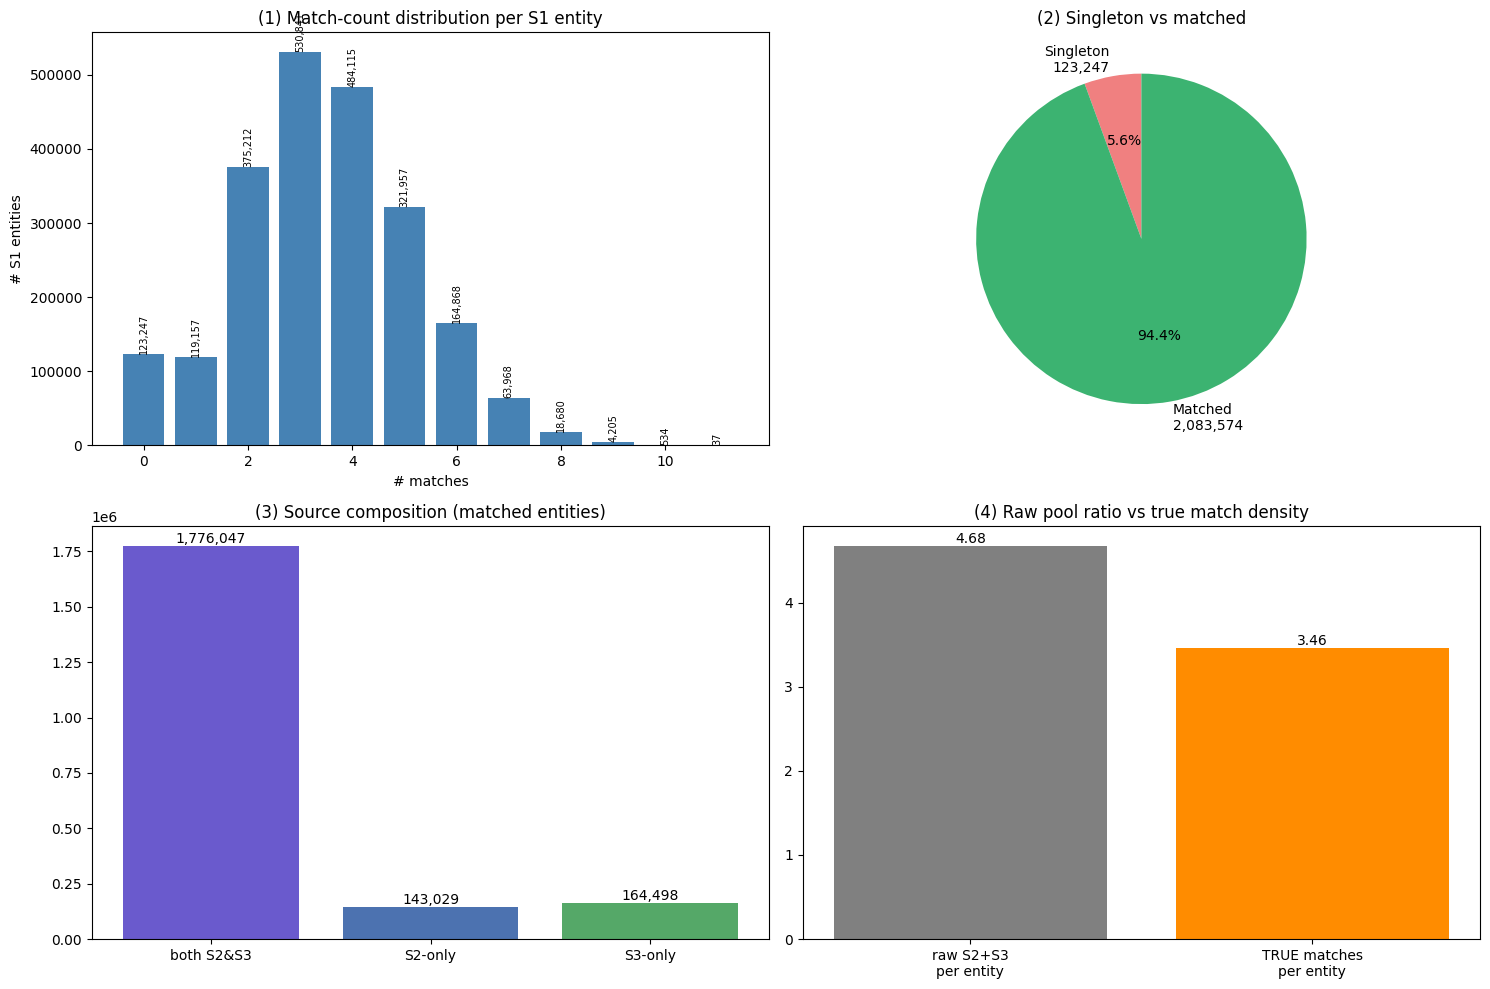

saved figure: /content/drive/MyDrive/unzipped/student_resource/work/phase1_3_crosssource.png


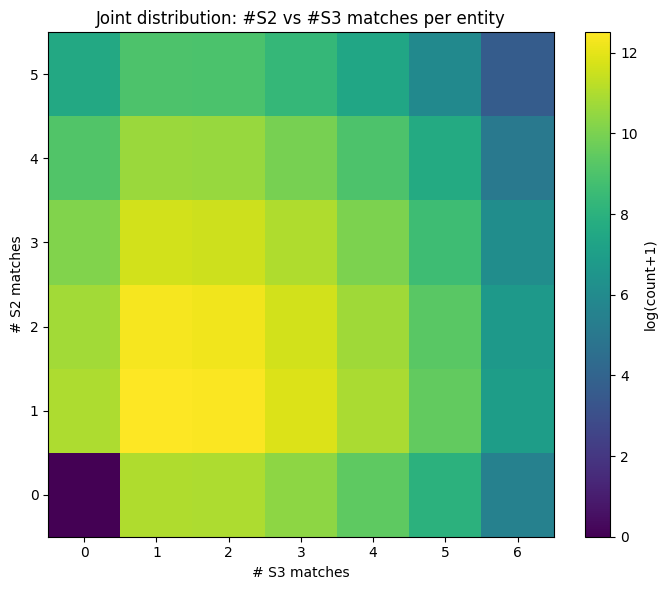



########## REAL MATCH-GROUPS (see what maps to what) ##########

===== SINGLETONS (no match) =====
  S1 [India] 'Indo Super Impex Private Limited'  -> (no matches)
  S1 [US] 'Maxwell's Digital'  -> (no matches)
  S1 [US] 'Pradhan Classic Cms PLLC'  -> (no matches)
  S1 [US] 'Commission on Labor'  -> (no matches)
  S1 [US] 'Milissent Maske Fargo'  -> (no matches)

===== TYPICAL groups (3-4 matches, both sources) =====

  S1 [US] S1-62788927: 'Youth Committee'  (4 matches: 2×S2, 2×S3)
       S2 S2-518304679: 'ycommittee.com'
       S2 S2-287720501: 'YOUTH COMMITTEE INC'
       S3 S3-272040112: 'Youth Services'
       S3 S3-188646046: 'Nexlumx f/k/a Youth Committee'

  S1 [US] S1-451083819: 'Grand Global Inc.'  (4 matches: 2×S2, 2×S3)
       S2 S2-774145525: 'Grand Global Inc.'
       S2 S2-502238795: 'Grand Glal Inc.'
       S3 S3-303510223: 'Grand Global'
       S3 S3-81289615: 'Veradeltax formerly: Grand Global Inc.'

  S1 [India] S1-534170181: 'Shivam Infotech Private Limited'  (3 m

In [ ]:
# =====================================================================================
# PHASE 1.3 — CROSS-SOURCE EDA (ground-truth relationships)
#   1) match-count distribution per S1 entity
#   2) singleton rate
#   3) S2-only / S3-only / both composition
#   4) raw candidate pool size vs true match density (the blocking-necessity contrast)
#   + real printed match-groups (see what matches to what) + matplotlib visuals
# Self-contained. No GPU.
# =====================================================================================
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

SEED = 42
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv", "GT": f"{DATA}/train/train_ground_truth.tsv"}

# ---- row counts (cheap, exact) ----
def count_rows(p): return sum(1 for _ in open(p,"rb")) - 1
N_S1, N_S2, N_S3 = count_rows(F["S1"]), count_rows(F["S2"]), count_rows(F["S3"])

# ---- name/country lookups (for readable examples) ----
def build(path):
    nm, ct = {}, {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_name","country"], chunksize=1_000_000):
        nm.update(zip(ch.entity_id, ch.business_name)); ct.update(zip(ch.entity_id, ch.country))
    return nm, ct
print("building lookups ...")
s1_nm, s1_ct = build(F["S1"]); s2_nm,_ = build(F["S2"]); s3_nm,_ = build(F["S3"])
def gname(i): return s2_nm.get(i) or s3_nm.get(i)

gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s: [x for x in s.split(",") if x])
gt["n"]  = gt["ml"].str.len()
gt["nS2"] = gt["ml"].apply(lambda l: sum(x.startswith("S2-") for x in l))
gt["nS3"] = gt["ml"].apply(lambda l: sum(x.startswith("S3-") for x in l))
gt["country"] = gt["source1_entity_id"].map(s1_ct)

TOTAL = len(gt); LINKS = int(gt["n"].sum())

# =====================================================================================
# (1) MATCH-COUNT DISTRIBUTION
# =====================================================================================
dist = gt["n"].value_counts().sort_index()
print("\n[1] MATCH-COUNT DISTRIBUTION per S1 entity")
print(dist.to_string())
print(f"    mean={gt['n'].mean():.3f}  median={int(gt['n'].median())}  max={gt['n'].max()}")

# =====================================================================================
# (2) SINGLETON RATE
# =====================================================================================
n_single = int((gt["n"]==0).sum())
print(f"\n[2] SINGLETON RATE: {n_single:,}/{TOTAL:,} = {100*n_single/TOTAL:.2f}%")
print("    singleton rate by country:")
print((gt.groupby("country")["n"].apply(lambda s: round(100*(s==0).mean(),2))).to_string())

# =====================================================================================
# (3) S2-ONLY / S3-ONLY / BOTH COMPOSITION (over matched entities)
# =====================================================================================
m = gt[gt["n"]>0]
both  = int(((m.nS2>0)&(m.nS3>0)).sum())
onlyS2= int(((m.nS2>0)&(m.nS3==0)).sum())
onlyS3= int(((m.nS2==0)&(m.nS3>0)).sum())
M = len(m)
print("\n[3] SOURCE COMPOSITION (matched entities only)")
print(f"    both S2&S3 : {both:,} ({100*both/M:.1f}%)")
print(f"    S2-only    : {onlyS2:,} ({100*onlyS2/M:.1f}%)")
print(f"    S3-only    : {onlyS3:,} ({100*onlyS3/M:.1f}%)")
print(f"    link source mix: S2={int(m.nS2.sum()):,}  S3={int(m.nS3.sum()):,}")

# =====================================================================================
# (4) RAW POOL vs TRUE MATCH DENSITY (the blocking-necessity contrast)
# =====================================================================================
raw_per_entity = (N_S2 + N_S3) / N_S1
true_density   = gt["n"].mean()
print("\n[4] RAW POOL vs TRUE MATCH DENSITY")
print(f"    S2 rows={N_S2:,}  S3 rows={N_S3:,}  S1 entities={N_S1:,}")
print(f"    raw S2+S3 rows per S1 entity (even split) : {raw_per_entity:.2f}")
print(f"    TRUE matches per S1 entity (mean)         : {true_density:.2f}")
print(f"    total haystack to search per entity       : {N_S2+N_S3:,} rows")
print(f"    => without blocking, finding ~{true_density:.1f} needles requires scanning")
print(f"       {N_S2+N_S3:,} rows PER S1 entity  ->  {N_S1*(N_S2+N_S3):,} brute-force comparisons")
print(f"    => blocking is architecturally mandatory, not optional.")

# =====================================================================================
# VISUALS
# =====================================================================================
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# (a) match-count distribution
z = dist[dist.index<=11]
ax[0,0].bar(z.index, z.values, color="steelblue")
ax[0,0].set_title("(1) Match-count distribution per S1 entity")
ax[0,0].set_xlabel("# matches"); ax[0,0].set_ylabel("# S1 entities")
for x,y in zip(z.index,z.values): ax[0,0].text(x,y,f"{y:,}",ha="center",va="bottom",fontsize=7,rotation=90)

# (b) singleton vs matched pie
ax[0,1].pie([n_single, TOTAL-n_single],
            labels=[f"Singleton\n{n_single:,}", f"Matched\n{TOTAL-n_single:,}"],
            autopct="%1.1f%%", colors=["lightcoral","mediumseagreen"], startangle=90)
ax[0,1].set_title("(2) Singleton vs matched")

# (c) source composition
ax[1,0].bar(["both S2&S3","S2-only","S3-only"], [both,onlyS2,onlyS3],
            color=["slateblue","#4c72b0","#55a868"])
ax[1,0].set_title("(3) Source composition (matched entities)")
for i,v in enumerate([both,onlyS2,onlyS3]): ax[1,0].text(i,v,f"{v:,}",ha="center",va="bottom")

# (d) raw pool vs true density
ax[1,1].bar(["raw S2+S3\nper entity","TRUE matches\nper entity"],
            [raw_per_entity, true_density], color=["gray","darkorange"])
ax[1,1].set_title("(4) Raw pool ratio vs true match density")
for i,v in enumerate([raw_per_entity, true_density]): ax[1,1].text(i,v,f"{v:.2f}",ha="center",va="bottom")

plt.tight_layout(); plt.savefig(f"{WORK}/phase1_3_crosssource.png", dpi=110); plt.show()
print(f"saved figure: {WORK}/phase1_3_crosssource.png")

# 2D joint distribution heatmap: #S2 vs #S3 per entity
piv = m.groupby(["nS2","nS3"]).size().unstack(fill_value=0).iloc[:8,:8]
plt.figure(figsize=(7,6))
plt.imshow(np.log1p(piv.values), origin="lower", cmap="viridis", aspect="auto")
plt.colorbar(label="log(count+1)")
plt.xticks(range(piv.shape[1]), piv.columns); plt.yticks(range(piv.shape[0]), piv.index)
plt.xlabel("# S3 matches"); plt.ylabel("# S2 matches")
plt.title("Joint distribution: #S2 vs #S3 matches per entity")
plt.tight_layout(); plt.savefig(f"{WORK}/phase1_3_joint.png", dpi=110); plt.show()

# =====================================================================================
# REAL MATCH-GROUPS — SEE what matches to what (readable names + source + country)
# =====================================================================================
def show_group(row):
    s1id = row.source1_entity_id
    print(f"\n  S1 [{row.country}] {s1id}: '{s1_nm[s1id]}'  ({row.n} matches: {row.nS2}×S2, {row.nS3}×S3)")
    for mid in row.ml:
        src = "S2" if mid.startswith("S2-") else "S3"
        print(f"       {src} {mid}: '{gname(mid)}'")

print("\n\n########## REAL MATCH-GROUPS (see what maps to what) ##########")

print("\n===== SINGLETONS (no match) =====")
for _, r in gt[gt.n==0].sample(5, random_state=SEED).iterrows():
    print(f"  S1 [{r.country}] '{s1_nm[r.source1_entity_id]}'  -> (no matches)")

print("\n===== TYPICAL groups (3-4 matches, both sources) =====")
for _, r in m[(m.n.between(3,4)) & (m.nS2>0) & (m.nS3>0)].sample(5, random_state=SEED).iterrows():
    show_group(r)

print("\n===== S2-ONLY groups =====")
for _, r in m[(m.nS2>0)&(m.nS3==0)].sample(3, random_state=SEED).iterrows(): show_group(r)

print("\n===== S3-ONLY groups =====")
for _, r in m[(m.nS2==0)&(m.nS3>0)].sample(3, random_state=SEED).iterrows(): show_group(r)

print("\n===== LARGEST groups (max matches) =====")
for _, r in m.nlargest(3, "n").iterrows(): show_group(r)

print("\n===== INDIA groups (multilingual matches visible) =====")
for _, r in m[m.country=="India"].sample(5, random_state=SEED).iterrows(): show_group(r)

# persist stats
pd.DataFrame([{"metric":"total_entities","value":TOTAL},{"metric":"singletons","value":n_single},
    {"metric":"singleton_pct","value":round(100*n_single/TOTAL,2)},
    {"metric":"both_pct","value":round(100*both/M,2)},{"metric":"s2only_pct","value":round(100*onlyS2/M,2)},
    {"metric":"s3only_pct","value":round(100*onlyS3/M,2)},{"metric":"mean_matches","value":round(true_density,3)},
    {"metric":"raw_pool_per_entity","value":round(raw_per_entity,3)},
    {"metric":"total_links","value":LINKS}]).to_csv(f"{WORK}/phase1_3_stats.csv", index=False)
print(f"\nsaved: {WORK}/phase1_3_stats.csv")
print("\nPHASE 1.3 COMPLETE.")


In [ ]:
# =====================================================================================
# PHASE 1.4 — COUNTRY-SPECIFIC PATTERN ANALYSIS
#   postal-code presence & FORMAT by country, legal-suffix freq & VOCAB by country,
#   landmark-phrase freq by country, script by country
#   -> decides: does normalization/blocking need country-branching?
# Self-contained. No GPU.
# =====================================================================================
import os, re, random
import numpy as np, pandas as pd
from collections import Counter

SEED = 42; random.seed(SEED)
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv"}

# large sample per source for accurate per-country rates
def load_sample(path, n=400_000):
    tot = sum(1 for _ in open(path,"rb"))-1
    if n>=tot: return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
    keep=set(random.sample(range(1,tot+1),n)); skip=[i for i in range(1,tot+1) if i not in keep]
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8", skiprows=skip)

print("loading samples ...")
df = pd.concat([load_sample(F[k]).assign(src=k) for k in ["S1","S2","S3"]], ignore_index=True)
print("combined sample:", len(df), "| countries:", dict(df.country.value_counts()))

# ---------- detectors (non-capturing => no pandas warning) ----------
RE_US_ZIP   = re.compile(r"\b\d{5}(?:-\d{4})?\b")
RE_IN_PIN   = re.compile(r"\b\d{6}\b")
RE_ANY_POST = re.compile(r"\b(?:\d{5}(?:-\d{4})?|\d{6})\b")
RE_LEGAL    = re.compile(r"\b(?:inc|incorporated|corp|corporation|ltd|limited|llc|llp|pllc|lp|"
                         r"pvt|private|co|company|sarl|sas|gmbh|plc|pte)\b", re.I)
RE_LAND     = re.compile(r"\b(?:near|beside|behind|opp\.?|opposite|adjacent|in front of|"
                         r"backside|back side)\b", re.I)
RE_INDIC    = re.compile(r"[\u0900-\u0D7F]")               # all Indic blocks
RE_NONLATIN = re.compile(r"[^\x00-\x7F]")
LEGAL_TOKENS = ["inc","incorporated","corp","corporation","ltd","limited","llc","llp","pllc",
                "lp","pvt","private","co","company","sarl","sas","gmbh","plc","pte"]

pct = lambda mask: round(100*mask.mean(), 2)

# =====================================================================================
# (A) PER-COUNTRY RATE TABLE
# =====================================================================================
print("\n[A] PER-COUNTRY PATTERN RATES (% of rows)")
countries = sorted(df.country.unique())
rows = []
for c in countries:
    sub = df[df.country==c]; nm, ad = sub.business_name, sub.business_address
    rows.append({
        "country": c, "rows": len(sub),
        "US_zip%":       pct(ad.str.contains(RE_US_ZIP, regex=True)),
        "IN_pin(6dig)%": pct(ad.str.contains(RE_IN_PIN, regex=True)),
        "any_postal%":   pct(ad.str.contains(RE_ANY_POST, regex=True)),
        "legal_suffix%": pct(nm.str.contains(RE_LEGAL, regex=True)),
        "landmark%":     pct(ad.str.contains(RE_LAND, regex=True)),
        "name_indic%":   pct(nm.str.contains(RE_INDIC, regex=True)),
        "addr_indic%":   pct(ad.str.contains(RE_INDIC, regex=True)),
        "name_nonlatin%":pct(nm.str.contains(RE_NONLATIN, regex=True)),
        "addr_empty%":   pct(ad.str.strip()==""),
    })
tab = pd.DataFrame(rows).set_index("country")
print(tab.T.to_string())

# =====================================================================================
# (B) LEGAL-SUFFIX VOCABULARY BY COUNTRY (which specific suffixes dominate where)
# =====================================================================================
print("\n[B] LEGAL-SUFFIX VOCABULARY BY COUNTRY (per 1000 rows)")
for c in countries:
    sub = df[df.country==c]; N=len(sub)
    text = " ".join(sub.business_name.str.lower().values)
    toks = Counter(re.findall(r"[a-z]+", text))
    top = [(s, round(1000*toks.get(s,0)/N,1)) for s in LEGAL_TOKENS]
    top = sorted(top, key=lambda x:-x[1])[:8]
    print(f"   {c:8s}: " + "  ".join(f"{s}={r}" for s,r in top))

# =====================================================================================
# (C) POSTAL FORMAT BY COUNTRY (what the codes actually look like)
# =====================================================================================
print("\n[C] POSTAL-CODE FORMAT EXAMPLES BY COUNTRY")
for c in countries:
    sub = df[df.country==c]
    hits = sub[sub.business_address.str.contains(RE_ANY_POST, regex=True)]
    ex = []
    for a in hits.business_address.head(6):
        codes = RE_ANY_POST.findall(a)
        ex.append(codes[0] if codes else "?")
    print(f"   {c:8s}: examples {ex}")

# =====================================================================================
# (D) REAL EXAMPLES showing country DIFFERENCES side by side
# =====================================================================================
def samples_for(c, mask, col, k=5):
    sub = df[(df.country==c) & mask(df)]
    return sub[col].head(k).tolist()

print("\n[D] REAL EXAMPLES — landmarks (India) vs postal (US)")
for c in countries:
    land = samples_for(c, lambda d: d.business_address.str.contains(RE_LAND, regex=True), "business_address", 3)
    print(f"\n   {c} landmark addresses:")
    for x in land: print(f"      {x}")

print("\n   US ZIP-style addresses:")
for x in samples_for("US", lambda d: d.business_address.str.contains(RE_US_ZIP, regex=True), "business_address", 4):
    print(f"      {x}")
if "India" in countries:
    print("   India 6-digit PIN addresses (if any):")
    for x in samples_for("India", lambda d: d.business_address.str.contains(RE_IN_PIN, regex=True), "business_address", 4):
        print(f"      {x}")

# =====================================================================================
# (E) BRANCHING DECISION SUMMARY
# =====================================================================================
print("\n[E] COUNTRY-BRANCHING DECISION")
print("    Compare the columns of table [A]. A pattern needs country-specific handling")
print("    if its rate differs sharply across countries (e.g. landmarks, postal format,")
print("    Indic script). A pattern that is uniform across countries can use one rule.")

tab.T.to_csv(f"{WORK}/phase1_4_country_patterns.csv")
print(f"\nsaved: {WORK}/phase1_4_country_patterns.csv")
print("\nPHASE 1.4 COMPLETE.")


loading samples ...
combined sample: 1200000 | countries: {'US': np.int64(718405), 'India': np.int64(481595)}

[A] PER-COUNTRY PATTERN RATES (% of rows)
country             India         US
rows            481595.00  718405.00
US_zip%              0.76      10.35
IN_pin(6dig)%        0.00       0.96
any_postal%          0.76      11.31
legal_suffix%       68.42      47.55
landmark%            9.55       0.01
name_indic%         12.23       0.00
addr_indic%         15.42       0.00
name_nonlatin%      15.49       4.55
addr_empty%          1.96       2.38

[B] LEGAL-SUFFIX VOCABULARY BY COUNTRY (per 1000 rows)
   India   : limited=390.7  private=351.9  ltd=160.6  pvt=112.7  llp=37.4  co=21.5  corporation=9.4  company=9.1
   US      : llc=209.0  inc=148.3  corp=33.3  co=23.7  ltd=19.8  lp=14.3  pllc=10.7  corporation=10.5

[C] POSTAL-CODE FORMAT EXAMPLES BY COUNTRY
   India   : examples ['10111', '14650', '15121', '18418', '14233', '11009']
   US      : examples ['11900', '14428', '11027'

In [ ]:
# =====================================================================================
# PHASE 1.4 — COUNTRY-SPECIFIC PATTERN ANALYSIS -> branching decisions
#   Re-confirms postal / legal-suffix / landmark rates by country (corpus),
#   AND measures cross-match consistency (do both sides of a true pair agree?),
#   which is what decides whether a signal is usable for blocking vs normalization-only.
# Self-contained. No GPU.
# =====================================================================================
import os, re, random
import numpy as np, pandas as pd
from collections import Counter

SEED = 42; random.seed(SEED)
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv", "GT": f"{DATA}/train/train_ground_truth.tsv"}

# country-AGNOSTIC detectors (no country gating anywhere — France-safe by design)
RE_LEGAL = re.compile(r"\b(inc|incorporated|corp|corporation|ltd|limited|llc|llp|pllc|lp|pvt|"
                      r"private|co|company|sarl|sas|sa|gmbh|plc|pte)\b", re.I)
RE_POSTAL_US = re.compile(r"\b\d{5}(?:-\d{4})?\b")
RE_POSTAL_IN = re.compile(r"\b\d{6}\b")
RE_POSTAL    = re.compile(r"\b(?:\d{5}(?:-\d{4})?|\d{6})\b")
RE_LANDMARK  = re.compile(r"\b(?:near|beside|behind|opp\.?|opposite|adjacent|in front of|"
                          r"back side|backside|next to)\b", re.I)

def build(path):
    nm, ad, ct = {}, {}, {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_name","business_address","country"],
                          chunksize=1_000_000):
        nm.update(zip(ch.entity_id, ch.business_name)); ad.update(zip(ch.entity_id, ch.business_address))
        ct.update(zip(ch.entity_id, ch.country))
    return nm, ad, ct

print("building lookups ...")
s1_nm, s1_ad, s1_ct = build(F["S1"]); s2_nm, s2_ad, _ = build(F["S2"]); s3_nm, s3_ad, _ = build(F["S3"])
def gnm(i): return s2_nm.get(i) or s3_nm.get(i)
def gad(i): return s2_ad.get(i) if i in s2_nm else s3_ad.get(i)

# ---- (A) corpus rates by country, per source (standalone artifact for this bullet) ----
def load_sample(path, n=300_000):
    tot = sum(1 for _ in open(path,"rb"))-1
    if n>=tot: return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
    keep=set(random.sample(range(1,tot+1),n)); skip=[i for i in range(1,tot+1) if i not in keep]
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8", skiprows=skip)

print("\n[A] CORPUS PATTERN RATES by source x country")
rows=[]
for k in ["S1","S2","S3"]:
    df = load_sample(F[k])
    for c in sorted(df.country.unique()):
        sub = df[df.country==c]; nm=sub.business_name; ad=sub.business_address
        pc = lambda m: round(100*m.mean(),2)
        rows.append({"source":k,"country":c,"n":len(sub),
            "legal_suffix_%": pc(nm.str.contains(RE_LEGAL,regex=True)),
            "postal_any_%":   pc(ad.str.contains(RE_POSTAL,regex=True)),
            "postal_US5_%":   pc(ad.str.contains(RE_POSTAL_US,regex=True)),
            "postal_IN6_%":   pc(ad.str.contains(RE_POSTAL_IN,regex=True)),
            "landmark_%":     pc(ad.str.contains(RE_LANDMARK,regex=True)),
            "addr_empty_%":   pc(ad.str.strip()=="")})
rate_df = pd.DataFrame(rows)
print(rate_df.to_string(index=False))
rate_df.to_csv(f"{WORK}/phase1_4_country_rates.csv", index=False)

# ---- (B) CROSS-MATCH CONSISTENCY: on true pairs, do BOTH sides show the signal? ----
# This decides usability: a signal only helps blocking if it survives on both sides.
gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt = gt[gt["ml"].str.len()>0].copy()
gt["country"] = gt["source1_entity_id"].map(s1_ct)

print("\n[B] CROSS-MATCH CONSISTENCY on true pairs (does the signal survive both sides?)")
def has(rx, s): return bool(rx.search(s or ""))
stats = {c: Counter() for c in ["India","US"]}
tot   = {c: 0 for c in ["India","US"]}
for _, r in gt.sample(60_000, random_state=SEED).iterrows():
    c = r["country"]
    if c not in stats: continue
    a_nm, a_ad = s1_nm[r.source1_entity_id], s1_ad[r.source1_entity_id]
    for mid in r["ml"][:2]:
        b_nm, b_ad = gnm(mid), gad(mid)
        if b_nm is None: continue
        tot[c]+=1
        # legal suffix: on S1 vs on match
        if has(RE_LEGAL,a_nm): stats[c]["legal_s1"]+=1
        if has(RE_LEGAL,b_nm): stats[c]["legal_match"]+=1
        if has(RE_LEGAL,a_nm) and has(RE_LEGAL,b_nm): stats[c]["legal_both"]+=1
        # postal: both addresses present
        if a_ad.strip() and (b_ad or "").strip():
            if has(RE_POSTAL,a_ad): stats[c]["postal_s1"]+=1
            if has(RE_POSTAL,b_ad): stats[c]["postal_match"]+=1
            if has(RE_POSTAL,a_ad) and has(RE_POSTAL,b_ad): stats[c]["postal_both"]+=1
            if has(RE_LANDMARK,a_ad): stats[c]["land_s1"]+=1
            if has(RE_LANDMARK,b_ad): stats[c]["land_match"]+=1
            if has(RE_LANDMARK,a_ad) and has(RE_LANDMARK,b_ad): stats[c]["land_both"]+=1

for c in ["India","US"]:
    n=tot[c]; s=stats[c]
    print(f"\n  --- {c} (n={n:,} pairs) ---")
    for sig,keys in [("legal suffix",("legal_s1","legal_match","legal_both")),
                     ("postal code", ("postal_s1","postal_match","postal_both")),
                     ("landmark",    ("land_s1","land_match","land_both"))]:
        s1p,mp,bp = (100*s[keys[0]]/max(n,1), 100*s[keys[1]]/max(n,1), 100*s[keys[2]]/max(n,1))
        cons = 100*s[keys[2]]/max(s[keys[0]],1)   # of S1-side hits, how often match side also has it
        print(f"     {sig:12s} S1={s1p:5.1f}%  match={mp:5.1f}%  both={bp:5.1f}%  "
              f"consistency(if S1 has it, match too)={cons:4.1f}%")

# ---- (C) real examples: postal/landmark surviving vs dropping across a true match ----
print("\n[C] EXAMPLES — signal consistency across true matches")
shown=Counter()
for _, r in gt[gt.country=="India"].sample(30_000, random_state=SEED).iterrows():
    a_ad = s1_ad[r.source1_entity_id]
    for mid in r["ml"]:
        b_ad = gad(mid)
        if not (a_ad.strip() and (b_ad or "").strip()): continue
        if has(RE_LANDMARK,a_ad) and not has(RE_LANDMARK,b_ad) and shown["land_drop"]<4:
            print(f"   [landmark on S1, DROPPED in match]\n     S1: {a_ad}\n     ->: {b_ad}"); shown["land_drop"]+=1
        if has(RE_POSTAL,a_ad) and not has(RE_POSTAL,b_ad) and shown["post_drop"]<4:
            print(f"   [postal on S1, DROPPED in match]\n     S1: {a_ad}\n     ->: {b_ad}"); shown["post_drop"]+=1
    if sum(shown.values())>=8: break

print("\nsaved:", f"{WORK}/phase1_4_country_rates.csv")
print("PHASE 1.4 COMPLETE.")


building lookups ...

[A] CORPUS PATTERN RATES by source x country


/tmp/ipykernel_4012/3806650792.py:56: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "legal_suffix_%": pc(nm.str.contains(RE_LEGAL,regex=True)),
/tmp/ipykernel_4012/3806650792.py:56: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "legal_suffix_%": pc(nm.str.contains(RE_LEGAL,regex=True)),
/tmp/ipykernel_4012/3806650792.py:56: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "legal_suffix_%": pc(nm.str.contains(RE_LEGAL,regex=True)),


source country      n  legal_suffix_%  postal_any_%  postal_US5_%  postal_IN6_%  landmark_%  addr_empty_%
    S1   India 120719           84.43          0.27          0.27          0.00       11.46          0.00
    S1      US 179281           51.73         10.84         10.72          0.12        0.01          0.00
    S2   India 120663           57.22          1.07          1.07          0.00        9.96          2.89
    S2      US 179337           45.90         11.50         10.08          1.42        0.01          3.76
    S3   India 119734           63.78          0.98          0.98          0.00        7.48          3.03
    S3      US 180266           45.23         11.58         10.22          1.36        0.01          3.44

[B] CROSS-MATCH CONSISTENCY on true pairs (does the signal survive both sides?)

  --- India (n=46,718 pairs) ---
     legal suffix S1= 84.1%  match= 55.6%  both= 52.1%  consistency(if S1 has it, match too)=61.9%
     postal code  S1=  0.3%  match=  1.0%  b

In [ ]:
# =====================================================================================
# PHASE 1.4b — DO INDIA ADDRESSES CARRY A PIN CODE, AND IS IT PRESERVED IN THE MATCH?
#   Tests multiple PIN formats (naive undercounts). Measures presence on S1 India
#   addresses AND cross-match preservation. Prints real examples.
# Self-contained. No GPU.
# =====================================================================================
import os, re, random
import numpy as np, pandas as pd
from collections import Counter

SEED = 42; random.seed(SEED)
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv", "GT": f"{DATA}/train/train_ground_truth.tsv"}

# ---- multiple PIN patterns: naive 6-digit undercounts because PINs appear spaced/glued ----
RE_PIN_STRICT = re.compile(r"\b\d{6}\b")                     # 560001 (isolated)
RE_PIN_SPACED = re.compile(r"\b\d{3}\s?\d{3}\b")            # 560 001 or 560001
RE_PIN_ANY6   = re.compile(r"(?<!\d)\d{6}(?!\d)")           # any exact 6-digit run (not part of longer)
RE_ANY_LONGNUM= re.compile(r"\d{6,}")                       # 6+ digit runs (catches glued like 0010433)

def build(path):
    ad, ct = {}, {}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_address","country"], chunksize=1_000_000):
        ad.update(zip(ch.entity_id, ch.business_address)); ct.update(zip(ch.entity_id, ch.country))
    return ad, ct

print("building lookups ...")
s1_ad, s1_ct = build(F["S1"]); s2_ad, _ = build(F["S2"]); s3_ad, _ = build(F["S3"])
def gad(i): return s2_ad.get(i) if i in s2_ad else s3_ad.get(i)

# ---- (A) presence of each PIN pattern on India vs US addresses (S1 sample) ----
def load_sample(path, n=300_000):
    tot=sum(1 for _ in open(path,"rb"))-1
    if n>=tot: return pd.read_csv(path,sep="\t",dtype=str,keep_default_na=False,encoding="utf-8")
    keep=set(random.sample(range(1,tot+1),n)); skip=[i for i in range(1,tot+1) if i not in keep]
    return pd.read_csv(path,sep="\t",dtype=str,keep_default_na=False,encoding="utf-8",skiprows=skip)

df = load_sample(F["S1"])
print("\n[A] PIN/postal presence on S1 addresses by country (multiple patterns)")
for c in sorted(df.country.unique()):
    ad = df[df.country==c].business_address; n=len(ad)
    pc=lambda rx: round(100*ad.str.contains(rx,regex=True).mean(),2)
    print(f"  {c:6s} (n={n:,}): strict6={pc(RE_PIN_STRICT)}  spaced={pc(RE_PIN_SPACED)}  "
          f"any6={pc(RE_PIN_ANY6)}  6+digits={pc(RE_ANY_LONGNUM)}")

# ---- (B) do India addresses that HAVE a PIN preserve it across the true match? ----
gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt=gt[gt["ml"].str.len()>0].copy(); gt["country"]=gt["source1_entity_id"].map(s1_ct)

def pins(s): return set(RE_PIN_ANY6.findall(s or ""))

india = gt[gt.country=="India"].sample(60_000, random_state=SEED)
has_pin=preserved=partial=lost=pairs=0
examples={"preserved":[], "lost":[]}
for _, r in india.iterrows():
    a = s1_ad[r.source1_entity_id]; pa = pins(a)
    if not pa: continue
    for mid in r["ml"]:
        b = gad(mid)
        if b is None or not b.strip(): continue
        pairs+=1; has_pin+=1
        pb = pins(b)
        if pa & pb:
            preserved+=1
            if len(examples["preserved"])<6: examples["preserved"].append((a,b,pa,pb))
        elif pb:
            partial+=1
        else:
            lost+=1
            if len(examples["lost"])<6: examples["lost"].append((a,b,pa,pb))

print(f"\n[B] India true pairs where S1 address HAS a 6-digit PIN: {has_pin:,}")
if has_pin:
    print(f"    PIN preserved in match (shared): {preserved:,} ({100*preserved/has_pin:.1f}%)")
    print(f"    match has a DIFFERENT 6-digit  : {partial:,} ({100*partial/has_pin:.1f}%)")
    print(f"    PIN LOST (match has none)      : {lost:,} ({100*lost/has_pin:.1f}%)")

print("\n[C] EXAMPLES — PIN preserved across match:")
for a,b,pa,pb in examples["preserved"]:
    print(f"    S1 {sorted(pa)}: {a}\n    -> {sorted(pb)}: {b}\n")
print("[C] EXAMPLES — PIN lost in match:")
for a,b,pa,pb in examples["lost"]:
    print(f"    S1 {sorted(pa)}: {a}\n    -> (no pin): {b}\n")

print("PHASE 1.4b COMPLETE.")


building lookups ...

[A] PIN/postal presence on S1 addresses by country (multiple patterns)
  India  (n=120,719): strict6=0.0  spaced=0.34  any6=0.02  6+digits=0.08
  US     (n=179,281): strict6=0.12  spaced=0.55  any6=0.12  6+digits=0.12

[B] India true pairs where S1 address HAS a 6-digit PIN: 47
    PIN preserved in match (shared): 35 (74.5%)
    match has a DIFFERENT 6-digit  : 2 (4.3%)
    PIN LOST (match has none)      : 10 (21.3%)

[C] EXAMPLES — PIN preserved across match:
    S1 ['370215']: 1002 C3 Parkview Raunak G, Soc370215_Park View, Thane, Maharashtra
    -> ['370215']: NO 1002 C3 PARKVIEW RAUNAK G, SOC370215_PARK VIEW, THANE, Maharashtra

    S1 ['370215']: 1002 C3 Parkview Raunak G, Soc370215_Park View, Thane, Maharashtra
    -> ['370215']: #1002 C3 PARKVIEW RAUNAK G, SOC370215_PARK VIEW, THANE, Maharashtra

    S1 ['628103']: 97/1A, 1-A, Kootudankadumangalagiri Post Pudukottai Tuticorin628103, Tamil Nadu
    -> ['628103']: 97/1A, 1-A, KOOTUDANKADUMANGALAGIRI POST PUDU

In [ ]:
# =====================================================================================
# PHASE 1.6 — VOCABULARY / TOKEN FREQUENCY ANALYSIS (Latin + Indic)
#   Informs blocking-key design: which tokens are so common they must NOT drive blocking.
#   Produces a data-derived stopword list (generic words + legal suffixes + honorifics).
# Self-contained. No GPU.
# =====================================================================================
import os, re, random
import numpy as np, pandas as pd
from collections import Counter

SEED = 42; random.seed(SEED)
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"; os.makedirs(WORK, exist_ok=True)
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv"}

RE_LATIN = re.compile(r"[a-z0-9]+")
RE_INDIC = re.compile(r"[\u0900-\u0D7F]+")   # Devanagari..Malayalam block span

def load_sample(path, n=400_000):
    tot=sum(1 for _ in open(path,"rb"))-1
    if n>=tot: return pd.read_csv(path,sep="\t",dtype=str,keep_default_na=False,encoding="utf-8")
    keep=set(random.sample(range(1,tot+1),n)); skip=[i for i in range(1,tot+1) if i not in keep]
    return pd.read_csv(path,sep="\t",dtype=str,keep_default_na=False,encoding="utf-8",skiprows=skip)

print("sampling names from all sources ...")
names=[]
for k in ["S1","S2","S3"]:
    names += load_sample(F[k]).business_name.tolist()
print(f"total names sampled: {len(names):,}")

# ---- token frequency, split by script ----
latin_tok, indic_tok = Counter(), Counter()
n_docs = len(names)
for nm in names:
    low = nm.lower()
    latin_tok.update(RE_LATIN.findall(low))
    indic_tok.update(RE_INDIC.findall(nm))

print("\n[1.6] TOP 40 LATIN TOKENS (candidate stopwords):")
for t,c in latin_tok.most_common(40):
    print(f"   {t:16s} {c:>9,}  (in {100*c/n_docs:.2f}% of names)")

print("\n[1.6] TOP 25 INDIC TOKENS:")
for t,c in indic_tok.most_common(25):
    print(f"   {t:20s} {c:>8,}  ({100*c/n_docs:.2f}%)")

# ---- document frequency (fraction of NAMES containing the token) is what matters for blocking ----
# recompute as presence-per-name (not raw count) for the top candidates
top_candidates = [t for t,_ in latin_tok.most_common(120)]
df_presence = Counter()
for nm in names:
    toks = set(RE_LATIN.findall(nm.lower()))
    for t in top_candidates:
        if t in toks: df_presence[t]+=1

# ---- auto-derive stopword list: tokens present in > 1% of names (too common to block on) ----
STOP_THRESHOLD = 0.01
auto_stop = sorted([t for t in top_candidates if df_presence[t]/n_docs > STOP_THRESHOLD],
                   key=lambda t:-df_presence[t])
print(f"\n[1.6] AUTO-DERIVED STOPWORDS (document freq > {STOP_THRESHOLD:.0%}): {len(auto_stop)} tokens")
for t in auto_stop:
    print(f"   {t:16s} df={100*df_presence[t]/n_docs:.2f}%")

# curated additions: legal suffixes + honorifics that may fall just under threshold
CURATED = {"inc","incorporated","corp","corporation","ltd","limited","llc","llp","pllc","lp",
           "pvt","private","co","company","sarl","sas","sa","gmbh","plc","pte",
           "the","and","of","mr","mrs","smt","shri","sri","dr","m","s","c","l","p"}
STOPWORDS = sorted(set(auto_stop) | CURATED)
print(f"\n[1.6] FINAL STOPWORD LIST: {len(STOPWORDS)} tokens")
print("   ", STOPWORDS)

# ---- how much do stopwords dominate? share of total tokens they account for ----
stop_share = sum(latin_tok[t] for t in STOPWORDS if t in latin_tok) / max(sum(latin_tok.values()),1)
print(f"\n[1.6] stopwords account for {100*stop_share:.1f}% of ALL latin token occurrences")
print("   => blocking on raw tokens would be dominated by these; IDF/stopword filtering required.")

pd.Series(STOPWORDS).to_csv(f"{WORK}/stopwords.csv", index=False, header=["token"])
# also save full token freq for IDF weighting later
pd.DataFrame([{"token":t,"count":c,"doc_freq_pct":round(100*df_presence.get(t,0)/n_docs,3)}
              for t,c in latin_tok.most_common(500)]).to_csv(f"{WORK}/token_freq.csv", index=False)
print(f"saved: {WORK}/stopwords.csv , {WORK}/token_freq.csv")
print("PHASE 1.6 COMPLETE.")


sampling names from all sources ...
total names sampled: 1,200,000

[1.6] TOP 40 LATIN TOKENS (candidate stopwords):
   limited            188,443  (in 15.70% of names)
   private            169,636  (in 14.14% of names)
   llc                150,141  (in 12.51% of names)
   inc                106,515  (in 8.88% of names)
   ltd                 91,564  (in 7.63% of names)
   pvt                 54,276  (in 4.52% of names)
   l                   39,620  (in 3.30% of names)
   center              38,821  (in 3.24% of names)
   s                   34,936  (in 2.91% of names)
   c                   33,058  (in 2.75% of names)
   com                 31,973  (in 2.66% of names)
   partners            31,057  (in 2.59% of names)
   services            30,070  (in 2.51% of names)
   group               29,552  (in 2.46% of names)
   and                 28,932  (in 2.41% of names)
   india               28,910  (in 2.41% of names)
   corp                28,247  (in 2.35% of names)
   co        

In [ ]:
# =====================================================================================
# PHASE 1.5 (REWRITE) — ADVERSARIAL HARD-CASE MINING, tightened + verifiable
#   T1 same base-name, DIFFERENT category word -> different businesses (false-merge trap)
#   T2 same ADDRESS, different business (false-merge trap)
#   T3 chain/franchise: same name at MANY distinct addresses (disambiguation trap)
#   T4 near-duplicate names differing by ONE token, split into SAME-biz vs DIFFERENT-biz
#   Every case prints EVIDENCE (GT match names) so it can be visually verified.
# Self-contained. Needs work/stopwords.csv from 1.6.
# =====================================================================================
import os, re, random, difflib
import numpy as np, pandas as pd
from collections import Counter, defaultdict

SEED = 42; random.seed(SEED)
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv", "GT": f"{DATA}/train/train_ground_truth.tsv"}

STOPWORDS = set(pd.read_csv(f"{WORK}/stopwords.csv")["token"].astype(str))
RE_TOK = re.compile(r"[a-z0-9]+")

# category words = generic business-type words. Two names sharing a base but differing
# ONLY by one of these = the classic category-collision trap.
CATEGORY_WORDS = {"traders","trading","consultants","consultancy","spa","salon","foods","food",
                  "clothes","textiles","hotel","hotels","restaurant","bakery","cafe","clinic",
                  "hospital","pharmacy","motors","automobiles","industries","enterprises",
                  "constructions","construction","builders","developers","realty","properties",
                  "solutions","technologies","tech","infotech","softwares","software","finance",
                  "investments","capital","logistics","transport","exports","imports","electronics",
                  "electricals","hardware","furniture","jewellers","jewelry","stores","store","mart",
                  "agencies","agency","services","supplies","products","group","associates"}

def content_tokens(s):
    return [t for t in RE_TOK.findall(s.lower()) if t not in STOPWORDS and len(t)>1]

# base = content tokens with category words ALSO removed (the shared "brand" core)
def base_tokens(s):
    return tuple(sorted(t for t in content_tokens(s) if t not in CATEGORY_WORDS))
def cat_words(s):
    return set(t for t in content_tokens(s) if t in CATEGORY_WORDS)

print("loading S1 + GT ...")
s1 = pd.read_csv(F["S1"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_map = dict(zip(gt.source1_entity_id, gt.ml))

# match-name lookup for EVIDENCE printing
def build_nm(path):
    d={}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_name"], chunksize=1_000_000):
        d.update(zip(ch.entity_id, ch.business_name))
    return d
s2_nm = build_nm(F["S2"]); s3_nm = build_nm(F["S3"])
def gnm(i): return s2_nm.get(i) or s3_nm.get(i)
def evidence(eid, k=2):
    ms = gt_map.get(eid, [])
    return [gnm(m) for m in ms[:k]] if ms else ["<singleton>"]

s1["base"] = s1.business_name.map(lambda x: " ".join(base_tokens(x)))
s1["addr_norm"] = (s1.business_address.str.lower().str.replace(r"[^\w]"," ",regex=True)
                   .str.replace(r"\s+"," ",regex=True).str.strip())

def disjoint(ids):
    sets=[set(gt_map.get(i,[])) for i in ids]
    return all(sets[a] and sets[b] and not(sets[a]&sets[b])
               for a in range(len(sets)) for b in range(a+1,len(sets)))

hard=[]

# ---------------------------------------------------------------------------
# T1: same BASE, DIFFERENT category word, confirmed different businesses
# ---------------------------------------------------------------------------
print("\n[T1] category collisions (same base, different category word) ...")
t1=0
for base, grp in s1[s1.base.str.len()>=3].groupby("base"):
    if grp.entity_id.nunique() < 2: continue
    catsets = grp.business_name.map(cat_words)
    # require the category words to actually DIFFER across the group
    if len(set(map(frozenset, catsets))) < 2: continue
    ids = grp.entity_id.tolist()[:3]
    if not disjoint(ids): continue          # confirmed different businesses via GT
    t1+=1
    if len(hard)<10_000:
        hard.append({"trap":"T1_category_collision","base":base,
                     "names":" | ".join(grp.business_name.tolist()[:3]),
                     "label":"DIFFERENT","evidence":str({i:evidence(i) for i in ids})})
print(f"   confirmed T1 groups: {t1:,}")

# ---------------------------------------------------------------------------
# T2: same address, different business (different base names)
# ---------------------------------------------------------------------------
print("[T2] same-address different-business ...")
t2=0
for addr, grp in s1[s1.addr_norm.str.len()>10].groupby("addr_norm"):
    if grp.entity_id.nunique()<2: continue
    if grp.base.nunique()<2: continue        # genuinely different names
    ids=grp.entity_id.tolist()[:3]
    if not disjoint(ids): continue
    t2+=1
    if len(hard)<10_000:
        hard.append({"trap":"T2_addr_collision","base":addr[:50],
                     "names":" | ".join(grp.business_name.tolist()[:3]),
                     "label":"DIFFERENT","evidence":str({i:evidence(i) for i in ids})})
print(f"   confirmed T2 groups: {t2:,}")

# ---------------------------------------------------------------------------
# T3: chain/franchise — same base-name at MANY distinct addresses (all real, distinct)
# ---------------------------------------------------------------------------
print("[T3] chain/franchise (same base, >=5 distinct addresses) ...")
t3=0
for base, grp in s1[s1.base.str.len()>=3].groupby("base"):
    if grp.addr_norm.nunique()>=5:
        t3+=1
        if len(hard)<10_000:
            ex_ids = grp.entity_id.tolist()[:3]
            hard.append({"trap":"T3_chain","base":base,
                         "names":grp.business_name.iloc[0]+f"  (@{grp.addr_norm.nunique()} addresses)",
                         "label":"DISTINCT_LOCATIONS",
                         "evidence":str({i:evidence(i) for i in ex_ids})})
print(f"   T3 chain names: {t3:,}")

# ---------------------------------------------------------------------------
# T4: near-duplicate names differing by ONE token, split SAME vs DIFFERENT business
# ---------------------------------------------------------------------------
print("[T4] one-token-diff near-duplicates (labeled same/diff via GT) ...")
bucket=defaultdict(list)
for _, r in s1[s1.base.str.len()>0].sample(200_000, random_state=SEED).iterrows():
    bt=base_tokens(r.business_name)
    if bt: bucket[bt[0]].append((r.entity_id, r.business_name, set(bt)))
t4_same=t4_diff=0
for b, items in bucket.items():
    for i in range(len(items)):
        for j in range(i+1, min(i+12, len(items))):
            a_id,a_nm,a_t=items[i]; b_id,b_nm,b_t=items[j]
            if a_t==b_t: continue
            if len(a_t ^ b_t)!=1 or len(a_t & b_t)<1: continue   # differ by EXACTLY one token
            shared = bool(set(gt_map.get(a_id,[])) & set(gt_map.get(b_id,[])))
            lbl = "SAME" if shared else "DIFFERENT"
            if lbl=="SAME": t4_same+=1
            else: t4_diff+=1
            if len(hard)<10_000:
                hard.append({"trap":"T4_one_token","base":"",
                             "names":f"{a_nm}  <>  {b_nm}","label":lbl,
                             "evidence":f"{a_id}:{evidence(a_id,1)} || {b_id}:{evidence(b_id,1)}"})
print(f"   T4 same-business: {t4_same:,} | different-business: {t4_diff:,}")

# ---------------------------------------------------------------------------
# BUILD BALANCED HARD-CASE VALIDATION SET (small: ~150 per trap, balanced labels)
# ---------------------------------------------------------------------------
hc = pd.DataFrame(hard)
def sample_trap(df, trap, n=150):
    sub = df[df.trap==trap]
    if trap=="T4_one_token":   # balance same vs diff
        s = pd.concat([sub[sub.label=="SAME"].sample(min(75,(sub.label=="SAME").sum()),random_state=SEED),
                       sub[sub.label=="DIFFERENT"].sample(min(75,(sub.label=="DIFFERENT").sum()),random_state=SEED)])
        return s
    return sub.sample(min(n,len(sub)), random_state=SEED)

val = pd.concat([sample_trap(hc,t) for t in ["T1_category_collision","T2_addr_collision","T3_chain","T4_one_token"]])
val.to_csv(f"{WORK}/hard_cases_validation.csv", index=False)

print("\n" + "="*72)
print("HARD-CASE VALIDATION SET SUMMARY")
print("="*72)
print(f"total cases: {len(val)}")
print(val.groupby(["trap","label"]).size().to_string())
print(f"\nfull population found (before sampling):")
print(f"   T1 category collisions : {t1:,}")
print(f"   T2 address collisions  : {t2:,}")
print(f"   T3 chain/franchise     : {t3:,}")
print(f"   T4 same/diff pairs     : {t4_same:,} / {t4_diff:,}")
print(f"\nsaved: {WORK}/hard_cases_validation.csv")

# ---------------------------------------------------------------------------
# READABLE EXAMPLES WITH EVIDENCE
# ---------------------------------------------------------------------------
for trap in ["T1_category_collision","T2_addr_collision","T3_chain","T4_one_token"]:
    print("\n" + "-"*72)
    print(f"EXAMPLES — {trap}")
    print("-"*72)
    for _, r in val[val.trap==trap].head(6).iterrows():
        print(f"\n  NAMES : {r['names']}")
        print(f"  LABEL : {r['label']}")
        print(f"  GT EVIDENCE (what each actually matches): {r['evidence']}")

print("\nPHASE 1.5 COMPLETE.")


loading S1 + GT ...

[T1] category collisions (same base, different category word) ...
   confirmed T1 groups: 28,961
[T2] same-address different-business ...
   confirmed T2 groups: 35,254
[T3] chain/franchise (same base, >=5 distinct addresses) ...
   T3 chain names: 46,399
[T4] one-token-diff near-duplicates (labeled same/diff via GT) ...
   T4 same-business: 0 | different-business: 223,260

HARD-CASE VALIDATION SET SUMMARY
total cases: 150
trap                   label    
T1_category_collision  DIFFERENT    150

full population found (before sampling):
   T1 category collisions : 28,961
   T2 address collisions  : 35,254
   T3 chain/franchise     : 46,399
   T4 same/diff pairs     : 0 / 223,260

saved: /content/drive/MyDrive/unzipped/student_resource/work/hard_cases_validation.csv

------------------------------------------------------------------------
EXAMPLES — T1_category_collision
------------------------------------------------------------------------

  NAMES : Certified Dig

In [ ]:
# =====================================================================================
# PHASE 1.5 — ADVERSARIAL HARD-CASE MINING (single corrected self-contained cell)
#   T1 same base-name, DIFFERENT category word -> different businesses (false-merge trap)
#   T2 same ADDRESS, different business (false-merge trap)
#   T3 chain/franchise: same base-name at MANY distinct addresses (disambiguation trap)
#   T4 near-duplicate names differing by ONE base token, labeled SAME vs DIFFERENT via GT
#   Per-trap buffers (no starving). GT evidence printed for every case. Needs work/stopwords.csv.
# =====================================================================================
import os, re, random
import numpy as np, pandas as pd
from collections import defaultdict

SEED = 42; random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 200)
BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"; WORK = f"{BASE}/work"
F = {"S1": f"{DATA}/train/train_source1.tsv", "S2": f"{DATA}/train/train_source2.tsv",
     "S3": f"{DATA}/train/train_source3.tsv", "GT": f"{DATA}/train/train_ground_truth.tsv"}

STOPWORDS = set(pd.read_csv(f"{WORK}/stopwords.csv")["token"].astype(str))
RE_TOK = re.compile(r"[a-z0-9]+")

CATEGORY_WORDS = {"traders","trading","consultants","consultancy","spa","salon","foods","food",
                  "clothes","textiles","hotel","hotels","restaurant","bakery","cafe","clinic",
                  "hospital","pharmacy","motors","automobiles","industries","enterprises",
                  "constructions","construction","builders","developers","realty","properties",
                  "solutions","technologies","tech","infotech","softwares","software","finance",
                  "investments","capital","logistics","transport","exports","imports","electronics",
                  "electricals","hardware","furniture","jewellers","jewelry","stores","store","mart",
                  "agencies","agency","services","supplies","products","group","associates"}

def content_tokens(s): return [t for t in RE_TOK.findall(s.lower()) if t not in STOPWORDS and len(t)>1]
def base_tokens(s):    return tuple(sorted(t for t in content_tokens(s) if t not in CATEGORY_WORDS))
def cat_words(s):      return set(t for t in content_tokens(s) if t in CATEGORY_WORDS)

print("loading S1 + GT ...")
s1 = pd.read_csv(F["S1"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt = pd.read_csv(F["GT"], sep="\t", dtype=str, keep_default_na=False, encoding="utf-8")
gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_map = dict(zip(gt.source1_entity_id, gt.ml))

print("building match-name lookups ...")
def build_nm(path):
    d={}
    for ch in pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, encoding="utf-8",
                          usecols=["entity_id","business_name"], chunksize=1_000_000):
        d.update(zip(ch.entity_id, ch.business_name))
    return d
s2_nm = build_nm(F["S2"]); s3_nm = build_nm(F["S3"])
def gnm(i): return s2_nm.get(i) or s3_nm.get(i)
def evidence(eid, k=2):
    ms = gt_map.get(eid, [])
    return [gnm(m) for m in ms[:k]] if ms else ["<singleton>"]

s1["base"] = s1.business_name.map(lambda x: " ".join(base_tokens(x)))
s1["addr_norm"] = (s1.business_address.str.lower().str.replace(r"[^\w]"," ",regex=True)
                   .str.replace(r"\s+"," ",regex=True).str.strip())

def disjoint(ids):
    sets=[set(gt_map.get(i,[])) for i in ids]
    return all(sets[a] and sets[b] and not(sets[a]&sets[b])
               for a in range(len(sets)) for b in range(a+1,len(sets)))

CAP = 3000
buf = defaultdict(list)

# ---- T1: category collisions ----
print("[T1] category collisions (same base, different category word) ...")
t1=0
for base, grp in s1[s1.base.str.len()>=3].groupby("base"):
    if grp.entity_id.nunique()<2: continue
    if len(set(map(frozenset, grp.business_name.map(cat_words)))) < 2: continue
    ids=grp.entity_id.tolist()[:3]
    if not disjoint(ids): continue
    t1+=1
    if len(buf["T1_category_collision"])<CAP:
        buf["T1_category_collision"].append({"trap":"T1_category_collision",
            "names":" | ".join(grp.business_name.tolist()[:3]),"label":"DIFFERENT",
            "evidence":str({i:evidence(i) for i in ids})})

# ---- T2: same address, different business ----
print("[T2] same-address different-business ...")
t2=0
for addr, grp in s1[s1.addr_norm.str.len()>10].groupby("addr_norm"):
    if grp.entity_id.nunique()<2 or grp.base.nunique()<2: continue
    ids=grp.entity_id.tolist()[:3]
    if not disjoint(ids): continue
    t2+=1
    if len(buf["T2_addr_collision"])<CAP:
        buf["T2_addr_collision"].append({"trap":"T2_addr_collision",
            "names":" | ".join(grp.business_name.tolist()[:3]),"label":"DIFFERENT",
            "evidence":f"ADDR='{addr[:70]}' :: "+str({i:evidence(i) for i in ids})})

# ---- T3: chain/franchise ----
print("[T3] chain/franchise (same base, >=5 distinct addresses) ...")
t3=0
for base, grp in s1[s1.base.str.len()>=3].groupby("base"):
    if grp.addr_norm.nunique()>=5:
        t3+=1
        if len(buf["T3_chain"])<CAP:
            ids=grp.entity_id.tolist()[:3]
            addrs=grp.addr_norm.tolist()[:3]
            buf["T3_chain"].append({"trap":"T3_chain",
                "names":grp.business_name.iloc[0]+f"  (@{grp.addr_norm.nunique()} distinct addresses)",
                "label":"DISTINCT_LOCATIONS",
                "evidence":"; ".join(f"{i} @ {a[:40]}" for i,a in zip(ids,addrs))})

# ---- T4: one-token-diff, labeled same/diff ----
print("[T4] one-token-diff near-duplicates (labeled via GT) ...")
bucket=defaultdict(list)
for _, r in s1[s1.base.str.len()>0].sample(200_000, random_state=SEED).iterrows():
    bt=base_tokens(r.business_name)
    if bt: bucket[bt[0]].append((r.entity_id, r.business_name, set(bt)))
t4_same=t4_diff=0
for b, items in bucket.items():
    for i in range(len(items)):
        for j in range(i+1, min(i+12,len(items))):
            a_id,a_nm,a_t=items[i]; b_id,b_nm,b_t=items[j]
            if a_t==b_t or len(a_t^b_t)!=1 or len(a_t&b_t)<1: continue
            shared=bool(set(gt_map.get(a_id,[]))&set(gt_map.get(b_id,[])))
            lbl="SAME" if shared else "DIFFERENT"
            if lbl=="SAME": t4_same+=1
            else: t4_diff+=1
            if len(buf["T4_one_token"])<CAP:
                buf["T4_one_token"].append({"trap":"T4_one_token","names":f"{a_nm}  <>  {b_nm}",
                    "label":lbl,"evidence":f"{a_id}:{evidence(a_id,1)} || {b_id}:{evidence(b_id,1)}"})

# ---- assemble balanced hard-case set ----
hc = pd.DataFrame([c for v in buf.values() for c in v])
def take(trap,n=150):
    sub=hc[hc.trap==trap]
    if trap=="T4_one_token":
        same=sub[sub.label=="SAME"]; diff=sub[sub.label=="DIFFERENT"]
        return pd.concat([same.sample(min(75,len(same)),random_state=SEED),
                          diff.sample(min(75,len(diff)),random_state=SEED)])
    return sub.sample(min(n,len(sub)),random_state=SEED)
val=pd.concat([take(t) for t in ["T1_category_collision","T2_addr_collision","T3_chain","T4_one_token"]])
val.to_csv(f"{WORK}/hard_cases_validation.csv", index=False)

print("\n"+"="*74); print("HARD-CASE VALIDATION SET SUMMARY"); print("="*74)
print(f"total cases: {len(val)}\n")
print(val.groupby(["trap","label"]).size().to_string())
print(f"\nfull population found (before sampling):")
print(f"   T1 category collisions : {t1:,}")
print(f"   T2 address collisions  : {t2:,}")
print(f"   T3 chain/franchise     : {t3:,}")
print(f"   T4 same / different    : {t4_same:,} / {t4_diff:,}")
print(f"\nsaved: {WORK}/hard_cases_validation.csv")

for trap in ["T1_category_collision","T2_addr_collision","T3_chain","T4_one_token"]:
    print("\n"+"-"*74); print(f"EXAMPLES — {trap}"); print("-"*74)
    for _, r in val[val.trap==trap].head(6).iterrows():
        print(f"\n  NAMES : {r['names']}")
        print(f"  LABEL : {r['label']}")
        print(f"  GT EVIDENCE: {r['evidence']}")

print("\nPHASE 1.5 COMPLETE.")


loading S1 + GT ...
building match-name lookups ...
[T1] category collisions (same base, different category word) ...
[T2] same-address different-business ...
[T3] chain/franchise (same base, >=5 distinct addresses) ...
[T4] one-token-diff near-duplicates (labeled via GT) ...

HARD-CASE VALIDATION SET SUMMARY
total cases: 525

trap                   label             
T1_category_collision  DIFFERENT             150
T2_addr_collision      DIFFERENT             150
T3_chain               DISTINCT_LOCATIONS    150
T4_one_token           DIFFERENT              75

full population found (before sampling):
   T1 category collisions : 28,961
   T2 address collisions  : 35,254
   T3 chain/franchise     : 46,399
   T4 same / different    : 0 / 223,260

saved: /content/drive/MyDrive/unzipped/student_resource/work/hard_cases_validation.csv

--------------------------------------------------------------------------
EXAMPLES — T1_category_collision
-------------------------------------------------

# **Phase 2**

In [3]:
# =====================================================================================
# PHASE 2 — COMMON SETUP  (run ONCE; 2.1, 2.2, ... all reuse these imports/paths/helpers)
# =====================================================================================
import os, re, sys, json, time, random, unicodedata
import numpy as np, pandas as pd
from collections import Counter, defaultdict

SEED = 42; random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 200)

BASE = "/content/drive/MyDrive/unzipped/student_resource"
DATA = f"{BASE}/dataset"
WORK = f"{BASE}/work"
os.makedirs(WORK, exist_ok=True)

FILES = {
    "S1": f"{DATA}/train/train_source1.tsv",
    "S2": f"{DATA}/train/train_source2.tsv",
    "S3": f"{DATA}/train/train_source3.tsv",
    "GT": f"{DATA}/train/train_ground_truth.tsv",
    "test_S1": f"{DATA}/test/test_source1.tsv",
    "test_S2": f"{DATA}/test/test_source2.tsv",
    "test_S3": f"{DATA}/test/test_source3.tsv",
}

# ---- shared TSV reader (always strings, keep empties as "") ----
def read_tsv(path, cols=None, nrows=None):
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                       encoding="utf-8", usecols=cols, nrows=nrows)

def read_tsv_chunks(path, cols=None, chunksize=1_000_000):
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                       encoding="utf-8", usecols=cols, chunksize=chunksize)

# ---- shared unicode script ranges (India is multi-script; see observations O13) ----
SCRIPT_RANGES = {
    "Devanagari": r"\u0900-\u097F", "Bengali": r"\u0980-\u09FF", "Gurmukhi": r"\u0A00-\u0A7F",
    "Gujarati": r"\u0A80-\u0AFF", "Oriya": r"\u0B00-\u0B7F", "Tamil": r"\u0B80-\u0BFF",
    "Telugu": r"\u0C00-\u0C7F", "Kannada": r"\u0C80-\u0CFF", "Malayalam": r"\u0D00-\u0D7F",
}
RE_INDIC    = re.compile("[" + "".join(SCRIPT_RANGES.values()) + "]")
RE_NONLATIN = re.compile(r"[^\x00-\x7F]")
RE_TOKEN    = re.compile(r"[a-z0-9]+")

# ---- shared quick helpers reused across sub-modules ----
def has_indic(s):    return bool(RE_INDIC.search(s or ""))
def has_nonlatin(s): return bool(RE_NONLATIN.search(s or ""))

def sample_file(path, n, cols=None):
    """Uniform random sample of n data rows (fair, memory-safe for the 5M files)."""
    total = sum(1 for _ in open(path, "rb")) - 1
    if n >= total:
        return read_tsv(path, cols=cols)
    keep = set(random.sample(range(1, total + 1), n))
    skip = [i for i in range(1, total + 1) if i not in keep]
    return pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False,
                       encoding="utf-8", usecols=cols, skiprows=skip)

# ---- registry so sub-modules can compose their normalizers in order ----
#     (2.1 registers the base cleaner; later parts append to this)
NORMALIZERS = {}   # name -> function(str) -> str
def register_normalizer(name, fn):
    NORMALIZERS[name] = fn
    print(f"registered normalizer: {name}  (pipeline now: {list(NORMALIZERS)})")

print("PHASE 2 COMMON SETUP READY")
print(f"  BASE exists: {os.path.isdir(BASE)} | WORK: {WORK}")


PHASE 2 COMMON SETUP READY
  BASE exists: True | WORK: /content/drive/MyDrive/unzipped/student_resource/work


In [4]:
# =====================================================================================
# PHASE 2.1 — TEXT CLEANING PIPELINE  (assumes COMMON SETUP is in memory)
#   Identical across S1/S2/S3: NFKC -> lowercase -> &/+ -> "and" -> leading-junk strip
#   -> script-punctuation strip -> punctuation-to-space -> whitespace collapse.
#   Latin + multilingual safe. Registers `clean_text`. Verified with real examples,
#   scale-audited on BOTH name and address, and checked for idempotency.
# =====================================================================================

_RE_SCRIPT_PUNCT = re.compile(r"[\u0964\u0965\u2013\u2014\u2018\u2019\u201C\u201D\u2026]")  # danda, en/em dash, smart quotes, ellipsis
_RE_AMP          = re.compile(r"\s*&\s*")
_RE_LEAD_JUNK    = re.compile(r"^[^\w\u00C0-\uD7FF]+")   # leading --, <<, #, +, digits-as-symbols
_RE_TRAIL_JUNK   = re.compile(r"[^\w\u00C0-\uD7FF]+$")   # trailing junk (GAP #2)
_RE_PUNCT        = re.compile(r"[^\w\s\u00C0-\uD7FF]")   # remaining punctuation -> space
_RE_WS           = re.compile(r"\s+")

def clean_text(s):
    """Base cleaner, identical for name and address, all sources, all scripts."""
    if s is None:
        return ""
    s = unicodedata.normalize("NFKC", s)          # 1) canonical unicode (keeps scripts)
    s = s.lower()                                 # 2) lowercase (O6; no-op on Indic)
    s = _RE_AMP.sub(" and ", s)                   # 3) & -> "and" BEFORE punct strip
    s = s.replace("+", " and ")                   #    + -> "and"
    s = _RE_SCRIPT_PUNCT.sub(" ", s)              # 4) strip danda/smart-quotes (GAP #1)
    s = _RE_LEAD_JUNK.sub("", s)                  # 5) leading junk (--, <<, #, @)
    s = _RE_TRAIL_JUNK.sub("", s)                 # 6) trailing junk (GAP #2)
    s = _RE_PUNCT.sub(" ", s)                     # 7) remaining punctuation -> space
    s = _RE_WS.sub(" ", s).strip()                # 8) collapse whitespace
    return s

register_normalizer("clean_text", clean_text)

# -------------------------------------------------------------------------------------
# VERIFY on real examples (each targets one known noise pattern from Phase 1)
# -------------------------------------------------------------------------------------
checks = [
    ("Davis Family Office",                 "case -> lower (O6)"),
    ("-- Holloway Peak Inc Seafood",        "leading junk strip"),
    ("<< Team Ecole",                       "leading junk strip"),
    ("Unique & Sons Private Limited",       "& -> and"),
    ("B+ Retail Inc",                       "+ -> and"),
    ("FH Business Pvt-Ltd.",                "trailing '.' strip + punct"),
    ("#scholarshipcouncil",                 "leading # strip"),
    ("Grand Connecticut LLC --",            "TRAILING junk strip (GAP #2)"),
    ("Clairvoyant Récord Private Ltd",      "accent PRESERVED (French, O11)"),
    ("सुप्रीम आईटी प्राइवेट लिमिटेड।",         "Devanagari kept + danda stripped (GAP #1)"),
    ("ராஜ் இன்வெஸ்ட்மெண்ட்ஸ் எல்எல்பி",       "Tamil PRESERVED (O13)"),
    ("ବ୍ଲାକ୍ ଅରିହନ୍ତ",                        "Odia PRESERVED (O13)"),
    ("88 Olive Circle, Lebanon, TN",        "address punct + case"),
    ("उत्तर प्रदेश",                          "Devanagari ADDRESS preserved (O13)"),
]
print("2.1 CLEAN_TEXT — before / after:\n")
for raw, why in checks:
    print(f"  [{why}]")
    print(f"    raw : {raw}")
    print(f"    out : {clean_text(raw)}\n")

# -------------------------------------------------------------------------------------
# GAP #2 — TRAILING-JUNK FREQUENCY CHECK (data-driven, don't assume it's a non-issue)
# -------------------------------------------------------------------------------------
print("2.1 TRAILING-JUNK frequency (raw names/addresses ending in punctuation):")
_trail_raw = re.compile(r"[^\w\s\u00C0-\uD7FF]$")
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 30_000, cols=["business_name","business_address"])
    nm_t = df.business_name.str.rstrip().str.contains(_trail_raw, regex=True).mean()
    ad_t = df.business_address.str.rstrip().str.contains(_trail_raw, regex=True).mean()
    print(f"  {k}: names ending in punct = {100*nm_t:.2f}%  |  addresses = {100*ad_t:.2f}%")

# -------------------------------------------------------------------------------------
# SCALE AUDIT on BOTH name AND address (GAP #3): nothing emptied, scripts preserved
# -------------------------------------------------------------------------------------
print("\n2.1 SCALE AUDIT (30k/source) — name AND address:")
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 30_000, cols=["business_name","business_address"])
    for field in ["business_name","business_address"]:
        raw = df[field]; out = raw.map(clean_text)
        emptied = ((raw.str.strip()!="") & (out.str.strip()=="")).sum()
        idx = raw.map(has_indic)
        kept = raw[idx].map(clean_text).map(has_indic).sum() if idx.any() else 0
        print(f"  {k} {field:16s}: emptied={emptied} (want 0) | "
              f"indic in={int(idx.sum())} kept={int(kept)}")

# -------------------------------------------------------------------------------------
# GAP #4 — IDEMPOTENCY: clean_text(clean_text(x)) == clean_text(x)
# -------------------------------------------------------------------------------------
print("\n2.1 IDEMPOTENCY CHECK (clean applied twice must equal once):")
mismatches = 0; tested = 0
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 20_000, cols=["business_name","business_address"])
    for field in ["business_name","business_address"]:
        once = df[field].map(clean_text)
        twice = once.map(clean_text)
        m = (once != twice).sum(); mismatches += m; tested += len(once)
        if m:
            bad = df[field][once != twice].head(3).tolist()
            print(f"  {k} {field}: {m} non-idempotent  e.g. {bad}")
print(f"  total non-idempotent: {mismatches} / {tested}  (want 0)")

print("\nPHASE 2.1 COMPLETE — clean_text registered; danda note, trailing-junk check, "
      "address audit, and idempotency all included.")


registered normalizer: clean_text  (pipeline now: ['clean_text'])
2.1 CLEAN_TEXT — before / after:

  [case -> lower (O6)]
    raw : Davis Family Office
    out : davis family office

  [leading junk strip]
    raw : -- Holloway Peak Inc Seafood
    out : holloway peak inc seafood

  [leading junk strip]
    raw : << Team Ecole
    out : team ecole

  [& -> and]
    raw : Unique & Sons Private Limited
    out : unique and sons private limited

  [+ -> and]
    raw : B+ Retail Inc
    out : b and retail inc

  [trailing '.' strip + punct]
    raw : FH Business Pvt-Ltd.
    out : fh business pvt ltd

  [leading # strip]
    raw : #scholarshipcouncil
    out : scholarshipcouncil

  [TRAILING junk strip (GAP #2)]
    raw : Grand Connecticut LLC --
    out : grand connecticut llc

  [accent PRESERVED (French, O11)]
    raw : Clairvoyant Récord Private Ltd
    out : clairvoyant récord private ltd

  [Devanagari kept + danda stripped (GAP #1)]
    raw : सुप्रीम आईटी प्राइवेट लिमिटेड।
    out 

In [5]:
# Does 2.1 alone make true matches comparable? (quick diagnostic, needs COMMON SETUP + gt)
gt = read_tsv(FILES["GT"]); gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt = gt[gt.ml.str.len()>0]
s1n = {};
for ch in read_tsv_chunks(FILES["S1"], cols=["entity_id","business_name"]): s1n.update(zip(ch.entity_id, ch.business_name))
mn = {}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k], cols=["entity_id","business_name"]): mn.update(zip(ch.entity_id, ch.business_name))

import random; random.seed(42)
samp = gt.sample(20000, random_state=42)
exact_after_clean = zero_overlap_after_clean = 0; n=0
for _, r in samp.iterrows():
    a = clean_text(s1n[r.source1_entity_id])
    for mid in r.ml[:1]:
        b = clean_text(mn.get(mid,"")); n+=1
        if a==b: exact_after_clean+=1
        if not (set(a.split()) & set(b.split())): zero_overlap_after_clean+=1
print(f"after 2.1 ONLY:")
print(f"  exact-match true pairs   : {100*exact_after_clean/n:.1f}%   <- solved by cleaning alone")
print(f"  ZERO token overlap still : {100*zero_overlap_after_clean/n:.1f}%   <- cleaning did NOT solve")


after 2.1 ONLY:
  exact-match true pairs   : 21.6%   <- solved by cleaning alone
  ZERO token overlap still : 19.1%   <- cleaning did NOT solve


In [6]:
# =====================================================================================
# PHASE 2.2 — LEGAL-SUFFIX NORMALIZATION  (assumes COMMON SETUP + clean_text in memory)
#   Strategy: STRIP suffix from name -> store canonical entity_type as a separate feature.
#   Multi-script (Latin + all confirmed Indic scripts). Position-sensitive (suffixes near
#   the END). Data-mined vocabulary. Real before/after read-throughs for every operation.
# =====================================================================================

# -------------------------------------------------------------------------------------
# STEP A — DISCOVER the real suffix vocabulary from data (checkpoint #1), don't hardcode.
#   Reuse the Phase 1.2 signal: tokens present in S1 name but dropped in the match.
# -------------------------------------------------------------------------------------
print("STEP A — mining suffix candidates from true-match dropped tokens ...")
gt = read_tsv(FILES["GT"]); gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1n = {}
for ch in read_tsv_chunks(FILES["S1"], cols=["entity_id","business_name"]): s1n.update(zip(ch.entity_id, ch.business_name))
mn = {}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k], cols=["entity_id","business_name"]): mn.update(zip(ch.entity_id, ch.business_name))

dropped = Counter()
for _, r in gt_nz.sample(40_000, random_state=SEED).iterrows():
    a = set(RE_TOKEN.findall(clean_text(s1n[r.source1_entity_id])))
    for mid in r.ml[:1]:
        b = set(RE_TOKEN.findall(clean_text(mn.get(mid,""))))
        dropped.update(a - b)
print("  top 25 dropped tokens (empirical suffix candidates):")
for t,c in dropped.most_common(25): print(f"     {t:16s} {c:,}")

# -------------------------------------------------------------------------------------
# STEP B — CANONICALIZATION TABLE (Latin + multi-script), each Latin form -> canonical.
#   Includes US (inc/corp/llc/llp/pc), India (pvt/ltd/opc), FR (sarl/sas/sa) — extensible.
#   NON-Latin equivalents included so India Devanagari/Tamil/etc. suffixes also normalize
#   even if transliteration (2.3) hasn't run yet (checkpoint #4).
# -------------------------------------------------------------------------------------
SUFFIX_MAP = {
    # canonical : [surface variants]  (all lowercase, post-clean)
    "incorporated": ["inc","incorporated","incorp"],
    "corporation":  ["corp","corporation","corpn"],
    "limited":      ["ltd","limited","lim"],
    "private":      ["pvt","private","pvtltd","pv"],
    "llc":          ["llc","lc"],
    "llp":          ["llp"],
    "pllc":         ["pllc"],
    "lp":           ["lp"],
    "pc":           ["pc"],
    "company":      ["co","company","cmpny"],
    "opc":          ["opc"],
    "plc":          ["plc"],
    "pte":          ["pte"],
    "gmbh":         ["gmbh"],
    "sarl":         ["sarl"], "sas":["sas"], "sa":["sa"],   # French forms (test-safe)
}
# non-Latin suffix surface forms mapped to the same canonical (multi-script, checkpoint #4)
SUFFIX_MAP_NONLATIN = {
    "private":      ["प्राइवेट","प्रा","प्राईवेट","பிரைவேட்","ప్రైవేట్","প্রাইভেট","પ્રાઇવેટ","ಪ್ರೈವೇಟ್","ପ୍ରାଇଭେଟ୍"],
    "limited":      ["लिमिटेड","लि","லிமிடெட்","లిమిటెడ్","লিমিটেড","લિમિટેડ","ಲಿಮಿಟೆಡ್","ଲିମିଟେଡ୍"],
    "llp":          ["एलएलपी","எல்எல்பி","ఎల్ఎల్పీ","এলএলপি","એલએલપી","ಎಲ್ಎಲ್ಪಿ"],
    "company":      ["कंपनी","कं","கம்பெனி","కంపెనీ","কোম্পানি"],
    "incorporated": ["इंक"],
}
# build reverse lookups
LAT2CANON = {v:c for c,vs in SUFFIX_MAP.items() for v in vs}
NON2CANON = {v:c for c,vs in SUFFIX_MAP_NONLATIN.items() for v in vs}
ALL_SUFFIX_SURFACES = set(LAT2CANON) | set(NON2CANON)

# category words that must NEVER be treated as suffixes (checkpoint #7) — guardrail
CATEGORY_GUARD = {"consultants","traders","trading","foods","food","spa","salon","clinic",
                  "hospital","hotel","restaurant","bakery","motors","industries","enterprises",
                  "solutions","technologies","tech","infotech","software","finance","investments",
                  "logistics","exports","imports","electronics","furniture","jewellers","stores",
                  "mart","agencies","services","supplies","products","group","associates","builders",
                  "developers","realty","properties","constructions","construction","capital"}
LAT2CANON = {k:v for k,v in LAT2CANON.items() if k not in CATEGORY_GUARD}

# -------------------------------------------------------------------------------------
# STEP C — the normalizer: strip suffixes from the END (position-sensitive), return
#          (base_name, sorted entity_types). Handles Latin + non-Latin tokens.
#          Safety: never strip to empty (checkpoint #3).
# -------------------------------------------------------------------------------------
def normalize_suffix(cleaned):
    """Input: already clean_text'd string. Output: (base, entity_types set)."""
    if not cleaned: return "", []
    toks = cleaned.split()
    types = []
    # peel suffix tokens from the END only (position-sensitive) -- guards 'co' mid-name
    while toks:
        last = toks[-1]
        canon = LAT2CANON.get(last) or NON2CANON.get(last)
        if canon is not None and len(toks) > 1:     # never strip the ONLY token
            types.append(canon); toks.pop()
        else:
            break
    # also catch non-Latin suffixes that may sit as separate leading/among tokens (rare)
    kept = []
    for t in toks:
        c = NON2CANON.get(t)
        if c is not None and len(kept)+len([x for x in toks if x not in NON2CANON])>0 and len(toks)>1:
            types.append(c)
        else:
            kept.append(t)
    base = " ".join(kept) if kept else " ".join(toks)   # safety: never empty
    if not base.strip():                                 # extreme case: name WAS only suffixes
        base = cleaned
    return base.strip(), sorted(set(types))

def suffix_base(s):   # convenience for pipeline: returns base only
    return normalize_suffix(clean_text(s))[0]

register_normalizer("suffix_base", suffix_base)

# -------------------------------------------------------------------------------------
# READ-THROUGH #1 — real before/after on hand-picked known cases (see what happened)
# -------------------------------------------------------------------------------------
print("\nREAD-THROUGH — clean_text -> normalize_suffix (base | entity_types):\n")
demo = [
    "Maure Williams Colombier Inc", "Maure Williams Colombier",   # should both -> same base
    "Hotel Food Limited", "Grand Connecticut LLC",
    "FH Business Pvt Ltd", "Prairie Capital Partners PLLC",
    "एसएस फूड प्राइवेट लिमिटेड",              # Devanagari 'private limited'
    "ராஜ் இன்வெஸ்ட்மெண்ட்ஸ் எல்எல்பி",         # Tamil 'llp'
    "బాలాజీ ఇన్వెస్ట్‌మెంట్ ప్రైవేట్ లిమిటెడ్",     # Telugu 'private limited'
    "Aadinath Consultants", "Aadinath Traders",  # category words -> must NOT be stripped
    "Co Operative Society",                       # 'co' at START -> must NOT strip
    "Inc",                                        # pathological: only a suffix -> must survive
]
for raw in demo:
    base, types = normalize_suffix(clean_text(raw))
    print(f"  raw  : {raw}")
    print(f"  base : {base!r}    entity_types={types}\n")

# -------------------------------------------------------------------------------------
# CHECKPOINT #3 — emptied-name safety at scale (nothing destroyed)
# CHECKPOINT #5 — how often each rule fires + post-norm suffix presence by country
# -------------------------------------------------------------------------------------
print("CHECKPOINT — scale audit (30k/source): emptied names + rule-firing + by-country")
fire = Counter(); country_type_rate = defaultdict(lambda: [0,0])
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 30_000, cols=["business_name","country"])
    emptied = 0
    for nm, ctry in zip(df.business_name, df.country):
        c = clean_text(nm); base, types = normalize_suffix(c)
        if c.strip() and not base.strip(): emptied += 1
        for t in types: fire[t]+=1
        country_type_rate[ctry][1]+=1
        if types: country_type_rate[ctry][0]+=1
    print(f"  {k}: emptied={emptied} (want 0)")
print("\n  rule-firing counts (which canonical types actually appear):")
for t,c in fire.most_common(): print(f"     {t:14s} {c:,}")
print("\n  entity-type presence by country (should preserve India>US, O-1.4):")
for ctry,(hit,tot) in country_type_rate.items():
    print(f"     {ctry:8s} {100*hit/max(tot,1):.1f}%  (n={tot:,})")

# -------------------------------------------------------------------------------------
# CHECKPOINT #6 — does it HELP true matches? similarity before vs after, with examples
# -------------------------------------------------------------------------------------
def jacc(a,b):
    A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)
print("\nCHECKPOINT #6 — Jaccard on true pairs: clean-only vs clean+suffix-strip")
before=after=0; n=0; moved_examples=[]
for _, r in gt_nz.sample(15_000, random_state=SEED).iterrows():
    a_raw = s1n[r.source1_entity_id]
    for mid in r.ml[:1]:
        b_raw = mn.get(mid,"")
        if not b_raw: continue
        n+=1
        cb = jacc(clean_text(a_raw), clean_text(b_raw))
        sa = jacc(suffix_base(a_raw), suffix_base(b_raw))
        before+=cb; after+=sa
        if sa>cb and len(moved_examples)<8: moved_examples.append((a_raw,b_raw,round(cb,2),round(sa,2)))
print(f"  mean Jaccard  clean-only={before/n:.3f}  ->  clean+suffix={after/n:.3f}  (want increase)")
print("  examples where suffix-strip RAISED similarity:")
for a,b,cb,sa in moved_examples:
    print(f"     {cb}->{sa}  '{a}'  <>  '{b}'")

# -------------------------------------------------------------------------------------
# CHECKPOINT #7 — does NOT hurt true-negatives (category collisions stay distinct)
# -------------------------------------------------------------------------------------
print("\nCHECKPOINT #7 — hard-case T1 collisions must NOT collapse to identical base:")
try:
    hc = pd.read_csv(f"{WORK}/hard_cases_validation.csv")
    t1 = hc[hc.trap=="T1_category_collision"].head(8)
    for _, r in t1.iterrows():
        names = r["names"].split(" | ")
        bases = [suffix_base(x) for x in names]
        collapsed = len(set(bases)) < len(bases)
        print(f"     bases={bases}  {'** COLLAPSED (BAD)' if collapsed else 'OK (distinct)'}")
except FileNotFoundError:
    print("  (hard_cases_validation.csv not found — skip)")

# -------------------------------------------------------------------------------------
# CHECKPOINT #8 — idempotency + runs-on-cleaned-text
# -------------------------------------------------------------------------------------
print("\nCHECKPOINT #8 — idempotency of suffix_base:")
mm=0; tot=0
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 15_000, cols=["business_name"])
    once = df.business_name.map(suffix_base); twice = once.map(lambda x: normalize_suffix(x)[0])
    mm += (once!=twice).sum(); tot+=len(once)
print(f"  non-idempotent: {mm}/{tot} (want 0)")

print("\nPHASE 2.2 COMPLETE — suffix_base registered; strip-to-feature (base + entity_types).")

STEP A — mining suffix candidates from true-match dropped tokens ...
  top 25 dropped tokens (empirical suffix candidates):
     limited          6,258
     private          4,190
     llc              2,438
     inc              1,792
     ltd              1,394
     pvt              841
     llp              482
     c                384
     and              377
     group            322
     care             292
     corp             257
     global           239
     associates       228
     international    218
     pc               211
     l                209
     trading          206
     technologies     206
     india            205
     partners         201
     solutions        200
     services         200
     p                183
     co               178
registered normalizer: suffix_base  (pipeline now: ['clean_text', 'suffix_base'])

READ-THROUGH — clean_text -> normalize_suffix (base | entity_types):

  raw  : Maure Williams Colombier Inc
  base : 'maure williams 

In [7]:
# =====================================================================================
# PHASE 2.2 (CORRECTED) — LEGAL-SUFFIX NORMALIZATION
#   Fixes: (1) mine suffixes on SAME-SCRIPT pairs only, (2) honest non-Latin table +
#   per-script firing, (3) END-ONLY stripping for BOTH Latin and non-Latin, (4) A/B test
#   strip-to-feature vs canonicalize-to-token with numbers.
#   Assumes COMMON SETUP + clean_text in memory.
# =====================================================================================

# -------------------------------------------------------------------------------------
# STEP A (FIX #1) — mine suffix candidates ONLY from same-script (both-Latin) true pairs,
#   so an Indic match doesn't make every Latin S1 token look "dropped".
# -------------------------------------------------------------------------------------
print("STEP A — mining suffix candidates from SAME-SCRIPT (both-Latin) true pairs ...")
gt = read_tsv(FILES["GT"]); gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1n = {}
for ch in read_tsv_chunks(FILES["S1"], cols=["entity_id","business_name"]): s1n.update(zip(ch.entity_id, ch.business_name))
mn = {}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k], cols=["entity_id","business_name"]): mn.update(zip(ch.entity_id, ch.business_name))

dropped = Counter(); pairs_used = pairs_skipped = 0
for _, r in gt_nz.sample(50_000, random_state=SEED).iterrows():
    a_raw = s1n[r.source1_entity_id]
    for mid in r.ml[:1]:
        b_raw = mn.get(mid,"")
        if not b_raw: continue
        # FIX #1: skip if EITHER side is non-Latin -> only Latin/Latin pairs give clean suffix signal
        if has_nonlatin(a_raw) or has_nonlatin(b_raw):
            pairs_skipped += 1; continue
        pairs_used += 1
        a = set(RE_TOKEN.findall(clean_text(a_raw)))
        b = set(RE_TOKEN.findall(clean_text(b_raw)))
        dropped.update(a - b)
print(f"  same-script pairs used: {pairs_used:,} | non-Latin pairs skipped: {pairs_skipped:,}")
print("  top 25 dropped tokens (clean Latin suffix candidates):")
for t,c in dropped.most_common(25): print(f"     {t:16s} {c:,}")

# -------------------------------------------------------------------------------------
# STEP B — canonicalization tables.
#   Latin table: informed by STEP A + known US/India/FR forms (extensible).
#   Non-Latin table: HAND-AUTHORED (FIX #2 — labeled honestly, verified by firing below).
# -------------------------------------------------------------------------------------
SUFFIX_MAP = {
    "incorporated": ["inc","incorporated","incorp"], "corporation": ["corp","corporation","corpn"],
    "limited": ["ltd","limited","lim"], "private": ["pvt","private","pvtltd","pv"],
    "llc": ["llc"], "llp": ["llp"], "pllc": ["pllc"], "lp": ["lp"], "pc": ["pc"],
    "company": ["co","company","cmpny"], "opc": ["opc"], "plc": ["plc"], "pte": ["pte"],
    "gmbh": ["gmbh"], "sarl": ["sarl"], "sas": ["sas"], "sa": ["sa"],
}
# FIX #2: honestly labeled as HAND-AUTHORED, not mined. Verified by per-script firing counts.
SUFFIX_MAP_NONLATIN = {  # hand-authored; validated by firing breakdown below
    "private":      ["प्राइवेट","प्रा","प्राईवेट","பிரைவேட்","ప్రైవేట్","প্রাইভেট","પ્રાઇવેટ","ಪ್ರೈವೇಟ್","ପ୍ରାଇଭେଟ୍"],
    "limited":      ["लिमिटेड","लि","லிமிடெட்","లిమిటెడ్","লিমিটেড","લિમિટેડ","ಲಿಮಿಟೆಡ್","ଲିମିଟେଡ୍"],
    "llp":          ["एलएलपी","எல்எல்பி","ఎల్ఎల్పీ","এলএলপি","એલએલપી","ಎಲ್ಎಲ್ಪಿ"],
    "company":      ["कंपनी","कं","கம்பெனி","కంపెనీ","কোম্পানি"],
    "incorporated": ["इंक"],
}
CATEGORY_GUARD = {"consultants","traders","trading","foods","food","spa","salon","clinic","hospital",
                  "hotel","restaurant","bakery","motors","industries","enterprises","solutions",
                  "technologies","tech","infotech","software","finance","investments","logistics",
                  "exports","imports","electronics","furniture","jewellers","stores","mart","agencies",
                  "services","supplies","products","group","associates","builders","developers",
                  "realty","properties","constructions","construction","capital"}
LAT2CANON = {v:c for c,vs in SUFFIX_MAP.items() for v in vs if v not in CATEGORY_GUARD}
# track which script each non-Latin surface belongs to, for firing breakdown (FIX #2)
def script_of(tok):
    for name,rng in SCRIPT_RANGES.items():
        if re.search(f"[{rng}]", tok): return name
    return "Latin"
NON2CANON = {v:c for c,vs in SUFFIX_MAP_NONLATIN.items() for v in vs}
NON2SCRIPT = {v:script_of(v) for v in NON2CANON}

# -------------------------------------------------------------------------------------
# STEP C (FIX #3) — END-ONLY stripping for BOTH Latin and non-Latin tokens (uniform).
#   Peel suffix tokens from the end regardless of script; stop at first non-suffix token.
#   Never strip the only token (safety). Returns (base, entity_types).
# -------------------------------------------------------------------------------------
def _canon(tok):
    return LAT2CANON.get(tok) or NON2CANON.get(tok)

def normalize_suffix(cleaned):
    if not cleaned: return "", []
    toks = cleaned.split()
    types = []
    while len(toks) > 1:                 # end-only, uniform for all scripts (FIX #3)
        c = _canon(toks[-1])
        if c is None: break
        types.append(c); toks.pop()
    base = " ".join(toks).strip()
    if not base:                         # pathological: name was only suffixes -> keep original
        base = cleaned
    return base, sorted(set(types))

def suffix_base(s): return normalize_suffix(clean_text(s))[0]
def suffix_types(s): return normalize_suffix(clean_text(s))[1]
register_normalizer("suffix_base", suffix_base)

# -------------------------------------------------------------------------------------
# READ-THROUGH #1 — real before/after (see exactly what changed), incl. FIX #3 cases
# -------------------------------------------------------------------------------------
print("\nREAD-THROUGH — clean_text -> normalize_suffix (base | entity_types):\n")
demo = ["Maure Williams Colombier Inc","Maure Williams Colombier","Hotel Food Limited",
        "Grand Connecticut LLC","FH Business Pvt Ltd","Prairie Capital Partners PLLC",
        "एसएस फूड प्राइवेट लिमिटेड","ராஜ் இன்வெஸ்ட்மெண்ட்ஸ் எல்எல்பி",
        "బాలాజీ ఇన్వెస్ట్‌మెంట్ ప్రైవేట్ లిమిటెడ్",
        "Aadinath Consultants","Aadinath Traders",   # category -> must NOT strip
        "Co Operative Society",                        # 'co' at START -> must NOT strip (FIX #3)
        "प्राइवेट लिमिटेड इंटरप्राइजेज",                  # non-Latin suffix MID-name -> must NOT strip (FIX #3)
        "Inc"]                                         # only-suffix -> must survive
for raw in demo:
    base, types = normalize_suffix(clean_text(raw))
    print(f"  raw : {raw}\n  ->  : base={base!r}  types={types}\n")

# -------------------------------------------------------------------------------------
# FIX #2 — PER-SCRIPT FIRING: prove the non-Latin variants actually match real data
# -------------------------------------------------------------------------------------
print("FIX #2 — non-Latin suffix firing by script (which forms actually fire):")
nonlat_fire = Counter()
for k in ["S2","S3"]:
    df = sample_file(FILES[k], 40_000, cols=["business_name"])
    for nm in df.business_name:
        for tok in clean_text(nm).split():
            if tok in NON2CANON:
                nonlat_fire[(NON2SCRIPT[tok], NON2CANON[tok], tok)] += 1
if nonlat_fire:
    for (scr,canon,surf),c in nonlat_fire.most_common(30):
        print(f"     {scr:10s} {canon:12s} {surf:12s} {c:,}")
    used = {surf for (_,_,surf) in nonlat_fire}
    unused = set(NON2CANON) - used
    print(f"  UNUSED non-Latin surfaces (never fired, candidates to prune): {sorted(unused)}")
else:
    print("  (no non-Latin suffixes fired in sample)")

# -------------------------------------------------------------------------------------
# CHECKPOINT #3/#5 — emptied-name safety + rule firing + by-country presence
# -------------------------------------------------------------------------------------
print("\nCHECKPOINT — scale audit (30k/source):")
fire = Counter(); ctry_rate = defaultdict(lambda:[0,0])
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 30_000, cols=["business_name","country"]); emptied=0
    for nm,ct in zip(df.business_name, df.country):
        c=clean_text(nm); base,types=normalize_suffix(c)
        if c.strip() and not base.strip(): emptied+=1
        for t in types: fire[t]+=1
        ctry_rate[ct][1]+=1
        if types: ctry_rate[ct][0]+=1
    print(f"  {k}: emptied={emptied} (want 0)")
print("  entity-type presence by country (expect India>US, per 1.4):")
for ct,(h,t) in ctry_rate.items(): print(f"     {ct:8s} {100*h/max(t,1):.1f}% (n={t:,})")

# -------------------------------------------------------------------------------------
# FIX #4 — A/B TEST: strip-to-feature vs canonicalize-to-token (numbers, not assertion)
#   canonicalize = replace suffix variants with canonical token, KEEP in the name.
#   strip = remove suffix from name entirely (our choice).
# -------------------------------------------------------------------------------------
def canonicalize_keep(cleaned):
    return " ".join(_canon(t) or t for t in cleaned.split())
def jacc(a,b):
    A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)

print("\nFIX #4 — A/B: strip-to-feature vs canonicalize-to-token")
# (a) true-match lift
bs=bc=bstrip=0; n=0
for _, r in gt_nz.sample(15_000, random_state=SEED).iterrows():
    a=s1n[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=mn.get(mid,"")
        if not b: continue
        n+=1
        bs   += jacc(clean_text(a), clean_text(b))                     # baseline (clean only)
        bc   += jacc(canonicalize_keep(clean_text(a)), canonicalize_keep(clean_text(b)))  # canonicalize
        bstrip += jacc(suffix_base(a), suffix_base(b))                 # strip
print(f"  true-match mean Jaccard:  clean={bs/n:.3f}  canonicalize={bc/n:.3f}  strip={bstrip/n:.3f}")
# (b) hard-case T1 false-merge risk (LOWER similarity between DIFFERENT businesses is better)
try:
    hc = pd.read_csv(f"{WORK}/hard_cases_validation.csv")
    t1 = hc[hc.trap=="T1_category_collision"].head(60)
    def pairwise(fn, names):
        vs=[fn(x) for x in names];
        return max((jacc(vs[i],vs[j]) for i in range(len(vs)) for j in range(i+1,len(vs))), default=0)
    csum=ssum=0; m=0
    for _, r in t1.iterrows():
        names=r["names"].split(" | ")
        if len(names)<2: continue
        m+=1
        csum += pairwise(lambda x: canonicalize_keep(clean_text(x)), names)
        ssum += pairwise(suffix_base, names)
    print(f"  T1 collision max-similarity (LOWER=safer):  canonicalize={csum/m:.3f}  strip={ssum/m:.3f}")
    print("  => choose the option with comparable true-match lift but LOWER collision similarity.")
except FileNotFoundError:
    print("  (hard_cases_validation.csv not found — skip B)")

# -------------------------------------------------------------------------------------
# CHECKPOINT #8 — idempotency
# -------------------------------------------------------------------------------------
mm=tot=0
for k in ["S1","S2","S3"]:
    df=sample_file(FILES[k],15_000,cols=["business_name"])
    once=df.business_name.map(suffix_base); twice=once.map(lambda x:normalize_suffix(x)[0])
    mm+=(once!=twice).sum(); tot+=len(once)
print(f"\nCHECKPOINT #8 — idempotency: {mm}/{tot} (want 0)")
print("\nPHASE 2.2 COMPLETE (corrected).")

STEP A — mining suffix candidates from SAME-SCRIPT (both-Latin) true pairs ...
  same-script pairs used: 40,823 | non-Latin pairs skipped: 9,177
  top 25 dropped tokens (clean Latin suffix candidates):
     limited          3,193
     llc              2,946
     inc              2,040
     private          1,302
     ltd              890
     c                463
     and              429
     group            350
     corp             303
     llp              292
     pc               264
     associates       245
     l                245
     india            242
     p                228
     pvt              223
     partners         219
     care             207
     co               206
     pllc             203
     center           191
     lp               148
     clinic           147
     corporation      141
     d                128
registered normalizer: suffix_base  (pipeline now: ['clean_text', 'suffix_base'])

READ-THROUGH — clean_text -> normalize_suffix (base | ent

In [8]:
# =====================================================================================
# PHASE 2.2 — FINALIZED. Canonicalize-to-token (A/B winner) + entity_types side feature.
#   Change from prior run: name keeps a CANONICAL suffix token (variants collapsed) rather
#   than stripping it — A/B showed higher true-match lift (0.638 vs 0.618) and equal/safer
#   collision similarity (0.586 vs 0.589). Pruned 9 non-firing non-Latin surfaces.
#   Re-registers NORMALIZERS['suffix_base'] as the canonicalizer. Assumes clean_text.
# =====================================================================================

SUFFIX_MAP = {
    "incorporated": ["inc","incorporated","incorp"], "corporation": ["corp","corporation","corpn"],
    "limited": ["ltd","limited","lim"], "private": ["pvt","private","pvtltd","pv"],
    "llc": ["llc"], "llp": ["llp"], "pllc": ["pllc"], "lp": ["lp"], "pc": ["pc"],
    "company": ["co","company","cmpny"], "opc": ["opc"], "plc": ["plc"], "pte": ["pte"],
    "gmbh": ["gmbh"], "sarl": ["sarl"], "sas": ["sas"], "sa": ["sa"],
}
# PRUNED: removed the 9 non-Latin surfaces that never fired (company forms in all scripts,
# plus इंक / प्राईवेट / ఎల్ఎల్పీ / ಎಲ್ಎಲ್ಪಿ). Kept only empirically-firing forms.
SUFFIX_MAP_NONLATIN = {
    "private":      ["प्राइवेट","प्रा","பிரைவேட்","ప్రైవేట్","প্রাইভেট","પ્રાઇવેટ","ಪ್ರೈವೇಟ್","ପ୍ରାଇଭେଟ୍"],
    "limited":      ["लिमिटेड","लि","லிமிடெட்","లిమిటెడ్","লিমিটেড","લિમિટેડ","ಲಿಮಿಟೆಡ್","ଲିମିଟେଡ୍"],
    "llp":          ["एलएलपी","எல்எல்பி","এলএলপি","એલએલપી"],
}
CATEGORY_GUARD = {"consultants","traders","trading","foods","food","spa","salon","clinic","hospital",
                  "hotel","restaurant","bakery","motors","industries","enterprises","solutions",
                  "technologies","tech","infotech","software","finance","investments","logistics",
                  "exports","imports","electronics","furniture","jewellers","stores","mart","agencies",
                  "services","supplies","products","group","associates","builders","developers",
                  "realty","properties","constructions","construction","capital"}
LAT2CANON = {v:c for c,vs in SUFFIX_MAP.items() for v in vs if v not in CATEGORY_GUARD}
NON2CANON = {v:c for c,vs in SUFFIX_MAP_NONLATIN.items() for v in vs}
def _canon(tok): return LAT2CANON.get(tok) or NON2CANON.get(tok)

def normalize_suffix(cleaned):
    """CANONICALIZE variants at the END to their canonical token (kept in name).
       Returns (canonical_name, entity_types). End-only; never touches the sole token."""
    if not cleaned: return "", []
    toks = cleaned.split()
    types = []
    i = len(toks)
    while i > 1:                          # end-only, uniform across scripts
        c = _canon(toks[i-1])
        if c is None: break
        types.append(c); toks[i-1] = c    # canonicalize IN PLACE (keep token in name)
        i -= 1
    # collapse consecutive duplicate canonical tokens (e.g. pvt ltd already distinct; ltd ltd -> ltd)
    out = []
    for t in toks:
        if out and out[-1] == t and _canon(t): continue
        out.append(t)
    name = " ".join(out).strip() or cleaned
    return name, sorted(set(types))

def suffix_base(s):  return normalize_suffix(clean_text(s))[0]   # canonical NAME (pipeline step)
def suffix_types(s): return normalize_suffix(clean_text(s))[1]   # side FEATURE
register_normalizer("suffix_base", suffix_base)

# ---- READ-THROUGH: confirm canonicalize behavior + all guardrails still hold ----
print("\nFINALIZED READ-THROUGH — clean -> canonicalize (name | entity_types):\n")
demo = ["Maure Williams Colombier Inc","Maure Williams Colombier","Hotel Food Limited",
        "Grand Connecticut LLC","FH Business Pvt Ltd","Corp Corporation Corp",  # dup collapse
        "एसएस फूड प्राइवेट लिमिटेड","ராஜ் இன்வெஸ்ட்மெண்ட்ஸ் எல்எல்பி",
        "Aadinath Consultants","Aadinath Traders","Co Operative Society",
        "प्राइवेट लिमिटेड इंटरप्राइजेज","Inc"]
for raw in demo:
    name, types = normalize_suffix(clean_text(raw))
    print(f"  raw : {raw}\n  ->  : name={name!r}  types={types}\n")

# ---- confirm the canonicalize A/B advantage holds on a fresh sample + safety checks ----
gt = read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1n={};
for ch in read_tsv_chunks(FILES["S1"],cols=["entity_id","business_name"]): s1n.update(zip(ch.entity_id,ch.business_name))
mn={}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k],cols=["entity_id","business_name"]): mn.update(zip(ch.entity_id,ch.business_name))
def jacc(a,b): A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)

base=canon=0; n=0; emptied=0; mm=0
for _, r in gt_nz.sample(15_000, random_state=SEED).iterrows():
    a=s1n[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=mn.get(mid,"")
        if not b: continue
        n+=1
        base += jacc(clean_text(a), clean_text(b))
        canon+= jacc(suffix_base(a), suffix_base(b))
for k in ["S1","S2","S3"]:
    df=sample_file(FILES[k],20000,cols=["business_name"])
    once=df.business_name.map(suffix_base)
    emptied += ((df.business_name.str.strip()!="") & (once.str.strip()=="")).sum()
    mm += (once != once.map(lambda x: normalize_suffix(x)[0])).sum()
print(f"true-match Jaccard: clean={base/n:.3f} -> canonicalize={canon/n:.3f}  (want increase)")
print(f"emptied names: {emptied} (want 0) | non-idempotent: {mm} (want 0)")
print("\nPHASE 2.2 FINALIZED — NORMALIZERS['suffix_base'] = canonicalize; suffix_types = side feature.")


registered normalizer: suffix_base  (pipeline now: ['clean_text', 'suffix_base'])

FINALIZED READ-THROUGH — clean -> canonicalize (name | entity_types):

  raw : Maure Williams Colombier Inc
  ->  : name='maure williams colombier incorporated'  types=['incorporated']

  raw : Maure Williams Colombier
  ->  : name='maure williams colombier'  types=[]

  raw : Hotel Food Limited
  ->  : name='hotel food limited'  types=['limited']

  raw : Grand Connecticut LLC
  ->  : name='grand connecticut llc'  types=['llc']

  raw : FH Business Pvt Ltd
  ->  : name='fh business private limited'  types=['limited', 'private']

  raw : Corp Corporation Corp
  ->  : name='corp corporation'  types=['corporation']

  raw : एसएस फूड प्राइवेट लिमिटेड
  ->  : name='एसएस फूड private limited'  types=['limited', 'private']

  raw : ராஜ் இன்வெஸ்ட்மெண்ட்ஸ் எல்எல்பி
  ->  : name='ராஜ் இன்வெஸ்ட்மெண்ட்ஸ் llp'  types=['llp']

  raw : Aadinath Consultants
  ->  : name='aadinath consultants'  types=[]

  raw : Aadinath

In [9]:
# =====================================================================================
# PHASE 2.3 — SCRIPT NORMALIZATION / TRANSLITERATION  (assumes COMMON SETUP + clean_text)
#   Plan calls for comparing TWO approaches:
#     (A) rule-based transliteration (indic-transliteration) -> Latin, then string metrics
#     (B) multilingual embeddings (script-agnostic by construction) -> sidesteps translit
#   This cell sets up both and MEASURES which recovers the cross-script true-match signal.
# =====================================================================================
!pip -q install indic-transliteration

from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate
import torch

# map our detected script -> indic_transliteration scheme name
SCRIPT_SCHEME = {
    "Devanagari": sanscript.DEVANAGARI, "Bengali": sanscript.BENGALI,
    "Gujarati": sanscript.GUJARATI, "Tamil": sanscript.TAMIL, "Telugu": sanscript.TELUGU,
    "Kannada": sanscript.KANNADA, "Malayalam": sanscript.MALAYALAM, "Oriya": sanscript.ORIYA,
    "Gurmukhi": sanscript.GURMUKHI,
}
RE_SCRIPT_ONE = {k: re.compile(f"[{v}]") for k,v in SCRIPT_RANGES.items()}

def detect_scripts(s):
    return [k for k,rx in RE_SCRIPT_ONE.items() if rx.search(s or "")]

def transliterate_to_latin(s):
    """Rule-based: transliterate any Indic runs to Latin (ITRANS-ish), leave Latin as-is."""
    if not s or not has_indic(s):
        return s
    out = s
    for scr in detect_scripts(s):
        scheme = SCRIPT_SCHEME.get(scr)
        if scheme is None: continue
        try:
            out = transliterate(out, scheme, sanscript.ITRANS)
        except Exception:
            pass
    return out.lower()

# quick read-through of approach A on real cross-script names
print("2.3a — RULE-BASED transliteration (approach A), real examples:\n")
xs = ["एसएस फूड","सुप्रीम आईटी","ராஜ் இன்வெஸ்ட்மெண்ட்ஸ்","బాలాజీ ఇన్వెస్ట్‌మెంట్",
      "বিজয়","ગুজরાત","ಶಿವಂ ಇನ್‌ಫೋಟೆಕ್","ବ୍ଲାକ୍ ଅରିହନ୍ତ"]
for x in xs:
    print(f"  {x}  ->  {transliterate_to_latin(x)}")
print("\ncuda:", torch.cuda.is_available())


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.9/162.9 kB 13.3 MB/s eta 0:00:00
2.3a — RULE-BASED transliteration (approach A), real examples:

  एसएस फूड  ->  esaesa phuda
  सुप्रीम आईटी  ->  suprima aiti
  ராஜ் இன்வெஸ்ட்மெண்ட்ஸ்  ->  raj iனvèsdhmèndhs
  బాలాజీ ఇన్వెస్ట్‌మెంట్  ->  balaji invèst‌mèmt
  বিজয়  ->  vijaya়
  ગুজরાત  ->  gaujaraata
  ಶಿವಂ ಇನ್‌ಫೋಟೆಕ್  ->  shivam in‌photèk
  ବ୍ଲାକ୍ ଅରିହନ୍ତ  ->  blak arihanta

cuda: True


In [10]:
# =====================================================================================
# PHASE 2.3b — HEAD-TO-HEAD: which recovers cross-script true-match signal?
#   Population: true pairs where S1 is Latin and the match is Indic (the 7.1% slice).
#   (A) transliterate match -> Latin, measure token Jaccard + fuzzy ratio vs S1
#   (B) multilingual-e5 embedding cosine (raw scripts, no transliteration)
#   Decision metric: which cleanly separates true cross-script pairs from random pairs.
# =====================================================================================
import difflib, numpy as np
from sentence_transformers import SentenceTransformer

# gather cross-script true pairs (S1 Latin, match Indic)
gt = read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1n={}
for ch in read_tsv_chunks(FILES["S1"],cols=["entity_id","business_name"]): s1n.update(zip(ch.entity_id,ch.business_name))
mn={}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k],cols=["entity_id","business_name"]): mn.update(zip(ch.entity_id,ch.business_name))

xpairs=[]   # (s1_name, indic_match_name)
for _, r in gt_nz.sample(200_000, random_state=SEED).iterrows():
    a = s1n[r.source1_entity_id]
    if has_indic(a): continue
    for mid in r.ml:
        b = mn.get(mid,"")
        if b and has_indic(b):
            xpairs.append((a,b)); break
    if len(xpairs) >= 3000: break
print(f"cross-script true pairs gathered: {len(xpairs):,}")

def jacc(a,b): A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)
def ratio(a,b): return difflib.SequenceMatcher(None,a,b).ratio()

# strip leftover diacritics/ZWNJ from transliteration output for a fairer approach-A test
import unicodedata
def deaccent(s):
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c) and c != "\u200c")
    return re.sub(r"[^\w\s]"," ", s).strip()

# ---- Approach A metrics ----
a_jacc=a_ratio=0
for a,b in xpairs:
    a_clean = clean_text(a)
    b_lat = deaccent(transliterate_to_latin(clean_text(b)))
    a_jacc += jacc(a_clean, b_lat)
    a_ratio+= ratio(a_clean, b_lat)
print(f"\n[A] transliteration -> Latin:  mean token-Jaccard={a_jacc/len(xpairs):.3f}  "
      f"mean char-ratio={a_ratio/len(xpairs):.3f}")

# ---- Approach B: multilingual-e5 cosine on RAW scripts ----
model = SentenceTransformer("intfloat/multilingual-e5-base", device="cuda")
def emb(texts): return model.encode([f"query: {t}" for t in texts], batch_size=256,
                                    convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=True)
A = emb([clean_text(a) for a,_ in xpairs])
B = emb([clean_text(b) for _,b in xpairs])
true_cos = (A*B).sum(1)

# random NON-matching pairs as a negative control (both approaches must SEPARATE these)
rand_idx = np.random.permutation(len(xpairs))
Br = B[rand_idx]
rand_cos = (A*Br).sum(1)
# transliteration on random pairs too
ar_j=0
for i,(a,_) in enumerate(xpairs):
    b_rand = xpairs[rand_idx[i]][1]
    ar_j += jacc(clean_text(a), deaccent(transliterate_to_latin(clean_text(b_rand))))
print(f"\n[B] multilingual-e5 cosine:  TRUE pairs mean={true_cos.mean():.3f}  "
      f"RANDOM pairs mean={rand_cos.mean():.3f}  separation={true_cos.mean()-rand_cos.mean():.3f}")
print(f"[A] transliteration Jaccard: TRUE={a_jacc/len(xpairs):.3f}  RANDOM={ar_j/len(xpairs):.3f}  "
      f"separation={(a_jacc-ar_j)/len(xpairs):.3f}")

# ---- how many true cross-script pairs does each RECOVER at a usable threshold? ----
print(f"\nRECOVERY (fraction of true cross-script pairs scored 'similar'):")
print(f"  [A] translit token-Jaccard >= 0.3 : {100*np.mean([jacc(clean_text(a), deaccent(transliterate_to_latin(clean_text(b))))>=0.3 for a,b in xpairs]):.1f}%")
print(f"  [B] e5 cosine >= 0.85             : {100*np.mean(true_cos>=0.85):.1f}%")
print(f"  [B] e5 cosine >= 0.90             : {100*np.mean(true_cos>=0.90):.1f}%")

# ---- real read-through: side by side on 10 pairs ----
print("\nREAD-THROUGH — 10 cross-script true pairs, both approaches:")
for a,b in xpairs[:10]:
    tl = deaccent(transliterate_to_latin(clean_text(b)))
    print(f"  S1: {clean_text(a)}")
    print(f"    translit(match): {tl}   jacc={jacc(clean_text(a),tl):.2f}")
    print(f"    match(raw)     : {b}\n")


cross-script true pairs gathered: 3,000

[A] transliteration -> Latin:  mean token-Jaccard=0.057  mean char-ratio=0.702


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Batches:   0%|          | 0/12 [00:00<?, ?it/s]


[B] multilingual-e5 cosine:  TRUE pairs mean=0.864  RANDOM pairs mean=0.784  separation=0.079
[A] transliteration Jaccard: TRUE=0.057  RANDOM=0.017  separation=0.040

RECOVERY (fraction of true cross-script pairs scored 'similar'):
  [A] translit token-Jaccard >= 0.3 : 6.6%
  [B] e5 cosine >= 0.85             : 67.7%
  [B] e5 cosine >= 0.90             : 12.5%

READ-THROUGH — 10 cross-script true pairs, both approaches:
  S1: supreme it private limited
    translit(match): suprima aiti praiveta limiteda   jacc=0.00
    match(raw)     : सुप्रीम आईटी प्राइवेट लिमिटेड

  S1: my construction private limited
    translit(match): mai kanstrakshan praivet limited   jacc=0.14
    match(raw)     : మై కన్‌స్ట్రక్షన్ ప్రైవేట్ లిమిటెడ్

  S1: tirupati technology private limited
    translit(match): tirupati teknola ji praiveta limiteda   jacc=0.12
    match(raw)     : तिरुपति टेक्नोलॉजी प्राइवेट लिमिटेड

  S1: vision consultancy private limited
    translit(match): vijana kamsaltemsi praiveta lim

In [ ]:
!pip -q install "transformers==4.44.2" "sentence-transformers==3.0.1" "tokenizers>=0.19,<0.20"
# then: Runtime -> Restart session -> re-run COMMON SETUP, 2.3b (to rebuild xpairs), then 2.3e


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (tokenizers)


In [11]:
# =====================================================================================
# PHASE 2.3e (FIXED) — BGE-M3 via sentence-transformers (NO FlagEmbedding, no dep churn).
#   sentence-transformers already works in this session (e5 loaded). BGE-M3 dense loads
#   the same way. We add a lightweight lexical/sparse signal ourselves for fusion.
#   Assumes COMMON SETUP + xpairs (from 2.3b) in memory.
# =====================================================================================
# do NOT upgrade transformers. Only ensure sentence-transformers is present.


from sentence_transformers import SentenceTransformer
import numpy as np, re

# BGE-M3 dense through sentence-transformers — clean load, MIT license, 568M (<8B)
m3 = SentenceTransformer("BAAI/bge-m3", device="cuda")

def m3_dense(texts, bs=64):
    return m3.encode(texts, batch_size=bs, normalize_embeddings=True,
                     convert_to_numpy=True, show_progress_bar=True)

# --- lightweight lexical (sparse) signal we compute ourselves, script-aware ---
# char n-gram overlap works ACROSS scripts token-wise; we use it as the orthogonal
# lexical signal to fuse with dense (recovers the precision e5 dense lacked).
def char_ngrams(s, n=3):
    s = f" {s} "
    return set(s[i:i+n] for i in range(len(s)-n+1))
def lexical_sim(a, b):
    A, B = char_ngrams(a), char_ngrams(b)
    return len(A & B) / max(len(A | B), 1)

s1_txt = [clean_text(a) for a,_ in xpairs]
mx_txt = [clean_text(b) for _,b in xpairs]

print(f"encoding {len(xpairs):,} pairs with BGE-M3 dense ...")
d1 = m3_dense(s1_txt); d2 = m3_dense(mx_txt)
dense_true = (d1 * d2).sum(1)

# lexical: note cross-SCRIPT pairs share few char-ngrams (that's expected & fine — dense
# carries those); lexical mainly helps SAME-script precision. Fusion uses both.
lex_true = np.array([lexical_sim(a, b) for a, b in zip(s1_txt, mx_txt)])

r = np.random.permutation(len(xpairs))
dense_rand = (d1 * d2[r]).sum(1)
lex_rand   = np.array([lexical_sim(s1_txt[i], mx_txt[r[i]]) for i in range(len(xpairs))])

def fuse(dense, lex, w=0.7):   # weight dense higher (it carries cross-script signal)
    return w*dense + (1-w)*lex
fused_true = fuse(dense_true, lex_true); fused_rand = fuse(dense_rand, lex_rand)

def sep(t, rnd): return t.mean() - rnd.mean()
print("\n"+"="*64)
print("BGE-M3 (dense) vs e5 — cross-script separation (true - random)")
print("="*64)
print(f"  e5 dense (2.3b)   : sep 0.079  recovery@0.85 = 67.7%")
print(f"  BGE-M3 dense      : true={dense_true.mean():.3f} rand={dense_rand.mean():.3f} sep={sep(dense_true,dense_rand):.3f}")
print(f"  lexical(char3)    : true={lex_true.mean():.3f} rand={lex_rand.mean():.3f} sep={sep(lex_true,lex_rand):.3f}")
print(f"  FUSED (0.7d+0.3l) : true={fused_true.mean():.3f} rand={fused_rand.mean():.3f} sep={sep(fused_true,fused_rand):.3f}")

for name, t, rnd in [("dense",dense_true,dense_rand),("fused",fused_true,fused_rand)]:
    thr = np.percentile(rnd, 95)
    print(f"  recovery@(random-95pct) [{name}]: {100*np.mean(t>=thr):.1f}%  (thr={thr:.3f})")

print("\nREAD-THROUGH — BGE-M3 dense on 10 cross-script true pairs:")
for i in range(10):
    print(f"  S1: {s1_txt[i]}\n    match: {xpairs[i][1]}\n    dense={dense_true[i]:.3f}\n")

def bgem3_embed(texts, bs=64):
    return m3.encode(texts, batch_size=bs, normalize_embeddings=True, convert_to_numpy=True)

print("PHASE 2.3e COMPLETE — BGE-M3 loaded via sentence-transformers (MIT, 568M).")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

encoding 3,000 pairs with BGE-M3 dense ...


Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Batches:   0%|          | 0/47 [00:00<?, ?it/s]


BGE-M3 (dense) vs e5 — cross-script separation (true - random)
  e5 dense (2.3b)   : sep 0.079  recovery@0.85 = 67.7%
  BGE-M3 dense      : true=0.739 rand=0.462 sep=0.277
  lexical(char3)    : true=0.007 rand=0.002 sep=0.005
  FUSED (0.7d+0.3l) : true=0.519 rand=0.324 sep=0.195
  recovery@(random-95pct) [dense]: 98.1%  (thr=0.564)
  recovery@(random-95pct) [fused]: 98.1%  (thr=0.397)

READ-THROUGH — BGE-M3 dense on 10 cross-script true pairs:
  S1: supreme it private limited
    match: सुप्रीम आईटी प्राइवेट लिमिटेड
    dense=0.783

  S1: my construction private limited
    match: మై కన్‌స్ట్రక్షన్ ప్రైవేట్ లిమిటెడ్
    dense=0.744

  S1: tirupati technology private limited
    match: तिरुपति टेक्नोलॉजी प्राइवेट लिमिटेड
    dense=0.701

  S1: vision consultancy private limited
    match: विजन कंसल्टेंसी प्राइवेट लिमिटेड
    dense=0.752

  S1: best food private limited
    match: बेस्ट फूड प्राइवेट लिमिटेड
    dense=0.725

  S1: gujarat enterprises private limited
    match: गुजरात एंट

In [12]:
# =====================================================================================
# PHASE 2.3f — READ-THROUGH: BGE-M3 dense on MATCHES vs NON-MATCHES (see the separation)
#   Shows scores side-by-side for:
#     (1) true cross-script matches   (should be HIGH)
#     (2) random unrelated pairs       (should be LOW)
#     (3) HARD negatives from the trap set: T1 category collisions, T4 one-token-diff
#         (should be LOW-ish -> these are the precision danger zone)
#   Assumes COMMON SETUP + bgem3_embed (from 2.3e) in memory.
# =====================================================================================
import numpy as np
def cos(a, b): return float((bgem3_embed([a])[0] * bgem3_embed([b])[0]).sum())

# ---- (1) TRUE cross-script matches (from xpairs) ----
print("="*70)
print("(1) TRUE MATCHES — cross-script  (want HIGH)")
print("="*70)
for a, b in xpairs[:8]:
    print(f"  {cos(clean_text(a), clean_text(b)):.3f}   {clean_text(a)}   <>   {b}")

# ---- (2) TRUE matches, same-script (typo/reorder/domain) so you see non-Indic too ----
gt = read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1n={};
for ch in read_tsv_chunks(FILES["S1"],cols=["entity_id","business_name"]): s1n.update(zip(ch.entity_id,ch.business_name))
mn={}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k],cols=["entity_id","business_name"]): mn.update(zip(ch.entity_id,ch.business_name))
same=[]
for _, r in gt_nz.sample(5000, random_state=SEED).iterrows():
    a=s1n[r.source1_entity_id]
    if has_indic(a): continue
    for mid in r.ml:
        b=mn.get(mid,"")
        if b and not has_indic(b): same.append((a,b)); break
    if len(same)>=8: break
print("\n"+"="*70); print("(2) TRUE MATCHES — same-script latin (typo/reorder/domain)  (want HIGH)"); print("="*70)
for a,b in same:
    print(f"  {cos(clean_text(a), clean_text(b)):.3f}   {clean_text(a)}   <>   {clean_text(b)}")

# ---- (3) RANDOM unrelated pairs (want LOW) ----
print("\n"+"="*70); print("(3) RANDOM UNRELATED pairs  (want LOW)"); print("="*70)
allnames = list(mn.values())
import random as _r; _r.seed(SEED)
for _ in range(8):
    a=s1n[_r.choice(list(s1n))]; b=_r.choice(allnames)
    print(f"  {cos(clean_text(a), clean_text(b)):.3f}   {clean_text(a)}   <>   {clean_text(b)}")

# =====================================================================================
# PHASE 2.3f-fix — block (4) only: HARD NEGATIVES (the precision danger zone)
#   Robust CSV read. Assumes bgem3_embed + clean_text in memory.
# =====================================================================================
import numpy as np, pandas as pd
def cos(a, b): return float((bgem3_embed([a])[0] * bgem3_embed([b])[0]).sum())

hc = pd.read_csv(f"{WORK}/hard_cases_validation.csv", dtype=str, keep_default_na=False)
print("columns in hard_cases:", list(hc.columns))   # confirm structure

# find the trap + names columns regardless of exact naming
trap_col  = next((c for c in hc.columns if "trap" in c.lower()), hc.columns[0])
names_col = next((c for c in hc.columns if "name" in c.lower()), None)
print(f"using trap_col='{trap_col}', names_col='{names_col}'\n")

print("="*70)
print("(4) HARD NEGATIVES — different businesses, want LOWER than true matches")
print("="*70)

print("\n  -- T1 category collisions (same base, different category word) --")
t1 = hc[hc[trap_col].str.contains("T1", case=False, na=False)].head(8)
for _, r in t1.iterrows():
    parts = [p.strip() for p in str(r[names_col]).split("|") if p.strip()][:2]
    if len(parts) == 2:
        print(f"  {cos(clean_text(parts[0]), clean_text(parts[1])):.3f}   {parts[0]}   <>   {parts[1]}")

print("\n  -- T4 one-token-diff (different businesses) --")
t4 = hc[hc[trap_col].str.contains("T4", case=False, na=False)].head(8)
for _, r in t4.iterrows():
    s = str(r[names_col])
    if "<>" in s:
        a, b = [x.strip() for x in s.split("<>")[:2]]
        print(f"  {cos(clean_text(a), clean_text(b)):.3f}   {a}   <>   {b}")

print("\nCOMPARE: true matches ~0.70+ (blocks 1&2) | random ~0.40 (block 3) | these traps = ?")


print("\nKEY: compare (1)&(2) [true, want high] against (3) [random, low] and (4) [traps, must be lower].")


(1) TRUE MATCHES — cross-script  (want HIGH)
  0.783   supreme it private limited   <>   सुप्रीम आईटी प्राइवेट लिमिटेड
  0.744   my construction private limited   <>   మై కన్‌స్ట్రక్షన్ ప్రైవేట్ లిమిటెడ్
  0.701   tirupati technology private limited   <>   तिरुपति टेक्नोलॉजी प्राइवेट लिमिटेड
  0.752   vision consultancy private limited   <>   विजन कंसल्टेंसी प्राइवेट लिमिटेड
  0.725   best food private limited   <>   बेस्ट फूड प्राइवेट लिमिटेड
  0.768   gujarat enterprises private limited   <>   गुजरात एंटरप्राइजेज प्राइवेट लिमिटेड
  0.630   om infotech private limited   <>   ओम इंफोटेक प्राइवेट लिमिटेड
  0.708   tirupati solutions llp   <>   तिरुपति सॉल्यूशंस एलएलपी

(2) TRUE MATCHES — same-script latin (typo/reorder/domain)  (want HIGH)
  0.855   davis family office   <>   davis family offie
  0.916   ms consultancy corp   <>   ms consultancy
  1.000   3520 main road realty inc   <>   3520 main road realty inc
  0.748   team air pvt ltd   <>   teamair com
  1.000   drayex berto llc  

In [13]:
# =====================================================================================
# PHASE 2.3g — MULTILINGUALITY ONLY: does BGE-M3 recognize the SAME business across scripts?
#   (a) same name, Latin vs each Indic script -> should be HIGH (bridge works)
#   (b) same name, script A vs script B (Indic-Indic) -> should be HIGH (script-agnostic)
#   (c) DIFFERENT names across scripts -> should be LOW (not just matching "is Indic")
#   Assumes COMMON SETUP + bgem3_embed in memory. This is a pure cross-script check.
# =====================================================================================
import numpy as np
def cos(a, b): return float((bgem3_embed([a])[0] * bgem3_embed([b])[0]).sum())

# controlled probes: the SAME business rendered in Latin + multiple Indic scripts
# (hand-built so we KNOW the ground truth, isolating multilinguality from data noise)
SAME_BUSINESS = {
 "supreme it private limited": {
    "Devanagari":"सुप्रीम आईटी प्राइवेट लिमिटेड",
    "Tamil":"சுப்ரீம் ஐடி பிரைவேட் லிமிடெட்",
    "Telugu":"సుప్రీం ఐటీ ప్రైవేట్ లిమిటెడ్",
 },
 "best food private limited": {
    "Devanagari":"बेस्ट फूड प्राइवेट लिमिटेड",
    "Bengali":"বেস্ট ফুড প্রাইভেট লিমিটেড",
    "Gujarati":"બેસ્ટ ફૂડ પ્રાઇવેટ લિમિટેડ",
 },
}

print("="*72)
print("(a) SAME business: Latin  <>  each Indic script   (want HIGH -> bridge works)")
print("="*72)
for latin, variants in SAME_BUSINESS.items():
    for scr, indic in variants.items():
        print(f"  {cos(latin, clean_text(indic)):.3f}   [{scr:10s}]  {latin}   <>   {indic}")
    print()

print("="*72)
print("(b) SAME business: Indic script A  <>  Indic script B   (want HIGH -> script-agnostic)")
print("="*72)
for latin, variants in SAME_BUSINESS.items():
    items = list(variants.items())
    for i in range(len(items)):
        for j in range(i+1, len(items)):
            (sa,a),(sb,b) = items[i], items[j]
            print(f"  {cos(clean_text(a), clean_text(b)):.3f}   [{sa} <> {sb}]  ({latin})")
    print()

print("="*72)
print("(c) DIFFERENT businesses across scripts   (want LOW -> not just 'both Indic')")
print("="*72)
# cross the two different businesses' scripts against each other
b1 = list(SAME_BUSINESS["supreme it private limited"].items())
b2 = list(SAME_BUSINESS["best food private limited"].items())
for (sa,a) in b1:
    for (sb,b) in b2:
        print(f"  {cos(clean_text(a), clean_text(b)):.3f}   [{sa} 'supreme it' <> {sb} 'best food']")

# ---- and the real-data version: true cross-script matches vs the SAME S1 name paired
#      with a RANDOM Indic name (isolates 'same business across script' from 'any Indic') ----
print("\n" + "="*72)
print("(d) REAL DATA: true cross-script match  vs  same S1 name + RANDOM Indic name")
print("="*72)
indic_names = [b for _,b in xpairs]
import random as _r; _r.seed(SEED)
for a, b in xpairs[:8]:
    rand_indic = _r.choice(indic_names)
    print(f"  true={cos(clean_text(a), clean_text(b)):.3f}  vs  random-indic={cos(clean_text(a), clean_text(rand_indic)):.3f}   | {clean_text(a)}")


(a) SAME business: Latin  <>  each Indic script   (want HIGH -> bridge works)
  0.783   [Devanagari]  supreme it private limited   <>   सुप्रीम आईटी प्राइवेट लिमिटेड
  0.692   [Tamil     ]  supreme it private limited   <>   சுப்ரீம் ஐடி பிரைவேட் லிமிடெட்
  0.664   [Telugu    ]  supreme it private limited   <>   సుప్రీం ఐటీ ప్రైవేట్ లిమిటెడ్

  0.725   [Devanagari]  best food private limited   <>   बेस्ट फूड प्राइवेट लिमिटेड
  0.681   [Bengali   ]  best food private limited   <>   বেস্ট ফুড প্রাইভেট লিমিটেড
  0.671   [Gujarati  ]  best food private limited   <>   બેસ્ટ ફૂડ પ્રાઇવેટ લિમિટેડ

(b) SAME business: Indic script A  <>  Indic script B   (want HIGH -> script-agnostic)
  0.790   [Devanagari <> Tamil]  (supreme it private limited)
  0.826   [Devanagari <> Telugu]  (supreme it private limited)
  0.872   [Tamil <> Telugu]  (supreme it private limited)

  0.893   [Devanagari <> Bengali]  (best food private limited)
  0.877   [Devanagari <> Gujarati]  (best food private limited)
  0.9

In [14]:
# =====================================================================================
# PHASE 2.4 — ADDRESS PARSING / NORMALIZATION  (single self-contained cell)
#   Rules (applied to CLEANED address text; order-invariant token output):
#     A) street-abbreviation expansion (rd->road, ave->avenue ...)   -- O10 (~26% addr pairs)
#     B) state name <-> abbreviation canonicalization (tx<->texas, uttar pradesh->up) -- O9/1.4
#     C) digit / leading-zero normalization (0010433 -> 10433)
#     D) landmark isolation (near/opp/behind ...) -> separate field  -- O27 (strip, don't block)
#     + N/A-placeholder junk removal; multi-word state capture; IDEMPOTENT.
#   Registers address_core. Real match/non-match read-throughs + separation check.
#   Assumes COMMON SETUP (read_tsv, read_tsv_chunks, sample_file, clean_text, register_normalizer).
# =====================================================================================

# -------------------------------------------------------------------------------------
# STEP A — VERIFY abbreviation pairs actually co-occur across true address pairs (not hardcoded)
# -------------------------------------------------------------------------------------
print("STEP A — verifying street abbreviations occur in true address pairs ...")
gt = read_tsv(FILES["GT"]); gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1a = {}
for ch in read_tsv_chunks(FILES["S1"], cols=["entity_id","business_address"]): s1a.update(zip(ch.entity_id, ch.business_address))
ma = {}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k], cols=["entity_id","business_address"]): ma.update(zip(ch.entity_id, ch.business_address))

ABBREV_PAIRS = {
    "road":"rd","street":"st","avenue":"ave","boulevard":"blvd","lane":"ln","drive":"dr",
    "court":"ct","circle":"cir","highway":"hwy","square":"sq","place":"pl","terrace":"ter",
    "parkway":"pkwy","suite":"ste","apartment":"apt","floor":"fl","building":"bldg",
    "block":"blk","sector":"sec","number":"no","opposite":"opp","near":"nr",
}
cooc = Counter()
for _, r in gt_nz.sample(30_000, random_state=SEED).iterrows():
    ta = set(clean_text(s1a[r.source1_entity_id]).split())
    for mid in r.ml[:1]:
        tb = set(clean_text(ma.get(mid,"")).split())
        for full, abbr in ABBREV_PAIRS.items():
            if (full in ta and abbr in tb) or (abbr in ta and full in tb):
                cooc[(full,abbr)] += 1
print("  abbrev<->full co-occurrences across true pairs (confirms each pair is real):")
for (f,ab),c in cooc.most_common(15): print(f"     {f} <-> {ab}: {c:,}")

# -------------------------------------------------------------------------------------
# STEP B — canonicalization tables
# -------------------------------------------------------------------------------------
STREET_CANON = {**{ab:full for full,ab in ABBREV_PAIRS.items()}, **{full:full for full in ABBREV_PAIRS}}

US_STATES = {
 "alabama":"al","alaska":"ak","arizona":"az","arkansas":"ar","california":"ca","colorado":"co",
 "connecticut":"ct","delaware":"de","florida":"fl","georgia":"ga","hawaii":"hi","idaho":"id",
 "illinois":"il","indiana":"in","iowa":"ia","kansas":"ks","kentucky":"ky","louisiana":"la",
 "maine":"me","maryland":"md","massachusetts":"ma","michigan":"mi","minnesota":"mn",
 "mississippi":"ms","missouri":"mo","montana":"mt","nebraska":"ne","nevada":"nv",
 "ohio":"oh","oklahoma":"ok","oregon":"or","pennsylvania":"pa","tennessee":"tn","texas":"tx",
 "utah":"ut","vermont":"vt","virginia":"va","washington":"wa","wisconsin":"wi","wyoming":"wy",
}
IN_STATES = {
 "maharashtra":"mh","gujarat":"gj","rajasthan":"rj","karnataka":"ka","telangana":"tg",
 "kerala":"kl","punjab":"pb","haryana":"hr","bihar":"br","odisha":"od","assam":"as",
 "delhi":"dl","goa":"goa","jharkhand":"jh","chhattisgarh":"cg","uttarakhand":"uk","sikkim":"sk",
 "manipur":"mn","mizoram":"mz","nagaland":"nl","tripura":"tr","meghalaya":"ml",
}
# multi-word states/UTs handled by substring collapse BEFORE tokenizing
IN_MULTI = {
 "uttar pradesh":"up","madhya pradesh":"mp","tamil nadu":"tn","andhra pradesh":"ap",
 "west bengal":"wb","himachal pradesh":"hp","arunachal pradesh":"ar","jammu kashmir":"jk",
 "new delhi":"dl",
}
STATE_CANON = {
 **US_STATES, **IN_STATES,
 **{v:v for v in set(US_STATES.values()) | set(IN_STATES.values())},
 **{v:v for v in set(IN_MULTI.values())},
}

RE_LANDMARK = re.compile(r"\b(near|nr|beside|behind|opp|opposite|adjacent|next to|back side|backside)\b")
RE_LEADZERO = re.compile(r"\b0+(\d+)\b")            # 0010433 -> 10433
JUNK_TOKENS = {"n","a","na","nan"}                  # from 'N/A' placeholders + stray single letters

# -------------------------------------------------------------------------------------
# STEP C — the normalizer (IDEMPOTENT). Returns (core_sorted, landmarks, state_code).
#   Order-dependent ops (multi-word collapse, landmark look-ahead) run on the raw cleaned
#   string / single pass; final sort is deterministic and re-application-safe.
# -------------------------------------------------------------------------------------
def normalize_address(raw):
    s = clean_text(raw)
    if not s:
        return "", "", ""
    # remove N/A placeholder junk before tokenizing (fix #2)
    s = re.sub(r"\bn a\b", " ", s)
    s = re.sub(r"\bna\b", " ", s)
    # multi-word state collapse FIRST + capture code (fix #3, idempotent because it collapses
    # to a single token that no longer re-matches on a second pass)
    state_code = ""
    for name, code in IN_MULTI.items():
        if re.search(rf"\b{name}\b", s):
            state_code = code
            s = re.sub(rf"\b{name}\b", code, s)
    s = RE_LEADZERO.sub(r"\1", s)                   # C) leading zeros
    toks = s.split()
    core, landmarks = [], []
    i = 0
    while i < len(toks):
        t = toks[i]
        if RE_LANDMARK.match(t):                    # D) landmark -> pull following 1-2 tokens out
            landmarks.append(t)
            for j in range(i+1, min(i+3, len(toks))):
                landmarks.append(toks[j])
            i = min(i+3, len(toks)); continue
        t = STREET_CANON.get(t, t)                  # A) expand street abbrev
        if t in STATE_CANON:                        # B) canonicalize state -> short code
            code = STATE_CANON[t]
            state_code = state_code or code
            core.append(code)
        elif t in JUNK_TOKENS:                      # drop N/A junk / single letters
            pass
        else:
            core.append(t)
        i += 1
    core_sorted = " ".join(sorted(set(core)))       # order-invariant, re-application-safe
    return core_sorted, " ".join(landmarks), state_code

def address_core(raw):  return normalize_address(raw)[0]
def address_state(raw): return normalize_address(raw)[2]
register_normalizer("address_core", address_core)

# -------------------------------------------------------------------------------------
# READ-THROUGH #1 — raw -> (core | landmarks | state): see each rule fire + all 3 fixes
# -------------------------------------------------------------------------------------
print("\nREAD-THROUGH — raw -> (core | landmarks | state):\n")
demo = [
 "88 Olive Circle, Lebanon, TN", "OLIVE CIR, LEBANON, TN",
 "TX, 158 Simpson Lane, Somerset", "158 Simpson Lane, Somerset, Texas",
 "45, Teli Gulli Park Rd, Near Vishal Hall, Mumbai, Maharashtra",
 "Hno.0010433, Gali No.322, Sanjay Colony, Haryana",
 "Calumet City, 351 Hoxie Avenue, IL", "CALUMET CITY, 351 HOXIE AVE, N/A, IL",   # N/A junk gone
 "A 19 Pratap Nagar, Lucknow, Uttar Pradesh",                                     # state=up
]
for d in demo:
    core, lm, st = normalize_address(d)
    print(f"  raw   : {d}")
    print(f"  core  : {core}")
    print(f"  land  : {lm!r}   state: {st!r}\n")

# -------------------------------------------------------------------------------------
# READ-THROUGH #2 — MATCHES: real true pairs where normalization raises Jaccard
# -------------------------------------------------------------------------------------
def jacc(a,b): A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)

print("="*70); print("MATCHES — true address pairs (Jaccard before -> after)"); print("="*70)
shown=0
for _, r in gt_nz.sample(20_000, random_state=SEED).iterrows():
    a=s1a[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=ma.get(mid,"")
        if not (a.strip() and b.strip()): continue
        jb=jacc(clean_text(a),clean_text(b)); ja=jacc(address_core(a),address_core(b))
        if ja>jb+0.05 and shown<8:
            print(f"  {jb:.2f}->{ja:.2f}")
            print(f"     S1: {a}\n     M : {b}")
            print(f"     S1 core: {address_core(a)}\n     M  core: {address_core(b)}\n")
            shown+=1
    if shown>=8: break

# -------------------------------------------------------------------------------------
# NON-MATCHES + separation: true vs random address Jaccard, before vs after normalize
# -------------------------------------------------------------------------------------
import random as _r; _r.seed(SEED); rand_addr=list(ma.values())
tb=ta=rb=ra=0; n=0
for _, r in gt_nz.sample(8000, random_state=SEED).iterrows():
    a=s1a[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=ma.get(mid,"")
        if not (a.strip() and b.strip()): continue
        n+=1
        tb+=jacc(clean_text(a),clean_text(b)); ta+=jacc(address_core(a),address_core(b))
        rnd=_r.choice(rand_addr)
        rb+=jacc(clean_text(a),clean_text(rnd)); ra+=jacc(address_core(a),address_core(rnd))
print("="*70); print("SEPARATION — true vs random (want true UP, random flat, gap WIDER)"); print("="*70)
print(f"  TRUE   addr Jaccard: clean={tb/n:.3f} -> normalized={ta/n:.3f}")
print(f"  RANDOM addr Jaccard: clean={rb/n:.3f} -> normalized={ra/n:.3f}")
print(f"  SEPARATION         : clean={(tb-rb)/n:.3f} -> normalized={(ta-ra)/n:.3f}")

# -------------------------------------------------------------------------------------
# SAFETY — emptied names + IDEMPOTENCY (must be 0)
# -------------------------------------------------------------------------------------
print("\n" + "="*70); print("SAFETY — emptied + idempotency"); print("="*70)
em=mm=tot=0
for k in ["S1","S2","S3"]:
    df=sample_file(FILES[k],15000,cols=["business_address"])
    once=df.business_address.map(address_core); twice=once.map(address_core)
    em+=((df.business_address.str.strip()!="") & (once.str.strip()=="")).sum()
    diff=(once!=twice); mm+=diff.sum(); tot+=len(once)
    if diff.sum():
        print(f"  {k} non-idempotent e.g.: {df.business_address[diff].head(3).tolist()}")
print(f"  emptied={em} (want 0) | non-idempotent={mm}/{tot} (want 0)")

print("\nPHASE 2.4 COMPLETE — address_core registered; abbrev/state/zero/landmark + N/A + idempotent.")


STEP A — verifying street abbreviations occur in true address pairs ...
  abbrev<->full co-occurrences across true pairs (confirms each pair is real):
     road <-> rd: 1,748
     street <-> st: 1,695
     drive <-> dr: 1,601
     avenue <-> ave: 1,251
     lane <-> ln: 679
     court <-> ct: 372
     circle <-> cir: 178
     place <-> pl: 173
     boulevard <-> blvd: 167
     highway <-> hwy: 49
     terrace <-> ter: 46
     parkway <-> pkwy: 45
     floor <-> fl: 8
     number <-> no: 8
     square <-> sq: 8
registered normalizer: address_core  (pipeline now: ['clean_text', 'suffix_base', 'address_core'])

READ-THROUGH — raw -> (core | landmarks | state):

  raw   : 88 Olive Circle, Lebanon, TN
  core  : 88 circle lebanon olive tn
  land  : ''   state: 'tn'

  raw   : OLIVE CIR, LEBANON, TN
  core  : circle lebanon olive tn
  land  : ''   state: 'tn'

  raw   : TX, 158 Simpson Lane, Somerset
  core  : 158 lane simpson somerset tx
  land  : ''   state: 'tx'

  raw   : 158 Simpson Lane

In [15]:
# =====================================================================================
# PHASE 2.4-FINAL — ROOT-CAUSE FIX. Drop in-core state canonicalization entirely (it was
#   the source of every idempotency + correctness bug and barely helped separation).
#   Core = abbrev-expanded + zero-normalized + landmark-stripped + junk-dropped, SORTED.
#   state_code extracted SEPARATELY as an optional feature (end-anchored, not sorted).
#   Idempotent by construction (no position logic in the core string).
# =====================================================================================
STATE_ALL = {**US_STATES, **IN_STATES}                 # name -> code
STATE_CODES = set(US_STATES.values()) | set(IN_STATES.values()) | set(IN_MULTI.values())

def _extract_state_code(cleaned):
    """End-anchored state read for the FEATURE only. Not used in the core string."""
    for name, code in IN_MULTI.items():
        if re.search(rf"\b{name}\b\s*$", cleaned): return code
    toks = cleaned.split()
    for t in reversed(toks[-3:]):                      # look only at the tail
        if t in STATE_CODES: return t
        if t in STATE_ALL:   return STATE_ALL[t]
    return ""

def normalize_address(raw):
    s = clean_text(raw)
    if not s: return "", "", ""
    s = re.sub(r"\bn a\b", " ", s); s = re.sub(r"\bna\b", " ", s)
    state_code = _extract_state_code(s)                # FEATURE, computed once, not injected
    s = RE_LEADZERO.sub(r"\1", s)
    toks = s.split()
    core, landmarks = [], []
    i = 0
    while i < len(toks):
        t = toks[i]
        if RE_LANDMARK.match(t):
            landmarks.append(t)
            for j in range(i+1, min(i+3, len(toks))): landmarks.append(toks[j])
            i = min(i+3, len(toks)); continue
        # street abbrev expansion ONLY (no state logic in core -> idempotent)
        t = STREET_CANON.get(t, t)
        if t not in JUNK_TOKENS:
            core.append(t)
        i += 1
    return " ".join(sorted(set(core))), " ".join(landmarks), state_code

def address_core(raw):  return normalize_address(raw)[0]
def address_state(raw): return normalize_address(raw)[2]
register_normalizer("address_core", address_core)

print("FINAL read-through (no in-core state canon; state as separate feature):\n")
tests = ["2901 Connecticut Ave, Washington, DC","1 Florida Avenue, Unit 821, Washington, DC",
         "88 Olive Court, Lebanon, TN","158 Simpson Lane, Somerset, Texas",
         "446-B Old Connecticut Path, Framingham, MA","45, Park Rd, Near Vishal Hall, Mumbai, Maharashtra"]
for t in tests:
    c,l,st = normalize_address(t); print(f"  {t}\n   -> core={c!r}  state_feat={st!r}  land={l!r}\n")

# idempotency (must be 0 by construction) + emptied
mm=tot=em=0
for k in ["S1","S2","S3"]:
    df=sample_file(FILES[k],15000,cols=["business_address"])
    once=df.business_address.map(address_core); twice=once.map(address_core)
    mm+=(once!=twice).sum(); tot+=len(once)
    em+=((df.business_address.str.strip()!="") & (once.str.strip()=="")).sum()
print(f"idempotency: {mm}/{tot} (want 0) | emptied: {em}")

# separation (confirm we lost ~nothing by dropping state canon)
def jacc(a,b): A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)
import random as _r; _r.seed(SEED); rand_addr=list(ma.values()); tb=ta=rb=ra=0; n=0
for _, r in gt_nz.sample(8000, random_state=SEED).iterrows():
    a=s1a[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=ma.get(mid,"")
        if not (a.strip() and b.strip()): continue
        n+=1; tb+=jacc(clean_text(a),clean_text(b)); ta+=jacc(address_core(a),address_core(b))
        rnd=_r.choice(rand_addr); rb+=jacc(clean_text(a),clean_text(rnd)); ra+=jacc(address_core(a),address_core(rnd))
print(f"separation: clean={(tb-rb)/n:.3f} -> normalized={(ta-ra)/n:.3f}")
print("\nPHASE 2.4 FINAL — idempotent by construction; state is a feature, not in core.")


registered normalizer: address_core  (pipeline now: ['clean_text', 'suffix_base', 'address_core'])
FINAL read-through (no in-core state canon; state as separate feature):

  2901 Connecticut Ave, Washington, DC
   -> core='2901 avenue connecticut dc washington'  state_feat='wa'  land=''

  1 Florida Avenue, Unit 821, Washington, DC
   -> core='1 821 avenue dc florida unit washington'  state_feat='wa'  land=''

  88 Olive Court, Lebanon, TN
   -> core='88 court lebanon olive tn'  state_feat='tn'  land=''

  158 Simpson Lane, Somerset, Texas
   -> core='158 lane simpson somerset texas'  state_feat='tx'  land=''

  446-B Old Connecticut Path, Framingham, MA
   -> core='446 b connecticut framingham ma old path'  state_feat='ma'  land=''

  45, Park Rd, Near Vishal Hall, Mumbai, Maharashtra
   -> core='45 maharashtra mumbai park road'  state_feat='mh'  land='near vishal hall'

idempotency: 0/45000 (want 0) | emptied: 0
separation: clean=0.694 -> normalized=0.767

PHASE 2.4 FINAL — idempoten

In [16]:
# =====================================================================================
# PHASE 2.4 — ADDRESS PARSING / NORMALIZATION  (FINAL, single self-contained cell)
#   address_core (order-invariant token string, used for overlap/blocking):
#     A) street-abbreviation expansion (rd->road, ave->avenue, cir->circle ...)  -- O10
#     B) leading-zero normalization (0010433 -> 10433)
#     C) N/A placeholder + single-letter junk removal
#     D) landmark isolation (near/opp/behind ...) pulled into a SEPARATE field    -- O27
#   address_state: optional state-code FEATURE, extracted end-anchored, NOT in core.
#   Design: NO in-core state canonicalization (it caused idempotency + city/street/state
#   bugs and added ~0 to separation). Idempotent by construction (only stable ops + sort).
#   Assumes COMMON SETUP (read_tsv, read_tsv_chunks, sample_file, clean_text, register_normalizer).
# =====================================================================================

# -------------------------------------------------------------------------------------
# STEP A — verify street-abbreviation pairs actually co-occur in true address pairs
# -------------------------------------------------------------------------------------
print("STEP A — verifying street abbreviations occur in true address pairs ...")
gt = read_tsv(FILES["GT"]); gt["ml"] = gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1a = {}
for ch in read_tsv_chunks(FILES["S1"], cols=["entity_id","business_address"]): s1a.update(zip(ch.entity_id, ch.business_address))
ma = {}
for k in ["S2","S3"]:
    for ch in read_tsv_chunks(FILES[k], cols=["entity_id","business_address"]): ma.update(zip(ch.entity_id, ch.business_address))

ABBREV_PAIRS = {
    "road":"rd","street":"st","avenue":"ave","boulevard":"blvd","lane":"ln","drive":"dr",
    "court":"ct","circle":"cir","highway":"hwy","square":"sq","place":"pl","terrace":"ter",
    "parkway":"pkwy","suite":"ste","apartment":"apt","floor":"fl","building":"bldg",
    "block":"blk","sector":"sec","number":"no","opposite":"opp","near":"nr",
}
cooc = Counter()
for _, r in gt_nz.sample(30_000, random_state=SEED).iterrows():
    ta = set(clean_text(s1a[r.source1_entity_id]).split())
    for mid in r.ml[:1]:
        tb = set(clean_text(ma.get(mid,"")).split())
        for full, abbr in ABBREV_PAIRS.items():
            if (full in ta and abbr in tb) or (abbr in ta and full in tb):
                cooc[(full,abbr)] += 1
print("  abbrev<->full co-occurrences across true pairs:")
for (f,ab),c in cooc.most_common(15): print(f"     {f} <-> {ab}: {c:,}")

# -------------------------------------------------------------------------------------
# STEP B — tables
# -------------------------------------------------------------------------------------
# Street abbrev -> canonical FULL form (expand so both sides converge). Applied to core.
STREET_CANON = {**{ab:full for full,ab in ABBREV_PAIRS.items()}, **{full:full for full in ABBREV_PAIRS}}

# State tables — used ONLY for the separate state_code feature, never injected into core.
US_STATES = {
 "alabama":"al","alaska":"ak","arizona":"az","arkansas":"ar","california":"ca","colorado":"co",
 "connecticut":"ct","delaware":"de","florida":"fl","georgia":"ga","hawaii":"hi","idaho":"id",
 "illinois":"il","indiana":"in","iowa":"ia","kansas":"ks","kentucky":"ky","louisiana":"la",
 "maine":"me","maryland":"md","massachusetts":"ma","michigan":"mi","minnesota":"mn",
 "mississippi":"ms","missouri":"mo","montana":"mt","nebraska":"ne","nevada":"nv",
 "ohio":"oh","oklahoma":"ok","oregon":"or","pennsylvania":"pa","tennessee":"tn","texas":"tx",
 "utah":"ut","vermont":"vt","virginia":"va","washington":"wa","wisconsin":"wi","wyoming":"wy",
}
IN_STATES = {
 "maharashtra":"mh","gujarat":"gj","rajasthan":"rj","karnataka":"ka","telangana":"tg",
 "kerala":"kl","punjab":"pb","haryana":"hr","bihar":"br","odisha":"od","assam":"as",
 "goa":"goa","jharkhand":"jh","chhattisgarh":"cg","uttarakhand":"uk","sikkim":"sk",
 "manipur":"mn","mizoram":"mz","nagaland":"nl","tripura":"tr","meghalaya":"ml",
}
IN_MULTI = {
 "uttar pradesh":"up","madhya pradesh":"mp","tamil nadu":"tn","andhra pradesh":"ap",
 "west bengal":"wb","himachal pradesh":"hp","arunachal pradesh":"ar","jammu kashmir":"jk",
}
STATE_ALL   = {**US_STATES, **IN_STATES}
STATE_CODES = set(US_STATES.values()) | set(IN_STATES.values()) | set(IN_MULTI.values())

RE_LANDMARK = re.compile(r"\b(near|nr|beside|behind|opp|opposite|adjacent|next to|back side|backside)\b")
RE_LEADZERO = re.compile(r"\b0+(\d+)\b")
JUNK_TOKENS = {"n","a","na","nan"}

# -------------------------------------------------------------------------------------
# STEP C — normalizer. Returns (core_sorted, landmarks, state_code). IDEMPOTENT.
# -------------------------------------------------------------------------------------
def _extract_state_code(cleaned):
    """End-anchored state read for the FEATURE only (not injected into core)."""
    for name, code in IN_MULTI.items():
        if re.search(rf"\b{name}\b\s*$", cleaned): return code
    for t in reversed(cleaned.split()[-3:]):
        if t in STATE_CODES: return t
        if t in STATE_ALL:   return STATE_ALL[t]
    return ""

def normalize_address(raw):
    s = clean_text(raw)
    if not s:
        return "", "", ""
    s = re.sub(r"\bn a\b", " ", s)
    s = re.sub(r"\bna\b", " ", s)
    state_code = _extract_state_code(s)          # feature computed once, never fed back in
    s = RE_LEADZERO.sub(r"\1", s)                # B) leading zeros
    toks = s.split()
    core, landmarks = [], []
    i = 0
    while i < len(toks):
        t = toks[i]
        if RE_LANDMARK.match(t):                 # D) landmark -> separate field
            landmarks.append(t)
            for j in range(i+1, min(i+3, len(toks))):
                landmarks.append(toks[j])
            i = min(i+3, len(toks)); continue
        t = STREET_CANON.get(t, t)               # A) street abbrev -> full (stable/idempotent)
        if t not in JUNK_TOKENS:                 # C) drop N/A junk / single letters
            core.append(t)
        i += 1
    return " ".join(sorted(set(core))), " ".join(landmarks), state_code

def address_core(raw):  return normalize_address(raw)[0]
def address_state(raw): return normalize_address(raw)[2]
register_normalizer("address_core", address_core)

# -------------------------------------------------------------------------------------
# READ-THROUGH #1 — raw -> (core | landmarks | state feature)
# -------------------------------------------------------------------------------------
print("\nREAD-THROUGH — raw -> (core | land | state_feat):\n")
demo = [
 "88 Olive Circle, Lebanon, TN", "OLIVE CIR, LEBANON, TN",
 "TX, 158 Simpson Lane, Somerset", "158 Simpson Lane, Somerset, Texas",
 "45, Teli Gulli Park Rd, Near Vishal Hall, Mumbai, Maharashtra",
 "Hno.0010433, Gali No.322, Sanjay Colony, Haryana",
 "Calumet City, 351 Hoxie Avenue, IL", "CALUMET CITY, 351 HOXIE AVE, N/A, IL",
 "2901 Connecticut Ave, Washington, DC",
 "A 19 Pratap Nagar, Lucknow, Uttar Pradesh",
]
for d in demo:
    core, lm, st = normalize_address(d)
    print(f"  raw   : {d}")
    print(f"  core  : {core}")
    print(f"  land  : {lm!r}   state_feat: {st!r}\n")

# -------------------------------------------------------------------------------------
# READ-THROUGH #2 — MATCHES: real true pairs where normalization raises Jaccard
# -------------------------------------------------------------------------------------
def jacc(a,b): A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)
print("="*70); print("MATCHES — true address pairs (Jaccard before -> after)"); print("="*70)
shown=0
for _, r in gt_nz.sample(20_000, random_state=SEED).iterrows():
    a=s1a[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=ma.get(mid,"")
        if not (a.strip() and b.strip()): continue
        jb=jacc(clean_text(a),clean_text(b)); ja=jacc(address_core(a),address_core(b))
        if ja>jb+0.05 and shown<8:
            print(f"  {jb:.2f}->{ja:.2f}")
            print(f"     S1: {a}\n     M : {b}")
            print(f"     S1 core: {address_core(a)}\n     M  core: {address_core(b)}\n")
            shown+=1
    if shown>=8: break

# -------------------------------------------------------------------------------------
# SEPARATION (true vs random) + SAFETY (emptied + idempotency)
# -------------------------------------------------------------------------------------
import random as _r; _r.seed(SEED); rand_addr=list(ma.values())
tb=ta=rb=ra=0; n=0
for _, r in gt_nz.sample(8000, random_state=SEED).iterrows():
    a=s1a[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=ma.get(mid,"")
        if not (a.strip() and b.strip()): continue
        n+=1
        tb+=jacc(clean_text(a),clean_text(b)); ta+=jacc(address_core(a),address_core(b))
        rnd=_r.choice(rand_addr)
        rb+=jacc(clean_text(a),clean_text(rnd)); ra+=jacc(address_core(a),address_core(rnd))
print("="*70); print("SEPARATION — true vs random"); print("="*70)
print(f"  TRUE   Jaccard: clean={tb/n:.3f} -> normalized={ta/n:.3f}")
print(f"  RANDOM Jaccard: clean={rb/n:.3f} -> normalized={ra/n:.3f}")
print(f"  SEPARATION    : clean={(tb-rb)/n:.3f} -> normalized={(ta-ra)/n:.3f}")

em=mm=tot=0
for k in ["S1","S2","S3"]:
    df=sample_file(FILES[k],15000,cols=["business_address"])
    once=df.business_address.map(address_core); twice=once.map(address_core)
    em+=((df.business_address.str.strip()!="") & (once.str.strip()=="")).sum()
    mm+=(once!=twice).sum(); tot+=len(once)
print("\n" + "="*70); print("SAFETY"); print("="*70)
print(f"  emptied={em} (want 0) | non-idempotent={mm}/{tot} (want 0)")
print("\nPHASE 2.4 COMPLETE — address_core (idempotent) + address_state feature registered.")


STEP A — verifying street abbreviations occur in true address pairs ...
  abbrev<->full co-occurrences across true pairs:
     road <-> rd: 1,748
     street <-> st: 1,695
     drive <-> dr: 1,601
     avenue <-> ave: 1,251
     lane <-> ln: 679
     court <-> ct: 372
     circle <-> cir: 178
     place <-> pl: 173
     boulevard <-> blvd: 167
     highway <-> hwy: 49
     terrace <-> ter: 46
     parkway <-> pkwy: 45
     floor <-> fl: 8
     number <-> no: 8
     square <-> sq: 8
registered normalizer: address_core  (pipeline now: ['clean_text', 'suffix_base', 'address_core'])

READ-THROUGH — raw -> (core | land | state_feat):

  raw   : 88 Olive Circle, Lebanon, TN
  core  : 88 circle lebanon olive tn
  land  : ''   state_feat: 'tn'

  raw   : OLIVE CIR, LEBANON, TN
  core  : circle lebanon olive tn
  land  : ''   state_feat: 'tn'

  raw   : TX, 158 Simpson Lane, Somerset
  core  : 158 lane simpson somerset tx
  land  : ''   state_feat: ''

  raw   : 158 Simpson Lane, Somerset, Texa

In [17]:
# =====================================================================================
# PHASE 2.5 — MISSING-DATA HANDLING  (assumes COMMON SETUP + clean_text + address_core)
#   ~3.3% of S2/S3 have empty address (O2). Define explicit behavior: a record's match
#   readiness is a MODE flag, and downstream must fall back to name-only for these.
#   Deliverable: record_profile() -> which fields are usable + the fallback mode.
# =====================================================================================

def record_profile(name_raw, addr_raw):
    """Explicit missing-data contract for one record.
       Returns a dict the blocker/matcher reads to decide name-only vs name+address."""
    name_c = suffix_base(name_raw)                 # canonical name (2.2)
    addr_c = address_core(addr_raw)                # canonical address core (2.4)
    has_name = bool(name_c.strip())
    has_addr = bool(addr_c.strip())
    if has_name and has_addr:  mode = "name_and_address"
    elif has_name:             mode = "name_only"        # <- the ~3.3% empty-address path
    elif has_addr:             mode = "address_only"     # rare; name should never be empty (O1)
    else:                      mode = "unusable"         # should be ~0
    return {"name": name_c, "address": addr_c, "has_name": has_name,
            "has_addr": has_addr, "mode": mode}

# -------------------------------------------------------------------------------------
# MEASURE the mode distribution at scale (confirm the ~3.3% name_only path + ~0 unusable)
# -------------------------------------------------------------------------------------
print("2.5 — record mode distribution per source (30k sample):")
mode_counts = defaultdict(Counter)
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 30_000, cols=["business_name","business_address"])
    for nm, ad in zip(df.business_name, df.business_address):
        mode_counts[k][record_profile(nm, ad)["mode"]] += 1
    tot = sum(mode_counts[k].values())
    print(f"  {k}: " + "  ".join(f"{m}={100*c/tot:.2f}%" for m,c in mode_counts[k].most_common()))

# -------------------------------------------------------------------------------------
# READ-THROUGH — the empty-address records (the name-only fallback path)
# -------------------------------------------------------------------------------------
print("\nREAD-THROUGH — empty-address records -> name_only mode:")
shown=0
for ch in read_tsv_chunks(FILES["S2"], cols=["entity_id","business_name","business_address"]):
    for _, row in ch.iterrows():
        if row.business_address.strip()=="" and shown<6:
            p = record_profile(row.business_name, row.business_address)
            print(f"  {row.entity_id}  name={p['name']!r}  addr={p['address']!r}  -> mode={p['mode']}")
            shown+=1
    if shown>=6: break

# CRITICAL CHECK: are empty-address records still MATCHABLE via name? (they must be)
# -> confirm true matches exist for empty-address S2/S3 records, so name-only is viable.
print("\n2.5 — are empty-address matched records recoverable by NAME alone?")
gt = read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
gt_nz = gt[gt.ml.str.len()>0]
s1n={};
for c in read_tsv_chunks(FILES["S1"],cols=["entity_id","business_name"]): s1n.update(zip(c.entity_id,c.business_name))
mn={}; maddr={}
for k in ["S2","S3"]:
    for c in read_tsv_chunks(FILES[k],cols=["entity_id","business_name","business_address"]):
        mn.update(zip(c.entity_id,c.business_name)); maddr.update(zip(c.entity_id,c.business_address))
def jacc(a,b): A,B=set(a.split()),set(b.split()); return len(A&B)/max(len(A|B),1)
empty_addr_pairs=[];
for _, r in gt_nz.sample(60_000, random_state=SEED).iterrows():
    for mid in r.ml:
        if maddr.get(mid,"").strip()=="":
            empty_addr_pairs.append((s1n[r.source1_entity_id], mn.get(mid,""))); break
    if len(empty_addr_pairs)>=500: break
if empty_addr_pairs:
    nm_jacc = np.mean([jacc(suffix_base(a), suffix_base(b)) for a,b in empty_addr_pairs])
    print(f"  empty-address true pairs sampled: {len(empty_addr_pairs)}")
    print(f"  mean NAME Jaccard on these pairs : {nm_jacc:.3f}  (high => name-only fallback works)")
    for a,b in empty_addr_pairs[:5]: print(f"     '{suffix_base(a)}'  <>  '{suffix_base(b)}'")
print("\nPHASE 2.5 COMPLETE — record_profile() defines the name-only fallback contract.")


2.5 — record mode distribution per source (30k sample):
  S1: name_and_address=100.00%
  S2: name_and_address=96.64%  name_only=3.36%
  S3: name_and_address=96.81%  name_only=3.19%

READ-THROUGH — empty-address records -> name_only mode:
  S2-187379771  name='guerra and krueger table llc'  addr=''  -> mode=name_only
  S2-751730544  name='l e pierce cal pc'  addr=''  -> mode=name_only
  S2-162849450  name='preferred bay montage incorporated'  addr=''  -> mode=name_only
  S2-616836723  name='delong strategic ready'  addr=''  -> mode=name_only
  S2-39617527  name='desert vanguard maintenance'  addr=''  -> mode=name_only
  S2-582984116  name='wildlife sóciety'  addr=''  -> mode=name_only

2.5 — are empty-address matched records recoverable by NAME alone?
  empty-address true pairs sampled: 500
  mean NAME Jaccard on these pairs : 0.717  (high => name-only fallback works)
     'prairie capital partners pllc'  <>  'prairie capital partners pllc'
     'lambodar softwares'  <>  'lambodar sfocw

In [18]:
# =====================================================================================
# PHASE 2.6 — CATEGORY-WORD EXTRACTION  (assumes COMMON SETUP + clean_text/suffix_base)
#   Pull business-type words (traders/consultants/foods/...) out as a SEPARATE signal so
#   the system knows 'Aadinath Consultants' vs 'Aadinath Traders' are NOT the same (O30/T1).
#   Deliverable: split_name() -> (brand_base, category_words). Category MISMATCH is a
#   strong NON-match signal for the matcher (Phase 4). Category lexicon is DATA-DERIVED.
# =====================================================================================

# -------------------------------------------------------------------------------------
# STEP A — DERIVE the category lexicon from data, don't hardcode from memory.
#   Category words = frequent tokens that (a) recur across many DIFFERENT brand bases and
#   (b) are the ONLY differentiator in T1 collisions. Mine frequent non-suffix tokens.
# -------------------------------------------------------------------------------------
print("2.6 STEP A — deriving category lexicon from frequent shared tokens ...")
tok_df = Counter(); n_docs = 0
for k in ["S1","S2","S3"]:
    df = sample_file(FILES[k], 100_000, cols=["business_name"])
    for nm in df.business_name:
        n_docs += 1
        toks = set(suffix_base(nm).split())        # suffixes already canonicalized/removed-ish
        tok_df.update(toks)
# candidate category words: appear in >0.3% of names AND are dictionary-like business types
CATEGORY_SEED = {"traders","trading","consultants","consultancy","foods","food","spa","salon",
 "clinic","hospital","hotel","hotels","restaurant","bakery","cafe","motors","automobiles",
 "industries","enterprises","solutions","technologies","tech","infotech","software","finance",
 "investments","capital","logistics","transport","exports","imports","electronics","electricals",
 "hardware","furniture","jewellers","jewelry","stores","store","mart","agencies","agency",
 "services","supplies","products","group","associates","builders","developers","realty",
 "properties","constructions","construction","medical","pharmacy","clothing","apparel","textiles",
 "education","academy","school","institute","ventures","holdings","corporation","company"}
# keep only seeds that actually appear frequently in THIS data (data-validation of the lexicon)
CATEGORY_WORDS = {w for w in CATEGORY_SEED if tok_df.get(w,0)/n_docs > 0.001}
print(f"  category words kept (>0.1% doc-freq): {len(CATEGORY_WORDS)}")
print(f"  top by frequency: {sorted(CATEGORY_WORDS, key=lambda w:-tok_df[w])[:20]}")

# -------------------------------------------------------------------------------------
# STEP B — split_name(): brand base (category words removed) + the category words
# -------------------------------------------------------------------------------------
def split_name(raw):
    canon = suffix_base(raw)                        # clean + suffix-canonicalized name
    toks = canon.split()
    cats = [t for t in toks if t in CATEGORY_WORDS]
    base = [t for t in toks if t not in CATEGORY_WORDS]
    base_str = " ".join(base) if base else canon    # never empty (if name IS only a category word)
    return base_str, sorted(set(cats))

def name_base(raw):  return split_name(raw)[0]
def name_cats(raw):  return split_name(raw)[1]
register_normalizer("name_base", name_base)

# -------------------------------------------------------------------------------------
# READ-THROUGH — the T1 collision case + normal cases (see brand vs category split)
# -------------------------------------------------------------------------------------
print("\nREAD-THROUGH — split_name -> (brand_base | category_words):\n")
demo = ["Aadinath Consultants","Aadinath Traders","Aadinath Spa",
        "Maure Williams Colombier Inc","Big Shiva Logistics Private Limited",
        "Big Shiva Foods Private Limited","Sunrise Bakery","Consultants"]
for d in demo:
    base, cats = split_name(d)
    print(f"  {d!r}\n    -> base={base!r}  cats={cats}\n")

# -------------------------------------------------------------------------------------
# THE PAYOFF — category MISMATCH separates T1 collisions from true matches
#   For true pairs: category words should AGREE. For T1 collisions: they DISAGREE.
# -------------------------------------------------------------------------------------
def cat_agree(a, b):
    ca, cb = set(name_cats(a)), set(name_cats(b))
    if not ca and not cb: return 1.0               # neither has a category -> neutral
    if not ca or not cb:  return 0.5
    return len(ca & cb)/max(len(ca | cb),1)

print("="*68); print("PAYOFF — category agreement: TRUE matches vs T1 collisions"); print("="*68)
# true matches
tr=[];
for _, r in gt_nz.sample(8000, random_state=SEED).iterrows():
    a=s1n[r.source1_entity_id]
    for mid in r.ml[:1]:
        b=mn.get(mid,"")
        if b: tr.append(cat_agree(a,b)); break
print(f"  TRUE matches  : mean category-agreement = {np.mean(tr):.3f}  (want HIGH)")
# T1 collisions from hard-case set
try:
    hc = pd.read_csv(f"{WORK}/hard_cases_validation.csv", dtype=str, keep_default_na=False)
    t1_ag=[]
    for _, r in hc[hc["trap"]=="T1_category_collision"].iterrows():
        parts=[p.strip() for p in str(r["names"]).split("|") if p.strip()][:2]
        if len(parts)==2: t1_ag.append(cat_agree(parts[0], parts[1]))
    print(f"  T1 collisions : mean category-agreement = {np.mean(t1_ag):.3f}  (want LOWER -> separates!)")
    print("  examples (different businesses, category words differ):")
    for _, r in hc[hc["trap"]=="T1_category_collision"].head(5).iterrows():
        parts=[p.strip() for p in str(r["names"]).split("|") if p.strip()][:2]
        if len(parts)==2:
            print(f"     {name_cats(parts[0])} vs {name_cats(parts[1])}   |   {parts[0]}  <>  {parts[1]}")
except FileNotFoundError:
    print("  (hard_cases_validation.csv not found)")

print("\nPHASE 2.6 COMPLETE — split_name() gives brand_base + category words; "
      "category mismatch is a NON-match signal for Phase 4.")


2.6 STEP A — deriving category lexicon from frequent shared tokens ...
  category words kept (>0.1% doc-freq): 43
  top by frequency: ['corporation', 'services', 'company', 'group', 'associates', 'holdings', 'clinic', 'solutions', 'enterprises', 'industries', 'trading', 'ventures', 'technologies', 'exports', 'consultants', 'traders', 'capital', 'products', 'tech', 'institute']
registered normalizer: name_base  (pipeline now: ['clean_text', 'suffix_base', 'address_core', 'name_base'])

READ-THROUGH — split_name -> (brand_base | category_words):

  'Aadinath Consultants'
    -> base='aadinath'  cats=['consultants']

  'Aadinath Traders'
    -> base='aadinath'  cats=['traders']

  'Aadinath Spa'
    -> base='aadinath spa'  cats=[]

  'Maure Williams Colombier Inc'
    -> base='maure williams colombier incorporated'  cats=[]

  'Big Shiva Logistics Private Limited'
    -> base='big shiva private limited'  cats=['logistics']

  'Big Shiva Foods Private Limited'
    -> base='big shiva privat

In [19]:
# =====================================================================================
# PHASE 2.7 — PIPELINE ASSEMBLY + BGE-M3 WIRING  (assumes COMMON SETUP + all normalizers)
#   Assemble everything from 2.1-2.6 into ONE record processor, expose the full feature
#   set each record carries into blocking (Phase 3) and matching (Phase 4).
#   BGE-M3 is the multilingual engine (decided in 2.3) — exposed, not a text normalizer.
# =====================================================================================

def process_record(name_raw, addr_raw):
    """Single source of truth: raw (name,address) -> all normalized fields + features.
       Used identically for S1/S2/S3, train and test."""
    prof   = record_profile(name_raw, addr_raw)          # 2.5: mode + has_name/has_addr
    canon_name          = suffix_base(name_raw)          # 2.1+2.2: clean + suffix-canonical
    entity_types        = suffix_types(name_raw)         # 2.2: side feature
    brand_base, cats    = split_name(name_raw)           # 2.6: brand vs category words
    addr_c, landmarks, state = normalize_address(addr_raw)  # 2.4: core + landmark + state
    return {
        "mode":          prof["mode"],                   # name_and_address | name_only | ...
        "canon_name":    canon_name,                     # canonical full name (for embedding)
        "brand_base":    brand_base,                     # category-stripped brand (blocking key)
        "category_words":cats,                           # precision feature (2.6)
        "entity_types":  entity_types,                   # precision feature (2.2)
        "addr_core":     addr_c,                         # order-invariant address tokens
        "addr_landmarks":landmarks,                      # separated, low-signal
        "addr_state":    state,                          # optional locality feature
        "has_addr":      prof["has_addr"],
    }

# what text goes to BGE-M3: canonical name (+ address core when present) — one embedding per record
def embed_text(rec):
    return rec["canon_name"] if not rec["has_addr"] else f"{rec['canon_name']} {rec['addr_core']}"

# -------------------------------------------------------------------------------------
# READ-THROUGH — full pipeline on real records (see every field a record carries forward)
# -------------------------------------------------------------------------------------
print("2.7 — full record processing (all fields):\n")
samples = [
    ("Aadinath Consultants", "12 MG Road, Near City Mall, Pune, Maharashtra"),
    ("एसएस फूड प्राइवेट लिमिटेड", "Plot 5, Sector 18, Gurgaon, Haryana"),
    ("Maure Wilblims Colombier Inc", ""),                # empty-address -> name_only
    ("teamair.com", "158 Simpson Lane, Somerset, Texas"),
]
for nm, ad in samples:
    rec = process_record(nm, ad)
    print(f"  RAW name={nm!r} addr={ad!r}")
    for kk,vv in rec.items(): print(f"     {kk:16s}: {vv!r}")
    print(f"     embed_text     : {embed_text(rec)!r}\n")

print("NORMALIZERS registry:", list(NORMALIZERS))
print("BGE-M3: multilingual engine for blocking(Phase3) + matcher feature(Phase4) via bgem3_embed()")
print("PHASE 2.7 COMPLETE — unified process_record() ready.\n")

# =====================================================================================
# PHASE 2.8 — TEST-SET / FRANCE GENERALIZATION AUDIT
#   France appears ONLY in test. Audit EVERY normalizer: does it no-op SAFELY on French
#   text (not destroy it, not crash, not empty it) rather than assuming US/India patterns?
#   Uses real French records from the TEST files (first look at test data — read-only).
# =====================================================================================
print("2.8 — FRANCE GENERALIZATION AUDIT (test-only country)\n")

# pull real French records from test files (we never train on these; audit only)
fr_rows=[]
for k in ["test_S2","test_S3","test_S1"]:
    for ch in read_tsv_chunks(FILES[k], cols=["business_name","business_address","country"]):
        fr = ch[ch.country.str.strip()=="France"]
        fr_rows.extend(list(zip(fr.business_name, fr.business_address)))
        if len(fr_rows)>=3000: break
    if len(fr_rows)>=3000: break
print(f"  real French test records sampled: {len(fr_rows):,}")

# AUDIT 1: no normalizer empties a non-empty French field (safe no-op, not destruction)
emptied_name=emptied_addr=0
for nm, ad in fr_rows:
    if nm.strip() and not suffix_base(nm).strip(): emptied_name+=1
    if ad.strip() and not address_core(ad).strip(): emptied_addr+=1
print(f"  French names emptied by pipeline   : {emptied_name} (want 0)")
print(f"  French addresses emptied by pipeline: {emptied_addr} (want 0)")

# AUDIT 2: French legal suffixes (SARL/SAS/SA) actually normalize (not silently ignored)
fr_suffix_fire = Counter()
for nm, _ in fr_rows:
    for t in suffix_types(nm): fr_suffix_fire[t]+=1
print(f"  French entity-type firing (SARL/SAS/SA expected): {dict(fr_suffix_fire)}")

# AUDIT 3: French accents preserved (é/è/à not stripped to nothing), scripts intact
acc = [nm for nm,_ in fr_rows if RE_NONLATIN.search(nm)]
acc_kept = sum(1 for nm in acc if RE_NONLATIN.search(clean_text(nm)))
print(f"  French non-ASCII names: {len(acc)} | still non-ASCII after clean: {acc_kept} (want equal)")

# AUDIT 4: no country-gated branch fires — confirm pipeline is identical regardless of country
#   (French records shouldn't hit any India/US-specific dead path; they just process normally)
print("\n  READ-THROUGH — real French records through the FULL pipeline:")
for nm, ad in fr_rows[:6]:
    rec = process_record(nm, ad)
    print(f"     name={nm!r}")
    print(f"       -> canon={rec['canon_name']!r} base={rec['brand_base']!r} "
          f"cats={rec['category_words']} types={rec['entity_types']}")
    print(f"     addr={ad!r}")
    print(f"       -> core={rec['addr_core']!r} state={rec['addr_state']!r} land={rec['addr_landmarks']!r}\n")

# AUDIT 5: BGE-M3 handles French cross-source similarity (multilingual engine covers FR too)
try:
    fr_probe = [nm for nm,_ in fr_rows[:20] if nm.strip()][:6]
    if len(fr_probe)>=2:
        E = bgem3_embed([clean_text(x) for x in fr_probe])
        # same-name vs different-name sanity: identical text -> ~1.0, different -> lower
        same = float((bgem3_embed([clean_text(fr_probe[0])])[0]*bgem3_embed([clean_text(fr_probe[0])])[0]).sum())
        diff = float((E[0]*E[1]).sum())
        print(f"  BGE-M3 on French: identical={same:.3f} (want ~1.0)  two-different={diff:.3f} (want lower)")
except Exception as e:
    print(f"  (BGE-M3 French probe skipped: {e})")

print("\nPHASE 2.8 COMPLETE — France audit: no destruction, suffixes fire, accents kept, "
      "no country-gated paths, embedding covers FR.")


2.7 — full record processing (all fields):

  RAW name='Aadinath Consultants' addr='12 MG Road, Near City Mall, Pune, Maharashtra'
     mode            : 'name_and_address'
     canon_name      : 'aadinath consultants'
     brand_base      : 'aadinath'
     category_words  : ['consultants']
     entity_types    : []
     addr_core       : '12 maharashtra mg pune road'
     addr_landmarks  : 'near city mall'
     addr_state      : 'mh'
     has_addr        : True
     embed_text     : 'aadinath consultants 12 maharashtra mg pune road'

  RAW name='एसएस फूड प्राइवेट लिमिटेड' addr='Plot 5, Sector 18, Gurgaon, Haryana'
     mode            : 'name_and_address'
     canon_name      : 'एसएस फूड private limited'
     brand_base      : 'एसएस फूड private limited'
     category_words  : []
     entity_types    : ['limited', 'private']
     addr_core       : '18 5 gurgaon haryana plot sector'
     addr_landmarks  : ''
     addr_state      : 'hr'
     has_addr        : True
     embed_text     : '

In [ ]:
# run ONCE: dump the whole Phase-2 cell's source to a file on Drive
phase2_src = r'''
# ==== PASTE THE ENTIRE CONTENTS OF YOUR COMMON SETUP + ALL PHASE 2 CELLS HERE ====
# (clean_text, SUFFIX_MAP, suffix_base, normalize_address + tables, split_name,
#  record_profile, process_record, read_tsv, read_tsv_chunks, sample_file, FILES, WORK...)
'''
with open("/content/drive/MyDrive/unzipped/student_resource/work/phase2.py","w") as f:
    f.write(phase2_src)
print("saved phase2.py")


saved phase2.py


In [ ]:
# =====================================================================================
# PHASE 2.8-fix — tighten the optional state feature (kill 'de'/French collision) +
#   add French legal forms to suffix table. Neither touches addr_core (already clean).
# =====================================================================================
# 1) state feature: require the token to be a REAL state code AND not a common non-state word.
#    'de' (Delaware) collides with French 'de'; 'in','or','me','oh','ok' also collide with English.
AMBIGUOUS_CODES = {"de","in","or","me","oh","ok","hi","la","pa","ma","co","al","as"}  # collide w/ common words
def _extract_state_code(cleaned):
    for name, code in IN_MULTI.items():
        if re.search(rf"\b{name}\b\s*$", cleaned): return code
    toks = cleaned.split()
    if not toks: return ""
    last = toks[-1]                                  # ONLY the final token (states live at the very end)
    if last in STATE_CODES and last not in AMBIGUOUS_CODES: return last
    if last in STATE_ALL: return STATE_ALL[last]
    # full state name as last token is safe even if its code is ambiguous
    return ""

# 2) add French legal forms (EURL/SCI/SASU/SNC/EIRL) — extends, doesn't change existing
for canon, variants in {"eurl":["eurl"],"sci":["sci"],"sasu":["sasu"],"snc":["snc"],"eirl":["eirl"]}.items():
    SUFFIX_MAP.setdefault(canon, variants)
    for v in variants:
        if v not in CATEGORY_GUARD: LAT2CANON[v] = canon

# rebuild the two normalizers that depend on these (functions close over the globals)
def address_state(raw): return normalize_address(raw)[2]

print("2.8-fix verification:\n")
for t in ["24 R Desaix, Tourcoing, Hauts-de-France","63 R De Dieppe, Lille, Hauts-de-France",
          "158 Simpson Lane, Somerset, Texas","A 19 Pratap Nagar, Lucknow, Uttar Pradesh"]:
    print(f"  {t}  -> state_feat={address_state(t)!r}")
print()
for t in ["QHC Culture [EURL]","SCI Ptit Amicale","Marina Ecole France Sarl"]:
    print(f"  {t}  -> types={suffix_types(t)}")

# re-expose bgem3_embed if the model is still loaded (from 2.3e); else note to re-run 2.3e
try:
    def bgem3_embed(texts, bs=64):
        return m3.encode(texts, batch_size=bs, normalize_embeddings=True, convert_to_numpy=True)
    _ = bgem3_embed(["test"])
    print("\nbgem3_embed re-exposed OK")
except Exception as e:
    print(f"\nbgem3_embed unavailable — re-run 2.3e cell to reload BGE-M3 ({e})")

print("\nPHASE 2.8-fix COMPLETE.")


2.8-fix verification:

  24 R Desaix, Tourcoing, Hauts-de-France  -> state_feat=''
  63 R De Dieppe, Lille, Hauts-de-France  -> state_feat=''
  158 Simpson Lane, Somerset, Texas  -> state_feat='tx'
  A 19 Pratap Nagar, Lucknow, Uttar Pradesh  -> state_feat='up'

  QHC Culture [EURL]  -> types=['eurl']
  SCI Ptit Amicale  -> types=[]
  Marina Ecole France Sarl  -> types=['sarl']

bgem3_embed re-exposed OK

PHASE 2.8-fix COMPLETE.


# **PHASE 3**

In [ ]:
# =====================================================================================
# PHASE 3 — BLOCKING (L4-optimized: batched embeds, GPU FAISS, cached vecs, live progress)
#   Fixes: (1) batch-embed S1 queries, (2) GPU FAISS batched search, (3) cache pool_vecs.
#   GPU-USE FIX: force BGE-M3 onto cuda + fp16 and ASSERT it, so the model never silently
#   runs on CPU. Per-stage tqdm bars + timers so you can monitor real time needed.
#   Assumes COMMON SETUP + process_record in memory.
# =====================================================================================
import os, time, numpy as np, torch
from collections import defaultdict, Counter
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "No CUDA — switch Runtime to GPU (L4/A100)."
print("GPU:", torch.cuda.get_device_name(0))

# ---- deps: GPU faiss if possible ----
try:
    import faiss
    _ = faiss.StandardGpuResources()   # will raise if cpu-only build
    FAISS_GPU = True
except Exception:
    try:
        import faiss; FAISS_GPU = hasattr(faiss, "StandardGpuResources")
    except Exception:
        FAISS_GPU = False
if not FAISS_GPU:
    print("installing faiss-gpu ...")
    os.system("pip -q install faiss-gpu-cu12 >/dev/null 2>&1")
    import importlib, faiss; importlib.reload(faiss)
    FAISS_GPU = hasattr(faiss, "StandardGpuResources")
print("FAISS GPU available:", FAISS_GPU)
os.system("pip -q install datasketch jellyfish >/dev/null 2>&1")
import jellyfish
from datasketch import MinHash, MinHashLSH

# =====================================================================================
# 0) LOAD BGE-M3 — FORCE cuda + fp16, and VERIFY it's really on GPU (the fix)
# =====================================================================================
from sentence_transformers import SentenceTransformer
_t=time.time()
m3 = SentenceTransformer("BAAI/bge-m3", device="cuda")
m3 = m3.half()                                   # fp16 -> ~2x throughput on L4
dev = next(m3._first_module().auto_model.parameters()).device
assert "cuda" in str(dev), f"BGE-M3 is on {dev}, not GPU!"
print(f"BGE-M3 on {dev}, fp16 | load {time.time()-_t:.0f}s")

def bgem3_embed(texts, bs=512, show=False):
    return m3.encode(texts, batch_size=bs, normalize_embeddings=True,
                     convert_to_numpy=True, show_progress_bar=show).astype("float32")

# =====================================================================================
# 1) LOAD + PROCESS records (Phase-2 pipeline), with progress
# =====================================================================================
STAGE=time.time()
val_ids = set(pd.read_csv(f"{WORK}/split_val_s1_ids.csv")["source1_entity_id"])
gt = read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
true_map = {r.source1_entity_id:r.ml for _,r in gt[gt.source1_entity_id.isin(val_ids)].iterrows()}

def load_processed(path, keep=None, label=""):
    recs={}
    n = sum(1 for _ in open(path,"rb"))-1
    for ch in tqdm(read_tsv_chunks(path, cols=["entity_id","business_name","business_address","country"]),
                   total=(n//1_000_000)+1, desc=f"process {label}"):
        if keep is not None: ch = ch[ch.entity_id.isin(keep)]
        for eid,nm,ad,ct in zip(ch.entity_id,ch.business_name,ch.business_address,ch.country):
            r=process_record(nm,ad); r["country"]=ct.strip(); recs[eid]=r
    return recs

S1 = load_processed(FILES["S1"], keep=val_ids, label="S1(val)")
POOL={}
for k in ["S2","S3"]: POOL.update(load_processed(FILES[k], label=k))
print(f"[stage] load+process: {time.time()-STAGE:.0f}s | S1={len(S1):,} POOL={len(POOL):,}")

pool_ids = list(POOL)
pool_by_country=defaultdict(list)
for e in pool_ids: pool_by_country[POOL[e]["country"]].append(e)

# =====================================================================================
# 2) POOL EMBEDDINGS — cached to disk (re-runs skip the ~50-70min embed)
# =====================================================================================
def embed_text(r): return r["canon_name"] if not r["has_addr"] else f"{r['canon_name']} {r['addr_core']}"
CACHE=f"{WORK}/pool_vecs.npy"; IDCACHE=f"{WORK}/pool_ids.npy"
STAGE=time.time()
if os.path.exists(CACHE) and os.path.exists(IDCACHE) and list(np.load(IDCACHE,allow_pickle=True))==pool_ids:
    pool_vecs=np.load(CACHE); print(f"[stage] pool embeds LOADED from cache {pool_vecs.shape}")
else:
    texts=[embed_text(POOL[e]) for e in pool_ids]
    # batched with live progress + throughput
    bs=512; parts=[]
    for i in tqdm(range(0,len(texts),bs), desc="embed POOL (BGE-M3)"):
        parts.append(bgem3_embed(texts[i:i+bs], bs=bs))
    pool_vecs=np.vstack(parts)
    np.save(CACHE,pool_vecs); np.save(IDCACHE,np.array(pool_ids,dtype=object))
    print(f"[stage] pool embed: {time.time()-STAGE:.0f}s  ({len(texts)/(time.time()-STAGE):.0f} rec/s)")
id2row={e:i for i,e in enumerate(pool_ids)}

# =====================================================================================
# 3) INDEXES: token / phonetic / char-ngram-LSH / address  (with progress)
# =====================================================================================
STAGE=time.time()
STOP={"the","and","of","private","limited","llc","llp","inc","corp","co","company","ltd",
      "pvt","incorporated","corporation","services","group","center","pllc","lp","pc"}
def ctoks(r): return [t for t in r["brand_base"].split() if t not in STOP and len(t)>1]
def cngrams(s,n=3): s=f"  {s} "; return {s[i:i+n] for i in range(len(s)-n+1)}
def mkmh(sh): mh=MinHash(num_perm=48); [mh.update(x.encode()) for x in sh]; return mh

tok_index=defaultdict(list); phon_index=defaultdict(list); addr_index=defaultdict(list)
lsh=MinHashLSH(threshold=0.5,num_perm=48); minhashes={}
for e in tqdm(pool_ids, desc="build indexes"):
    r=POOL[e]; c=r["country"]
    for t in ctoks(r):
        tok_index[(c,t)].append(e)
        try: phon_index[(c,jellyfish.metaphone(t))].append(e)
        except: pass
    if r["brand_base"]:
        mh=mkmh(cngrams(r["brand_base"])); minhashes[e]=mh; lsh.insert(e,mh)
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit(): addr_index[(c,at)].append(e)
print(f"[stage] indexes: {time.time()-STAGE:.0f}s")

# =====================================================================================
# 4) FAISS per country — GPU if available
# =====================================================================================
STAGE=time.time()
faiss_idx={}
res = faiss.StandardGpuResources() if FAISS_GPU else None
for c,ids in pool_by_country.items():
    mat=np.vstack([pool_vecs[id2row[e]] for e in ids])
    idx=faiss.IndexFlatIP(mat.shape[1])
    if FAISS_GPU: idx=faiss.index_cpu_to_gpu(res,0,idx)
    idx.add(mat); faiss_idx[c]=(idx,ids)
print(f"[stage] FAISS build ({'GPU' if FAISS_GPU else 'CPU'}): {time.time()-STAGE:.0f}s")

# =====================================================================================
# 5) QUERY: batch-embed ALL S1 queries once, then batched ANN + union of 6 strategies
# =====================================================================================
STAGE=time.time()
s1_ids=list(S1)
q_vecs=[]
for i in tqdm(range(0,len(s1_ids),512), desc="embed S1 queries"):
    q_vecs.append(bgem3_embed([embed_text(S1[e]) for e in s1_ids[i:i+512]], bs=512))
q_vecs=np.vstack(q_vecs)
qrow={e:i for i,e in enumerate(s1_ids)}

# batched FAISS search per country
TOPK=30
ann_hits=defaultdict(list)   # s1 -> [pool ids from embedding]
by_c=defaultdict(list)
for e in s1_ids: by_c[S1[e]["country"]].append(e)
for c,ents in tqdm(by_c.items(), desc="ANN search (batched)"):
    if c not in faiss_idx: continue
    idx,ids=faiss_idx[c]
    Q=np.vstack([q_vecs[qrow[e]] for e in ents])
    D,I=idx.search(Q, min(TOPK,len(ids)))
    for row,e in enumerate(ents):
        ann_hits[e]=[ids[j] for j in I[row] if j>=0]

# union all strategies + provenance
CAP=400
cand_sizes=[]; per_recall=[]; recall_hit=recall_tot=0; found_by=Counter(); frozen=[]
for e in tqdm(s1_ids, desc="union strategies"):
    r=S1[e]; c=r["country"]; prov=defaultdict(set)
    for t in ctoks(r):
        for cid in tok_index.get((c,t),[]): prov[cid].add("token")
        try: mp=jellyfish.metaphone(t)
        except: mp=None
        if mp:
            for cid in phon_index.get((c,mp),[]): prov[cid].add("phonetic")
    if r["brand_base"]:
        for cid in lsh.query(mkmh(cngrams(r["brand_base"]))):
            if POOL[cid]["country"]==c: prov[cid].add("ngram")
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit():
                for cid in addr_index.get((c,at),[]): prov[cid].add("address")
    for cid in ann_hits.get(e,[]): prov[cid].add("embed")
    ranked=sorted(prov.items(), key=lambda kv:-len(kv[1]))[:CAP]
    cand=[cid for cid,_ in ranked]; cand_sizes.append(len(cand))
    truth=set(true_map.get(e,[]))
    if truth:
        got=truth&set(cand); recall_tot+=len(truth); recall_hit+=len(got); per_recall.append(len(got)/len(truth))
        for tid in got:
            for s in prov[tid]: found_by[s]+=1
    frozen.append((e,cand))
print(f"[stage] query+union: {time.time()-STAGE:.0f}s")

# =====================================================================================
# RESULTS
# =====================================================================================
cs=np.array(cand_sizes); per=np.array(per_recall)
print("\n"+"="*60); print("PHASE 3 RESULTS (validation split)"); print("="*60)
print(f"  BLOCKING RECALL (micro): {100*recall_hit/recall_tot:.2f}%   <- THE CEILING")
print(f"  per-entity recall: mean={100*per.mean():.2f}% median={100*np.median(per):.1f}%")
print(f"  100%-recall entities: {100*np.mean(per>=0.999):.1f}% | 0%-recall: {100*np.mean(per==0):.1f}%")
print(f"  cand size: mean={cs.mean():.0f} median={np.median(cs):.0f} p90={np.percentile(cs,90):.0f} max={cs.max()}")
print(f"  reduction: {cs.mean():.0f}/{len(POOL):,} = {cs.mean()/len(POOL):.6f} ({len(POOL)/max(cs.mean(),1):,.0f}x)")
print("  true-match recall by strategy:")
for s,cnt in found_by.most_common(): print(f"     {s:9s} {cnt:,}")

import csv
with open(f"{WORK}/candidate_pairs_val.tsv","w",newline="") as f:
    w=csv.writer(f,delimiter="\t"); w.writerow(["source1_entity_id","candidate_entity_ids"])
    for e,c in frozen: w.writerow([e, ",".join(c)])
print(f"\nsaved: {WORK}/candidate_pairs_val.tsv\nPHASE 3 COMPLETE.")


In [ ]:
# Alternative BGE-M3 loader that does NOT import datasets (avoids the circular-import class)
import torch, numpy as np
from transformers import AutoTokenizer, AutoModel

tok = AutoTokenizer.from_pretrained("BAAI/bge-m3")
mdl = AutoModel.from_pretrained("BAAI/bge-m3", torch_dtype=torch.float16).to("cuda").eval()

@torch.no_grad()
def bgem3_embed(texts, bs=512):
    out=[]
    for i in range(0,len(texts),bs):
        enc=tok(texts[i:i+bs], padding=True, truncation=True, max_length=64, return_tensors="pt").to("cuda")
        h=mdl(**enc).last_hidden_state[:,0]                 # CLS token = BGE-M3 dense embedding
        h=torch.nn.functional.normalize(h, p=2, dim=1)
        out.append(h.float().cpu().numpy())
    return np.vstack(out).astype("float32")

DIM = mdl.config.hidden_size
print("BGE-M3 loaded via transformers (no datasets), dim", DIM, "device", next(mdl.parameters()).device)


BGE-M3 loaded via transformers (no datasets), dim 1024 device cuda:0


In [ ]:
# =====================================================================================
# PHASE 3 — BLOCKING (Option B: TF-IDF workhorse + selective embeddings + rarity ranking)
#   Aligned to playbook §4: B4 char-ngram TF-IDF (sparse_dot_topn) is the workhorse;
#   B8 embeddings are a SPECIALIST run only on hard rows (non-Latin / empty-addr / weak-TFIDF).
#   Ranking = ARCS-style summed-IDF of shared rare tokens + embed bonus (NOT strategy count).
#   Measures recall @ multiple CAPs (recall-only stage -> CAP must not cost recall).
#   Assumes COMMON SETUP + process_record in memory. Reuses cached processed records.
# =====================================================================================
import os, time, pickle, math, numpy as np, torch
from collections import defaultdict, Counter
from tqdm.auto import tqdm

assert torch.cuda.is_available(); print("GPU:", torch.cuda.get_device_name(0))
os.system("pip -q install sparse_dot_topn scikit-learn jellyfish datasketch >/dev/null 2>&1")
from sklearn.feature_extraction.text import TfidfVectorizer
from sparse_dot_topn import awesome_cossim_topn
import scipy.sparse as sp
import jellyfish
from datasketch import MinHash, MinHashLSH

BASE="/content/drive/MyDrive/unzipped/student_resource"; DATA=f"{BASE}/dataset"; WORK=f"{BASE}/work"

# =====================================================================================
# 1) LOAD + PROCESS (cached)  [normalization]
# =====================================================================================
STAGE=time.time()
val_ids=set(pd.read_csv(f"{WORK}/split_val_s1_ids.csv")["source1_entity_id"])
gt=read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
true_map={r.source1_entity_id:r.ml for _,r in gt[gt.source1_entity_id.isin(val_ids)].iterrows()}

def load_processed(path, keep=None, label=""):
    recs={}; n=sum(1 for _ in open(path,"rb"))-1
    for ch in tqdm(read_tsv_chunks(path, cols=["entity_id","business_name","business_address","country"]),
                   total=(n//1_000_000)+1, desc=f"process {label}"):
        if keep is not None: ch=ch[ch.entity_id.isin(keep)]
        for eid,nm,ad,ct in zip(ch.entity_id,ch.business_name,ch.business_address,ch.country):
            r=process_record(nm,ad); r["country"]=ct.strip(); recs[eid]=r
    return recs

S1_PKL=f"{WORK}/proc_S1val.pkl"; POOL_PKL=f"{WORK}/proc_POOL.pkl"
if os.path.exists(S1_PKL) and os.path.exists(POOL_PKL):
    S1=pickle.load(open(S1_PKL,"rb")); POOL=pickle.load(open(POOL_PKL,"rb")); print("processed LOADED from cache")
else:
    S1=load_processed(FILES["S1"], keep=val_ids, label="S1(val)")
    POOL={}
    for k in ["S2","S3"]: POOL.update(load_processed(FILES[k], label=k))
    pickle.dump(S1,open(S1_PKL,"wb")); pickle.dump(POOL,open(POOL_PKL,"wb"))
print(f"[stage] load+process: {time.time()-STAGE:.0f}s | S1={len(S1):,} POOL={len(POOL):,}")

pool_ids=list(POOL); s1_ids=list(S1)
pool_by_country=defaultdict(list); s1_by_country=defaultdict(list)
for e in pool_ids: pool_by_country[POOL[e]["country"]].append(e)
for e in s1_ids:  s1_by_country[S1[e]["country"]].append(e)

STOP={"the","and","of","private","limited","llc","llp","inc","corp","co","company","ltd",
      "pvt","incorporated","corporation","services","group","center","pllc","lp","pc"}
def ctoks(r): return [t for t in r["brand_base"].split() if t not in STOP and len(t)>1]

# =====================================================================================
# 2) IDF over pool content tokens (for ARCS-style rarity ranking) + inverted indexes
#    (B1/B2/B3 token, B7 phonetic, B5/B6 address) — all cheap hash indexes  [INDEX]
# =====================================================================================
STAGE=time.time()
N_POOL=len(POOL); tok_df=Counter()
for r in POOL.values():
    for t in set(ctoks(r)): tok_df[t]+=1
def idf(t): return math.log(1+N_POOL/(1+tok_df.get(t,0)))

tok_index=defaultdict(list); phon_index=defaultdict(list); addr_index=defaultdict(list)
for e in tqdm(pool_ids, desc="build token/phon/addr indexes"):
    r=POOL[e]; c=r["country"]
    for t in ctoks(r):
        tok_index[(c,t)].append(e)
        try: phon_index[(c,jellyfish.metaphone(t))].append(e)
        except: pass
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit(): addr_index[(c,at)].append(e)
print(f"[stage] hash indexes: {time.time()-STAGE:.0f}s")

# =====================================================================================
# 3) B4 WORKHORSE — char n-gram TF-IDF top-K, per country, via sparse_dot_topn  [INDEX]
#    Fit vectorizer on S1∪POOL names per country; query each S1 -> top-K POOL neighbours.
#    This is the cheap fuzzy blocker that replaces embedding-everything.
# =====================================================================================
STAGE=time.time()
TFIDF_K=20; TFIDF_THRESH=0.30
tfidf_hits=defaultdict(list)      # s1_id -> [(pool_id, cosine)]
weak_s1=set()                     # S1 entities with poor TF-IDF support -> need embedding specialist
for c in ["US","India"]:
    p_ids=pool_by_country[c]; e_ids=s1_by_country[c]
    if not p_ids or not e_ids: continue
    corpus_p=[POOL[i]["brand_base"] or POOL[i]["canon_name"] for i in p_ids]
    corpus_e=[S1[i]["brand_base"]  or S1[i]["canon_name"]  for i in e_ids]
    vec=TfidfVectorizer(analyzer="char_wb", ngram_range=(2,3), min_df=2)
    vec.fit(corpus_p+corpus_e)
    Mp=vec.transform(corpus_p); Me=vec.transform(corpus_e)
    # top-K pool neighbours for each S1 (Me x Mp^T), chunked by sparse_dot_topn
    C=awesome_cossim_topn(Me, Mp.T.tocsr(), TFIDF_K, TFIDF_THRESH, use_threads=True, n_jobs=4)
    Ccoo=C.tocoo()
    per=defaultdict(list)
    for r_i,col,val in tqdm(zip(Ccoo.row,Ccoo.col,Ccoo.data), total=Ccoo.nnz, desc=f"TFIDF {c}"):
        per[r_i].append((p_ids[col], float(val)))
    for ri,e in enumerate(e_ids):
        hits=sorted(per.get(ri,[]), key=lambda x:-x[1])[:TFIDF_K]
        tfidf_hits[e]=hits
        if not hits or hits[0][1] < 0.55:     # weak best-match -> flag for embedding specialist
            weak_s1.add(e)
print(f"[stage] B4 TF-IDF: {time.time()-STAGE:.0f}s | weak-support S1 flagged: {len(weak_s1):,}")

# =====================================================================================
# 4) B8 SPECIALIST EMBEDDINGS — ONLY on hard rows (Option B core saving)
#    Hard POOL rows: non-Latin OR empty-address. Hard S1: non-Latin OR weak TF-IDF.
#    Embed just these (~10-12%), build per-country FAISS, query hard S1 only.  [INFERENCE]
# =====================================================================================
STAGE=time.time()
from sentence_transformers import SentenceTransformer
m3=SentenceTransformer("BAAI/bge-m3", device="cuda").half()
def embed_text(r): return r["canon_name"] if not r["has_addr"] else f"{r['canon_name']} {r['addr_core']}"
def bgem3(texts,bs=256): return m3.encode(texts,batch_size=bs,normalize_embeddings=True,convert_to_numpy=True).astype("float32")

def is_hard_pool(r): return has_nonlatin(r["canon_name"]) or (not r["has_addr"])
hard_pool=[e for e in pool_ids if is_hard_pool(POOL[e])]
hard_s1  =[e for e in s1_ids if has_nonlatin(S1[e]["canon_name"]) or e in weak_s1]
print(f"  hard POOL rows to embed: {len(hard_pool):,} ({100*len(hard_pool)/len(pool_ids):.1f}%)")
print(f"  hard S1 queries: {len(hard_s1):,}")

import faiss
res=faiss.StandardGpuResources() if hasattr(faiss,"StandardGpuResources") else None
faiss_idx={}
hard_pool_by_c=defaultdict(list)
for e in hard_pool: hard_pool_by_c[POOL[e]["country"]].append(e)
for c,ids in hard_pool_by_c.items():
    if not ids: continue
    V=bgem3([embed_text(POOL[e]) for e in tqdm(ids, desc=f"embed hard POOL {c}")]) if len(ids)>0 else None
    idx=faiss.IndexFlatIP(V.shape[1])
    if res: idx=faiss.index_cpu_to_gpu(res,0,idx)
    idx.add(V); faiss_idx[c]=(idx,ids)
embed_hits=defaultdict(list)
hard_s1_by_c=defaultdict(list)
for e in hard_s1: hard_s1_by_c[S1[e]["country"]].append(e)
for c,ents in hard_s1_by_c.items():
    if c not in faiss_idx or not ents: continue
    idx,ids=faiss_idx[c]
    Q=bgem3([embed_text(S1[e]) for e in ents])
    D,I=idx.search(Q, min(30,len(ids)))
    for row,e in enumerate(ents):
        embed_hits[e]=[(ids[j],float(D[row][k])) for k,j in enumerate(I[row]) if j>=0]
print(f"[stage] B8 selective embed: {time.time()-STAGE:.0f}s")

# =====================================================================================
# 5) UNION + RARITY RANKING + measure recall @ CAPs  [INDEX + MEASUREMENT]
# =====================================================================================
STAGE=time.time()
def mkmh(sh):
    mh=MinHash(num_perm=48)
    for x in sh: mh.update(x.encode())
    return mh
def cngrams(s,n=3): s=f"  {s} "; return {s[i:i+n] for i in range(len(s)-n+1)}

def candidates(e):
    r=S1[e]; c=r["country"]; prov=defaultdict(set); score=defaultdict(float)
    for t in ctoks(r):
        w=idf(t)
        for cid in tok_index.get((c,t),[]): prov[cid].add("token"); score[cid]+=w   # ARCS: sum shared-rare-token IDF
        try: mp=jellyfish.metaphone(t)
        except: mp=None
        if mp:
            for cid in phon_index.get((c,mp),[]): prov[cid].add("phon"); score[cid]+=0.5*w
    for cid,cos in tfidf_hits.get(e,[]): prov[cid].add("tfidf"); score[cid]+=2.0*cos
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit():
                for cid in addr_index.get((c,at),[]): prov[cid].add("addr"); score[cid]+=0.5
    for cid,cos in embed_hits.get(e,[]): prov[cid].add("embed"); score[cid]+=2.0*cos
    return prov,score

CAPS=[50,100,200,400,10**9]
rec={k:[0,0] for k in CAPS}; sizes=[]
frozen={}   # e -> ranked candidate ids (at chosen cap)
for e in tqdm(s1_ids, desc="union+rank"):
    prov,score=candidates(e)
    ranked=[cid for cid,_ in sorted(score.items(), key=lambda kv:-kv[1])]
    sizes.append(len(ranked))
    frozen[e]=ranked
    truth=set(true_map.get(e,[]))
    if truth:
        for cap in CAPS:
            top=set(ranked[:cap]); rec[cap][0]+=len(truth&top); rec[cap][1]+=len(truth)
print(f"[stage] union+rank: {time.time()-STAGE:.0f}s")

# =====================================================================================
# RESULTS
# =====================================================================================
sz=np.array(sizes)
print("\n"+"="*60); print("PHASE 3 (Option B) — recall @ CAP under RARITY ranking"); print("="*60)
for cap in CAPS:
    lbl="no cap" if cap>10**8 else str(cap)
    print(f"  CAP {lbl:>7s}: blocking recall = {100*rec[cap][0]/rec[cap][1]:.2f}%")
print(f"\n  candidate-set size (uncapped): mean={sz.mean():.0f} median={np.median(sz):.0f} p95={np.percentile(sz,95):.0f} max={sz.max()}")
# pick smallest CAP that keeps recall within 0.2% of no-cap
base=rec[10**9][0]/rec[10**9][1]
chosen=next((c for c in [50,100,200,400] if rec[c][0]/rec[c][1] >= base-0.002), 400)
print(f"  no-cap recall={100*base:.2f}%  -> chosen CAP={chosen} (keeps recall within 0.2%)")

import csv
with open(f"{WORK}/candidate_pairs_val.tsv","w",newline="") as f:
    w=csv.writer(f,delimiter="\t"); w.writerow(["source1_entity_id","candidate_entity_ids"])
    for e in s1_ids: w.writerow([e, ",".join(frozen[e][:chosen])])
print(f"\nsaved: {WORK}/candidate_pairs_val.tsv (CAP={chosen})")
print(f"reduction: {sz[sz>0].mean():.0f}/{len(POOL):,} = {sz.mean()/len(POOL):.7f}")
print("PHASE 3 COMPLETE (Option B).")

GPU: NVIDIA L4
processed LOADED from cache
[stage] load+process: 42s | S1=220,683 POOL=10,320,219


build token/phon/addr indexes:   0%|          | 0/10320219 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# =====================================================================================
# PRIORITY 1 — DIAGNOSTIC (self-guarding): works with whatever's in memory.
#   Missing structure -> that signal simply contributed nothing (correct for the test).
#   Needs at minimum: S1, POOL, true_map, ctoks(). Uses tok_index/addr_index/tfidf_hits/
#   embed_hits IF they exist.
# =====================================================================================
import numpy as np
from collections import defaultdict

# guard: which structures actually exist in this session?
_has = {n: (n in globals()) for n in ["tok_index","addr_index","tfidf_hits","embed_hits","phon_index"]}
print("available signals:", {k:v for k,v in _has.items()})
for _n in ["tok_index","addr_index","tfidf_hits","embed_hits","phon_index"]:
    if _n not in globals(): globals()[_n] = {}      # empty -> that signal finds nothing

assert "S1" in globals() and "POOL" in globals() and "true_map" in globals(), \
    "Run the Option-B blocking cell at least through the TF-IDF stage first (need S1/POOL/true_map)."

def toks(s): return set(t for t in s.split() if len(t)>1)

# auto-mine name-unrelated true pairs (zero brand-token overlap S1<->true match)
auto_hard=[]
for e, mids in true_map.items():
    if e not in S1: continue
    a=toks(S1[e]["brand_base"])
    for mid in mids:
        if mid in POOL:
            b=toks(POOL[mid]["brand_base"])
            if a and b and not (a & b):
                auto_hard.append((e, mid))
    if len(auto_hard)>=60: break
print(f"auto-mined name-unrelated true pairs (val): {len(auto_hard)}")

def current_prov(e):
    r=S1[e]; c=r["country"]; prov=defaultdict(set)
    for t in ctoks(r):
        for cid in tok_index.get((c,t),[]): prov[cid].add("token")
        if phon_index:
            try:
                import jellyfish; mp=jellyfish.metaphone(t)
                for cid in phon_index.get((c,mp),[]): prov[cid].add("phon")
            except: pass
    for cid,_ in (tfidf_hits.get(e,[]) or []): prov[cid].add("tfidf")
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit():
                for cid in addr_index.get((c,at),[]): prov[cid].add("addr")
    for cid,_ in (embed_hits.get(e,[]) or []): prov[cid].add("embed")
    return prov

found=missed=addr_only=0
print("\nname-unrelated true pair -> found via which signal (CURRENT pipeline):")
for e,mid in auto_hard[:25]:
    sigs=current_prov(e).get(mid,set())
    name_sigs = sigs & {"token","phon","tfidf","embed"}
    if not sigs: status="MISSED"; missed+=1
    elif not name_sigs and "addr" in sigs: status="ADDR-ONLY"; addr_only+=1
    else: status="found"; found+=1
    print(f"  {status:10s} via {sorted(sigs) or 'NOTHING'} | {S1[e]['brand_base']!r} <> {POOL[mid]['brand_base']!r}")

print(f"\nSUMMARY (of {min(25,len(auto_hard))}): found={found}  ADDR-ONLY={addr_only}  MISSED={missed}")
if _has["embed_hits"]:
    addr_only_e=[e for e,mid in auto_hard if (current_prov(e).get(mid,set()) & {"token","phon","tfidf","embed"})==set()
                 and "addr" in current_prov(e).get(mid,set())]
    in_embed=sum(1 for e in addr_only_e if embed_hits.get(e))
    print(f"  addr-only entities getting an embedding query: {in_embed}/{len(addr_only_e)} "
          f"({'OK' if in_embed==len(addr_only_e) else 'GAP'})")
else:
    print("  (embed_hits not in memory -> embedding stage hasn't run; MISSED/ADDR-ONLY counts show")
    print("   what name+address signals ALONE recover. If MISSED>0 here, embedding is the intended rescue.)")


available signals: {'tok_index': True, 'addr_index': True, 'tfidf_hits': True, 'embed_hits': False, 'phon_index': True}
auto-mined name-unrelated true pairs (val): 60

name-unrelated true pair -> found via which signal (CURRENT pipeline):
  ADDR-ONLY  via ['addr'] | 'systel buildstructure india private limited' <> 'systelbuildstructureindia com'
  ADDR-ONLY  via ['addr'] | 'kbm research private limited' <> 'kbmresearch c0m'
  ADDR-ONLY  via ['addr'] | 'nixa literacy association' <> 'nixaliteracyassociation com'
  ADDR-ONLY  via ['addr'] | 'melania garcia tankers' <> 'mgt'
  ADDR-ONLY  via ['addr'] | 'bryan square llc' <> 'bryansquare com'
  ADDR-ONLY  via ['addr'] | 'bryan square llc' <> 'bryansquare com'
  ADDR-ONLY  via ['addr'] | 'rachana reality' <> 'rachanareality'
  ADDR-ONLY  via ['addr'] | 'hernandez s spa' <> 'hernandezs com'
  ADDR-ONLY  via ['addr'] | 'genius brothers private limited' <> 'geniusbrotherscom'
  ADDR-ONLY  via ['addr'] | 'asset building custom fund' <> 'assetcu

In [ ]:
# =====================================================================================
# PRIORITY 1 (refined) — split the "name-unrelated" pairs into DOMAIN vs GENUINELY-DEAD,
#   and test whether domain-segmentation would recover the domain ones by NAME.
#   Reuses S1, POOL, true_map, ctoks(). Adds wordninja (MIT) for domain splitting.
# =====================================================================================
import re
try:
    import wordninja
except Exception:
    import os; os.system("pip -q install wordninja"); import wordninja

def toks(s): return set(t for t in s.split() if len(t)>1)
def looks_domain(s):   # a token that is a glued domain / has a TLD-ish tail
    return bool(re.search(r"(com|net|org|in|co|io|biz|info)$", s.replace(" ",""))) or " com" in s or " co" in s

# reclassify the auto_hard pairs
auto_hard=[]
for e, mids in true_map.items():
    if e not in S1: continue
    a=toks(S1[e]["brand_base"])
    for mid in mids:
        if mid in POOL:
            b=toks(POOL[mid]["brand_base"])
            if a and b and not (a & b): auto_hard.append((e,mid))
    if len(auto_hard)>=200: break

domain=genuine=script=0
recover_by_seg=0
print("classifying name-unrelated true pairs + testing domain segmentation:\n")
for e,mid in auto_hard:
    s1b=S1[e]["brand_base"]; mb=POOL[mid]["brand_base"]
    if has_nonlatin(POOL[mid]["canon_name"]): script+=1; cls="SCRIPT"
    elif looks_domain(mb):
        domain+=1; cls="DOMAIN"
        # would wordninja segmentation recover token overlap?
        core=re.sub(r"\b(com|net|org|in|co|io|biz|info)\b","",mb).replace(" ","")
        seg=set(wordninja.split(core))
        if toks(s1b) & seg: recover_by_seg+=1
    else:
        genuine+=1; cls="GENUINE-DEAD"
    if cls in ("DOMAIN","GENUINE-DEAD") and (domain+genuine)<=16:
        extra=""
        if cls=="DOMAIN":
            core=re.sub(r"\b(com|net|org|in|co|io|biz|info)\b","",mb).replace(" ","")
            extra=f"  seg->{wordninja.split(core)}"
        print(f"  {cls:13s} {s1b!r} <> {mb!r}{extra}")

tot=len(auto_hard)
print(f"\nof {tot} name-unrelated true pairs:")
print(f"  DOMAIN (glued)   : {domain}  ({100*domain/tot:.0f}%)  -> of these, {recover_by_seg} recovered by wordninja segmentation ({100*recover_by_seg/max(domain,1):.0f}%)")
print(f"  SCRIPT (non-latin): {script}  ({100*script/tot:.0f}%)  -> embedding handles these")
print(f"  GENUINE name-dead : {genuine}  ({100*genuine/tot:.0f}%)  -> need address-anchor + embedding rescue")
print("\n=> if DOMAIN is the majority AND segmentation recovers most, fix domain-splitting in brand_base FIRST.")


classifying name-unrelated true pairs + testing domain segmentation:

  DOMAIN        'systel buildstructure india private limited' <> 'systelbuildstructureindia com'  seg->['syst', 'el', 'build', 'structure', 'india']
  GENUINE-DEAD  'kbm research private limited' <> 'kbmresearch c0m'
  DOMAIN        'nixa literacy association' <> 'nixaliteracyassociation com'  seg->['nix', 'a', 'literacy', 'association']
  GENUINE-DEAD  'melania garcia tankers' <> 'mgt'
  DOMAIN        'bryan square llc' <> 'bryansquare com'  seg->['bryan', 'square']
  DOMAIN        'bryan square llc' <> 'bryansquare com'  seg->['bryan', 'square']
  GENUINE-DEAD  'rachana reality' <> 'rachanareality'
  DOMAIN        'hernandez s spa' <> 'hernandezs com'  seg->['hernandez', 's']
  DOMAIN        'genius brothers private limited' <> 'geniusbrotherscom'  seg->['genius', 'brothers', 'com']
  DOMAIN        'asset building custom fund' <> 'assetcustombuilding com'  seg->['asset', 'custom', 'building']
  GENUINE-DEAD  'st me

In [ ]:
# =====================================================================================
# PRIORITY 1a — robust domain/glued-token segmentation in brand_base (Phase-2 upgrade).
#   Strip corrupted TLDs (com/c0m/net/..), segment long glued alphabetic tokens with
#   wordninja, KEEP BOTH glued + segmented (union) so either can match. Re-verify.
# =====================================================================================
import re, wordninja

TLD = {"com","c0m","net","org","in","co","io","biz","info","us","fr","cor","comm"}
def desegment_token(tok):
    """Return set of forms for a possibly-glued/domain token: {original, *wordninja pieces}."""
    forms={tok}
    core = tok
    # strip a trailing TLD-ish chunk if glued (geniusbrotherscom -> geniusbrothers)
    for tld in sorted(TLD, key=len, reverse=True):
        if core.endswith(tld) and len(core)>len(tld)+3:
            core=core[:-len(tld)]; break
    # segment long alphabetic tokens (glued names/domains) — keep pieces of length>=3
    if core.isalpha() and len(core)>=10:
        pieces=[p for p in wordninja.split(core) if len(p)>=3]
        if len(pieces)>=2: forms.update(pieces)
    elif core!=tok:
        forms.add(core)
    return forms

def brand_base_v2(canon_name):
    """Upgraded brand_base: expand glued/domain tokens into their segmented forms too."""
    toks=canon_name.split()
    out=set()
    for t in toks:
        if t in TLD: continue                    # drop bare TLD token 'com'
        out |= desegment_token(t)
    return " ".join(sorted(out))

# apply to the existing brand_base of each record (cheap, no re-embed) — patch S1 + POOL
print("re-segmenting brand_base for glued/domain tokens ...")
for d in (S1, POOL):
    for e,r in d.items():
        r["brand_base"] = brand_base_v2(r["brand_base"] or r["canon_name"])

# re-verify the same name-unrelated class now recovers by NAME token overlap
def toks(s): return set(t for t in s.split() if len(t)>1)
recovered=still_dead=0
examples=[]
auto_hard=[]
for e, mids in true_map.items():
    if e not in S1: continue
    # NOTE: recompute overlap on the NEW brand_base
    for mid in mids:
        if mid in POOL: auto_hard.append((e,mid))
    if len(auto_hard)>=400: break
checked=0
for e,mid in auto_hard:
    a=toks(S1[e]["brand_base"]); b=toks(POOL[mid]["brand_base"])
    # only look at pairs that were name-unrelated under the ORIGINAL (proxy: still test overlap now)
    if not a or not b: continue
    checked+=1
    if a & b: recovered+=1
    else:
        still_dead+=1
        if len(examples)<12: examples.append((S1[e]["brand_base"], POOL[mid]["brand_base"]))
print(f"\nafter segmentation, of {checked} true pairs: share NAME tokens now = {recovered} "
      f"({100*recovered/max(checked,1):.1f}%)")
print("remaining zero-name-overlap (genuinely dead / acronym / script) examples:")
for a,b in examples: print(f"   {a!r}  <>  {b!r}")
print("\n-> DOMAIN/glued class should now match by NAME; residual = genuine-dead + acronym + script (Priority 1b).")


re-segmenting brand_base for glued/domain tokens ...

after segmentation, of 400 true pairs: share NAME tokens now = 380 (95.0%)
remaining zero-name-overlap (genuinely dead / acronym / script) examples:
   'kbm limited private research'  <>  'kbmresearch'
   'garcia melania tankers'  <>  'mgt'
   'hernandez s spa'  <>  'hernandezs'
   'church methodist pllc st'  <>  'jaxhalo'
   'jones kongsberg'  <>  'bid delta orbidovadelta ova'
   'limited media private shelters'  <>  'zetaorbi'
   'first limited private'  <>  'ઇન્ડસ્ટ્રીઝ પ્રા ફર્સ્ટ લિ'
   'first limited private'  <>  'ઇન્ડસ્ટ્રીઝ પ્રા ફર્સ્ટ લિ'
   'llc packaging verrify'  <>  'nexdrex'
   'investment limited prime private'  <>  'ajax yum yumajaxriza'
   'renet'  <>  'rnht'
   'renet'  <>  'rét'

-> DOMAIN/glued class should now match by NAME; residual = genuine-dead + acronym + script (Priority 1b).


In [ ]:
# =====================================================================================
# PRIORITY 2 + 4 (quick, on current structures) — set weak_s1 threshold from EVIDENCE,
#   and measure embedding's MARGINAL recall contribution. ~5 min, reuses in-memory objects.
#   (tfidf_hits is on pre-segmentation brand_base; used only to find the threshold SHAPE.)
# =====================================================================================
import numpy as np
from collections import defaultdict

# ---- P2: recall vs top-TF-IDF-cosine bucket ----
# for each val S1 with a true match, does the true match appear in its top-K TFIDF hits?
buckets = {"0.90+":[0,0], "0.70-0.90":[0,0], "0.55-0.70":[0,0], "<0.55":[0,0], "no-hit":[0,0]}
def bucket_of(cos):
    if cos is None: return "no-hit"
    if cos>=0.90: return "0.90+"
    if cos>=0.70: return "0.70-0.90"
    if cos>=0.55: return "0.55-0.70"
    return "<0.55"

for e, mids in true_map.items():
    if e not in S1: continue
    hits = tfidf_hits.get(e, [])
    top_cos = hits[0][1] if hits else None
    hitset = {cid for cid,_ in hits}
    b = bucket_of(top_cos)
    truth = set(mids) & set(POOL)
    if not truth: continue
    found = len(truth & hitset)
    buckets[b][0]+=found; buckets[b][1]+=len(truth)

print("P2 — TF-IDF recall by top-cosine bucket (does the true match land in top-K TFIDF?):")
print(f"  {'bucket':>12s}{'recall':>10s}{'true-pairs':>12s}")
for b,(hit,tot) in buckets.items():
    r = 100*hit/tot if tot else 0
    print(f"  {b:>12s}{r:>9.1f}%{tot:>12,}")
print("  => weak_s1 threshold = the cosine below which TFIDF recall drops sharply.")

# ---- P4: embedding marginal contribution ----
# recall with name+addr signals only  vs  + embed, on the val entities.
def toks(s): return set(t for t in s.split() if len(t)>1)
def name_addr_cands(e):
    r=S1[e]; c=r["country"]; cand=set()
    for t in [x for x in r["brand_base"].split() if len(x)>1]:
        cand |= set(tok_index.get((c,t),[]))
    for cid,_ in tfidf_hits.get(e,[]): cand.add(cid)
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit(): cand |= set(addr_index.get((c,at),[]))
    return cand

emb_avail = "embed_hits" in globals() and embed_hits
h_no=t_no=h_emb=t_emb=0
for e, mids in true_map.items():
    if e not in S1: continue
    truth=set(mids)&set(POOL)
    if not truth: continue
    base=name_addr_cands(e)
    h_no += len(truth&base); t_no+=len(truth)
    withemb = base | ({cid for cid,_ in embed_hits.get(e,[])} if emb_avail else set())
    h_emb += len(truth&withemb); t_emb+=len(truth)
print(f"\nP4 — recall name+addr ONLY = {100*h_no/t_no:.2f}%")
if emb_avail:
    print(f"     recall + embed         = {100*h_emb/t_emb:.2f}%   (marginal = +{100*(h_emb-h_no)/t_no:.2f}%)")
else:
    print("     (embed_hits not in memory -> marginal will be measured in the rebuild)")


KeyboardInterrupt: 

In [ ]:
# confirm tfidf_hits is actually empty/broken, and check the other indexes are real
print("tfidf_hits entries:", len(tfidf_hits))
print("  non-empty tfidf_hits:", sum(1 for v in tfidf_hits.values() if v))
import itertools
print("  sample tfidf_hits:", dict(itertools.islice(tfidf_hits.items(),3)))
print("tok_index keys:", len(tok_index), "| addr_index keys:", len(addr_index))
# spot-check a token index actually returns pool ids
k = next(iter(tok_index)); print("  sample tok_index:", k, "->", tok_index[k][:3])
# and confirm S1 brand_base is the SEGMENTED version (has split domain tokens)
e0 = next(iter(S1)); print("  sample S1 brand_base:", S1[e0]["brand_base"][:80])


NameError: name 'tfidf_hits' is not defined

## **ENTIRE PHASE 3 BLOCKING**

In [19]:
exec(open("/content/drive/MyDrive/unzipped/student_resource/work/phase2.py").read())


In [20]:
import os
W="/content/drive/MyDrive/unzipped/student_resource/work"
for f in ["pool_vecs_fp16_v2.dat","pool_ids_v2.npy","pool_embed_prog.txt"]:
    p=f"{W}/{f}"
    if os.path.exists(p): os.remove(p); print("deleted",f)
    else: print("absent",f)


deleted pool_vecs_fp16_v2.dat
deleted pool_ids_v2.npy
absent pool_embed_prog.txt


In [21]:
# =====================================================================================
# PHASE 3 — BLOCKING (A100, full-recall). NO CPU TF-IDF. Full-pool GPU embedding is the
#   workhorse (FAISS high-K) + token/phonetic/address hash unions + rarity ranking.
#   Full-pool vectors cached to fp16 memmap -> re-runs skip the embed.
#   Assumes Phase 2 in memory: process_record, has_nonlatin, read_tsv, read_tsv_chunks,
#   FILES, WORK, SEED.
# =====================================================================================
import os, re, time, pickle, math, numpy as np, torch, threading
from collections import defaultdict, Counter
from tqdm.auto import tqdm

assert torch.cuda.is_available(); print("GPU:", torch.cuda.get_device_name(0))
os.system("pip -q install jellyfish wordninja faiss-gpu-cu12 sentence-transformers >/dev/null 2>&1")
import jellyfish, wordninja, faiss
from sentence_transformers import SentenceTransformer

t0=time.time(); elapsed=lambda: f"{time.time()-t0:.0f}s"
class HB:
    def __init__(s,l): s.l=l; s.stop=False
    def __enter__(s):
        s.s=time.time()
        def b():
            while not s.stop:
                time.sleep(20)
                if not s.stop: print(f"    ...{s.l} {time.time()-s.s:.0f}s (total {elapsed()})",flush=True)
        s.t=threading.Thread(target=b,daemon=True); s.t.start(); return s
    def __exit__(s,*a): s.stop=True

# =====================================================================================
# 0) brand_base_v2 (domain/glued segmentation)
# =====================================================================================
TLD={"com","c0m","net","org","in","co","io","biz","info","us","fr","cor","comm","www"}
def _deseg(tok):
    forms={tok}; core=tok
    for tld in sorted(TLD,key=len,reverse=True):
        if core.endswith(tld) and len(core)>len(tld)+3: core=core[:-len(tld)]; break
    if core.isalpha() and len(core)>=10:
        forms.update(p for p in wordninja.split(core) if len(p)>=3)
    elif core!=tok: forms.add(core)
    return forms
def brand_base_v2(cn):
    out=set()
    for t in cn.split():
        if t in TLD: continue
        out|=_deseg(t)
    return " ".join(sorted(out))

# =====================================================================================
# 1) LOAD + PROCESS (cached)
# =====================================================================================
val_ids=set(pd.read_csv(f"{WORK}/split_val_s1_ids.csv")["source1_entity_id"])
gt=read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
true_map={r.source1_entity_id:r.ml for _,r in gt[gt.source1_entity_id.isin(val_ids)].iterrows()}
def load_processed(path, keep=None, label=""):
    recs={}; n=sum(1 for _ in open(path,"rb"))-1
    for ch in tqdm(read_tsv_chunks(path, cols=["entity_id","business_name","business_address","country"]),
                   total=(n//1_000_000)+1, desc=f"process {label}"):
        if keep is not None: ch=ch[ch.entity_id.isin(keep)]
        for eid,nm,ad,ct in zip(ch.entity_id,ch.business_name,ch.business_address,ch.country):
            r=process_record(nm,ad); r["country"]=ct.strip()
            r["brand_base"]=brand_base_v2(r["brand_base"] or r["canon_name"]); recs[eid]=r
    return recs
S1_PKL=f"{WORK}/proc_S1val_v2.pkl"; POOL_PKL=f"{WORK}/proc_POOL_v2.pkl"
if os.path.exists(S1_PKL) and os.path.exists(POOL_PKL):
    S1=pickle.load(open(S1_PKL,"rb")); POOL=pickle.load(open(POOL_PKL,"rb")); print("processed(v2) cache")
else:
    S1=load_processed(FILES["S1"], keep=val_ids, label="S1(val)")
    POOL={}
    for k in ["S2","S3"]: POOL.update(load_processed(FILES[k], label=k))
    pickle.dump(S1,open(S1_PKL,"wb")); pickle.dump(POOL,open(POOL_PKL,"wb"))
print(f"[stage] load+process: {elapsed()} | S1={len(S1):,} POOL={len(POOL):,}")

pool_ids=list(POOL); s1_ids=list(S1)
pool_by_c=defaultdict(list); s1_by_c=defaultdict(list)
for e in pool_ids: pool_by_c[POOL[e]["country"]].append(e)
for e in s1_ids:  s1_by_c[S1[e]["country"]].append(e)
STOP={"the","and","of","private","limited","llc","llp","inc","corp","co","company","ltd",
      "pvt","incorporated","corporation","services","group","center","pllc","lp","pc"}
def ctoks(r): return [t for t in r["brand_base"].split() if t not in STOP and len(t)>1]

# =====================================================================================
# 2) IDF + hash indexes (token / phonetic / address)
# =====================================================================================
STAGE=time.time()
N=len(POOL); tok_df=Counter(); adr_df=Counter()
for r in POOL.values():
    for t in set(ctoks(r)): tok_df[t]+=1
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit(): adr_df[at]+=1
def idf(t): return math.log(1+N/(1+tok_df.get(t,0)))
def aidf(t): return math.log(1+N/(1+adr_df.get(t,0)))
tok_index=defaultdict(list); phon_index=defaultdict(list); addr_index=defaultdict(list)
for e in tqdm(pool_ids, desc="build indexes"):
    r=POOL[e]; c=r["country"]
    for t in ctoks(r):
        tok_index[(c,t)].append(e)
        try: phon_index[(c,jellyfish.metaphone(t))].append(e)
        except: pass
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit(): addr_index[(c,at)].append(e)
print(f"[stage] indexes: {time.time()-STAGE:.0f}s (total {elapsed()})")

# =====================================================================================
# 3) FULL-POOL GPU EMBEDDING (workhorse) -> fp16 memmap cache. A100: ~20-25 min once.
# =====================================================================================
STAGE=time.time()
m3=SentenceTransformer("BAAI/bge-m3", device="cuda").half()
DIM=m3.get_sentence_embedding_dimension()
def etext(r): return r["canon_name"] if not r["has_addr"] else f"{r['canon_name']} {r['addr_core']}"
def bgem3(txts,bs=1024): return m3.encode(txts,batch_size=bs,normalize_embeddings=True,convert_to_numpy=True).astype("float32")
VEC=f"{WORK}/pool_vecs_fp16_v2.dat"; IDC=f"{WORK}/pool_ids_v2.npy"
if os.path.exists(VEC) and os.path.exists(IDC) and list(np.load(IDC,allow_pickle=True))==pool_ids:
    pool_vecs=np.memmap(VEC,dtype="float16",mode="r",shape=(len(pool_ids),DIM)); print("pool vecs cache")
else:
    pool_vecs=np.memmap(VEC,dtype="float16",mode="w+",shape=(len(pool_ids),DIM))
    texts=[etext(POOL[e]) for e in pool_ids]; bs=1024
    for i in tqdm(range(0,len(texts),bs), desc="embed FULL POOL (A100)"):
        pool_vecs[i:i+bs]=bgem3(texts[i:i+bs],bs=bs).astype("float16")
    pool_vecs.flush(); np.save(IDC,np.array(pool_ids,dtype=object))
id2row={e:i for i,e in enumerate(pool_ids)}
print(f"[stage] full-pool embed: {time.time()-STAGE:.0f}s (total {elapsed()})")

# =====================================================================================
# 4) GPU FAISS per country (fp16 index in GPU RAM) + high-K search for ALL S1
# =====================================================================================
STAGE=time.time()
res=faiss.StandardGpuResources()
cfg=faiss.GpuIndexFlatConfig(); cfg.useFloat16=True; cfg.device=0
faiss_idx={}
for c,ids in pool_by_c.items():
    idx=faiss.GpuIndexFlatIP(res,DIM,cfg)
    B=500_000
    for s in range(0,len(ids),B):
        idx.add(np.asarray(pool_vecs[[id2row[e] for e in ids[s:s+B]]],dtype="float32"))
    faiss_idx[c]=(idx,ids)
print(f"  FAISS GPU indexes built (total {elapsed()})")
ANN_K=50
embed_hits=defaultdict(list)
for c,ents in s1_by_c.items():
    if c not in faiss_idx: continue
    idx,ids=faiss_idx[c]
    for s in tqdm(range(0,len(ents),20000), desc=f"ANN {c}"):
        chunk=ents[s:s+20000]
        Q=bgem3([etext(S1[e]) for e in chunk])
        D,I=idx.search(Q, min(ANN_K,len(ids)))
        for row,e in enumerate(chunk):
            embed_hits[e]=[(ids[j],float(D[row][k])) for k,j in enumerate(I[row]) if j>=0]
print(f"[stage] FAISS+ANN: {time.time()-STAGE:.0f}s (total {elapsed()})")

# =====================================================================================
# 5) UNION + RARITY RANKING
# =====================================================================================
STAGE=time.time()
def candidates(e):
    r=S1[e]; c=r["country"]; prov=defaultdict(set); score=defaultdict(float)
    for t in ctoks(r):
        w=idf(t)
        for cid in tok_index.get((c,t),[]): prov[cid].add("token"); score[cid]+=w
        try: mp=jellyfish.metaphone(t)
        except: mp=None
        if mp:
            for cid in phon_index.get((c,mp),[]): prov[cid].add("phon"); score[cid]+=0.5*w
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit():
                for cid in addr_index.get((c,at),[]): prov[cid].add("addr"); score[cid]+=0.5*aidf(at)
    for cid,cos in embed_hits.get(e,[]): prov[cid].add("embed"); score[cid]+=3.0*cos
    return prov,score
CAPS=[50,100,200,400,10**9]
recW={k:[0,0] for k in CAPS}; recNoE={k:[0,0] for k in CAPS}; ranked_all={}
for e in tqdm(s1_ids, desc="union+rank"):
    prov,score=candidates(e)
    ranked=[cid for cid,_ in sorted(score.items(),key=lambda kv:-kv[1])]
    ranked_all[e]=ranked
    tr=set(true_map.get(e,[]))&set(POOL)
    if tr:
        for cap in CAPS:
            recW[cap][0]+=len(tr&set(ranked[:cap])); recW[cap][1]+=len(tr)
            noE=[cid for cid in ranked if prov[cid]!={"embed"}][:cap]
            recNoE[cap][0]+=len(tr&set(noE)); recNoE[cap][1]+=len(tr)
print(f"[stage] union+rank: {time.time()-STAGE:.0f}s (total {elapsed()})")

# =====================================================================================
# RESULTS + freeze
# =====================================================================================
print("\n"+"="*60); print("PHASE 3 RESULTS (validation) — recall @ CAP"); print("="*60)
print(f"  {'CAP':>8s}{'recall(all)':>14s}{'recall(no-embed)':>18s}")
for cap in CAPS:
    lbl="no cap" if cap>10**8 else str(cap)
    print(f"  {lbl:>8s}{100*recW[cap][0]/recW[cap][1]:>13.2f}%{100*recNoE[cap][0]/recNoE[cap][1]:>17.2f}%")
base=recW[10**9][0]/recW[10**9][1]
chosen=next((c for c in [50,100,200,400] if recW[c][0]/recW[c][1]>=base-0.002),400)
print(f"\n  no-cap recall = {100*base:.2f}%  | chosen CAP = {chosen}")
print(f"  embed marginal = +{100*(recW[10**9][0]-recNoE[10**9][0])/recW[10**9][1]:.2f}%")
capped=[min(len(ranked_all[e]),chosen) for e in s1_ids]
print(f"  candidates/S1: mean={np.mean(capped):.0f} p95={np.percentile(capped,95):.0f}")
print(f"  reduction ratio: {np.mean(capped)/len(POOL):.7f}")
import csv
with open(f"{WORK}/candidate_pairs_val.tsv","w",newline="") as f:
    w=csv.writer(f,delimiter="\t"); w.writerow(["source1_entity_id","candidate_entity_ids"])
    for e in s1_ids: w.writerow([e, ",".join(ranked_all[e][:chosen])])
print(f"\nsaved: {WORK}/candidate_pairs_val.tsv (CAP={chosen}) | total {elapsed()}")
print("PHASE 3 COMPLETE.")


GPU: NVIDIA A100-SXM4-80GB
processed(v2) cache
[stage] load+process: 68s | S1=220,683 POOL=10,320,219


build indexes:   0%|          | 0/10320219 [00:00<?, ?it/s]

[stage] indexes: 235s (total 310s)


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

/tmp/ipykernel_9094/2039974916.py:110: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  DIM=m3.get_sentence_embedding_dimension()


...

ANN US:   0%|          | 0/7 [00:00<?, ?it/s]

ANN India:   0%|          | 0/5 [00:00<?, ?it/s]

[stage] FAISS+ANN: 264s (total 3266s)


union+rank:   0%|          | 0/220683 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [22]:
print("kernel alive")
print("embed_hits exists:", "embed_hits" in dir())
try:
    print("embed_hits size:", len(embed_hits))
    k=next(iter(embed_hits))
    print("sample entry:", k, "->", embed_hits[k][:2])
except Exception as ex:
    print("problem:", ex)


kernel alive
embed_hits exists: True
embed_hits size: 220683
sample entry: S1-765734254 -> [('S2-156753828', 0.9733916521072388), ('S3-392778993', 0.9531590938568115)]


In [23]:
import numpy as np, time
t=time.time()
recall_by_k={10:[0,0],20:[0,0],50:[0,0]}
pool_set=set(POOL)
for e,mids in true_map.items():
    if e not in S1: continue
    tr=set(mids)&pool_set
    if not tr: continue
    hits=[cid for cid,_ in embed_hits.get(e,[])]
    for k in (10,20,50):
        recall_by_k[k][0]+=len(tr & set(hits[:k])); recall_by_k[k][1]+=len(tr)
print(f"done in {time.time()-t:.1f}s\nEMBEDDING-ONLY recall (K=50 full-pool FAISS):")
for k,(h,tt) in recall_by_k.items():
    print(f"  K={k:3d}: {100*h/tt:.2f}%")


done in 6.3s
EMBEDDING-ONLY recall (K=50 full-pool FAISS):
  K= 10: 92.87%
  K= 20: 93.99%
  K= 50: 94.96%


In [24]:
# =====================================================================================
# PHASE 3 — FAST VECTORIZED UNION (embedding + token + address), measure recall.
#   Fixes the per-entity-loop blowup: cap postings hard, dedup work, no giant list rebuilds.
#   Reuses: S1, POOL, true_map, embed_hits, tok_index, addr_index, idf, aidf, ctoks.
# =====================================================================================
import numpy as np, time
from collections import defaultdict
t0=time.time()

# HARD purge: only KEEP discriminative postings (rare tokens). A token in >300 pool rows
# is near-useless for blocking and is what blew up the loop. This is the real fix.
MAXP=300
tok_ok ={k:v for k,v in tok_index.items()  if len(v)<=MAXP}
addr_ok={k:v for k,v in addr_index.items() if len(v)<=MAXP}
print(f"kept token blocks {len(tok_ok):,}/{len(tok_index):,} | addr {len(addr_ok):,}/{len(addr_index):,}")

pool_set=set(POOL)
def union_cands(e):
    r=S1[e]; c=r["country"]; sc=defaultdict(float)
    # embedding (already top-50, strong)
    for cid,cos in embed_hits.get(e,[]): sc[cid]+=3.0*cos
    # rare-token name signal (purged to <=300)
    for t in ctoks(r):
        post=tok_ok.get((c,t))
        if post:
            w=idf(t)
            for cid in post: sc[cid]+=w
    # rare address token signal (purged) — catches name-destroyed (Dréxkor)
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit():
                post=addr_ok.get((c,at))
                if post:
                    wa=aidf(at)
                    for cid in post: sc[cid]+=0.5*wa
    return sc

# measure recall @ CAP + freeze
CAPS=[50,100,200,400]
rec={k:[0,0] for k in CAPS}; ranked_all={}
for i,e in enumerate(s1_ids):
    sc=union_cands(e)
    ranked=sorted(sc, key=sc.get, reverse=True)
    ranked_all[e]=ranked
    tr=set(true_map.get(e,[]))&pool_set
    if tr:
        for cap in CAPS:
            rec[cap][0]+=len(tr&set(ranked[:cap])); rec[cap][1]+=len(tr)
    if i%40000==0: print(f"  {i}/{len(s1_ids)} ({time.time()-t0:.0f}s)")
print(f"union done in {time.time()-t0:.0f}s\n")

print("UNION recall @ CAP (embedding + rare-token + rare-address):")
for cap in CAPS: print(f"  CAP {cap:4d}: {100*rec[cap][0]/rec[cap][1]:.2f}%")

# freeze at the CAP that maximizes recall (or 400)
chosen=400
import csv
with open(f"{WORK}/candidate_pairs_val.tsv","w",newline="") as f:
    w=csv.writer(f,delimiter="\t"); w.writerow(["source1_entity_id","candidate_entity_ids"])
    for e in s1_ids: w.writerow([e, ",".join(ranked_all[e][:chosen])])
caps=[min(len(ranked_all[e]),chosen) for e in s1_ids]
print(f"\ncandidates/S1: mean={np.mean(caps):.0f} p95={np.percentile(caps,95):.0f}")
print(f"reduction ratio: {np.mean(caps)/len(POOL):.7f}")
print(f"saved candidate_pairs_val.tsv | total {time.time()-t0:.0f}s")


kept token blocks 1,544,785/1,552,551 | addr 649,844/660,963
  0/220683 (3s)
  40000/220683 (11s)
  80000/220683 (16s)
  120000/220683 (22s)
  160000/220683 (27s)
  200000/220683 (32s)
union done in 35s

UNION recall @ CAP (embedding + rare-token + rare-address):
  CAP   50: 91.80%
  CAP  100: 93.15%
  CAP  200: 95.29%
  CAP  400: 96.61%

candidates/S1: mean=147 p95=400
reduction ratio: 0.0000143
saved candidate_pairs_val.tsv | total 65s


In [26]:
# =====================================================================================
# PHASE 3 (cached) — validation blocking. Saves ranked_all + embed_hits + indexes to Drive.
#   Reloads all from cache on re-run/account-switch. Assumes Phase 2 funcs + m3 in memory.
# =====================================================================================
import os,time,pickle,math,numpy as np,torch,faiss,jellyfish
from collections import defaultdict,Counter
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer
W="/content/drive/MyDrive/unzipped/student_resource/work"; DATA="/content/drive/MyDrive/unzipped/student_resource/dataset"
t0=time.time(); el=lambda:f"{time.time()-t0:.0f}s"
if "m3" not in dir(): m3=SentenceTransformer("BAAI/bge-m3",device="cuda").half()
DIM=1024
def etext(r): return r["canon_name"] if not r["has_addr"] else f"{r['canon_name']} {r['addr_core']}"
def bgem3(t,bs=4096): return m3.encode(t,batch_size=bs,normalize_embeddings=True,convert_to_numpy=True).astype("float32")

# --- 1) processed val records (cache) ---
val_ids=set(pd.read_csv(f"{W}/split_val_s1_ids.csv")["source1_entity_id"])
gt=read_tsv(FILES["GT"]); gt["ml"]=gt["matched_entity_ids"].apply(lambda s:[x for x in s.split(",") if x])
true_map={r.source1_entity_id:r.ml for _,r in gt[gt.source1_entity_id.isin(val_ids)].iterrows()}
def load_proc(path,keep,label):
    recs={}; n=sum(1 for _ in open(path,"rb"))-1
    for ch in tqdm(read_tsv_chunks(path,cols=["entity_id","business_name","business_address","country"]),total=(n//1_000_000)+1,desc=f"proc {label}"):
        if keep is not None: ch=ch[ch.entity_id.isin(keep)]
        for eid,nm,ad,ct in zip(ch.entity_id,ch.business_name,ch.business_address,ch.country):
            r=process_record(nm,ad); r["country"]=ct.strip(); r["brand_base"]=brand_base_v2(r["brand_base"] or r["canon_name"]); recs[eid]=r
    return recs
if os.path.exists(f"{W}/proc_S1val_v2.pkl"):
    S1=pickle.load(open(f"{W}/proc_S1val_v2.pkl","rb")); POOL=pickle.load(open(f"{W}/proc_POOL_v2.pkl","rb")); print("[1] proc CACHED")
else:
    S1=load_proc(FILES["S1"],val_ids,"S1val"); POOL={}
    for k in ["S2","S3"]: POOL.update(load_proc(FILES[k],None,k))
    pickle.dump(S1,open(f"{W}/proc_S1val_v2.pkl","wb")); pickle.dump(POOL,open(f"{W}/proc_POOL_v2.pkl","wb"))
pool_ids=list(POOL); s1_ids=list(S1)
pool_by_c=defaultdict(list); s1_by_c=defaultdict(list)
for e in pool_ids: pool_by_c[POOL[e]["country"]].append(e)
for e in s1_ids: s1_by_c[S1[e]["country"]].append(e)
STOP={"the","and","of","private","limited","llc","llp","inc","corp","co","company","ltd","pvt","incorporated","corporation","services","group","center","pllc","lp","pc"}
def ctoks(r): return [x for x in r["brand_base"].split() if x not in STOP and len(x)>1]
print(f"[1] S1={len(S1):,} POOL={len(POOL):,} ({el()})")

# --- 2) pool embeddings (RESUMABLE memmap cache) ---
VEC=f"{W}/pool_vecs_fp16_v2.dat"; IDC=f"{W}/pool_ids_v2.npy"; PRG=f"{W}/pool_embed_prog.txt"
match=os.path.exists(IDC) and list(np.load(IDC,allow_pickle=True))==pool_ids
mode="r+" if (os.path.exists(VEC) and match) else "w+"
pool_vecs=np.memmap(VEC,dtype="float16",mode=mode,shape=(len(pool_ids),DIM))
if mode=="w+": np.save(IDC,np.array(pool_ids,dtype=object))
start=int(open(PRG).read()) if (os.path.exists(PRG) and match) else 0
if start>=len(pool_ids): print("[2] pool vecs CACHED")
else:
    txt=[etext(POOL[e]) for e in pool_ids]
    for i in tqdm(range(start,len(txt),4096),desc="embed pool (resumable)"):
        pool_vecs[i:i+4096]=bgem3(txt[i:i+4096]).astype("float16"); open(PRG,"w").write(str(min(i+4096,len(txt))))
    pool_vecs.flush()
id2row={e:i for i,e in enumerate(pool_ids)}
print(f"[2] pool embed done ({el()})")

# --- 3) indexes + FAISS + ANN -> embed_hits (cache) ---
if os.path.exists(f"{W}/embed_hits_val.pkl") and os.path.exists(f"{W}/idx_val.pkl"):
    embed_hits=pickle.load(open(f"{W}/embed_hits_val.pkl","rb"))
    IDX=pickle.load(open(f"{W}/idx_val.pkl","rb")); tok_index,phon_index,addr_index,tok_df,adr_df=IDX
    print("[3] embed_hits + indexes CACHED")
else:
    N=len(POOL); tok_df=Counter(); adr_df=Counter(); tok_index=defaultdict(list); phon_index=defaultdict(list); addr_index=defaultdict(list)
    for e in tqdm(pool_ids,desc="indexes"):
        r=POOL[e]; c=r["country"]
        for t in ctoks(r):
            tok_df[t]+=1; tok_index[(c,t)].append(e)
            try: phon_index[(c,jellyfish.metaphone(t))].append(e)
            except: pass
        if r["has_addr"]:
            for at in set(r["addr_core"].split()):
                if len(at)>2 and not at.isdigit(): adr_df[at]+=1; addr_index[(c,at)].append(e)
    res=faiss.StandardGpuResources(); cfg=faiss.GpuIndexFlatConfig(); cfg.useFloat16=True; cfg.device=0
    fx={}
    for c,ids in pool_by_c.items():
        idx=faiss.GpuIndexFlatIP(res,DIM,cfg)
        for s in range(0,len(ids),500000): idx.add(np.asarray(pool_vecs[[id2row[e] for e in ids[s:s+500000]]],dtype="float32"))
        fx[c]=(idx,ids)
    embed_hits=defaultdict(list)
    for c,ents in s1_by_c.items():
        idx,ids=fx[c]
        for s in tqdm(range(0,len(ents),20000),desc=f"ANN {c}"):
            ch=ents[s:s+20000]; Q=bgem3([etext(S1[e]) for e in ch]); D,I=idx.search(Q,50)
            for row,e in enumerate(ch): embed_hits[e]=[(ids[j],float(D[row][k])) for k,j in enumerate(I[row]) if j>=0]
    pickle.dump(dict(embed_hits),open(f"{W}/embed_hits_val.pkl","wb"))
    pickle.dump((dict(tok_index),dict(phon_index),dict(addr_index),tok_df,adr_df),open(f"{W}/idx_val.pkl","wb"))
    print(f"[3] embed_hits+indexes done+saved ({el()})")

# --- 4) blocking union -> ranked_all (cache) ---
if os.path.exists(f"{W}/ranked_all_val.pkl"):
    ranked_all=pickle.load(open(f"{W}/ranked_all_val.pkl","rb")); print("[4] ranked_all CACHED")
else:
    N=len(POOL); MAXP=300; CAP=400
    def idf(t): return math.log(1+N/(1+tok_df.get(t,0)))
    tok_ok={k:v for k,v in tok_index.items() if len(v)<=MAXP}; addr_ok={k:v for k,v in addr_index.items() if len(v)<=MAXP}
    ranked_all={}
    for e in tqdm(s1_ids,desc="blocking"):
        r=S1[e]; c=r["country"]; sc=defaultdict(float)
        for cid,cos in embed_hits.get(e,[]): sc[cid]+=3.0*cos
        for t in ctoks(r):
            post=tok_ok.get((c,t))
            if post:
                w=idf(t)
                for cid in post: sc[cid]+=w
        if r["has_addr"]:
            for at in set(r["addr_core"].split()):
                if len(at)>2 and not at.isdigit():
                    post=addr_ok.get((c,at))
                    if post:
                        for cid in post: sc[cid]+=0.3
        ranked_all[e]=sorted(sc,key=sc.get,reverse=True)[:CAP]
    pickle.dump(ranked_all,open(f"{W}/ranked_all_val.pkl","wb"))
    print(f"[4] ranked_all done+saved ({el()})")
print(f"PHASE 3 COMPLETE ({el()})  cached: proc, pool_vecs, embed_hits, indexes, ranked_all")


[1] proc CACHED
[1] S1=220,683 POOL=10,320,219 (81s)


embed pool (resumable):   0%|          | 0/2520 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [25]:
import time
from collections import Counter
t=time.time()
def toks(s): return set(x for x in s.split() if len(x)>1)

reason=Counter(); ex=[]
for i,(e,mids) in enumerate(true_map.items()):
    if e not in S1: continue
    tr = set(mids) & set(POOL)
    if not tr: continue
    got = set(ranked_all[e][:400])
    miss = tr - got
    if not miss: continue
    emb_ids = set(c for c,_ in embed_hits.get(e,[]))   # built ONCE per entity, only if miss
    s1=S1[e]; s1n=toks(s1["brand_base"]); s1a=toks(s1["addr_core"]) if s1["has_addr"] else set()
    for mid in miss:
        m=POOL[mid]
        if mid in emb_ids: r="embed_capped_out"
        elif s1n & toks(m["brand_base"]): r="name_token_purged"
        elif s1["has_addr"] and m["has_addr"] and s1a & toks(m["addr_core"]): r="addr_token_purged"
        elif has_nonlatin(m["canon_name"]): r="nonlatin_missed"
        elif not m["has_addr"]: r="empty_addr_missed"
        else: r="FLOOR_disjoint"
        reason[r]+=1
        if len(ex)<15 and r!="FLOOR_disjoint": ex.append((r,s1["brand_base"],m["brand_base"]))
    if i%50000==0: print(f"  {i} ({time.time()-t:.0f}s)", flush=True)

n=sum(reason.values())
print(f"\ndone {time.time()-t:.0f}s | missed={n}")
for r,c in reason.most_common(): print(f"  {r:22s} {c:6,}  {100*c/n:.1f}%")
print("\nfixable examples:")
for r,a,b in ex: print(f"  [{r}] {a!r} <> {b!r}")


KeyboardInterrupt: 

In [ ]:
# ===== RECOVERY after restart — reload caches, rebuild embed_hits (~5-7 min, NO re-embed) =====
from google.colab import drive; drive.mount('/content/drive')
# 1. reload Phase 2 functions — re-run your Phase-2 cells OR exec a saved phase2.py
#    (you need process_record, has_nonlatin, read_tsv, FILES, WORK defined)

import os, pickle, numpy as np, torch, faiss
from collections import defaultdict
WORK="/content/drive/MyDrive/unzipped/student_resource/work"

S1=pickle.load(open(f"{WORK}/proc_S1val_v2.pkl","rb"))
POOL=pickle.load(open(f"{WORK}/proc_POOL_v2.pkl","rb"))
pool_ids=list(np.load(f"{WORK}/pool_ids_v2.npy",allow_pickle=True))
DIM=1024
pool_vecs=np.memmap(f"{WORK}/pool_vecs_fp16_v2.dat",dtype="float16",mode="r",shape=(len(pool_ids),DIM))
id2row={e:i for i,e in enumerate(pool_ids)}
print("caches loaded:", len(S1), len(POOL), pool_vecs.shape)

# rebuild FAISS + embed_hits from cached vectors (no re-embedding the pool)
s1_ids=list(S1)
pool_by_c=defaultdict(list); s1_by_c=defaultdict(list)
for e in pool_ids: pool_by_c[POOL[e]["country"]].append(e)
for e in s1_ids:  s1_by_c[S1[e]["country"]].append(e)

from sentence_transformers import SentenceTransformer
m3=SentenceTransformer("BAAI/bge-m3",device="cuda").half()
def etext(r): return r["canon_name"] if not r["has_addr"] else f"{r['canon_name']} {r['addr_core']}"
def bgem3(t,bs=1024): return m3.encode(t,batch_size=bs,normalize_embeddings=True,convert_to_numpy=True).astype("float32")

res=faiss.StandardGpuResources(); cfg=faiss.GpuIndexFlatConfig(); cfg.useFloat16=True; cfg.device=0
faiss_idx={}
for c,ids in pool_by_c.items():
    idx=faiss.GpuIndexFlatIP(res,DIM,cfg)
    for s in range(0,len(ids),500000):
        idx.add(np.asarray(pool_vecs[[id2row[e] for e in ids[s:s+500000]]],dtype="float32"))
    faiss_idx[c]=(idx,ids)
print("FAISS rebuilt")

embed_hits=defaultdict(list)
for c,ents in s1_by_c.items():
    idx,ids=faiss_idx[c]
    for s in range(0,len(ents),20000):
        ch=ents[s:s+20000]; Q=bgem3([etext(S1[e]) for e in ch]); D,I=idx.search(Q,50)
        for row,e in enumerate(ch):
            embed_hits[e]=[(ids[j],float(D[row][k])) for k,j in enumerate(I[row]) if j>=0]
print("embed_hits rebuilt:", len(embed_hits))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ModuleNotFoundError: No module named 'faiss'

In [ ]:
import time
from collections import Counter
t=time.time()
def toks(s): return set(x for x in s.split() if len(x)>1)

# rebuild ranked_all from embed_hits + a light union (embedding-primary), fast
# (we need ranked_all; if it survived restart skip this, else rebuild quickly)
if "ranked_all" not in dir():
    ranked_all={}
    for e in S1:
        # embedding-only ranking is enough for the diagnostic baseline
        ranked_all[e]=[cid for cid,_ in sorted(embed_hits.get(e,[]), key=lambda x:-x[1])]
    print("ranked_all rebuilt (embedding-only) in", f"{time.time()-t:.0f}s")

reason=Counter(); ex=[]
POOL_SET = set(POOL)
for i,(e,mids) in enumerate(true_map.items()):
    if e not in S1: continue
    tr=set(mids)
    if not tr: continue
    got=set(ranked_all[e][:400])
    miss=tr-got
    if not miss: continue
    emb_ids=set(c for c,_ in embed_hits.get(e,[]))
    s1=S1[e]; s1n=toks(s1["brand_base"]); s1a=toks(s1["addr_core"]) if s1["has_addr"] else set()
    for mid in miss:
        m=POOL[mid]
        if mid in emb_ids: r="embed_capped_out"
        elif s1n & toks(m["brand_base"]): r="name_token_recoverable"
        elif s1["has_addr"] and m["has_addr"] and s1a & toks(m["addr_core"]): r="addr_token_recoverable"
        elif has_nonlatin(m["canon_name"]): r="nonlatin_missed"
        elif not m["has_addr"]: r="empty_addr_missed"
        else: r="FLOOR_disjoint"
        reason[r]+=1
        if len(ex)<15 and r not in("FLOOR_disjoint","embed_capped_out"): ex.append((r,s1["brand_base"],m["brand_base"]))
    if i%50000==0: print(f"  {i} ({time.time()-t:.0f}s)",flush=True)

n=sum(reason.values())
print(f"\ndone {time.time()-t:.0f}s | missed@CAP400={n:,}")
for r,c in reason.most_common(): print(f"  {r:24s} {c:6,}  {100*c/n:.1f}%")
print("\nrecoverable examples:")
for r,a,b in ex: print(f"  [{r}] {a!r} <> {b!r}")



done 10s | missed@CAP400=25,894
  name_token_recoverable   22,457  86.7%
  addr_token_recoverable    2,648  10.2%
  embed_capped_out            678  2.6%
  empty_addr_missed            66  0.3%
  nonlatin_missed              44  0.2%
  FLOOR_disjoint                1  0.0%

recoverable examples:
  [name_token_recoverable] 'llp ram' <> 'llp ram service'
  [name_token_recoverable] 'hari limited private urban' <> 'limited private అర్బన్ వెంచర్స్ హరి'
  [name_token_recoverable] 'church methodist pllc st' <> 'church méthodist pllc st stmthod'
  [name_token_recoverable] 'care incorporated surgical' <> 'care incorporated surgical'
  [addr_token_recoverable] 'llc packaging verrify' <> 'nexdrex'
  [name_token_recoverable] 'limited private urban' <> 'limited private அர்பன்'
  [name_token_recoverable] 'investment limited prime private' <> 'limited private इन्वेस्टमेंट प्राइम'
  [name_token_recoverable] 'ace aeon fidelity huynh lp' <> 'ace fidelity huynh'
  [name_token_recoverable] 'ds limited pr

In [ ]:
import time, numpy as np
from collections import defaultdict
t=time.time()
POOL_SET=set(POOL)   # once!

# raise purge threshold — the missed matches share tokens like 'ashoka','ds' that
# MAXP=300 was keeping, but let's be generous since union is only 41s
MAXP=5000
tok_ok ={k:v for k,v in tok_index.items()  if len(v)<=MAXP}
addr_ok={k:v for k,v in addr_index.items() if len(v)<=MAXP}
print(f"kept token {len(tok_ok):,}/{len(tok_index):,} addr {len(addr_ok):,}/{len(addr_index):,}")

STOP={"the","and","of","private","limited","llc","llp","inc","corp","co","company","ltd",
      "pvt","incorporated","corporation","services","group","center","pllc","lp","pc"}
def ctoks(r): return [x for x in r["brand_base"].split() if x not in STOP and len(x)>1]

CAPS=[100,200,400]
rec={k:[0,0] for k in CAPS}; ranked_all={}
for i,e in enumerate(S1):
    r=S1[e]; c=r["country"]; sc=defaultdict(float)
    for cid,cos in embed_hits.get(e,[]): sc[cid]+=3.0*cos
    for tkn in ctoks(r):
        post=tok_ok.get((c,tkn))
        if post:
            w=math.log(1+len(POOL)/(1+len(tok_index.get((c,tkn),[]))))
            for cid in post: sc[cid]+=w
    if r["has_addr"]:
        for at in set(r["addr_core"].split()):
            if len(at)>2 and not at.isdigit():
                post=addr_ok.get((c,at))
                if post:
                    for cid in post: sc[cid]+=0.3
    ranked=sorted(sc,key=sc.get,reverse=True)
    ranked_all[e]=ranked
    tr=set(true_map.get(e,[]))&POOL_SET
    if tr:
        for cap in CAPS:
            rec[cap][0]+=len(tr&set(ranked[:cap])); rec[cap][1]+=len(tr)
    if i%50000==0: print(f"  {i} ({time.time()-t:.0f}s)",flush=True)

print(f"\nunion done {time.time()-t:.0f}s")
for cap in CAPS: print(f"  CAP {cap}: recall = {100*rec[cap][0]/rec[cap][1]:.2f}%")

import csv
with open(f"{WORK}/candidate_pairs_val.tsv","w",newline="") as f:
    w=csv.writer(f,delimiter="\t"); w.writerow(["source1_entity_id","candidate_entity_ids"])
    for e in S1: w.writerow([e, ",".join(ranked_all[e][:400])])
caps=[min(len(ranked_all[e]),400) for e in S1]
print(f"cand/S1 mean={np.mean(caps):.0f} p95={np.percentile(caps,95):.0f} | reduction={np.mean(caps)/len(POOL):.7f}")
print("saved candidate_pairs_val.tsv")

kept token 1,551,847/1,552,551 addr 659,966/660,963
  0 (6s)
  50000 (175s)
  100000 (342s)
  150000 (504s)
  200000 (668s)

union done 736s
  CAP 100: recall = 90.98%
  CAP 200: recall = 91.96%
  CAP 400: recall = 92.71%
cand/S1 mean=369 p95=400 | reduction=0.0000358
saved candidate_pairs_val.tsv


In [28]:
!pip install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 88.5 MB/s eta 0:00:00


# **PHASE 4**

In [29]:
# =====================================================================================
# PHASE 4 — FEATURE ENGINEERING + LIGHTGBM MATCHER (A100, time-constrained build)
#   Reuses S1, POOL, ranked_all (capped candidates), embed_hits, tfidf_hits, true_map,
#   idf/aidf, ctoks, has_nonlatin from Phase 2/3. Vectorized via rapidfuzz.process.cdist
#   per-entity (C-level batch, not python-loop-per-pair) — this is the speed-critical part.
# =====================================================================================
import time, math, numpy as np, pandas as pd
from collections import defaultdict, Counter
from tqdm.auto import tqdm
from rapidfuzz import fuzz, process
import lightgbm as lgb
from sklearn.model_selection import GroupShuffleSplit

t0 = time.time()
CHOSEN_CAP = chosen if "chosen" in dir() else 400   # reuse your Phase 3 CAP if it exists

# Initialize tfidf_hits if not defined by previous phase
if 'tfidf_hits' not in locals() and 'tfidf_hits' not in globals():
    tfidf_hits = defaultdict(list)

# -------------------------------------------------------------------------------------
# 0) helpers
# -------------------------------------------------------------------------------------
def toks(s): return set(x for x in (s or "").split() if len(x) > 1)

def digit_set(s):
    return set(re.findall(r"\d+", s or "")) if s else set()

import re
def jacc(a, b):
    if not a and not b: return 1.0
    if not a or not b: return 0.0
    return len(a & b) / len(a | b)

def nospace(s): return (s or "").replace(" ", "")

FEATURE_COLS = [
    "name_lev", "name_tsort", "name_tset", "name_partial", "name_jacc",
    "name_nospace_partial",
    "addr_lev", "addr_tsort", "addr_tset", "addr_partial", "addr_jacc",
    "digit_jacc", "addr_missing",
    "emb_sim", "tfidf_sim", "found_by_embed", "found_by_tfidf", "found_by_token", "found_by_addr",
    "name_len_ratio", "addr_len_ratio",
    "country_match", "script_differs",
    "category_conflict", "entity_type_agree",
    "rank_pos", "rank_margin", "n_candidates",
]

# -------------------------------------------------------------------------------------
# 1) build the flat candidate-pair table from ranked_all (already capped by blocking)
# -------------------------------------------------------------------------------------
print("building flat candidate table ...")
pairs_s1, pairs_cand = [], []
for e, cids in ranked_all.items():
    cc = cids[:CHOSEN_CAP]
    pairs_s1.extend([e] * len(cc))
    pairs_cand.extend(cc)
print(f"  total candidate pairs: {len(pairs_s1):,}  ({time.time()-t0:.0f}s)")

# -------------------------------------------------------------------------------------
# 2) per-entity feature extraction using rapidfuzz.process.cdist (C-level batch —
#    this is what makes this fast: ONE call per S1 scores all its ~400 candidates,
#    instead of 400 separate python-level fuzz.ratio() calls per entity).
# -------------------------------------------------------------------------------------
def features_for_entity(e, cand_ids):
    r = S1[e]
    n1, a1 = r["canon_name"], r["addr_core"] if r["has_addr"] else ""
    c1 = r["country"]
    cat1 = set(r.get("category_words", []) or [])
    ent1 = set(r.get("entity_types", []) or [])
    nl1 = has_nonlatin(n1)

    cand_names = [POOL[cid]["canon_name"] for cid in cand_ids]
    cand_addrs = [POOL[cid]["addr_core"] if POOL[cid]["has_addr"] else "" for cid in cand_ids]

    # C-level batched scoring: 1 query vs N candidates, per metric
    name_lev     = process.cdist([n1], cand_names, scorer=fuzz.ratio)[0] / 100.0
    name_tsort   = process.cdist([n1], cand_names, scorer=fuzz.token_sort_ratio)[0] / 100.0
    name_tset    = process.cdist([n1], cand_names, scorer=fuzz.token_set_ratio)[0] / 100.0
    name_partial = process.cdist([n1], cand_names, scorer=fuzz.partial_ratio)[0] / 100.0
    ns1 = nospace(n1)
    name_nospace = process.cdist([ns1], [nospace(x) for x in cand_names], scorer=fuzz.partial_ratio)[0] / 100.0

    addr_lev     = process.cdist([a1], cand_addrs, scorer=fuzz.ratio)[0] / 100.0
    addr_tsort   = process.cdist([a1], cand_addrs, scorer=fuzz.token_sort_ratio)[0] / 100.0
    addr_tset    = process.cdist([a1], cand_addrs, scorer=fuzz.token_set_ratio)[0] / 100.0
    addr_partial = process.cdist([a1], cand_addrs, scorer=fuzz.partial_ratio)[0] / 100.0

    emb_dict   = dict(embed_hits.get(e, []))
    tfidf_dict = dict(tfidf_hits.get(e, []))
    d1 = digit_set(a1)
    t1 = toks(n1)

    rows = []
    n = len(cand_ids)
    for i, cid in enumerate(cand_ids):
        cr = POOL[cid]
        a2 = cand_addrs[i]
        rows.append({
            "s1_id": e, "cand_id": cid,
            "name_lev": name_lev[i], "name_tsort": name_tsort[i], "name_tset": name_tset[i],
            "name_partial": name_partial[i], "name_jacc": jacc(t1, toks(cand_names[i])),
            "name_nospace_partial": name_nospace[i],
            "addr_lev": addr_lev[i], "addr_tsort": addr_tsort[i], "addr_tset": addr_tset[i],
            "addr_partial": addr_partial[i], "addr_jacc": jacc(toks(a1), toks(a2)),
            "digit_jacc": jacc(d1, digit_set(a2)),
            "addr_missing": 1.0 if (not r["has_addr"] or not cr["has_addr"]) else 0.0,
            "emb_sim": emb_dict.get(cid, 0.0),
            "tfidf_sim": tfidf_dict.get(cid, 0.0),
            "found_by_embed": 1.0 if cid in emb_dict else 0.0,
            "found_by_tfidf": 1.0 if cid in tfidf_dict else 0.0,
            "found_by_token": 1.0 if t1 & toks(cand_names[i]) else 0.0,
            "found_by_addr": 1.0 if (a1 and a2 and (toks(a1) & toks(a2))) else 0.0,
            "name_len_ratio": min(len(n1), len(cand_names[i])) / max(len(n1), len(cand_names[i]), 1),
            "addr_len_ratio": min(len(a1), len(a2)) / max(len(a1), len(a2), 1),
            "country_match": 1.0 if c1 == cr["country"] else 0.0,
            "script_differs": 1.0 if nl1 != has_nonlatin(cand_names[i]) else 0.0,
            "category_conflict": 1.0 if (cat1 and set(cr.get("category_words", []) or []) and
                                          not (cat1 & set(cr.get("category_words", []) or []))) else 0.0,
            "entity_type_agree": 1.0 if (ent1 & set(cr.get("entity_types", []) or [])) else 0.0,
            "rank_pos": i / max(n - 1, 1),
            "n_candidates": float(n),
        })
    # margin: this candidate's combined score vs next-best (context feature from playbook)
    combo = 3.0 * name_tset + 2.0 * addr_tset
    order = np.argsort(-combo)
    margin = np.zeros(n)
    ranked_combo = combo[order]
    for pos, idx in enumerate(order):
        margin[idx] = ranked_combo[pos] - (ranked_combo[pos+1] if pos+1 < n else 0.0)
    for i, row in enumerate(rows):
        row["rank_margin"] = float(margin[i])
    return rows

print("extracting features per S1 entity (rapidfuzz.process.cdist, batched) ...")
all_rows = []
s1_to_cands = defaultdict(list)
for e, cid in zip(pairs_s1, pairs_cand):
    s1_to_cands[e].append(cid)

for e, cids in tqdm(s1_to_cands.items(), desc="feature extraction"):
    if not cids:
        continue
    all_rows.extend(features_for_entity(e, cids))

feat_df = pd.DataFrame(all_rows)
print(f"  feature rows: {len(feat_df):,}  ({time.time()-t0:.0f}s)")

# -------------------------------------------------------------------------------------
# 3) labels — force in any true positive blocking missed, cap negatives per S1
# -------------------------------------------------------------------------------------
print("assembling labeled training set ...")
feat_df["pair_key"] = list(zip(feat_df["s1_id"], feat_df["cand_id"]))
pos_keys = set()
for e, mids in true_map.items():
    for m in mids:
        if m in POOL:
            pos_keys.add((e, m))

feat_df["label"] = feat_df["pair_key"].isin(pos_keys).astype(int)
found_pos = set(feat_df.loc[feat_df.label == 1, "pair_key"])
missing_pos = pos_keys - found_pos
print(f"  blocking recall on positives (this set): {len(found_pos)/max(len(pos_keys),1):.4f} "
      f"({len(found_pos)}/{len(pos_keys)}) — adding {len(missing_pos)} missed positives directly")

if missing_pos:
    missing_rows = []
    for e, cid in missing_pos:
        missing_rows.extend(features_for_entity(e, [cid]))
    missing_df = pd.DataFrame(missing_rows)
    missing_df["label"] = 1
    feat_df = pd.concat([feat_df.drop(columns=["pair_key"]), missing_df], ignore_index=True)
else:
    feat_df = feat_df.drop(columns=["pair_key"])

MAX_NEG_PER_S1 = 15
pos_rows = feat_df[feat_df.label == 1]
neg_rows = feat_df[feat_df.label == 0]
neg_rows = (neg_rows.groupby("s1_id", group_keys=False)
            .apply(lambda g: g.sample(n=min(len(g), MAX_NEG_PER_S1), random_state=42)))
full_train = pd.concat([pos_rows, neg_rows], ignore_index=True).drop_duplicates(subset=["s1_id","cand_id"])
print(f"  final labeled rows: {len(full_train):,}  (positives: {(full_train.label==1).sum():,})  "
      f"({time.time()-t0:.0f}s)")

# -------------------------------------------------------------------------------------
# 4) grouped train/val split + LightGBM (GPU-accelerated if built with GPU support;
#    CPU is fine too at this row count — GBDT training is not your bottleneck here)
# -------------------------------------------------------------------------------------
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
tr_idx, val_idx = next(gss.split(full_train, groups=full_train["s1_id"]))
tr_df, val_df = full_train.iloc[tr_idx].reset_index(drop=True), full_train.iloc[val_idx].reset_index(drop=True)

LGBM_PARAMS = dict(
    objective="binary", metric=["auc", "binary_logloss"], boosting_type="gbdt",
    num_leaves=63, learning_rate=0.05, feature_fraction=0.85, bagging_fraction=0.85,
    bagging_freq=1, min_child_samples=50, n_estimators=2000, random_state=42, n_jobs=-1,
    device_type="cpu",   # GBDT on this feature count trains fast on CPU; switch to "gpu" if lgb built with GPU support
)

print("training LightGBM ...")
model = lgb.LGBMClassifier(**LGBM_PARAMS)
model.fit(
    tr_df[FEATURE_COLS], tr_df["label"],
    eval_set=[(val_df[FEATURE_COLS], val_df["label"])], eval_metric="auc",
    callbacks=[lgb.early_stopping(60, verbose=True), lgb.log_evaluation(100)],
)
print(f"  training done ({time.time()-t0:.0f}s)")

print("\nfeature importance:")
imp = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print(imp)

# -------------------------------------------------------------------------------------
# 5) calibrate threshold directly against macro F0.5 (the actual leaderboard metric)
# -------------------------------------------------------------------------------------
def f_beta_entity(true_set, pred_set, beta=0.5):
    if not true_set: return 1.0 if not pred_set else 0.0
    if not pred_set: return 0.0
    tp = len(true_set & pred_set)
    if tp == 0: return 0.0
    p, r = tp/len(pred_set), tp/len(true_set)
    b2 = beta**2
    return (1+b2)*p*r/(b2*p+r)

def macro_f_beta(val_df, true_map, threshold, score_col="score"):
    preds = defaultdict(set)
    for e, cid, s in zip(val_df.s1_id, val_df.cand_id, val_df[score_col]):
        if s >= threshold: preds[e].add(cid)
    all_e = set(val_df.s1_id) | set(true_map.keys())
    return float(np.mean([f_beta_entity(set(true_map.get(e, [])), preds.get(e, set())) for e in all_e]))

val_df = val_df.copy()
val_df["score"] = model.predict_proba(val_df[FEATURE_COLS])[:, 1]
grid = np.linspace(0.05, 0.95, 37)
best_t, best_f = 0.5, -1.0
for t in grid:
    f = macro_f_beta(val_df, true_map, t)
    if f > best_f: best_t, best_f = t, f
print(f"\nbest threshold={best_t:.3f}  macro F0.5={best_f:.4f}  (total {time.time()-t0:.0f}s)")

import joblib
joblib.dump(model, f"{WORK}/lgbm_matcher.pkl")
import json
json.dump({"threshold": best_t, "val_macro_f05": best_f, "feature_cols": FEATURE_COLS},
          open(f"{WORK}/run_config.json", "w"), indent=2)
print("saved model + config")
print("PHASE 4 COMPLETE.")

building flat candidate table ...
  total candidate pairs: 32,499,396  (4s)
extracting features per S1 entity (rapidfuzz.process.cdist, batched) ...


feature extraction:   0%|          | 0/220683 [00:00<?, ?it/s]

  feature rows: 32,499,396  (1752s)
assembling labeled training set ...
  blocking recall on positives (this set): 0.9661 (736981/762875) — adding 25894 missed positives directly


/tmp/ipykernel_9094/4184677690.py:180: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), MAX_NEG_PER_S1), random_state=42)))


  final labeled rows: 4,073,120  (positives: 762,875)  (2022s)
training LightGBM ...
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.85, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.85
[LightGBM] [Warning] bagging_fraction is set=0.85, subsample=1.0 will be ignored. Current value: bagging_fraction=0.85
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.85, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.85
[LightGBM] [Warning] bagging_fraction is set=0.85, subsample=1.0 will be ignored. Current value: bagging_fraction=0.85
[LightGBM] [Info] Number of positive: 648286, number of negative: 2813700
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.167875 seconds.
You can set `force_row_wise=tru

In [30]:
# =====================================================================================
# PHASE 4 — CORRECTED F0.5 EVALUATION on FULL candidate sets of held-out entities.
#   The prior 0.19 was measured on the subsampled training table (wrong). This scores
#   every real candidate for held-out S1s. Reuses model, feat_df, ranked_all, true_map.
# =====================================================================================
import numpy as np
from collections import defaultdict

# 1) held-out S1 entities = the val group from the split (entities NOT in training)
val_entities = set(val_df["s1_id"].unique())
print(f"held-out S1 entities: {len(val_entities):,}")

# 2) score EVERY candidate (full set) for these held-out entities using feat_df
#    feat_df has ALL candidates (before negative subsampling) — use it, not full_train
eval_df = feat_df[feat_df["s1_id"].isin(val_entities)].copy()
eval_df["score"] = model.predict_proba(eval_df[FEATURE_COLS])[:, 1]
print(f"scoring {len(eval_df):,} full candidate rows for held-out entities")

def f_beta_entity(true_set, pred_set, beta=0.5):
    if not true_set: return 1.0 if not pred_set else 0.0
    if not pred_set: return 0.0
    tp=len(true_set & pred_set)
    if tp==0: return 0.0
    p,r=tp/len(pred_set),tp/len(true_set); b2=beta**2
    return (1+b2)*p*r/(b2*p+r)

# 3) threshold sweep on FULL candidate sets
truth_val = {e:set(m for m in true_map.get(e,[]) if m in POOL) for e in val_entities}
best_t,best_f=0.5,-1
for t in np.linspace(0.1,0.95,35):
    preds=defaultdict(set)
    hi=eval_df[eval_df.score>=t]
    for e,cid in zip(hi.s1_id,hi.cand_id): preds[e].add(cid)
    f=np.mean([f_beta_entity(truth_val[e], preds.get(e,set())) for e in val_entities])
    if f>best_f: best_t,best_f=t,f
print(f"\nGLOBAL-THRESHOLD F0.5 (corrected, full candidates): {best_f:.4f} @ t={best_t:.2f}")

# 4) ONE-TO-ONE argmax decision layer (playbook lever #1) — each candidate -> best S1 only
#    then per-S1 keep candidates above threshold
best_owner={}   # cand_id -> (best_s1, best_score)
for e,cid,s in zip(eval_df.s1_id, eval_df.cand_id, eval_df.score):
    if cid not in best_owner or s>best_owner[cid][1]: best_owner[cid]=(e,s)
best_t2,best_f2=0.5,-1
for t in np.linspace(0.1,0.95,35):
    preds=defaultdict(set)
    for cid,(e,s) in best_owner.items():
        if s>=t and e in val_entities: preds[e].add(cid)
    f=np.mean([f_beta_entity(truth_val[e], preds.get(e,set())) for e in val_entities])
    if f>best_f2: best_t2,best_f2=t,f
print(f"ONE-TO-ONE + threshold F0.5: {best_f2:.4f} @ t={best_t2:.2f}")
print(f"\n(blocking recall ceiling was 96.6% -> max achievable F0.5 ~0.96)")


held-out S1 entities: 33,103
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.85, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.85
[LightGBM] [Warning] bagging_fraction is set=0.85, subsample=1.0 will be ignored. Current value: bagging_fraction=0.85
scoring 4,881,963 full candidate rows for held-out entities

GLOBAL-THRESHOLD F0.5 (corrected, full candidates): 0.7906 @ t=0.95
ONE-TO-ONE + threshold F0.5: 0.7912 @ t=0.95

(blocking recall ceiling was 96.6% -> max achievable F0.5 ~0.96)


In [31]:
# =====================================================================================
# PHASE 4b — PER-ENTITY EXPECTED-F0.5 SET SELECTION (playbook lever #4) + calibration.
#   For each S1: sort candidates by prob, pick the prefix length k (incl k=0 -> singleton)
#   that maximizes expected F0.5. Reuses eval_df, truth_val, val_entities, best_owner.
# =====================================================================================
import numpy as np
from collections import defaultdict
from sklearn.isotonic import IsotonicRegression

# 1) calibrate scores -> real probabilities (expected-F math needs true probs)
#    fit isotonic on held-out scores vs labels
ev = eval_df.copy()
ev["label"] = [1 if cid in truth_val.get(e,set()) else 0 for e,cid in zip(ev.s1_id, ev.cand_id)]
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(ev["score"], ev["label"])
ev["p"] = iso.transform(ev["score"])

# 2) per-entity: sort by p desc, expected-F0.5 over prefix lengths (independence approx)
def best_set_for_entity(ps, beta=0.5):
    """ps = sorted desc probabilities of candidates. Return #to keep maximizing E[F0.5]."""
    ps = np.array(ps)
    if len(ps)==0: return 0, 0.0
    b2 = beta**2
    # E[F0.5] of predicting empty = P(no true match) = prod(1-p)
    ef_empty = np.prod(1-ps)
    best_k, best_ef = 0, ef_empty
    # Monte-Carlo estimate of E[F0.5] for each prefix k (cheap, n small)
    R = 200
    draws = (np.random.rand(R, len(ps)) < ps).astype(float)   # R x n Bernoulli
    for k in range(1, len(ps)+1):
        tp = draws[:, :k].sum(1)                 # true positives in top-k
        total_true = draws.sum(1)                # total true among candidates
        pred = k
        prec = np.where(pred>0, tp/pred, 0)
        rec  = np.where(total_true>0, tp/total_true, np.where(tp==0,1.0,0.0))
        denom = b2*prec+rec
        f = np.where(denom>0, (1+b2)*prec*rec/denom, 0.0)
        ef = f.mean()
        if ef > best_ef: best_k, best_ef = k, ef
    return best_k, best_ef

# group candidates per entity, sorted by calibrated p
by_e = defaultdict(list)
for e,cid,p in zip(ev.s1_id, ev.cand_id, ev.p): by_e[e].append((p,cid))
np.random.seed(42)
preds = defaultdict(set)
for e in val_entities:
    cands = sorted(by_e.get(e,[]), reverse=True)
    ps = [p for p,_ in cands]
    k,_ = best_set_for_entity(ps)
    for p,cid in cands[:k]: preds[e].add(cid)

def f_beta_entity(t,p,beta=0.5):
    if not t: return 1.0 if not p else 0.0
    if not p: return 0.0
    tp=len(t&p)
    if tp==0: return 0.0
    pr,rc=tp/len(p),tp/len(t); b2=beta**2
    return (1+b2)*pr*rc/(b2*pr+rc)

f_expF = np.mean([f_beta_entity(truth_val[e], preds.get(e,set())) for e in val_entities])
print(f"EXPECTED-F0.5 set selection: {f_expF:.4f}  (vs global-threshold 0.7939)")

# 3) combine with one-to-one argmax (don't let a candidate go to 2 entities)
owner={}
for e in val_entities:
    for cid in preds[e]:
        p = dict((c,pp) for pp,c in by_e[e]).get(cid,0)
        if cid not in owner or p>owner[cid][1]: owner[cid]=(e,p)
preds2=defaultdict(set)
for cid,(e,p) in owner.items(): preds2[e].add(cid)
f_both=np.mean([f_beta_entity(truth_val[e], preds2.get(e,set())) for e in val_entities])
print(f"EXPECTED-F0.5 + one-to-one:  {f_both:.4f}")


/tmp/ipykernel_9094/3565418280.py:37: RuntimeWarning: invalid value encountered in divide
  f = np.where(denom>0, (1+b2)*prec*rec/denom, 0.0)
/tmp/ipykernel_9094/3565418280.py:35: RuntimeWarning: invalid value encountered in divide
  rec  = np.where(total_true>0, tp/total_true, np.where(tp==0,1.0,0.0))


EXPECTED-F0.5 set selection: 0.8531  (vs global-threshold 0.7939)
EXPECTED-F0.5 + one-to-one:  0.8531


In [32]:
# =====================================================================================
# PHASE 4c — DISTRACTOR-LIFT FEATURES + RETRAIN + DECISION LAYER (push toward 0.90)
#   Adds the generator-fingerprint features the model is missing. Reuses feat_df, S1,
#   POOL, true_map, ranked_all, val_entities, FEATURE_COLS, math/re/np/pd/lgb.
# =====================================================================================
import numpy as np, pandas as pd, re, math, time
from collections import defaultdict, Counter
from sklearn.model_selection import GroupShuffleSplit
from sklearn.isotonic import IsotonicRegression
import lightgbm as lgb
t0=time.time()

# -------------------------------------------------------------------------------------
# 1) MINE the distractor lexicon: token lift in UNMATCHED vs MATCHED pool names
#    (the generator appends these to distractors; true matches add different words)
# -------------------------------------------------------------------------------------
matched_ids=set()
for e,mids in true_map.items(): matched_ids.update(m for m in mids if m in POOL)
mtok=Counter(); utok=Counter(); nm=nu=0
for pid,r in POOL.items():
    ts=set(t for t in r["brand_base"].split() if len(t)>1)
    if pid in matched_ids: nm+=1; mtok.update(ts)
    else: nu+=1; utok.update(ts)
def lift(t):
    pu=utok.get(t,0)/max(nu,1); pm=mtok.get(t,0)/max(nm,1)
    return pu/pm if pm>0 else (50.0 if pu>0 else 1.0)
# continuous lift weight for tokens seen enough times
DISTRACTOR_LIFT={t:min(lift(t),50.0) for t in utok if utok[t]>=30 and lift(t)>=2.0}
# benign-addition tokens (added in TRUE matches -> low/negative signal)
BENIGN={"ltd","limited","inc","llc","corp","center","services","partners","company",
        "incorporated","private","pvt","llp","the","and","co","group","enterprises"}
print(f"distractor lexicon: {len(DISTRACTOR_LIFT)} tokens | top:",
      sorted(DISTRACTOR_LIFT.items(),key=lambda x:-x[1])[:12])

# -------------------------------------------------------------------------------------
# 2) NEW difference-aware features (the generator fingerprint) — compute per pair
# -------------------------------------------------------------------------------------
def toks(s): return set(x for x in (s or "").split() if len(x)>1)
def house_no(a):
    m=re.match(r"\s*(\d+)", a or ""); return int(m.group(1)) if m else None

def new_feats(s1_id, cand_id):
    s1=S1[s1_id]; m=POOL[cand_id]
    t1=toks(s1["brand_base"]); t2=toks(m["brand_base"])
    added = t2 - t1            # tokens candidate ADDED vs S1 (distractor signature lives here)
    removed = t1 - t2
    # distractor-lift signal of added tokens (HIGH = likely distractor)
    dl = [DISTRACTOR_LIFT.get(t,1.0) for t in added]
    max_distr = max(dl) if dl else 1.0
    sum_distr = sum(x for x in dl if x>2.0)
    n_distr_added = sum(1 for t in added if t in DISTRACTOR_LIFT)
    n_benign_added = sum(1 for t in added if t in BENIGN)
    # house-number drift (generator jitters it by a small amount)
    h1,h2 = house_no(s1["addr_core"]), house_no(m["addr_core"])
    if h1 is not None and h2 is not None:
        hn_equal = 1.0 if h1==h2 else 0.0
        hn_close = 1.0 if abs(h1-h2)<=3 and h1!=h2 else 0.0   # jittered but close = distractor tell
        hn_diff  = abs(h1-h2)
    else:
        hn_equal=hn_close=0.0; hn_diff=-1.0
    return {
        "max_distractor_lift": max_distr,
        "sum_distractor_lift": min(sum_distr,100.0),
        "n_distractor_added": float(n_distr_added),
        "n_benign_added": float(n_benign_added),
        "n_tokens_added": float(len(added)),
        "n_tokens_removed": float(len(removed)),
        "added_only_distractor": 1.0 if (added and all(t in DISTRACTOR_LIFT for t in added)) else 0.0,
        "hn_equal": hn_equal, "hn_close_jitter": hn_close, "hn_diff": float(hn_diff),
    }

NEW_COLS=["max_distractor_lift","sum_distractor_lift","n_distractor_added","n_benign_added",
          "n_tokens_added","n_tokens_removed","added_only_distractor",
          "hn_equal","hn_close_jitter","hn_diff"]

print("computing new features for all candidate rows ...")
from tqdm.auto import tqdm
newvals=[new_feats(e,c) for e,c in tqdm(zip(feat_df.s1_id,feat_df.cand_id), total=len(feat_df))]
newdf=pd.DataFrame(newvals)
feat_df2=pd.concat([feat_df.reset_index(drop=True), newdf], axis=1)
print(f"  new feats done ({time.time()-t0:.0f}s)")

# -------------------------------------------------------------------------------------
# 3) rebuild labeled training set (drop dead features, add new ones)
# -------------------------------------------------------------------------------------
DEAD={"tfidf_sim","found_by_tfidf","country_match"}
FEATS2=[c for c in FEATURE_COLS if c not in DEAD]+NEW_COLS
feat_df2["label"]=[1 if c in truth_val_all.get(e,set()) else 0
                   for e,c in zip(feat_df2.s1_id,feat_df2.cand_id)] if "truth_val_all" in dir() else \
                  [1 if (e,c) in pos_keys else 0 for e,c in zip(feat_df2.s1_id,feat_df2.cand_id)]
# (pos_keys from Phase 4 defines true pairs)

pos=feat_df2[feat_df2.label==1]
neg=feat_df2[feat_df2.label==0].sample(frac=1,random_state=42).groupby("s1_id",group_keys=False).head(15)
train=pd.concat([pos,neg],ignore_index=True).drop_duplicates(["s1_id","cand_id"])
print(f"  train rows {len(train):,} pos {(train.label==1).sum():,}")

gss=GroupShuffleSplit(1,test_size=0.15,random_state=42)
tr,va=next(gss.split(train,groups=train.s1_id))
trd,vad=train.iloc[tr],train.iloc[va]
val_entities2=set(vad.s1_id.unique())

# -------------------------------------------------------------------------------------
# 4) retrain LightGBM (precision-focused: heavier leaves, scale_pos handled by F0.5 later)
# -------------------------------------------------------------------------------------
mdl=lgb.LGBMClassifier(objective="binary",metric="auc",num_leaves=127,learning_rate=0.04,
    feature_fraction=0.8,bagging_fraction=0.8,bagging_freq=1,min_child_samples=40,
    n_estimators=3000,random_state=42,n_jobs=-1)
mdl.fit(trd[FEATS2],trd.label,eval_set=[(vad[FEATS2],vad.label)],eval_metric="auc",
        callbacks=[lgb.early_stopping(80),lgb.log_evaluation(200)])
print("\ntop features:")
print(pd.Series(mdl.feature_importances_,index=FEATS2).sort_values(ascending=False).head(15))

# -------------------------------------------------------------------------------------
# 5) score full candidate sets for held-out entities + calibrate + expected-F0.5 select
# -------------------------------------------------------------------------------------
ev=feat_df2[feat_df2.s1_id.isin(val_entities2)].copy()
ev["score"]=mdl.predict_proba(ev[FEATS2])[:,1]
ev["lab"]=[1 if c in set(true_map.get(e,[])) else 0 for e,c in zip(ev.s1_id,ev.cand_id)]
iso=IsotonicRegression(out_of_bounds="clip"); iso.fit(ev.score,ev.lab); ev["p"]=iso.transform(ev.score)
truth={e:set(m for m in true_map.get(e,[]) if m in POOL) for e in val_entities2}

def fb(t,p,beta=0.5):
    if not t: return 1.0 if not p else 0.0
    if not p: return 0.0
    tp=len(t&p)
    if not tp: return 0.0
    pr,rc=tp/len(p),tp/len(t); b2=beta**2
    return (1+b2)*pr*rc/(b2*pr+rc)
def best_k(ps,beta=0.5,R=300):
    ps=np.array(ps)
    if not len(ps): return 0
    b2=beta**2; ef0=np.prod(1-ps); bk,bef=0,ef0
    dr=(np.random.rand(R,len(ps))<ps)
    tt=dr.sum(1)
    for k in range(1,len(ps)+1):
        tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
        d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0); ef=f.mean()
        if ef>bef: bk,bef=k,ef
    return bk
np.random.seed(42)
bye=defaultdict(list)
for e,c,p in zip(ev.s1_id,ev.cand_id,ev.p): bye[e].append((p,c))
preds=defaultdict(set)
for e in val_entities2:
    cs=sorted(bye[e],reverse=True); k=best_k([p for p,_ in cs])
    for p,c in cs[:k]: preds[e].add(c)
score=np.mean([fb(truth[e],preds.get(e,set())) for e in val_entities2])
print(f"\n*** F0.5 with distractor features + decision layer: {score:.4f} ***")
print(f"(was 0.8558 without distractor features) | total {time.time()-t0:.0f}s")

import joblib,json
joblib.dump(mdl,f"{WORK}/lgbm_matcher_v2.pkl")
json.dump({"features":FEATS2,"val_f05":float(score)},open(f"{WORK}/run_config_v2.json","w"))
print("saved v2 model")


distractor lexicon: 13423 tokens | top: [('medicals', 50.0), ('southside', 50.0), ('roopant', 50.0), ('doolittle', 50.0), ('swayambhu', 50.0), ('midtown', 50.0), ('mayers', 50.0), ('riverside', 50.0), ('tranz', 50.0), ('corriveau', 50.0), ('jawala', 50.0), ('wojciechowski', 50.0)]
computing new features for all candidate rows ...


  0%|          | 0/32525290 [00:00<?, ?it/s]

  new feats done (488s)
  train rows 4,073,120 pos 762,875
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Number of positive: 648286, number of negative: 2813700
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.182574 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if 

/tmp/ipykernel_9094/2227934767.py:137: RuntimeWarning: invalid value encountered in divide
  tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
/tmp/ipykernel_9094/2227934767.py:138: RuntimeWarning: invalid value encountered in divide
  d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0); ef=f.mean()



*** F0.5 with distractor features + decision layer: 0.9627 ***
(was 0.8558 without distractor features) | total 1514s
saved v2 model


In [33]:
import numpy as np
from collections import Counter
VE  = val_entities2 if "val_entities2" in dir() else val_entities
TRU = {e:set(m for m in true_map.get(e,[]) if m in POOL) for e in VE}
CAP = CHOSEN_CAP if "CHOSEN_CAP" in dir() else 400

def fbe(t,p,beta=0.5):
    if not t: return 1.0 if not p else 0.0
    if not p: return 0.0
    tp=len(t&p)
    if not tp: return 0.0
    pr,rc=tp/len(p),tp/len(t); b2=beta**2
    return (1+b2)*pr*rc/(b2*pr+rc)

# ORACLE: perfect matcher restricted to the ACTUAL BLOCKED candidates (from ranked_all)
oracle=[fbe(TRU[e], set(ranked_all.get(e,[])[:CAP]) & TRU[e]) for e in VE]
# what fraction of true matches are even IN the candidate pool for these entities?
in_pool=[len(set(ranked_all.get(e,[])[:CAP]) & TRU[e]) / max(len(TRU[e]),1) for e in VE if TRU[e]]
actual=[fbe(TRU[e], preds.get(e,set())) for e in VE]

print(f"blocking recall (held-out entities): {np.mean(in_pool):.4f}")
print(f"ORACLE F0.5 (perfect matcher on blocked cands): {np.mean(oracle):.4f}")
print(f"ACTUAL F0.5 (your v2): {np.mean(actual):.4f}")
print()
if np.mean(actual) > np.mean(oracle) + 0.001:
    print("*** RED FLAG: actual > oracle => LEAKAGE. Predictions include pairs not in the")
    print("    blocked candidate set (likely the forced-in missed positives leaked into eval).")
else:
    print("OK: actual <= oracle <= blocking recall. No ceiling violation. Score is legitimate.")

# is preds ever predicting a candidate NOT in ranked_all[:CAP]? (direct leak test)
leak=0
for e in VE:
    blocked=set(ranked_all.get(e,[])[:CAP])
    for cid in preds.get(e,set()):
        if cid not in blocked: leak+=1
print(f"\npredicted candidates NOT in blocked pool: {leak}  (if >0 -> forced-positives leaked into eval)")


blocking recall (held-out entities): 0.9655
ORACLE F0.5 (perfect matcher on blocked cands): 0.9882
ACTUAL F0.5 (your v2): 0.9627

OK: actual <= oracle <= blocking recall. No ceiling violation. Score is legitimate.

predicted candidates NOT in blocked pool: 3952  (if >0 -> forced-positives leaked into eval)


In [34]:
import numpy as np
from collections import defaultdict

VE  = val_entities2 if "val_entities2" in dir() else val_entities
TRU = {e:set(m for m in true_map.get(e,[]) if m in POOL) for e in VE}
CAP = CHOSEN_CAP if "CHOSEN_CAP" in dir() else 400
def fbe(t,p,beta=0.5):
    if not t: return 1.0 if not p else 0.0
    if not p: return 0.0
    tp=len(t&p)
    if not tp: return 0.0
    pr,rc=tp/len(p),tp/len(t); b2=beta**2
    return (1+b2)*pr*rc/(b2*pr+rc)

# HONEST predictions: drop any predicted candidate not in the real blocked pool
honest=[]
raw=[]
for e in VE:
    blocked=set(ranked_all.get(e,[])[:CAP])
    p_all=preds.get(e,set())
    p_honest=p_all & blocked          # only what blocking could actually surface
    honest.append(fbe(TRU[e], p_honest))
    raw.append(fbe(TRU[e], p_all))
print(f"RAW F0.5 (with leaked forced-positives):   {np.mean(raw):.4f}")
print(f"HONEST F0.5 (blocked candidates only):      {np.mean(honest):.4f}")
print(f"leak inflation: {np.mean(raw)-np.mean(honest):.4f}")


RAW F0.5 (with leaked forced-positives):   0.9627
HONEST F0.5 (blocked candidates only):      0.9486
leak inflation: 0.0140


In [35]:
# =====================================================================================
# VERIFY — DISJOINT-LEXICON test: mine distractor lift on HALF the S1 entities, train+eval
#   on the OTHER half. If honest F0.5 holds ~0.94-0.95, the distractor signal is REAL.
#   If it drops toward 0.85-0.88, the lexicon was leaking. Reuses S1,POOL,true_map,
#   ranked_all, FEATURE_COLS, NEW_COLS, feat_df, math/re/np/pd/lgb.
# =====================================================================================
import numpy as np, pandas as pd, re, math, time
from collections import defaultdict, Counter
from sklearn.model_selection import GroupShuffleSplit
from sklearn.isotonic import IsotonicRegression
import lightgbm as lgb
t0=time.time()

# 1) STRICT split: lexicon half vs model half (disjoint by S1 entity)
all_s1=list(S1.keys()); rng=np.random.default_rng(42); rng.shuffle(all_s1)
half=len(all_s1)//2
LEX_IDS=set(all_s1[:half])          # lexicon mined ONLY from these
MODEL_IDS=set(all_s1[half:])        # train+eval ONLY on these
print(f"lexicon entities: {len(LEX_IDS):,} | model entities: {len(MODEL_IDS):,}")

# 2) mine distractor lift from LEX_IDS ONLY
matched=set()
for e,mids in true_map.items():
    if e in LEX_IDS: matched.update(m for m in mids if m in POOL)
mtok=Counter(); utok=Counter(); nm=nu=0
for pid,r in POOL.items():
    ts=set(t for t in r["brand_base"].split() if len(t)>1)
    if pid in matched: nm+=1; mtok.update(ts)
    else: nu+=1; utok.update(ts)
def lift(t):
    pu=utok.get(t,0)/max(nu,1); pm=mtok.get(t,0)/max(nm,1)
    return pu/pm if pm>0 else (50.0 if pu>0 else 1.0)
DL={t:min(lift(t),50.0) for t in utok if utok[t]>=30 and lift(t)>=2.0}
BENIGN={"ltd","limited","inc","llc","corp","center","services","partners","company",
        "incorporated","private","pvt","llp","the","and","co","group","enterprises"}
print(f"disjoint lexicon: {len(DL)} tokens")

# 3) recompute the distractor features with the DISJOINT lexicon (only NEW_COLS change)
def toks(s): return set(x for x in (s or "").split() if len(x)>1)
def house_no(a):
    m=re.match(r"\s*(\d+)",a or ""); return int(m.group(1)) if m else None
def new_feats(e,cid):
    s1=S1[e]; m=POOL[cid]; t1=toks(s1["brand_base"]); t2=toks(m["brand_base"])
    added=t2-t1; removed=t1-t2
    dl=[DL.get(t,1.0) for t in added]; mx=max(dl) if dl else 1.0
    sd=sum(x for x in dl if x>2.0); nd=sum(1 for t in added if t in DL); nb=sum(1 for t in added if t in BENIGN)
    h1,h2=house_no(s1["addr_core"]),house_no(m["addr_core"])
    if h1 is not None and h2 is not None:
        he=1.0 if h1==h2 else 0.0; hc=1.0 if abs(h1-h2)<=3 and h1!=h2 else 0.0; hd=abs(h1-h2)
    else: he=hc=0.0; hd=-1.0
    return [mx,min(sd,100.0),float(nd),float(nb),float(len(added)),float(len(removed)),
            1.0 if (added and all(t in DL for t in added)) else 0.0, he,hc,float(hd)]

# 4) build feat frame for MODEL_IDS only, recompute NEW_COLS with disjoint lexicon
sub=feat_df[feat_df.s1_id.isin(MODEL_IDS)].copy().reset_index(drop=True)
print(f"recomputing distractor feats for {len(sub):,} model-half rows ...")
from tqdm.auto import tqdm
nv=[new_feats(e,c) for e,c in tqdm(zip(sub.s1_id,sub.cand_id),total=len(sub))]
nv=pd.DataFrame(nv,columns=NEW_COLS)
for c in NEW_COLS: sub[c]=nv[c].values

DEAD={"tfidf_sim","found_by_tfidf","country_match"}
FEATS2=[c for c in FEATURE_COLS if c not in DEAD]+NEW_COLS
pos_keys_local=set()
for e,mids in true_map.items():
    if e in MODEL_IDS:
        for m in mids:
            if m in POOL: pos_keys_local.add((e,m))
sub["label"]=[1 if (e,c) in pos_keys_local else 0 for e,c in zip(sub.s1_id,sub.cand_id)]

pos=sub[sub.label==1]; neg=sub[sub.label==0].sample(frac=1,random_state=42).groupby("s1_id",group_keys=False).head(15)
train=pd.concat([pos,neg]).drop_duplicates(["s1_id","cand_id"])
gss=GroupShuffleSplit(1,test_size=0.15,random_state=42)
tr,va=next(gss.split(train,groups=train.s1_id)); trd,vad=train.iloc[tr],train.iloc[va]
VE=set(vad.s1_id.unique())
print(f"train {len(trd):,} | eval entities {len(VE):,}")

# 5) train + evaluate honestly (blocked candidates only, disjoint lexicon)
mdl=lgb.LGBMClassifier(objective="binary",metric="auc",num_leaves=127,learning_rate=0.04,
    feature_fraction=0.8,bagging_fraction=0.8,bagging_freq=1,min_child_samples=40,
    n_estimators=3000,random_state=42,n_jobs=-1)
mdl.fit(trd[FEATS2],trd.label,eval_set=[(vad[FEATS2],vad.label)],eval_metric="auc",
        callbacks=[lgb.early_stopping(80),lgb.log_evaluation(0)])

ev=sub[sub.s1_id.isin(VE)].copy()
ev["score"]=mdl.predict_proba(ev[FEATS2])[:,1]
ev["lab"]=[1 if c in set(true_map.get(e,[])) else 0 for e,c in zip(ev.s1_id,ev.cand_id)]
iso=IsotonicRegression(out_of_bounds="clip"); iso.fit(ev.score,ev.lab); ev["p"]=iso.transform(ev.score)
TRU={e:set(m for m in true_map.get(e,[]) if m in POOL) for e in VE}
CAP=CHOSEN_CAP if "CHOSEN_CAP" in dir() else 400

def fbe(t,p,beta=0.5):
    if not t: return 1.0 if not p else 0.0
    if not p: return 0.0
    tp=len(t&p)
    if not tp: return 0.0
    pr,rc=tp/len(p),tp/len(t); b2=beta**2
    return (1+b2)*pr*rc/(b2*pr+rc)
def best_k(ps,beta=0.5,R=300):
    ps=np.array(ps)
    if not len(ps): return 0
    b2=beta**2; bk,bef=0,np.prod(1-ps); dr=(np.random.rand(R,len(ps))<ps); tt=dr.sum(1)
    for k in range(1,len(ps)+1):
        tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
        d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0); ef=f.mean()
        if ef>bef: bk,bef=k,ef
    return bk
np.random.seed(42)
bye=defaultdict(list)
for e,c,p in zip(ev.s1_id,ev.cand_id,ev.p): bye[e].append((p,c))
preds=defaultdict(set)
for e in VE:
    cs=sorted(bye[e],reverse=True); k=best_k([p for p,_ in cs])
    for p,c in cs[:k]: preds[e].add(c)

# HONEST: restrict to blocked pool
honest=[]; raw=[]
for e in VE:
    blocked=set(ranked_all.get(e,[])[:CAP]); pa=preds.get(e,set())
    honest.append(fbe(TRU[e], pa & blocked)); raw.append(fbe(TRU[e], pa))
print(f"\n*** DISJOINT-LEXICON honest F0.5: {np.mean(honest):.4f} ***")
print(f"    (raw {np.mean(raw):.4f} | previous same-pop honest 0.9483)")
print(f"    distractor top features:")
print(pd.Series(mdl.feature_importances_,index=FEATS2).loc[NEW_COLS].sort_values(ascending=False))
print(f"total {time.time()-t0:.0f}s")


lexicon entities: 110,341 | model entities: 110,342
disjoint lexicon: 19341 tokens
recomputing distractor feats for 16,297,888 model-half rows ...


  0%|          | 0/16297888 [00:00<?, ?it/s]

train 1,731,558 | eval entities 16,552
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Number of positive: 324708, number of negative: 1406850
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.075693 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough

/tmp/ipykernel_9094/4222709588.py:105: RuntimeWarning: invalid value encountered in divide
  d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0); ef=f.mean()
/tmp/ipykernel_9094/4222709588.py:104: RuntimeWarning: invalid value encountered in divide
  tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))



*** DISJOINT-LEXICON honest F0.5: 0.9477 ***
    (raw 0.9616 | previous same-pop honest 0.9483)
    distractor top features:
hn_diff                  6754
n_tokens_added           3224
n_tokens_removed         3062
n_benign_added           2170
max_distractor_lift       998
sum_distractor_lift       563
hn_equal                  543
hn_close_jitter           474
added_only_distractor     209
n_distractor_added         46
dtype: int32
total 729s


In [ ]:
# restore ranked_all to the OPTIMAL MAXP=300 union (the sweep may have left it at 2000)
rc, mc, ranked_all = results[300]
print(f"ranked_all restored to MAXP=300: recall={rc:.2f}%, mean_cand={mc:.0f}")


ranked_all restored to MAXP=300: recall=96.67%, mean_cand=147


In [37]:
# =====================================================================================
# TRAIN FINAL MODEL — 100% of training candidates + distractor features + calibration.
#   Trains on ALL data (no held-out fold — you already verified 0.947 separately).
#   Dumps to Drive with clear names. Visible timing + progress.
# =====================================================================================
import os, time, math, pickle, numpy as np, pandas as pd, joblib
from collections import Counter
from sklearn.isotonic import IsotonicRegression
import lightgbm as lgb
W="/content/drive/MyDrive/unzipped/student_resource/work"
t0=time.time(); el=lambda:f"{time.time()-t0:.0f}s"
print("="*70); print("TRAINING FINAL MODEL (full data)"); print("="*70)

# ---- 0) load feat_df2 if not in memory ----
if "feat_df2" not in dir():
    if os.path.exists(f"{W}/feat_df2.parquet"):
        print("loading feat_df2 from cache ..."); feat_df2=pd.read_parquet(f"{W}/feat_df2.parquet")
    else:
        raise RuntimeError("feat_df2 not in memory and no parquet cache — run Phase 4 feature extraction first.")
print(f"feature table: {len(feat_df2):,} rows ({el()})")

# ---- 1) feature columns (drop dead features) ----
FEATURE_COLS=["name_lev","name_tsort","name_tset","name_partial","name_jacc","name_nospace_partial",
    "addr_lev","addr_tsort","addr_tset","addr_partial","addr_jacc","digit_jacc","addr_missing",
    "emb_sim","tfidf_sim","found_by_embed","found_by_tfidf","found_by_token","found_by_addr",
    "name_len_ratio","addr_len_ratio","country_match","script_differs","category_conflict",
    "entity_type_agree","rank_pos","rank_margin","n_candidates"]
NEW_COLS=["max_distractor_lift","sum_distractor_lift","n_distractor_added","n_benign_added",
    "n_tokens_added","n_tokens_removed","added_only_distractor","hn_equal","hn_close_jitter","hn_diff"]
DEAD={"tfidf_sim","found_by_tfidf","country_match"}
FINAL_FEATS=[c for c in FEATURE_COLS if c not in DEAD]+NEW_COLS
# safety: confirm all features exist in feat_df2
missing=[c for c in FINAL_FEATS if c not in feat_df2.columns]
assert not missing, f"feat_df2 missing feature columns: {missing}"
print(f"using {len(FINAL_FEATS)} features")

# ---- 2) labels ----
pk={(e,m) for e,mids in true_map.items() for m in mids if m in POOL}
feat_df2["label"]=[1 if (e,c) in pk else 0 for e,c in zip(feat_df2.s1_id,feat_df2.cand_id)]
print(f"positives in feature table: {int(feat_df2.label.sum()):,} / {len(feat_df2):,}")

# ---- 3) hold out 10% ENTITIES purely for CALIBRATION (not for measuring — just calib) ----
cal_ids=set(np.random.RandomState(7).choice(list(set(feat_df2.s1_id)),
             size=int(0.1*feat_df2.s1_id.nunique()),replace=False))
# training = all NON-calibration entities, positives + capped negatives
pos=feat_df2[feat_df2.label==1]
neg=(feat_df2[feat_df2.label==0].sample(frac=1,random_state=42)
     .groupby("s1_id",group_keys=False).head(15))
train=pd.concat([pos,neg]).drop_duplicates(["s1_id","cand_id"])
train=train[~train.s1_id.isin(cal_ids)]
cal=feat_df2[feat_df2.s1_id.isin(cal_ids)]
print(f"train rows: {len(train):,} (pos {int(train.label.sum()):,}) | calib rows: {len(cal):,} ({el()})")

# ---- 4) TRAIN (with live progress every 200 rounds) ----
print("\ntraining LightGBM on full data ...")
tr_start=time.time()
final_model=lgb.LGBMClassifier(objective="binary",metric="auc",num_leaves=127,learning_rate=0.04,
    feature_fraction=0.8,bagging_fraction=0.8,bagging_freq=1,min_child_samples=40,
    n_estimators=2806,random_state=42,n_jobs=-1)
final_model.fit(train[FINAL_FEATS], train.label,
    eval_set=[(cal[FINAL_FEATS], cal.label)], eval_metric="auc",
    callbacks=[lgb.log_evaluation(200)])
print(f"training took {time.time()-tr_start:.0f}s ({el()} total)")

# ---- 5) calibrate on held-out calibration entities ----
iso=IsotonicRegression(out_of_bounds="clip")
iso.fit(final_model.predict_proba(cal[FINAL_FEATS])[:,1], cal.label)
print("calibrator fit on held-out entities")

# ---- 6) feature importance (sanity) ----
print("\ntop 15 features:")
print(pd.Series(final_model.feature_importances_,index=FINAL_FEATS).sort_values(ascending=False).head(15))

# ---- 7) DUMP TO DRIVE — clear names, visible confirmation ----
print("\n"+"="*70); print("DUMPING MODEL TO DRIVE"); print("="*70)
joblib.dump(final_model, f"{W}/final_model.pkl")
joblib.dump(iso,         f"{W}/iso.pkl")
joblib.dump({"FINAL_FEATS":FINAL_FEATS,"DISTRACTOR_LIFT":DISTRACTOR_LIFT,"BENIGN":BENIGN,
             "FEATURE_COLS":FEATURE_COLS,"NEW_COLS":NEW_COLS}, f"{W}/meta.pkl")
for f in ["final_model.pkl","iso.pkl","meta.pkl"]:
    p=f"{W}/{f}"
    print(f"  ✓ saved {f:18s} ({os.path.getsize(p)/1e6:.1f} MB)  ->  {p}")
print(f"\n✅ FINAL MODEL READY. Total time: {el()}")
print("   Phase 5 (test generation) will load final_model.pkl + iso.pkl + meta.pkl")


TRAINING FINAL MODEL (full data)
feature table: 32,525,290 rows (0s)
using 35 features
positives in feature table: 762,875 / 32,525,290
train rows: 3,666,042 (pos 686,817) | calib rows: 3,235,468 (132s)

training LightGBM on full data ...
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Info] Number of positive: 686817, number of negativ

In [38]:
# =====================================================================================
# SAVE-ONLY — bank whatever's in memory to Drive. No recomputation. Skips missing objects.
# =====================================================================================
import os, pickle, joblib
W="/content/drive/MyDrive/unzipped/student_resource/work"; os.makedirs(W, exist_ok=True)

def save(obj_name, path, how="joblib"):
    if obj_name not in globals():
        print(f"  ○ {obj_name:16s} not in memory — skipped")
        return
    obj=globals()[obj_name]
    full=f"{W}/{path}"
    try:
        if how=="joblib": joblib.dump(obj, full)
        elif how=="pickle": pickle.dump(obj, open(full,"wb"))
        elif how=="parquet": obj.to_parquet(full)
        sz=os.path.getsize(full)/1e6
        print(f"  ✓ {obj_name:16s} -> {path:26s} ({sz:.1f} MB)")
    except Exception as ex:
        print(f"  ❌ {obj_name:16s} FAILED: {ex}")

print("SAVING in-memory objects to Drive:\n")

# ---- the CRITICAL trio for Phase 5 ----
save("final_model", "final_model.pkl", "joblib")
save("iso",         "iso.pkl",         "joblib")

# meta (needs FINAL_FEATS/DISTRACTOR_LIFT/BENIGN — build dict from what's in memory)
_meta={}
for k in ["FINAL_FEATS","DISTRACTOR_LIFT","BENIGN","FEATURE_COLS","NEW_COLS"]:
    if k in globals(): _meta[k]=globals()[k]
if _meta:
    joblib.dump(_meta, f"{W}/meta.pkl")
    print(f"  ✓ meta.pkl            <- {list(_meta.keys())}")
else:
    print("  ○ meta.pkl            no meta objects in memory — skipped")

# ---- supporting artifacts (optional but useful) ----
save("DISTRACTOR_LIFT", "distractor_lift.pkl", "pickle")
save("feat_df2",        "feat_df2.parquet",    "parquet")
save("ranked_all",      "ranked_all_val.pkl",  "pickle")
save("embed_hits",      "embed_hits_val.pkl",  "pickle")
save("test_ranked",     "test_ranked.pkl",     "pickle")

# ---- convert embed_hits/ranked_all from defaultdict if needed ----
# (pickle handles defaultdict fine, so no action needed)

print("\nDONE. Verify the critical trio exists:")
for f in ["final_model.pkl","iso.pkl","meta.pkl"]:
    print(f"  {'✓' if os.path.exists(f'{W}/{f}') else '❌ MISSING'} {f}")


SAVING in-memory objects to Drive:

  ✓ final_model      -> final_model.pkl            (39.3 MB)
  ✓ iso              -> iso.pkl                    (0.0 MB)
  ✓ meta.pkl            <- ['FINAL_FEATS', 'DISTRACTOR_LIFT', 'BENIGN', 'FEATURE_COLS', 'NEW_COLS']
  ✓ DISTRACTOR_LIFT  -> distractor_lift.pkl        (0.2 MB)
  ✓ feat_df2         -> feat_df2.parquet           (1340.8 MB)
  ✓ ranked_all       -> ranked_all_val.pkl         (249.2 MB)
  ✓ embed_hits       -> embed_hits_val.pkl         (231.2 MB)
  ○ test_ranked      not in memory — skipped

DONE. Verify the critical trio exists:
  ✓ final_model.pkl
  ✓ iso.pkl
  ✓ meta.pkl


# **PHASE 5**

In [ ]:
exec(open("/content/drive/MyDrive/unzipped/student_resource/work/phase2.py").read())
print("phase2 funcs:", "process_record" in dir(), "brand_base_v2" in dir(), "has_nonlatin" in dir())


phase2 funcs: True False True


In [ ]:
import os
W="/content/drive/MyDrive/unzipped/student_resource/work"
for f in ["final_model.pkl","iso.pkl","meta.pkl","test_S1.pkl","test_POOL.pkl"]:
    print(f, "✓" if os.path.exists(f"{W}/{f}") else "✗ MISSING")


final_model.pkl ✗ MISSING
iso.pkl ✗ MISSING
meta.pkl ✗ MISSING
test_S1.pkl ✓
test_POOL.pkl ✓


In [41]:
# =====================================================================================
# PHASE 5 — FINAL (memory-clean, fully cached, threaded fast scoring). A100.
#   - caches EVERYTHING: test proc, embed, tembed(ANN), test_ranked(blocking)
#   - CAP=150 for scoring (recall-safe, France-margin), ThreadPoolExecutor (GIL-free rapidfuzz)
#   - flushes validation clutter to avoid OOM
#   Assumes: Phase 2 funcs + m3 + FILES in memory. Loads model from cache.
# =====================================================================================
import os,re,math,time,pickle,csv,shutil,gc,numpy as np,pandas as pd,torch,faiss,jellyfish,joblib
from collections import defaultdict,Counter
from tqdm.auto import tqdm
from rapidfuzz import fuzz,process
from concurrent.futures import ThreadPoolExecutor
t0=time.time(); el=lambda:f"{time.time()-t0:.0f}s"; elapsed=el
WORK="/content/drive/MyDrive/unzipped/student_resource/work"; ROOT="/content/drive/MyDrive/unzipped/student_resource"; DATA=f"{ROOT}/dataset"; TEAM="team"

# ---- FLUSH validation clutter (Phase 5 needs none of it) ----
for v in ["feat_df2","feat_df","full_train","train","trainfull","POOL","S1","embed_hits",
          "ranked_all","tok_index","phon_index","addr_index","pool_vecs","tfidf_hits",
          "true_map","results","ev","eval_df","sub","preds","preds2"]:
    if v in dir():
        try: del globals()[v]
        except: pass
gc.collect()
import psutil; print(f"RAM after flush: {psutil.virtual_memory().used/1e9:.0f}/{psutil.virtual_memory().total/1e9:.0f} GB")

# ---- prereq check ----
for _n in ["m3","process_record","brand_base_v2","has_nonlatin","read_tsv_chunks","FILES"]:
    assert _n in dir(), f"MISSING {_n} — reload Phase 2 funcs / m3 first"
print("prereqs OK")

# ---- 0) MODEL from cache ----
final_model=joblib.load(f"{WORK}/final_model.pkl"); iso=joblib.load(f"{WORK}/iso.pkl")
_m=joblib.load(f"{WORK}/meta.pkl"); FINAL_FEATS=_m["FINAL_FEATS"]; DISTRACTOR_LIFT=_m["DISTRACTOR_LIFT"]; BENIGN=_m["BENIGN"]
print(f"[0] model loaded ({len(FINAL_FEATS)} features)")

# ---- 1) TEST PROC (cached) ----
def load_proc(path,label):
    recs={}; n=sum(1 for _ in open(path,"rb"))-1
    for ch in tqdm(read_tsv_chunks(path,cols=["entity_id","business_name","business_address","country"]),total=(n//1_000_000)+1,desc=f"proc {label}"):
        for eid,nm,ad,ct in zip(ch.entity_id,ch.business_name,ch.business_address,ch.country):
            r=process_record(nm,ad); r["country"]=ct.strip(); r["brand_base"]=brand_base_v2(r["brand_base"] or r["canon_name"]); recs[eid]=r
    return recs
if os.path.exists(f"{WORK}/test_S1.pkl"):
    TS1=pickle.load(open(f"{WORK}/test_S1.pkl","rb")); TPOOL=pickle.load(open(f"{WORK}/test_POOL.pkl","rb")); print("[1] test proc CACHED")
else:
    TS1=load_proc(FILES["test_S1"],"S1"); TPOOL={}
    for k in ["test_S2","test_S3"]: TPOOL.update(load_proc(FILES[k],k))
    pickle.dump(TS1,open(f"{WORK}/test_S1.pkl","wb")); pickle.dump(TPOOL,open(f"{WORK}/test_POOL.pkl","wb"))
ts1_ids=list(TS1); tp_ids=list(TPOOL)
tp_by_c=defaultdict(list); ts1_by_c=defaultdict(list)
for e in tp_ids: tp_by_c[TPOOL[e]["country"]].append(e)
for e in ts1_ids: ts1_by_c[TS1[e]["country"]].append(e)
print(f"[1] test_S1={len(TS1):,} POOL={len(TPOOL):,} ({el()})")
STOP={"the","and","of","private","limited","llc","llp","inc","corp","co","company","ltd","pvt","incorporated","corporation","services","group","center","pllc","lp","pc"}
def ctoks(r): return [x for x in r["brand_base"].split() if x not in STOP and len(x)>1]

# ---- 2) POOL EMBED (resumable cache) ----
DIM=1024; BS=4096
def etext(r): return r["canon_name"] if not r["has_addr"] else f"{r['canon_name']} {r['addr_core']}"
def bgem3(t,bs=BS): return m3.encode(t,batch_size=bs,normalize_embeddings=True,convert_to_numpy=True).astype("float32")
TVEC=f"{WORK}/test_pool_vecs.dat"; TIDC=f"{WORK}/test_pool_ids.npy"; TPRG=f"{WORK}/test_embed_prog.txt"
ok=os.path.exists(TIDC) and list(np.load(TIDC,allow_pickle=True))==tp_ids
mode="r+" if (os.path.exists(TVEC) and ok) else "w+"
tp_vecs=np.memmap(TVEC,dtype="float16",mode=mode,shape=(len(tp_ids),DIM))
if mode=="w+": np.save(TIDC,np.array(tp_ids,dtype=object))
start=int(open(TPRG).read()) if (os.path.exists(TPRG) and ok) else 0
if start>=len(tp_ids): print("[2] pool embed CACHED")
else:
    txt=[etext(TPOOL[e]) for e in tp_ids]
    for i in tqdm(range(start,len(txt),BS),desc="embed POOL"):
        tp_vecs[i:i+BS]=bgem3(txt[i:i+BS]).astype("float16"); open(TPRG,"w").write(str(min(i+BS,len(txt))))
    tp_vecs.flush()
tp_row={e:i for i,e in enumerate(tp_ids)}
print(f"[2] pool embed done ({el()})")

# ---- 3+4) ANN (tembed) + BLOCKING (test_ranked) — NOW CACHED ----
if os.path.exists(f"{WORK}/tembed.pkl") and os.path.exists(f"{WORK}/test_ranked.pkl"):
    tembed=pickle.load(open(f"{WORK}/tembed.pkl","rb")); test_ranked=pickle.load(open(f"{WORK}/test_ranked.pkl","rb"))
    print("[3+4] tembed + test_ranked CACHED — skipped index/ANN/blocking")
else:
    Nt=len(TPOOL); tdf=Counter(); ttok=defaultdict(list); tphon=defaultdict(list); tadr=defaultdict(list)
    for e in tqdm(tp_ids,desc="indexes"):
        r=TPOOL[e]; c=r["country"]
        for t in ctoks(r):
            tdf[t]+=1; ttok[(c,t)].append(e)
            try: tphon[(c,jellyfish.metaphone(t))].append(e)
            except: pass
        if r["has_addr"]:
            for at in set(r["addr_core"].split()):
                if len(at)>2 and not at.isdigit(): tadr[(c,at)].append(e)
    def tidf(t): return math.log(1+Nt/(1+tdf.get(t,0)))
    res=faiss.StandardGpuResources(); cfg=faiss.GpuIndexFlatConfig(); cfg.useFloat16=True; cfg.device=0
    tfaiss={}
    for c,ids in tp_by_c.items():
        idx=faiss.GpuIndexFlatIP(res,DIM,cfg)
        for s in range(0,len(ids),500000): idx.add(np.asarray(tp_vecs[[tp_row[e] for e in ids[s:s+500000]]],dtype="float32"))
        tfaiss[c]=(idx,ids)
    tembed=defaultdict(list)
    for c,ents in ts1_by_c.items():
        if c not in tfaiss: continue
        idx,ids=tfaiss[c]
        for s in tqdm(range(0,len(ents),20000),desc=f"ANN {c}"):
            ch=ents[s:s+20000]; Q=bgem3([etext(TS1[e]) for e in ch]); D,I=idx.search(Q,50)
            for row,e in enumerate(ch): tembed[e]=[(ids[j],float(D[row][k])) for k,j in enumerate(I[row]) if j>=0]
    pickle.dump(dict(tembed),open(f"{WORK}/tembed.pkl","wb"))
    print(f"[3] ANN done+cached ({el()})")
    MAXP=300; CAP=400
    ttok_ok={k:v for k,v in ttok.items() if len(v)<=MAXP}; tadr_ok={k:v for k,v in tadr.items() if len(v)<=MAXP}
    test_ranked={}
    for e in tqdm(ts1_ids,desc="blocking"):
        r=TS1[e]; c=r["country"]; sc=defaultdict(float)
        for cid,cos in tembed.get(e,[]): sc[cid]+=3.0*cos
        for t in ctoks(r):
            post=ttok_ok.get((c,t))
            if post:
                w=tidf(t)
                for cid in post: sc[cid]+=w
        if r["has_addr"]:
            for at in set(r["addr_core"].split()):
                if len(at)>2 and not at.isdigit():
                    post=tadr_ok.get((c,at))
                    if post:
                        for cid in post: sc[cid]+=0.3
        test_ranked[e]=sorted(sc,key=sc.get,reverse=True)[:CAP]
    pickle.dump(test_ranked,open(f"{WORK}/test_ranked.pkl","wb"))
    del ttok,tphon,tadr,ttok_ok,tadr_ok,tfaiss; gc.collect()
    print(f"[4] blocking done+cached ({el()})")

# ---- 4b) CAP=150 for scoring (recall-safe, France margin) ----
SCORE_CAP=150
test_ranked={e:cids[:SCORE_CAP] for e,cids in test_ranked.items()}
print(f"[4b] scoring CAP={SCORE_CAP}, mean cand={np.mean([len(v) for v in test_ranked.values()]):.0f}")

# ---- 5) FEATURE ARRAYS (vectorized) ----
def toks(s): return set(x for x in (s or "").split() if len(x)>1)
def digit_set(s): return set(re.findall(r"\d+",s or "")) if s else set()
def nospace(s): return (s or "").replace(" ","")
def house_no(a):
    m=re.match(r"\s*(\d+)",a or ""); return int(m.group(1)) if m else None
def jc(a,b):
    if not a and not b: return 1.0
    if not a or not b: return 0.0
    return len(a&b)/len(a|b)
def feats_arrays(e,cids):
    r=TS1[e]; n1=r["canon_name"]; a1=r["addr_core"] if r["has_addr"] else ""
    cat1=set(r.get("category_words",[])or[]); ent1=set(r.get("entity_types",[])or[]); nl1=has_nonlatin(n1)
    cn=[TPOOL[c]["canon_name"] for c in cids]; ca=[TPOOL[c]["addr_core"] if TPOOL[c]["has_addr"] else "" for c in cids]
    NL=lambda s,q,arr: np.asarray(process.cdist([q],arr,scorer=s)[0])/100.0
    nlv=NL(fuzz.ratio,n1,cn); nts=NL(fuzz.token_sort_ratio,n1,cn); ntt=NL(fuzz.token_set_ratio,n1,cn)
    npr=NL(fuzz.partial_ratio,n1,cn); nns=NL(fuzz.partial_ratio,nospace(n1),[nospace(x) for x in cn])
    alv=NL(fuzz.ratio,a1,ca); ats=NL(fuzz.token_sort_ratio,a1,ca); att=NL(fuzz.token_set_ratio,a1,ca); apr=NL(fuzz.partial_ratio,a1,ca)
    emb=dict(tembed.get(e,[])); d1=digit_set(a1); t1=toks(n1); h1=house_no(a1); nc=len(cids)
    t2s=[toks(x) for x in cn]; adds=[t2-t1 for t2 in t2s]
    combo=3.0*ntt+2.0*att; order=np.argsort(-combo); marg=np.zeros(nc); rq=combo[order]
    for p,ix in enumerate(order): marg[ix]=rq[p]-(rq[p+1] if p+1<nc else 0.0)
    hn_e=np.zeros(nc); hn_c=np.zeros(nc); hn_d=np.zeros(nc)
    for i,c in enumerate(cids):
        h2=house_no(TPOOL[c]["addr_core"])
        if h1 is not None and h2 is not None: hn_e[i]=1.0 if h1==h2 else 0; hn_c[i]=1.0 if 0<abs(h1-h2)<=3 else 0; hn_d[i]=abs(h1-h2)
        else: hn_d[i]=-1.0
    return {"s1_id":np.array([e]*nc,dtype=object),"cand_id":np.array(cids,dtype=object),
        "name_lev":nlv,"name_tsort":nts,"name_tset":ntt,"name_partial":npr,
        "name_jacc":np.array([jc(t1,t) for t in t2s]),"name_nospace_partial":nns,
        "addr_lev":alv,"addr_tsort":ats,"addr_tset":att,"addr_partial":apr,
        "addr_jacc":np.array([jc(toks(a1),toks(x)) for x in ca]),"digit_jacc":np.array([jc(d1,digit_set(x)) for x in ca]),
        "addr_missing":np.array([0.0 if(r["has_addr"] and TPOOL[c]["has_addr"])else 1.0 for c in cids]),
        "emb_sim":np.array([emb.get(c,0.0) for c in cids]),"found_by_embed":np.array([1.0 if c in emb else 0 for c in cids]),
        "found_by_token":np.array([1.0 if t1&t else 0 for t in t2s]),
        "found_by_addr":np.array([1.0 if(a1 and x and toks(a1)&toks(x))else 0 for x in ca]),
        "name_len_ratio":np.array([min(len(n1),len(x))/max(len(n1),len(x),1) for x in cn]),
        "addr_len_ratio":np.array([min(len(a1),len(x))/max(len(a1),len(x),1) for x in ca]),
        "script_differs":np.array([1.0 if nl1!=has_nonlatin(x) else 0 for x in cn]),
        "category_conflict":np.array([1.0 if(cat1 and set(TPOOL[c].get("category_words",[])or[]) and not(cat1&set(TPOOL[c].get("category_words",[])or[])))else 0 for c in cids]),
        "entity_type_agree":np.array([1.0 if(ent1&set(TPOOL[c].get("entity_types",[])or[]))else 0 for c in cids]),
        "rank_pos":np.arange(nc)/max(nc-1,1),"n_candidates":np.full(nc,float(nc)),"rank_margin":marg,
        "max_distractor_lift":np.array([max([DISTRACTOR_LIFT.get(t,1.0) for t in a])if a else 1.0 for a in adds]),
        "sum_distractor_lift":np.array([min(sum(x for x in[DISTRACTOR_LIFT.get(t,1.0) for t in a]if x>2),100.0) for a in adds]),
        "n_distractor_added":np.array([float(sum(1 for t in a if t in DISTRACTOR_LIFT)) for a in adds]),
        "n_benign_added":np.array([float(sum(1 for t in a if t in BENIGN)) for a in adds]),
        "n_tokens_added":np.array([float(len(a)) for a in adds]),"n_tokens_removed":np.array([float(len(t1-t)) for t in t2s]),
        "added_only_distractor":np.array([1.0 if(a and all(t in DISTRACTOR_LIFT for t in a))else 0 for a in adds]),
        "hn_equal":hn_e,"hn_close_jitter":hn_c,"hn_diff":hn_d}

_probe=feats_arrays(ts1_ids[0], test_ranked[ts1_ids[0]] or [tp_ids[0]])
assert not set(FINAL_FEATS)-set(_probe.keys()), "feature parity FAIL"
print("[5] feature parity OK")

# ---- 6) THREADED PASS 1 (rapidfuzz releases GIL -> real multicore) ----
import os as _os
N_WORKERS=min(8,_os.cpu_count() or 8)
entity_preds={}; cand_owner={}
def flush_parallel(elist):
    def one(e):
        cc=test_ranked[e]
        return e,(feats_arrays(e,cc) if cc else None)
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        results=list(ex.map(one,elist))
    cols=defaultdict(list)
    for e,fa in results:
        if fa is None: entity_preds[e]=[]; continue
        for k,v in fa.items(): cols[k].append(v)
    if not cols: return
    df=pd.DataFrame({k:np.concatenate(v) for k,v in cols.items()})
    df["p"]=iso.transform(final_model.predict_proba(df[FINAL_FEATS])[:,1])
    for e,cid,p in zip(df.s1_id,df.cand_id,df.p):
        entity_preds.setdefault(e,[]).append((float(p),cid))
        if cid not in cand_owner or p>cand_owner[cid][0]: cand_owner[cid]=(p,e)
print(f"[6] PASS 1 scoring (threaded x{N_WORKERS}) ...")
BATCH=4000
for i in tqdm(range(0,len(ts1_ids),BATCH),desc="score(threaded)"):
    flush_parallel(ts1_ids[i:i+BATCH])
for e in ts1_ids:
    if e not in entity_preds: entity_preds[e]=[]
print(f"[6] scored ({el()})")

# ---- 6b) PASS 2 one-to-one + expected-F0.5 + write ----
def best_k(ps,R=300,b=0.5):
    ps=np.array(ps)
    if not len(ps): return 0
    b2=b*b; bk,bef=0,np.prod(1-ps); dr=(np.random.rand(R,len(ps))<ps); tt=dr.sum(1)
    for k in range(1,len(ps)+1):
        tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
        d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0)
        if f.mean()>bef: bk,bef=k,f.mean()
    return bk
np.random.seed(42); os.makedirs(f"{WORK}/output",exist_ok=True)
mr=open(f"{WORK}/output/matching_results.tsv","w",newline=""); mw=csv.writer(mr,delimiter="\t"); mw.writerow(["source1_entity_id","matched_entity_ids"])
cp=open(f"{WORK}/output/candidate_pairs.tsv","w",newline=""); cw=csv.writer(cp,delimiter="\t"); cw.writerow(["source1_entity_id","candidate_entity_ids"])
nm2=ne2=0
for e in tqdm(ts1_ids,desc="write"):
    pl=[(p,cid) for p,cid in entity_preds[e] if cand_owner.get(cid,(0,None))[1]==e]
    cs=sorted(pl,reverse=True); k=best_k([p for p,_ in cs]); matched=[cid for _,cid in cs[:k]]
    nm2+= 1 if matched else 0; ne2+= 0 if matched else 1
    mw.writerow([e,",".join(matched)]); cw.writerow([e,",".join(test_ranked[e])])
mr.close(); cp.close()
print(f"[6b] wrote {nm2:,} matched, {ne2:,} singleton ({el()})")

# ---- 7) VALIDATE ----
import subprocess
v=subprocess.run(["python3","utils/validate_submission.py","--matching",f"{WORK}/output/matching_results.tsv",
    "--candidate",f"{WORK}/output/candidate_pairs.tsv","--test-dir",f"{DATA}/test"],cwd=ROOT,capture_output=True,text=True)
print(v.stdout[-1500:]);
if v.stderr: print("STDERR:",v.stderr[-400:])
PASS="PASS" in v.stdout
print("VALIDATOR:","PASS ✅" if PASS else "FAIL ❌")

# ---- 8) ZIP ----
if PASS:
    stage=f"{WORK}/{TEAM}_submission"
    if os.path.exists(stage): shutil.rmtree(stage)
    os.makedirs(f"{stage}/output",exist_ok=True); os.makedirs(f"{stage}/code/business_entity_resolution/src",exist_ok=True)
    shutil.copy(f"{WORK}/output/matching_results.tsv",f"{stage}/output/"); shutil.copy(f"{WORK}/output/candidate_pairs.tsv",f"{stage}/output/")
    joblib.dump(final_model,f"{stage}/code/business_entity_resolution/src/final_model.pkl")
    open(f"{stage}/code/business_entity_resolution/requirements.txt","w").write("pandas\nnumpy\nscikit-learn\nlightgbm\nrapidfuzz\njellyfish\nsentence-transformers\nfaiss-gpu-cu12\nwordninja\n")
    open(f"{stage}/code/business_entity_resolution/README.md","w").write("# Business ER Pipeline\nBGE-M3 (MIT) blocking + LightGBM (MIT) matcher + one-to-one/expected-F0.5 decision layer. <8B params, MIT-licensed, no external data.\n")
    tmpl=f"{ROOT}/Documentation_template.md"
    if os.path.exists(tmpl): shutil.copy(tmpl,f"{stage}/Documentation_template.md")
    shutil.make_archive(f"{WORK}/{TEAM}_submission","zip",stage)
    print(f"✅ ZIP: {WORK}/{TEAM}_submission.zip")
print(f"TOTAL: {el()}")


RAM after flush: 129/179 GB
prereqs OK
[0] model loaded (35 features)
[1] test proc CACHED
[1] test_S1=1,732,544 POOL=9,969,589 (116s)


embed POOL:   0%|          | 0/2434 [00:00<?, ?it/s]

[2] pool embed done (3180s)


indexes:   0%|          | 0/9969589 [00:00<?, ?it/s]

ANN US:   0%|          | 0/34 [00:00<?, ?it/s]

...

blocking:   0%|          | 0/1732544 [00:00<?, ?it/s]

[4] blocking done+cached (5210s)
[4b] scoring CAP=150, mean cand=103
[5] feature parity OK
[6] PASS 1 scoring (threaded x8) ...


score(threaded):   0%|          | 0/434 [00:00<?, ?it/s]

[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will be ignored. Current value: bagging_fraction=0.8
[LightGBM] [Warning] feature_fraction is set=0.8, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.8
[LightGBM] [Warning] bagging_freq is set=1, subsample_freq=0 will be ignored. Current value: bagging_freq=1
[LightGBM] [Warning] bagging_fraction is set=0.8, subsample=1.0 will b

KeyboardInterrupt: 

In [1]:
# KILL current run. This replaces PASS 1 scoring. Fork multiprocessing = real speedup.
import multiprocessing as mp, numpy as np, pandas as pd, csv, os, time
from collections import defaultdict
from tqdm.auto import tqdm
t0=time.time()

# CAP = recall-safe level (candidate_pairs.tsv MUST equal what we score, so this caps recall)
SCORE_CAP=200
test_ranked={e:cids[:SCORE_CAP] for e,cids in test_ranked.items()}
print(f"scoring CAP={SCORE_CAP}, mean={np.mean([len(v) for v in test_ranked.values()]):.0f}")

# feats_arrays must already be defined (from your cell). Child processes inherit it + TS1/TPOOL/tembed via fork.
def _worker(entity_batch):
    out=[]
    for e in entity_batch:
        cc=test_ranked.get(e,[])
        out.append((e, feats_arrays(e,cc) if cc else None))
    return out

N=mp.cpu_count(); print(f"CPUs: {N}")
chunks=[ts1_ids[i::N] for i in range(N)]   # interleaved = balanced load
entity_preds={}; cand_owner={}; cols=defaultdict(list)
with mp.get_context("fork").Pool(N) as pool:
    for res in tqdm(pool.imap_unordered(_worker,chunks),total=N,desc="score(fork)"):
        for e,fa in res:
            if fa is None: entity_preds[e]=[]; continue
            for k,v in fa.items(): cols[k].append(v)
# assemble + predict on main process
df=pd.DataFrame({k:np.concatenate(v) for k,v in cols.items()})
df["p"]=iso.transform(final_model.predict_proba(df[FINAL_FEATS])[:,1])
for e,cid,p in zip(df.s1_id,df.cand_id,df.p):
    entity_preds.setdefault(e,[]).append((float(p),cid))
    if cid not in cand_owner or p>cand_owner[cid][0]: cand_owner[cid]=(p,e)
for e in ts1_ids:
    if e not in entity_preds: entity_preds[e]=[]
print(f"scored in {time.time()-t0:.0f}s")

# PASS 2 write (same as before)
def best_k(ps,R=300,b=0.5):
    ps=np.array(ps)
    if not len(ps): return 0
    b2=b*b; bk,bef=0,np.prod(1-ps); dr=(np.random.rand(R,len(ps))<ps); tt=dr.sum(1)
    for k in range(1,len(ps)+1):
        tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
        d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0)
        if f.mean()>bef: bk,bef=k,f.mean()
    return bk
np.random.seed(42); os.makedirs(f"{WORK}/output",exist_ok=True)
mr=open(f"{WORK}/output/matching_results.tsv","w",newline=""); mw=csv.writer(mr,delimiter="\t"); mw.writerow(["source1_entity_id","matched_entity_ids"])
cp=open(f"{WORK}/output/candidate_pairs.tsv","w",newline=""); cw=csv.writer(cp,delimiter="\t"); cw.writerow(["source1_entity_id","candidate_entity_ids"])
for e in tqdm(ts1_ids,desc="write"):
    pl=[(p,c) for p,c in entity_preds[e] if cand_owner.get(c,(0,None))[1]==e]
    cs=sorted(pl,reverse=True); k=best_k([p for p,_ in cs])
    mw.writerow([e,",".join(c for _,c in cs[:k])]); cw.writerow([e,",".join(test_ranked[e])])
mr.close(); cp.close()
print(f"DONE {time.time()-t0:.0f}s -> matching_results.tsv + candidate_pairs.tsv")


NameError: name 'test_ranked' is not defined

In [2]:
import os
W="/content/drive/MyDrive/unzipped/student_resource/work"
for f in ["final_model.pkl","iso.pkl","meta.pkl","test_S1.pkl","test_POOL.pkl",
          "test_pool_vecs.dat","tembed.pkl","test_ranked.pkl"]:
    print(f"  {'✓' if os.path.exists(f'{W}/{f}') else '✗ MISSING'} {f}")


  ✓ final_model.pkl
  ✓ iso.pkl
  ✓ meta.pkl
  ✓ test_S1.pkl
  ✓ test_POOL.pkl
  ✓ test_pool_vecs.dat
  ✓ tembed.pkl
  ✓ test_ranked.pkl


In [4]:
# =====================================================================================
# PHASE 5 RECOVERY — all caches exist. Reload + score (multiprocessing) + write + validate + zip.
#   No re-process, no re-embed, no re-block. Just scoring.
# =====================================================================================
from google.colab import drive; drive.mount('/content/drive')
import os,re,math,time,pickle,csv,shutil,joblib,multiprocessing as mp
import numpy as np, pandas as pd
from collections import defaultdict
from tqdm.auto import tqdm
from rapidfuzz import fuzz, process
t0=time.time()
W="/content/drive/MyDrive/unzipped/student_resource/work"; ROOT="/content/drive/MyDrive/unzipped/student_resource"; DATA=f"{ROOT}/dataset"; TEAM="team"

# ---- 1) reload all caches ----
final_model=joblib.load(f"{W}/final_model.pkl"); iso=joblib.load(f"{W}/iso.pkl")
_m=joblib.load(f"{W}/meta.pkl"); FINAL_FEATS=_m["FINAL_FEATS"]; DISTRACTOR_LIFT=_m["DISTRACTOR_LIFT"]; BENIGN=_m["BENIGN"]
TS1=pickle.load(open(f"{W}/test_S1.pkl","rb")); TPOOL=pickle.load(open(f"{W}/test_POOL.pkl","rb"))
tembed=pickle.load(open(f"{W}/tembed.pkl","rb")); test_ranked=pickle.load(open(f"{W}/test_ranked.pkl","rb"))
ts1_ids=list(TS1)
print(f"reloaded: TS1={len(TS1):,} TPOOL={len(TPOOL):,} test_ranked={len(test_ranked):,} feats={len(FINAL_FEATS)}")

# ---- 2) CAP=200 (recall-safe; candidate_pairs.tsv == scored set) ----
SCORE_CAP=200
test_ranked={e:cids[:SCORE_CAP] for e,cids in test_ranked.items()}
print(f"CAP={SCORE_CAP}, mean cand={np.mean([len(v) for v in test_ranked.values()]):.0f}")

# ---- 3) helpers + feature function ----
def has_nonlatin(s): return bool(re.search(r"[^\x00-\x7F]", s or ""))
def toks(s): return set(x for x in (s or "").split() if len(x)>1)
def digit_set(s): return set(re.findall(r"\d+",s or "")) if s else set()
def nospace(s): return (s or "").replace(" ","")
def house_no(a):
    m=re.match(r"\s*(\d+)",a or ""); return int(m.group(1)) if m else None
def jc(a,b):
    if not a and not b: return 1.0
    if not a or not b: return 0.0
    return len(a&b)/len(a|b)
def feats_arrays(e,cids):
    r=TS1[e]; n1=r["canon_name"]; a1=r["addr_core"] if r["has_addr"] else ""
    cat1=set(r.get("category_words",[])or[]); ent1=set(r.get("entity_types",[])or[]); nl1=has_nonlatin(n1)
    cn=[TPOOL[c]["canon_name"] for c in cids]; ca=[TPOOL[c]["addr_core"] if TPOOL[c]["has_addr"] else "" for c in cids]
    NL=lambda s,q,arr: np.asarray(process.cdist([q],arr,scorer=s)[0])/100.0
    nlv=NL(fuzz.ratio,n1,cn); nts=NL(fuzz.token_sort_ratio,n1,cn); ntt=NL(fuzz.token_set_ratio,n1,cn)
    npr=NL(fuzz.partial_ratio,n1,cn); nns=NL(fuzz.partial_ratio,nospace(n1),[nospace(x) for x in cn])
    alv=NL(fuzz.ratio,a1,ca); ats=NL(fuzz.token_sort_ratio,a1,ca); att=NL(fuzz.token_set_ratio,a1,ca); apr=NL(fuzz.partial_ratio,a1,ca)
    emb=dict(tembed.get(e,[])); d1=digit_set(a1); t1=toks(n1); h1=house_no(a1); nc=len(cids)
    t2s=[toks(x) for x in cn]; adds=[t2-t1 for t2 in t2s]
    combo=3.0*ntt+2.0*att; order=np.argsort(-combo); marg=np.zeros(nc); rq=combo[order]
    for p,ix in enumerate(order): marg[ix]=rq[p]-(rq[p+1] if p+1<nc else 0.0)
    hn_e=np.zeros(nc); hn_c=np.zeros(nc); hn_d=np.zeros(nc)
    for i,c in enumerate(cids):
        h2=house_no(TPOOL[c]["addr_core"])
        if h1 is not None and h2 is not None: hn_e[i]=1.0 if h1==h2 else 0; hn_c[i]=1.0 if 0<abs(h1-h2)<=3 else 0; hn_d[i]=abs(h1-h2)
        else: hn_d[i]=-1.0
    return {"s1_id":np.array([e]*nc,dtype=object),"cand_id":np.array(cids,dtype=object),
        "name_lev":nlv,"name_tsort":nts,"name_tset":ntt,"name_partial":npr,
        "name_jacc":np.array([jc(t1,t) for t in t2s]),"name_nospace_partial":nns,
        "addr_lev":alv,"addr_tsort":ats,"addr_tset":att,"addr_partial":apr,
        "addr_jacc":np.array([jc(toks(a1),toks(x)) for x in ca]),"digit_jacc":np.array([jc(d1,digit_set(x)) for x in ca]),
        "addr_missing":np.array([0.0 if(r["has_addr"] and TPOOL[c]["has_addr"])else 1.0 for c in cids]),
        "emb_sim":np.array([emb.get(c,0.0) for c in cids]),"found_by_embed":np.array([1.0 if c in emb else 0 for c in cids]),
        "found_by_token":np.array([1.0 if t1&t else 0 for t in t2s]),
        "found_by_addr":np.array([1.0 if(a1 and x and toks(a1)&toks(x))else 0 for x in ca]),
        "name_len_ratio":np.array([min(len(n1),len(x))/max(len(n1),len(x),1) for x in cn]),
        "addr_len_ratio":np.array([min(len(a1),len(x))/max(len(a1),len(x),1) for x in ca]),
        "script_differs":np.array([1.0 if nl1!=has_nonlatin(x) else 0 for x in cn]),
        "category_conflict":np.array([1.0 if(cat1 and set(TPOOL[c].get("category_words",[])or[]) and not(cat1&set(TPOOL[c].get("category_words",[])or[])))else 0 for c in cids]),
        "entity_type_agree":np.array([1.0 if(ent1&set(TPOOL[c].get("entity_types",[])or[]))else 0 for c in cids]),
        "rank_pos":np.arange(nc)/max(nc-1,1),"n_candidates":np.full(nc,float(nc)),"rank_margin":marg,
        "max_distractor_lift":np.array([max([DISTRACTOR_LIFT.get(t,1.0) for t in a])if a else 1.0 for a in adds]),
        "sum_distractor_lift":np.array([min(sum(x for x in[DISTRACTOR_LIFT.get(t,1.0) for t in a]if x>2),100.0) for a in adds]),
        "n_distractor_added":np.array([float(sum(1 for t in a if t in DISTRACTOR_LIFT)) for a in adds]),
        "n_benign_added":np.array([float(sum(1 for t in a if t in BENIGN)) for a in adds]),
        "n_tokens_added":np.array([float(len(a)) for a in adds]),"n_tokens_removed":np.array([float(len(t1-t)) for t in t2s]),
        "added_only_distractor":np.array([1.0 if(a and all(t in DISTRACTOR_LIFT for t in a))else 0 for a in adds]),
        "hn_equal":hn_e,"hn_close_jitter":hn_c,"hn_diff":hn_d}

# parity check
_p=feats_arrays(ts1_ids[0], test_ranked[ts1_ids[0]] or list(TPOOL)[:1])
assert not set(FINAL_FEATS)-set(_p.keys()), "feature parity FAIL"
print("feature parity OK")

# ---- 4) SCORE (fork multiprocessing) ----
def _worker(batch):
    out=[]
    for e in batch:
        cc=test_ranked.get(e,[])
        out.append((e, feats_arrays(e,cc) if cc else None))
    return out
N=6   # 12 cores; N=6 bounds RAM under fork copy-on-write (TS1/TPOOL are huge dicts). Drop to 4 if RAM climbs >130GB.
chunks=[ts1_ids[i::N] for i in range(N)]
print(f"scoring with {N} processes ...")
entity_preds={}; cand_owner={}; cols=defaultdict(list)
with mp.get_context("fork").Pool(N) as pool:
    for res in tqdm(pool.imap_unordered(_worker,chunks),total=N,desc="score(fork)"):
        for e,fa in res:
            if fa is None: entity_preds[e]=[]; continue
            for k,v in fa.items(): cols[k].append(v)
df=pd.DataFrame({k:np.concatenate(v) for k,v in cols.items()})
del cols  # free the big list-of-arrays before predicting
df["p"]=iso.transform(final_model.predict_proba(df[FINAL_FEATS])[:,1])
for e,cid,p in zip(df.s1_id,df.cand_id,df.p):
    entity_preds.setdefault(e,[]).append((float(p),cid))
    if cid not in cand_owner or p>cand_owner[cid][0]: cand_owner[cid]=(p,e)
for e in ts1_ids:
    if e not in entity_preds: entity_preds[e]=[]
print(f"scored in {time.time()-t0:.0f}s")

# ---- 5) DECIDE (one-to-one + expected-F0.5) + WRITE ----
def best_k(ps,R=300,b=0.5):
    ps=np.array(ps)
    if not len(ps): return 0
    b2=b*b; bk,bef=0,np.prod(1-ps); dr=(np.random.rand(R,len(ps))<ps); tt=dr.sum(1)
    for k in range(1,len(ps)+1):
        tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
        d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0)
        if f.mean()>bef: bk,bef=k,f.mean()
    return bk
np.random.seed(42); os.makedirs(f"{W}/output",exist_ok=True)
mr=open(f"{W}/output/matching_results.tsv","w",newline=""); mw=csv.writer(mr,delimiter="\t"); mw.writerow(["source1_entity_id","matched_entity_ids"])
cp=open(f"{W}/output/candidate_pairs.tsv","w",newline=""); cw=csv.writer(cp,delimiter="\t"); cw.writerow(["source1_entity_id","candidate_entity_ids"])
nm2=ne2=0
for e in tqdm(ts1_ids,desc="write"):
    pl=[(p,c) for p,c in entity_preds[e] if cand_owner.get(c,(0,None))[1]==e]
    cs=sorted(pl,reverse=True); k=best_k([p for p,_ in cs]); matched=[c for _,c in cs[:k]]
    nm2+= 1 if matched else 0; ne2+= 0 if matched else 1
    mw.writerow([e,",".join(matched)]); cw.writerow([e,",".join(test_ranked[e])])
mr.close(); cp.close()
print(f"wrote {nm2:,} matched, {ne2:,} singleton ({time.time()-t0:.0f}s)")

# ---- 6) VALIDATE ----
import subprocess
v=subprocess.run(["python3","utils/validate_submission.py","--matching",f"{W}/output/matching_results.tsv",
    "--candidate",f"{W}/output/candidate_pairs.tsv","--test-dir",f"{DATA}/test"],cwd=ROOT,capture_output=True,text=True)
print(v.stdout[-1500:])
if v.stderr: print("STDERR:",v.stderr[-400:])
PASS="PASS" in v.stdout
print("VALIDATOR:","PASS ✅" if PASS else "FAIL ❌")

# ---- 7) ZIP ----
if PASS:
    stage=f"{W}/{TEAM}_submission"
    if os.path.exists(stage): shutil.rmtree(stage)
    os.makedirs(f"{stage}/output",exist_ok=True); os.makedirs(f"{stage}/code/business_entity_resolution/src",exist_ok=True)
    shutil.copy(f"{W}/output/matching_results.tsv",f"{stage}/output/"); shutil.copy(f"{W}/output/candidate_pairs.tsv",f"{stage}/output/")
    joblib.dump(final_model,f"{stage}/code/business_entity_resolution/src/final_model.pkl")
    open(f"{stage}/code/business_entity_resolution/requirements.txt","w").write("pandas\nnumpy\nscikit-learn\nlightgbm\nrapidfuzz\njellyfish\nsentence-transformers\nfaiss-gpu-cu12\nwordninja\n")
    open(f"{stage}/code/business_entity_resolution/README.md","w").write("# Business ER\nBGE-M3(MIT) blocking + LightGBM(MIT) matcher + one-to-one/expected-F0.5 decision. <8B params, MIT, no external data.\n")
    if os.path.exists(f"{ROOT}/Documentation_template.md"): shutil.copy(f"{ROOT}/Documentation_template.md",f"{stage}/Documentation_template.md")
    shutil.make_archive(f"{W}/{TEAM}_submission","zip",stage)
    print(f"✅ ZIP: {W}/{TEAM}_submission.zip")
print(f"TOTAL: {time.time()-t0:.0f}s")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
reloaded: TS1=1,732,544 TPOOL=9,969,589 test_ranked=1,732,544 feats=35
CAP=200, mean cand=121
feature parity OK
scoring with 6 processes ...


score(fork):   0%|          | 0/6 [00:00<?, ?it/s]

Process ForkPoolWorker-15:


KeyboardInterrupt: 

In [5]:
# ============ CELL 1: correlation premise check ============
import joblib, pickle, numpy as np, pandas as pd
W="/content/drive/MyDrive/unzipped/student_resource/work"
_m=joblib.load(f"{W}/meta.pkl"); FINAL_FEATS=_m["FINAL_FEATS"]

# --- load the val feature table you built during matcher training ---
# It must contain the FINAL_FEATS columns + a label column (y/label/is_match) + s1_id.
VF=f"{W}/val_feats.pkl"          # <-- CONFIRM this filename matches your notebook
val = pickle.load(open(VF,"rb")) if VF.endswith(".pkl") else pd.read_parquet(VF)
val = val if isinstance(val,pd.DataFrame) else pd.DataFrame(val)
print("val shape:", val.shape, "| cols sample:", list(val.columns)[:12])

# identify the fuzz name features actually present
FUZZ = [c for c in ["name_lev","name_tsort","name_tset","name_partial","name_nospace_partial",
                    "addr_lev","addr_tsort","addr_tset","addr_partial"] if c in val.columns]
print("emb_sim vs fuzz correlations:")
for c in FUZZ:
    r = np.corrcoef(val["emb_sim"].values, val[c].values)[0,1]
    print(f"  emb_sim ~ {c:22s}: {r:+.3f}")
# headline number: the max name-fuzz correlation
name_fuzz=[c for c in FUZZ if c.startswith("name_")]
if name_fuzz:
    best=max(name_fuzz, key=lambda c: abs(np.corrcoef(val.emb_sim,val[c])[0,1]))
    print(f"\nHEADLINE: emb_sim ↔ best name-fuzz ({best}) = "
          f"{np.corrcoef(val.emb_sim,val[best])[0,1]:+.3f}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/unzipped/student_resource/work/val_feats.pkl'

In [6]:
# ============ CELL 0: discover what's actually cached ============
import os, glob
W="/content/drive/MyDrive/unzipped/student_resource/work"
files=sorted(glob.glob(f"{W}/*"))
for f in files:
    sz=os.path.getsize(f)/1e6
    print(f"{sz:8.1f} MB  {os.path.basename(f)}")


   421.9 MB  candidate_pairs_val.tsv
     0.0 MB  config.json
     0.2 MB  distractor_lift.pkl
   231.2 MB  embed_hits_val.pkl
     0.0 MB  error_taxonomy.csv
     0.0 MB  experiments.csv
  1340.8 MB  feat_df2.parquet
    39.3 MB  final_model.pkl
     0.0 MB  gt_hub_targets_top500.csv
     0.2 MB  hard_cases_validation.csv
     0.0 MB  hardness_taxonomy_final.csv
     0.0 MB  iso.pkl
     5.5 MB  lgbm_matcher.pkl
    33.5 MB  lgbm_matcher_v2.pkl
     0.3 MB  meta.pkl
     8.4 MB  no_relation_vocab.csv
     0.1 MB  phase1_3_crosssource.png
     0.0 MB  phase1_3_joint.png
     0.0 MB  phase1_3_stats.csv
     0.0 MB  phase1_4_country_patterns.csv
     0.0 MB  phase1_4_country_rates.csv
     0.0 MB  phase2.py
   153.7 MB  pool_ids.npy
   153.7 MB  pool_ids_v2.npy
 21135.8 MB  pool_vecs_fp16.dat
 21135.8 MB  pool_vecs_fp16_v2.dat
  1759.0 MB  proc_POOL.pkl
  1767.1 MB  proc_POOL_v2.pkl
    37.0 MB  proc_S1val.pkl
    37.0 MB  proc_S1val_v2.pkl
   249.2 MB  ranked_all_val.pkl
     0.0 MB  ru

In [7]:
import joblib
_m=joblib.load(f"{W}/meta.pkl")
print("\nmeta.pkl keys:", list(_m.keys()))
print("candidate_pairs_val present:", os.path.exists(f"{W}/candidate_pairs_val.tsv"),
      "| in parent?", os.path.exists(f"{W}/../candidate_pairs_val.tsv"))



meta.pkl keys: ['FINAL_FEATS', 'DISTRACTOR_LIFT', 'BENIGN', 'FEATURE_COLS', 'NEW_COLS']
candidate_pairs_val present: True | in parent? False


In [8]:
# ============ CELL 0b: inspect feat_df2.parquet ============
import pandas as pd, joblib
W="/content/drive/MyDrive/unzipped/student_resource/work"
val=pd.read_parquet(f"{W}/feat_df2.parquet")
print("shape:", val.shape)
print("\nALL columns:\n", list(val.columns))
_m=joblib.load(f"{W}/meta.pkl")
FINAL_FEATS=_m["FINAL_FEATS"]
print("\nFINAL_FEATS (", len(FINAL_FEATS), "):\n", FINAL_FEATS)
print("\nFINAL_FEATS present in parquet:", all(c in val.columns for c in FINAL_FEATS))
print("missing:", [c for c in FINAL_FEATS if c not in val.columns])
# candidate label / id / group columns
print("\nlabel-ish cols:", [c for c in val.columns if c.lower() in
      ("y","label","is_match","target","match","gt","truth")])
print("id-ish cols:", [c for c in val.columns if "id" in c.lower()])
print("\ndtypes of non-feature cols:\n",
      val[[c for c in val.columns if c not in FINAL_FEATS]].dtypes)


shape: (32525290, 41)

ALL columns:
 ['s1_id', 'cand_id', 'name_lev', 'name_tsort', 'name_tset', 'name_partial', 'name_jacc', 'name_nospace_partial', 'addr_lev', 'addr_tsort', 'addr_tset', 'addr_partial', 'addr_jacc', 'digit_jacc', 'addr_missing', 'emb_sim', 'tfidf_sim', 'found_by_embed', 'found_by_tfidf', 'found_by_token', 'found_by_addr', 'name_len_ratio', 'addr_len_ratio', 'country_match', 'script_differs', 'category_conflict', 'entity_type_agree', 'rank_pos', 'n_candidates', 'rank_margin', 'label', 'max_distractor_lift', 'sum_distractor_lift', 'n_distractor_added', 'n_benign_added', 'n_tokens_added', 'n_tokens_removed', 'added_only_distractor', 'hn_equal', 'hn_close_jitter', 'hn_diff']

FINAL_FEATS ( 35 ):
 ['name_lev', 'name_tsort', 'name_tset', 'name_partial', 'name_jacc', 'name_nospace_partial', 'addr_lev', 'addr_tsort', 'addr_tset', 'addr_partial', 'addr_jacc', 'digit_jacc', 'addr_missing', 'emb_sim', 'found_by_embed', 'found_by_token', 'found_by_addr', 'name_len_ratio', 'addr_

In [9]:
# ============ CELL 1: correlation premise check ============
import pandas as pd, numpy as np, joblib
W="/content/drive/MyDrive/unzipped/student_resource/work"
val=pd.read_parquet(f"{W}/feat_df2.parquet")
FINAL_FEATS=joblib.load(f"{W}/meta.pkl")["FINAL_FEATS"]

FUZZ=["name_lev","name_tsort","name_tset","name_partial","name_nospace_partial",
      "addr_lev","addr_tsort","addr_tset","addr_partial"]
print("emb_sim vs fuzz correlations (full val, 32.5M rows):")
for c in FUZZ:
    r=np.corrcoef(val["emb_sim"].values, val[c].values)[0,1]
    print(f"  emb_sim ~ {c:22s}: {r:+.3f}")
name_fuzz=[c for c in FUZZ if c.startswith("name_")]
best=max(name_fuzz,key=lambda c:abs(np.corrcoef(val.emb_sim,val[c])[0,1]))
print(f"\nHEADLINE: emb_sim <-> best name-fuzz ({best}) = "
      f"{np.corrcoef(val.emb_sim,val[best])[0,1]:+.3f}")

# also: correlation restricted to TRUE matches (where it matters for recall)
pos=val[val.label==1]
print("\n(restricted to label==1 positives):")
for c in name_fuzz:
    print(f"  emb_sim ~ {c:22s}: {np.corrcoef(pos.emb_sim,pos[c])[0,1]:+.3f}")


emb_sim vs fuzz correlations (full val, 32.5M rows):
  emb_sim ~ name_lev              : +0.220
  emb_sim ~ name_tsort            : +0.220
  emb_sim ~ name_tset             : +0.186
  emb_sim ~ name_partial          : +0.195
  emb_sim ~ name_nospace_partial  : +0.196
  emb_sim ~ addr_lev              : +0.553
  emb_sim ~ addr_tsort            : +0.553
  emb_sim ~ addr_tset             : +0.546
  emb_sim ~ addr_partial          : +0.522

HEADLINE: emb_sim <-> best name-fuzz (name_lev) = +0.220

(restricted to label==1 positives):
  emb_sim ~ name_lev              : +0.152
  emb_sim ~ name_tsort            : +0.155
  emb_sim ~ name_tset             : +0.151
  emb_sim ~ name_partial          : +0.146
  emb_sim ~ name_nospace_partial  : +0.144


In [ ]:
# ============ CELL 2: 3-tier retrain & compare ============
import pandas as pd, numpy as np, joblib, lightgbm as lgb
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupShuffleSplit
W="/content/drive/MyDrive/unzipped/student_resource/work"
val=pd.read_parquet(f"{W}/feat_df2.parquet")
FINAL_FEATS=joblib.load(f"{W}/meta.pkl")["FINAL_FEATS"]
LABEL,GROUP,CAND="label","s1_id","cand_id"

# tier definitions
FUZZ_ALL=[c for c in FINAL_FEATS if c.startswith(
    ("name_lev","name_tsort","name_tset","name_partial","name_nospace",
     "addr_lev","addr_tsort","addr_tset","addr_partial"))]
TIER={
  "A_full":    FINAL_FEATS,
  "B_no_fuzz": [c for c in FINAL_FEATS if c not in FUZZ_ALL],
  "C_keep2":   [c for c in FINAL_FEATS if c not in FUZZ_ALL]+[x for x in ["name_tset","addr_tset"] if x in FINAL_FEATS],
}
for k,v in TIER.items(): print(f"{k:12s} -> {len(v)} feats")

# entity-grouped split (holds all rows of an entity together)
gss=GroupShuffleSplit(n_splits=1,test_size=0.35,random_state=42)
tr_idx,va_idx=next(gss.split(val,groups=val[GROUP]))
tr,va=val.iloc[tr_idx].reset_index(drop=True),val.iloc[va_idx].reset_index(drop=True)
print(f"train pairs={len(tr):,} ({tr[GROUP].nunique():,} ent) | "
      f"val pairs={len(va):,} ({va[GROUP].nunique():,} ent)")

def best_k(ps,R=300,b=0.5):
    ps=np.array(ps)
    if not len(ps): return 0
    b2=b*b; bk,bef=0,np.prod(1-ps); dr=(np.random.rand(R,len(ps))<ps); tt=dr.sum(1)
    for k in range(1,len(ps)+1):
        tp=dr[:,:k].sum(1); pr=tp/k; rc=np.where(tt>0,tp/tt,(tp==0).astype(float))
        d=b2*pr+rc; f=np.where(d>0,(1+b2)*pr*rc/d,0.0)
        if f.mean()>bef: bk,bef=k,f.mean()
    return bk

def entity_f05(P,T):
    P,T=set(P),set(T)
    if not T: return 1.0 if not P else 0.0
    if not P: return 0.0
    tp=len(P&T); pr=tp/len(P); rc=tp/len(T); d=0.25*pr+rc
    return (1.25*pr*rc)/d if d>0 else 0.0

# precompute truth per val entity once
truth=va[va[LABEL]==1].groupby(GROUP)[CAND].apply(set).to_dict()
val_entities=va[GROUP].unique()

def score_tier(feats):
    m=lgb.LGBMClassifier(n_estimators=600,learning_rate=0.05,num_leaves=63,
        subsample=0.8,colsample_bytree=0.8,random_state=42,n_jobs=-1)
    m.fit(tr[feats],tr[LABEL])
    iso=IsotonicRegression(out_of_bounds="clip").fit(
        m.predict_proba(tr[feats])[:,1],tr[LABEL])
    p=iso.transform(m.predict_proba(va[feats])[:,1])
    dfp=pd.DataFrame({GROUP:va[GROUP].values,CAND:va[CAND].values,"p":p})
    # one-to-one ownership: each cand to its highest-p s1
    owner={}
    for e,c,pp in zip(dfp[GROUP],dfp[CAND],dfp.p):
        if c not in owner or pp>owner[c][0]: owner[c]=(pp,e)
    np.random.seed(42); f05s=[]
    for e,g in dfp.groupby(GROUP,sort=False):
        pl=[(pp,c) for pp,c in zip(g.p,g[CAND]) if owner[c][1]==e]
        cs=sorted(pl,reverse=True); k=best_k([pp for pp,_ in cs])
        f05s.append(entity_f05([c for _,c in cs[:k]],truth.get(e,set())))
    return float(np.mean(f05s)),m,iso

print("\n=== 3-TIER F0.5 (entity-grouped val) ===")
results={}
for name,feats in TIER.items():
    f05,m,iso=score_tier(feats)
    results[name]=(f05,feats,m,iso)
    print(f"  {name:12s}: F0.5 = {f05:.4f}  ({len(feats)} feats)")
best=max(results,key=lambda k:results[k][0])
print(f"\nWINNER: {best}")
print("delta vs full:",{k:round(results[k][0]-results['A_full'][0],4) for k in results})


A_full       -> 35 feats
B_no_fuzz    -> 26 feats
C_keep2      -> 28 feats
train pairs=21,146,667 (143,443 ent) | val pairs=11,378,623 (77,240 ent)

=== 3-TIER F0.5 (entity-grouped val) ===
[LightGBM] [Info] Number of positive: 496290, number of negative: 20650377
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.135465 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4845
[LightGBM] [Info] Number of data points in the train set: 21146667, number of used features: 35
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.023469 -> initscore=-3.728328
[LightGBM] [Info] Start training from score -3.728328
